# 🏎️ F1 Podium Prediction Companion — Milestone 1, **Phase 1: Data Audit, EDA & Cleaning**

**Goal of this phase.** Turn the 14 raw, relational Ergast CSV tables into *validated, correctly typed, key-consistent* copies, with **exactly one row per (raceId, driverId)** in the results table, so later phases (data-engineering questions, features, models, XAI) stand on solid ground.

This notebook follows the order the milestone PDF requires and a strict *audit → change → verify* rhythm:

| § | Step | PDF requirement it satisfies |
|---|------|------------------------------|
| 0 | Setup, paths, raw-file fingerprints | "Raw CSV files remain immutable; cleaning happens on copies" |
| 1 | Schema map (primary & foreign keys) | PK / FK verification |
| 2 | Raw audit (lossless string load) | Detect sentinels without letting pandas hide them |
| 3 | **EDA *before* cleaning** (with plots) | "EDA … both before and after the cleaning" |
| 4 | Cleaning: whitespace → sentinels → semantic typing → domain codes → scope → keys → **grain fix** → FK reconciliation → consistency checks | Sentinels, semantic typing, duplicates, PK/FK |
| 5 | **EDA *after* cleaning** + impact of cleaning | "explore the impact of the cleaning on the data" |
| 6 | Leakage catalog of columns (pre-race vs post-race) | Prediction cutoff: after qualifying, before the start |
| 7 | Save cleaned tables, prove raw files untouched, decision log | Reproducibility / evaluation |

> **Rule we follow everywhere:** *no decision is made by eyeballing.* Every decision is driven by a computed check printed in the notebook and, where useful, a plot. The markdown explains **why** the check matters for *this* task (pre-race podium prediction), not just what it does.

## 0 · Setup

**Why the path auto-detection?** The deliverable is a Kaggle notebook *and* a GitHub repo. On Kaggle the dataset is mounted read-only under `/kaggle/input/...`; locally it lives wherever you cloned it. Searching for `results.csv` makes the same notebook *Run-All ready* in both places with no manual edits (the PDF forbids "hidden manual-modification cells").

**Why fingerprint the raw files (SHA-256)?** The PDF says raw CSVs must remain immutable. Saying it is not proof. We hash every file now and re-hash at the very end — if a single byte changed, the final cell fails.

In [1]:
import os, glob, re, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying", "lap_times",
          "pit_stops", "sprint_results", "seasons", "status"]

def find_data_dir() -> Path:
    candidates = []
    if os.environ.get("F1_DATA_DIR"):
        candidates.append(Path(os.environ["F1_DATA_DIR"]))
    candidates += [Path(p).parent for p in glob.glob("/kaggle/input/**/results.csv", recursive=True)]
    candidates += [Path("data"), Path("../data"), Path(".")]
    for c in candidates:
        if all((c / f"{t}.csv").exists() for t in TABLES):
            return c
    raise FileNotFoundError("Could not find the 14 Ergast CSVs. Set F1_DATA_DIR or attach the Kaggle dataset.")

RAW_DIR = find_data_dir()
OUT_DIR = Path("/kaggle/working/clean") if Path("/kaggle/working").exists() else Path("clean")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SENTINEL = r"\N"                 # the literal two-character string used by Ergast for "missing"
SCOPE_YEAR_MIN, SCOPE_YEAR_MAX = 1950, 2024   # the period named in the milestone PDF

def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

RAW_HASHES = {t: sha256(RAW_DIR / f"{t}.csv") for t in TABLES}
print("Raw data directory :", RAW_DIR.resolve())
print("Clean output dir   :", OUT_DIR.resolve())
print("pandas", pd.__version__)

Raw data directory : /home/claude/tmp_RaceData/data
Clean output dir   : /tmp/claude-0/p6/clean
pandas 2.2.3


## 1 · Schema map — what the keys *should* be

Before cleaning we write down the contract the data is supposed to honour. Three kinds of keys:

* **Primary key (PK)** – the column(s) that uniquely identify a row. Most tables have a surrogate id (`resultId`, `raceId`…). `lap_times` and `pit_stops` have **no id column**, so their PK is *composite*: `(raceId, driverId, lap)` and `(raceId, driverId, stop)`.
* **Natural / business key** – a surrogate id is unique *by construction*, so checking only `resultId` proves almost nothing. The real modelling question is "is there one row per driver per race?", i.e. `(raceId, driverId)`. We check those business keys separately — **this is exactly where the 1950s shared-drive duplicates hide** (every duplicate row has its own unique `resultId`).
* **Foreign key (FK)** – a column pointing at another table's PK. Every value must exist in the parent, otherwise a join silently drops rows (inner join) or creates all-NaN rows (left join) — both corrupt features without raising an error.

In [2]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
    "constructor_results": ["constructorResultsId"], "constructor_standings": ["constructorStandingsId"],
    "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
BUSINESS_KEYS = {
    "results": ["raceId", "driverId"], "sprint_results": ["raceId", "driverId"],
    "qualifying": ["raceId", "driverId"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "constructor_results": ["raceId", "constructorId"],
    "races": ["year", "round"], "circuits": ["circuitRef"], "drivers": ["driverRef"],
    "constructors": ["constructorRef"],
}
FOREIGN_KEYS = [  # (child table, child column, parent table, parent column)
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    *[("results", c, p, c) for c, p in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors"), ("statusId", "status")]],
    *[("sprint_results", c, p, c) for c, p in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors"), ("statusId", "status")]],
    *[("qualifying", c, p, c) for c, p in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors")]],
    *[("lap_times", c, p, c) for c, p in [("raceId", "races"), ("driverId", "drivers")]],
    *[("pit_stops", c, p, c) for c, p in [("raceId", "races"), ("driverId", "drivers")]],
    *[("driver_standings", c, p, c) for c, p in [("raceId", "races"), ("driverId", "drivers")]],
    *[("constructor_standings", c, p, c) for c, p in [("raceId", "races"), ("constructorId", "constructors")]],
    *[("constructor_results", c, p, c) for c, p in [("raceId", "races"), ("constructorId", "constructors")]],
]
print(f"{len(PRIMARY_KEYS)} PK definitions, {len(BUSINESS_KEYS)} business keys, {len(FOREIGN_KEYS)} FK relations")

14 PK definitions, 10 business keys, 23 FK relations


## 2 · Raw audit — a *lossless* load

**Decision: load every file with `dtype=str, keep_default_na=False`.**

Why not just `pd.read_csv()`? Because the default reader *interprets* the file before we have audited it:

1. A column containing even one `\N` cannot be numeric, so pandas silently makes the whole column text (`object`/`str`). `grid`, `position`, `milliseconds` … would all be strings — `results["grid"].mean()` would crash or, worse, sort `"10" < "2"` lexicographically.
2. pandas also turns ~20 tokens (`"NA"`, `"null"`, `"None"`, `""`…) into NaN **by default**. In F1 data that is dangerous in principle: a 3-letter driver `code` or a reference could legitimately be `"NA"`. We want to *measure* whether such tokens exist before deciding how to treat them.

Reading everything as raw strings gives us the file exactly as written: nothing is converted, nothing is lost. This `raw` dict is **never modified** — all cleaning happens on copies.

In [3]:
raw = {t: pd.read_csv(RAW_DIR / f"{t}.csv", dtype=str, keep_default_na=False, na_values=[]) for t in TABLES}

inventory = pd.DataFrame({
    "rows": {t: len(d) for t, d in raw.items()},
    "columns": {t: d.shape[1] for t, d in raw.items()},
    "file_MB": {t: round((RAW_DIR / f"{t}.csv").stat().st_size / 1e6, 2) for t in TABLES},
}).sort_values("rows", ascending=False)
inventory

,rows,columns,file_MB
lap_times,883003,6,24.79
driver_standings,35695,7,0.83
results,27568,18,1.67
pit_stops,22704,7,0.78
constructor_standings,13796,7,0.30
constructor_results,13030,5,0.23
qualifying,11298,9,0.46
races,1172,18,0.17
drivers,865,9,0.09
sprint_results,590,17,0.04


### 2.1 What the *default* reader would have done (evidence for the decision above)

We load once more with plain `pd.read_csv` and list every column that pandas failed to make numeric **even though > 99 % of its non-sentinel values are numbers**. Each of these columns is a column whose type was destroyed by the `\N` sentinel.

In [4]:
damaged = []
for t in TABLES:
    naive = pd.read_csv(RAW_DIR / f"{t}.csv", low_memory=False)
    for c in naive.columns:
        if pd.api.types.is_numeric_dtype(naive[c]):
            continue
        vals = raw[t][c]
        n_sent = int((vals == SENTINEL).sum())
        rest = vals[(vals != SENTINEL) & (vals != "")]
        numeric_share = pd.to_numeric(rest, errors="coerce").notna().mean() if len(rest) else 0.0
        if n_sent and numeric_share > 0.99:
            damaged.append({"table": t, "column": c, "naive_dtype": str(naive[c].dtype),
                            "n_sentinel": n_sent, "numeric_share_of_rest": round(numeric_share, 4)})
damaged = pd.DataFrame(damaged)
print(f"{len(damaged)} numeric columns were turned into text by the default reader because of '\\N':")
damaged

16 numeric columns were turned into text by the default reader because of '\N':


,table,column,naive_dtype,n_sentinel,numeric_share_of_rest
0,constructor_standings,position,object,1,1.0
1,drivers,number,object,802,1.0
2,driver_standings,position,object,13,1.0
3,results,number,object,6,1.0
4,results,grid,object,42,1.0
5,results,position,object,10953,1.0
6,results,milliseconds,object,19389,1.0
7,results,fastestLap,object,18564,1.0
8,results,rank,object,18306,1.0
9,results,fastestLapSpeed,object,19316,1.0


### 2.2 Sentinel inventory — where are the `\N`s, and are there *other* hidden missing-value tokens?

We count, per column: the `\N` sentinel, empty strings, and every token pandas would treat as NaN by default. We also check for leading/trailing whitespace, which breaks equality joins (`"British " != "British"`) and category counts.

In [5]:
PANDAS_DEFAULT_NA = ["", "#N/A", "#N/A N/A", "#NA", "-1.#IND", "-1.#QNAN", "-NaN", "-nan", "1.#IND",
                     "1.#QNAN", "<NA>", "N/A", "NA", "NULL", "NaN", "None", "n/a", "nan", "null"]
rows = []
for t, d in raw.items():
    for c in d.columns:
        s = d[c]
        rows.append({"table": t, "column": c, "rows": len(s),
                     "n_sentinel": int((s == SENTINEL).sum()),
                     "n_empty": int((s == "").sum()),
                     "n_other_default_na_tokens": int(s.isin([x for x in PANDAS_DEFAULT_NA if x != ""]).sum()),
                     "n_untrimmed_whitespace": int((s != s.str.strip()).sum())})
sentinel_audit = pd.DataFrame(rows)
sentinel_audit["pct_sentinel"] = (100 * sentinel_audit.n_sentinel / sentinel_audit.rows).round(2)

print("Totals across all tables:")
print(sentinel_audit[["n_sentinel", "n_empty", "n_other_default_na_tokens", "n_untrimmed_whitespace"]].sum().to_string())
print("\nColumns with other default-NA tokens or untrimmed whitespace:")
display(sentinel_audit.query("n_other_default_na_tokens > 0 or n_untrimmed_whitespace > 0 or n_empty > 0"))

Totals across all tables:
n_sentinel                   163404
n_empty                           0
n_other_default_na_tokens         0
n_untrimmed_whitespace            1

Columns with other default-NA tokens or untrimmed whitespace:


,table,column,rows,n_sentinel,n_empty,n_other_default_na_tokens,n_untrimmed_whitespace,pct_sentinel
33,drivers,nationality,865,0,0,0,1,0.0


**Reading the output:** `\N` is the *only* missing-value convention in the files; no `"NA"`/`"null"`-style tokens exist, so a strict parser that recognises **only** `\N` loses nothing and invents nothing. Any whitespace issue found here (typically a trailing space in a nationality string) is fixed in §4.1 — it matters later for the home-country question (DE-Q2), where driver nationality is matched to the circuit's country.

## 3 · EDA **before** cleaning

The PDF requires EDA *before and after* cleaning so that the **impact** of cleaning is visible. Here we document the problems as they exist in the raw data. Each plot answers a concrete question that drives a cleaning decision in §4.

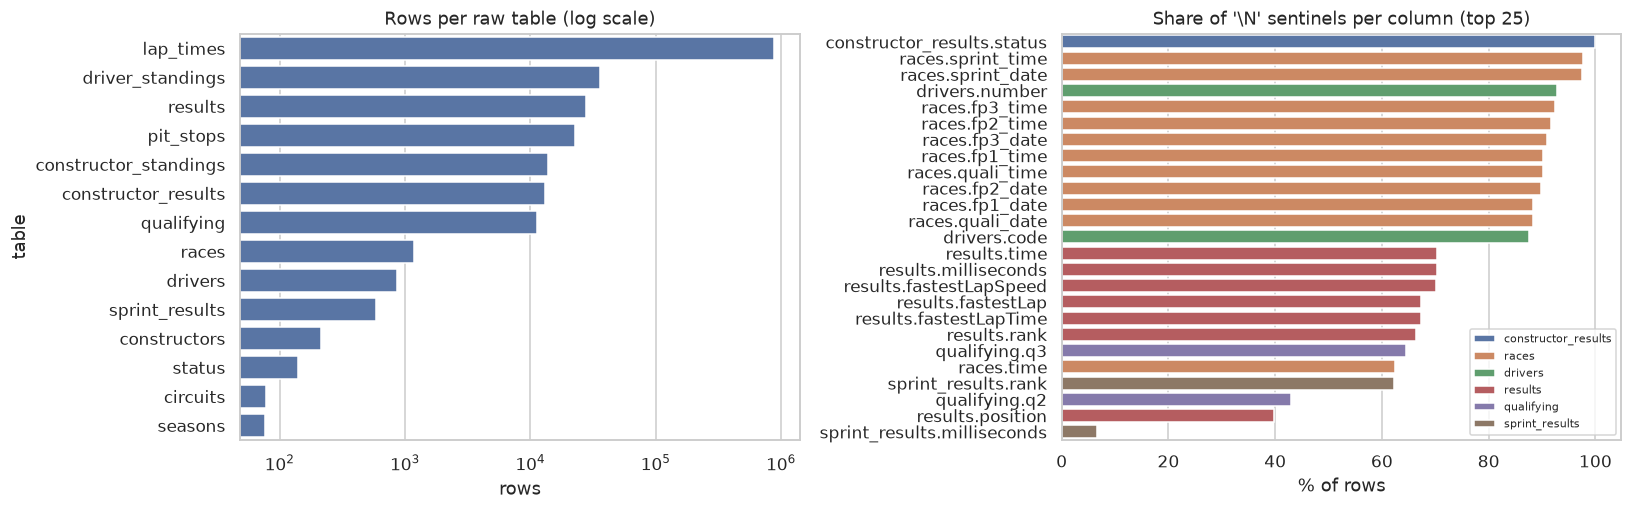

In [6]:
# A minimal, *read-only* typed view used only for plotting the raw state (raw itself is untouched)
_races_year = raw["races"][["raceId", "year"]].astype({"year": int})
res_raw = raw["results"].merge(_races_year, on="raceId", how="left")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
inv = inventory.reset_index(names="table")
sns.barplot(data=inv, y="table", x="rows", ax=axes[0], color="#4C72B0")
axes[0].set_xscale("log"); axes[0].set_title("Rows per raw table (log scale)")

top = sentinel_audit.query("n_sentinel > 0").sort_values("pct_sentinel", ascending=False).head(25)
top = top.assign(col=top.table + "." + top.column)
sns.barplot(data=top, y="col", x="pct_sentinel", hue="table", dodge=False, ax=axes[1])
axes[1].set_title(r"Share of '\N' sentinels per column (top 25)"); axes[1].set_xlabel("% of rows"); axes[1].set_ylabel("")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

**Interpretation.** Missingness is massive in some columns (e.g. `results.time`, `fastestLap*`, `qualifying.q3`, the `races` session-date columns) and **these are not random holes** — they have *structural* causes we must understand before deciding anything:

* `results.time / milliseconds` exist only for **classified finishers on the lead lap or with a recorded time**; retirements have no race time → missing *by design*.
* `fastestLap*` were only recorded from ~2004 → missing *because of era* (data-collection coverage).
* `qualifying.q2 / q3` are missing for drivers **knocked out** in Q1/Q2 → missing *informatively* (missing q3 itself says "did not reach Q3").
* `races.fp*_date / quali_date` were only filled in for recent seasons.

**Decision this drives:** we do **not** impute or drop anything at the cleaning stage. We convert `\N` to a real missing value (`NaN`/`NA`) so the information "this is missing" is preserved for feature engineering, where the *right* treatment depends on the cause (e.g. "missing q3" → feature "reached Q3 = 0", not mean-imputation). The year-level missingness heatmap in §5 proves these causes.

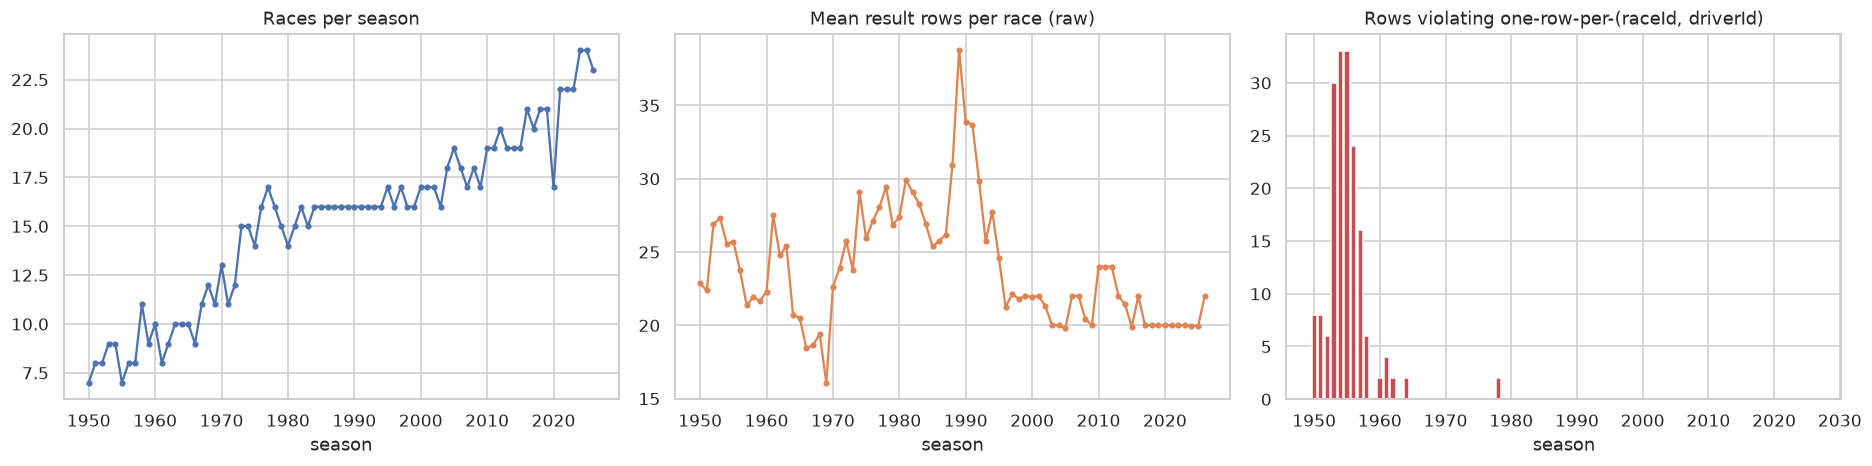

Raw results rows: 27,568  |  rows in duplicated (raceId, driverId) groups: 176  |  distinct duplicated pairs: 85
Seasons present in the raw files: 1950 → 2026


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
per_season = _races_year.groupby("year").size()
axes[0].plot(per_season.index, per_season.values, marker=".", color="#4C72B0")
axes[0].set_title("Races per season"); axes[0].set_xlabel("season")

entrants = res_raw.groupby(["year", "raceId"]).size().groupby("year").mean()
axes[1].plot(entrants.index, entrants.values, marker=".", color="#DD8452")
axes[1].set_title("Mean result rows per race (raw)"); axes[1].set_xlabel("season")

dups = res_raw[res_raw.duplicated(["raceId", "driverId"], keep=False)]
dup_by_year = dups.groupby("year").size().reindex(range(int(res_raw.year.min()), int(res_raw.year.max()) + 1), fill_value=0)
axes[2].bar(dup_by_year.index, dup_by_year.values, color="#C44E52")
axes[2].set_title("Rows violating one-row-per-(raceId, driverId)"); axes[2].set_xlabel("season")
plt.tight_layout(); plt.show()

print(f"Raw results rows: {len(res_raw):,}  |  rows in duplicated (raceId, driverId) groups: {len(dups)}  "
      f"|  distinct duplicated pairs: {dups.groupby(['raceId','driverId']).ngroups}")
print("Seasons present in the raw files:", int(res_raw.year.min()), "→", int(res_raw.year.max()))

**Interpretation.**
* The calendar grows from ~7 races (1950) to 20+ (modern era); fields were **much larger** in the 1950s–1990s (pre-qualifying, non-qualifiers included as rows). Because the podium is always 3 places, **the podium base rate depends heavily on field size** — a structural, era-driven class imbalance we will measure after cleaning.
* The red bars confirm the PDF's warning: grain violations are concentrated in the **1950s** (shared drives), with a handful of later cases. The grain fix in §4.7 handles them.
* If the files contain seasons outside 1950–2024 (some mirrors already include newer seasons), they are out of the milestone's scope — handled in §4.5.

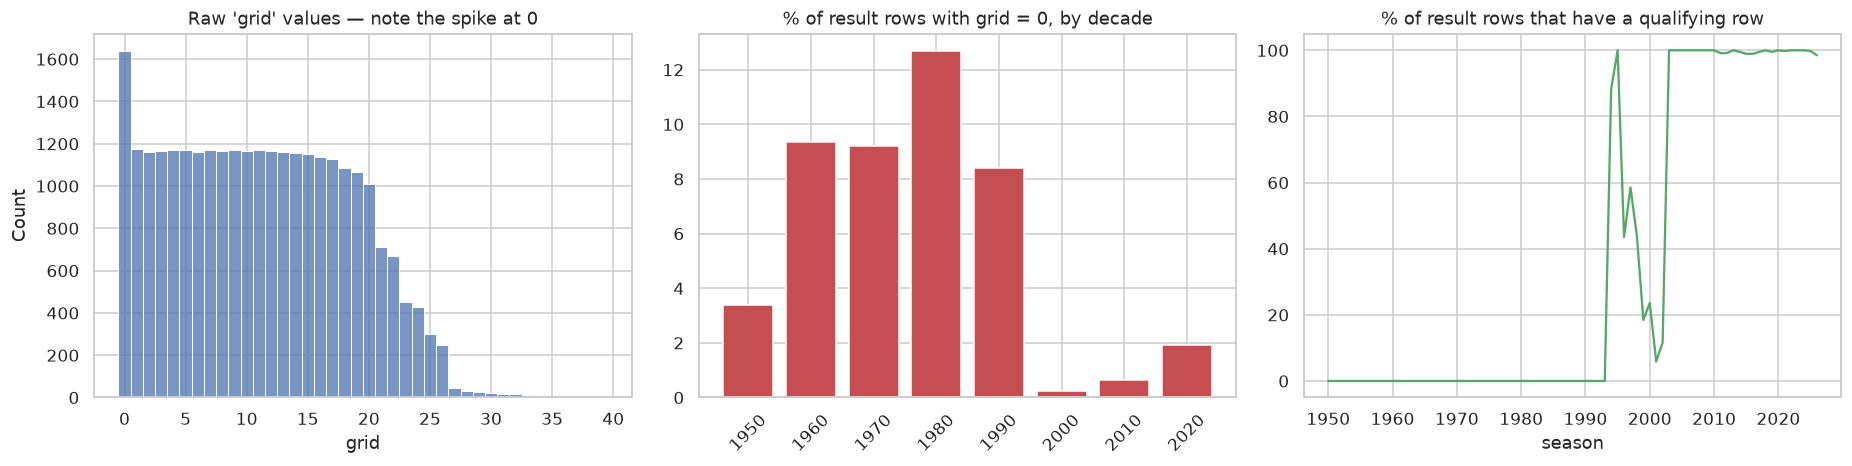

In [8]:
grid_raw = pd.to_numeric(res_raw["grid"].replace(SENTINEL, np.nan))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sns.histplot(grid_raw.dropna(), bins=np.arange(-0.5, 40.5, 1), ax=axes[0], color="#4C72B0")
axes[0].set_title("Raw 'grid' values — note the spike at 0"); axes[0].set_xlabel("grid")

dec = (res_raw.year // 10 * 10)
share0 = (grid_raw == 0).groupby(dec).mean() * 100
axes[1].bar(share0.index.astype(str), share0.values, color="#C44E52")
axes[1].set_title("% of result rows with grid = 0, by decade"); axes[1].tick_params(axis="x", rotation=45)

q_keys = set(zip(raw["qualifying"].raceId, raw["qualifying"].driverId))
res_raw["_has_quali"] = [k in q_keys for k in zip(res_raw.raceId, res_raw.driverId)]
cov = res_raw.groupby("year")["_has_quali"].mean() * 100
axes[2].plot(cov.index, cov.values, color="#55A868")
axes[2].set_title("% of result rows that have a qualifying row"); axes[2].set_xlabel("season")
plt.tight_layout(); plt.show()
res_raw = res_raw.drop(columns="_has_quali")

**Interpretation (drives two important decisions).**

1. **`grid = 0` is a *hidden sentinel*, not a starting position.** Position 0 does not exist on a grid. It is used for two very different situations: (a) the driver **never started** (did not qualify / pre-qualify, withdrew), and (b) the driver **started from the pit lane** (modern era). A model would read `0` as "better than pole position" — the exact opposite of the truth. → §4.4 decodes it into explicit flags instead of trusting the raw number.
2. **Qualifying coverage drift.** The `qualifying` table only covers ~1994 onward (and is patchy in some seasons). For earlier years, `grid` is the only pre-race position signal. This is the "historical qualifying-coverage drift" limitation the PDF asks us to report, and it is the main argument for a time-window decision in the feature-engineering phase.

## 4 · Cleaning (all on copies)

Order matters, and is deliberate:

1. **Whitespace** first — otherwise `"\N "` would not be recognised as a sentinel and `"British "` would not match `"British"`.
2. **Sentinels → missing** — must happen *before* typing, otherwise numeric conversion fails on `\N`.
3. **Semantic typing** (integers, floats, dates, durations) — needs sentinel-free columns.
4. **Domain-code decoding** (`grid = 0`, `positionText` letters, status taxonomy) — needs typed numbers.
5. **Scope filter** (1950–2024) — needs typed `year`.
6. **Primary-key checks** — on typed keys (string `"01"` vs `"1"` would hide duplicates).
7. **Grain fix** — one row per (raceId, driverId).
8. **Foreign-key reconciliation** — after filtering and de-duplication, so we test the tables we will actually join.
9. **Logical consistency checks** — the final safety net.

In [9]:
clean = {t: d.copy() for t, d in raw.items()}     # every change below happens on these copies only
decision_log = []                                    # (step, decision, rows/values affected, reason)
def log(step, decision, affected, reason):
    decision_log.append({"step": step, "decision": decision, "affected": affected, "reason": reason})

### 4.1 Whitespace normalisation

**Decision:** strip leading/trailing whitespace from every text cell. **Why:** invisible spaces create phantom categories (`"Argentinian"` vs `"Argentinian "` counted as two nationalities) and break the nationality ↔ country matching we need for DE-Q2. Stripping cannot destroy information — no identifier or name in this dataset is meaningful because of an edge space.

In [10]:
n_changed = 0
for t, d in clean.items():
    for c in d.columns:
        stripped = d[c].str.strip()
        changed = int((stripped != d[c]).sum())
        if changed:
            print(f"  {t}.{c}: {changed} value(s) trimmed -> e.g. {d.loc[stripped != d[c], c].unique()[:3].tolist()}")
        n_changed += changed
        d[c] = stripped
log("4.1", "Strip whitespace in all text cells", n_changed, "Phantom categories / failed joins on nationality")
print("Total cells trimmed:", n_changed)

  drivers.nationality: 1 value(s) trimmed -> e.g. ['Argentinian ']


Total cells trimmed: 1


### 4.2 Sentinel handling: `\N` → real missing value

**Decision:** replace exactly the token `\N` (and empty strings, if any) with a proper missing value. Nothing else is touched (we proved in §2.2 there are no other NA-like tokens).

**Why replace instead of drop rows?** Dropping any row with a `\N` would delete almost the whole dataset (e.g. ~70 % of `results` rows have no race `time` because the car retired or was lapped). The missingness is *meaningful*, so we keep it as missing and let feature engineering decide.

**Why not fill with 0 / -1 / mean now?** Every fill value is a claim. `fastestLapSpeed = 0` would claim the car was stationary; `grid = -1` would become a fake category; mean-imputing `q3` would invent lap times for drivers who never ran in Q3. Filling also must be learned **on the training split only** (to avoid leaking test-set statistics) — which cannot be done before the train/validation/test split exists. So cleaning converts, it does not impute.

In [11]:
before_missing = {t: int((d == SENTINEL).sum().sum() + (d == "").sum().sum()) for t, d in clean.items()}
for t in clean:
    clean[t] = clean[t].replace({SENTINEL: np.nan, "": np.nan})
after_missing = {t: int(d.isna().sum().sum()) for t, d in clean.items()}
chk = pd.DataFrame({"sentinel_or_empty_cells_before": before_missing, "NaN_cells_after": after_missing})
assert (chk.iloc[:, 0] == chk.iloc[:, 1]).all(), "sentinel count must equal NaN count (nothing invented/lost)"
assert not any((d == SENTINEL).any().any() for d in clean.values()), "no '\\N' may remain"
log("4.2", r"Replace '\N' (and '') with NaN", int(chk.iloc[:, 0].sum()), "Proper missing values; no imputation before splitting")
chk.query("sentinel_or_empty_cells_before > 0")

,sentinel_or_empty_cells_before,NaN_cells_after
constructor_results,13013,13013
constructor_standings,1,1
drivers,1559,1559
driver_standings,13,13
races,11479,11479
results,124529,124529
qualifying,12310,12310
pit_stops,6,6
sprint_results,494,494


✅ The two assertions prove the replacement is **exact**: the number of NaNs after equals the number of sentinels before, in every table, and no `\N` survives.

### 4.3 Semantic typing

Every column gets the type that matches its *meaning*, not just whatever parses:

| Meaning | Columns (examples) | Target type | Why this type |
|---|---|---|---|
| Identifiers & counts | `raceId`, `driverId`, `grid`, `position`, `laps`, `milliseconds` | nullable integer **`Int64`** | Plain `int64` cannot hold missing values; pandas would silently upcast to `float` (`3.0`), which breaks equality joins and looks like a measurement. `Int64` keeps integers integer *and* allows `<NA>`. |
| Continuous quantities | `points` (half points exist, e.g. 1.5), `fastestLapSpeed`, `lat`, `lng` | `float64` | Genuinely real-valued. |
| Calendar dates | `races.date`, `drivers.dob`, session dates | `datetime64` | Enables date arithmetic (driver age at race, ordering races in time for leakage-safe "past races only" features). |
| Race start instant | `date` + `time` | tz-aware UTC `datetime64` | Ergast times are UTC; a single timestamp gives a strict chronological order. |
| Durations | lap times `"1:27.452"`, `q1/q2/q3`, pit `duration`, `fastestLapTime` | **float seconds** (`*_s` columns) | `"1:27.452"` is text: you can't average it, compare it (`"59.9" > "1:00.1"` as strings!) or feed it to a model. Converted to 87.452 s. |
| Free text / codes | names, refs, `positionText`, `results.time` | string | Kept for audit/display. |

**Two deliberate exceptions:**
* `results.time` is **not** converted. It mixes two meanings: the winner's *total* time (`"1:34:50.616"`) and everyone else's *gap* (`"+5.478"`). Parsing both into "seconds" would put a 5-second gap and a 95-minute total in the same column. The clean numeric equivalent already exists: `milliseconds` → we derive `race_time_s` from it.
* `pit_stops.time` is a **wall-clock time of day** (`"17:28:24"`), not a duration, so it is not converted to seconds; `duration` is the stationary/pit-lane time and is converted.

Original text columns are **kept** next to the parsed `*_s` columns so that every conversion can be audited.

In [12]:
INT_COLS = {
    "circuits": ["circuitId", "alt"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId", "raceId", "constructorId"],
    "constructor_standings": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"],
    "drivers": ["driverId", "number"],
    "driver_standings": ["driverStandingsId", "raceId", "driverId", "position", "wins"],
    "races": ["raceId", "year", "round", "circuitId"],
    "results": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
    "sprint_results": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                       "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
    "qualifying": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],
    "lap_times": ["raceId", "driverId", "lap", "position", "milliseconds"],
    "pit_stops": ["raceId", "driverId", "stop", "lap", "milliseconds"],
    "seasons": ["year"], "status": ["statusId"],
}
FLOAT_COLS = {"circuits": ["lat", "lng"], "constructor_results": ["points"], "constructor_standings": ["points"],
              "driver_standings": ["points"], "results": ["points", "fastestLapSpeed"],
              "sprint_results": ["points", "fastestLapSpeed"]}
DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"], "drivers": ["dob"]}
DURATION_COLS = {"results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"],
                 "qualifying": ["q1", "q2", "q3"], "lap_times": ["time"], "pit_stops": ["duration"]}

typing_report = []
def _record(t, c, kind, before_nonnull, after_nonnull):
    typing_report.append({"table": t, "column": c, "kind": kind, "non_null_before": before_nonnull,
                          "non_null_after": after_nonnull, "parse_failures": before_nonnull - after_nonnull})

for t, cols in INT_COLS.items():
    for c in cols:
        if c not in clean[t]:          # e.g. 'rank' does not exist in every dataset version
            continue
        s = clean[t][c]
        num = pd.to_numeric(s, errors="coerce")
        non_int = num.dropna()[num.dropna() % 1 != 0]
        assert non_int.empty, f"{t}.{c} has non-integer values: {non_int.head().tolist()}"
        clean[t][c] = num.astype("Int64")
        _record(t, c, "Int64", int(s.notna().sum()), int(clean[t][c].notna().sum()))

for t, cols in FLOAT_COLS.items():
    for c in cols:
        if c in clean[t]:
            s = clean[t][c]
            clean[t][c] = pd.to_numeric(s, errors="coerce").astype("float64")
            _record(t, c, "float64", int(s.notna().sum()), int(clean[t][c].notna().sum()))

for t, cols in DATE_COLS.items():
    for c in cols:
        if c in clean[t]:
            s = clean[t][c]
            clean[t][c] = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
            _record(t, c, "datetime64", int(s.notna().sum()), int(clean[t][c].notna().sum()))

_DUR_RE = re.compile(r"^\d+(:\d{1,2}){0,2}(\.\d+)?$")
def duration_to_seconds(value):
    # '1:27.452' -> 87.452 ; '1:34:50.616' -> 5690.616 ; '23.4' -> 23.4 ; anything else -> NaN (counted as failure)
    if pd.isna(value):
        return np.nan
    v = str(value).strip()
    if not _DUR_RE.match(v):
        return np.nan
    secs = 0.0
    for part in v.split(":"):
        secs = secs * 60 + float(part)
    return secs

for t, cols in DURATION_COLS.items():
    for c in cols:
        if c in clean[t]:
            s = clean[t][c]
            clean[t][f"{c}_s"] = s.map(duration_to_seconds).astype("float64")
            _record(t, f"{c} -> {c}_s", "seconds", int(s.notna().sum()), int(clean[t][f"{c}_s"].notna().sum()))

# race start instant (UTC) and derived race time
r = clean["races"]
stamp = r["date"].dt.strftime("%Y-%m-%d") + " " + r["time"]          # NaN where time is unknown
r["race_datetime_utc"] = pd.to_datetime(stamp, format="%Y-%m-%d %H:%M:%S", utc=True, errors="coerce")
print("races with a known UTC start time:", int(r["race_datetime_utc"].notna().sum()), "of", len(r),
      "(start times are only recorded for modern seasons; 'date' stays available for all)")
for t in ["results", "sprint_results"]:
    clean[t]["race_time_s"] = clean[t]["milliseconds"].astype("float64") / 1000.0

typing_report = pd.DataFrame(typing_report)
print("Columns typed:", len(typing_report), "| total parse failures:", int(typing_report.parse_failures.sum()))
display(typing_report[typing_report.parse_failures > 0] if (typing_report.parse_failures > 0).any()
        else typing_report.groupby("kind").size().rename("columns_converted").to_frame())
log("4.3", "Semantic typing: Int64 / float / datetime / duration seconds", len(typing_report),
    "Numbers must be numbers; durations comparable; dates orderable for 'past-races-only' features")

races with a known UTC start time: 441 of 1172 (start times are only recorded for modern seasons; 'date' stays available for all)
Columns typed: 88 | total parse failures: 0


,columns_converted
kind,
Int64,66
datetime64,7
float64,8
seconds,7


**Validation of the duration parser against an independent source.** `lap_times` and `pit_stops` carry *both* a text duration and an integer `milliseconds`. If our parser is correct, `time_s × 1000` must equal `milliseconds` (to the millisecond). This is a stronger test than "it didn't crash".

In [13]:
for t, txt in [("lap_times", "time_s"), ("pit_stops", "duration_s")]:
    d = clean[t]
    both = d[txt].notna() & d["milliseconds"].notna()
    diff = ((d.loc[both, txt] * 1000).round() - d.loc[both, "milliseconds"].astype(float)).abs()
    print(f"{t:10s}: compared {both.sum():,} rows | exact: {(diff == 0).mean():.4%} | "
          f"off by exactly 1 ms: {int((diff == 1).sum())} | off by > 1 ms: {int((diff > 1).sum())}")
    assert (diff <= 1).all(), f"duration parser disagrees with milliseconds in {t}"
print("✅ Parsed durations agree with the independent milliseconds column "
      "(any 1 ms differences are rounding/truncation in the source, not parser errors).")

lap_times : compared 883,003 rows | exact: 99.9702% | off by exactly 1 ms: 263 | off by > 1 ms: 0
pit_stops : compared 22,701 rows | exact: 100.0000% | off by exactly 1 ms: 0 | off by > 1 ms: 0
✅ Parsed durations agree with the independent milliseconds column (any 1 ms differences are rounding/truncation in the source, not parser errors).


### 4.4 Decoding domain codes (hidden sentinels inside valid-looking numbers/letters)

The `\N` sentinel is the obvious one. F1 data also hides meaning inside *valid-looking* values. We decode them into **explicit, named columns** and never overwrite the original value (so nothing is lost and every decision is auditable).

**(a) `grid = 0`.** As shown in §3, `0` is not a position. We split it using a second, independent column — `laps`:
* `grid = 0` and `laps = 0` → **non-starter** (did not qualify, did not pre-qualify, withdrew …). The status breakdown printed below verifies this: the group is overwhelmingly DNQ / DNPQ / withdrew; the small remainder (accident, injury, engine…) are drivers who were entered but never took the start (e.g. crashed or broke down before the race) — still non-starters, so the rule holds.
* `grid = 0` and `laps > 0` → **pit-lane start** (the car raced, it just started from the pit lane, i.e. effectively behind the whole grid).
* We add `grid_pos` = `grid` when `grid > 0`, else missing, plus the two flags. *How* to encode a pit-lane start numerically (e.g. "last + 1") is a feature-engineering decision and is deliberately left for that phase.

**(b) `positionText` letters.** When `position` is missing, `positionText` explains why: `R` retired, `D` disqualified, `E` excluded, `W` withdrew, `F` failed to qualify, `N` not classified. We store this as `result_code` — an interpretable categorical used in EDA and DE-Q3.

**(c) `status` taxonomy.** `status.csv` has ~140 free-text reasons. For DE-Q3 the PDF defines a mechanical retirement as *a race start that ended early because a car component failed, excluding crashes, driver causes and regulatory decisions*. We encode that definition once, here, as a reviewed lookup — with an explicit **`ambiguous`** bucket (e.g. *puncture*, *broken wing*, *out of fuel*, *wheel nut*) that could be a component failure *or* the consequence of contact/strategy/pit error. Keeping it separate lets DE-Q3 run a sensitivity check instead of silently guessing.

In [14]:
res = clean["results"]
res["non_starter"] = (res["grid"] == 0) & (res["laps"] == 0)
res["pit_lane_start"] = (res["grid"] == 0) & (res["laps"] > 0)
res["grid_pos"] = res["grid"].where(res["grid"] > 0)

st_name = clean["status"].set_index("statusId")["status"]
print("Status of rows flagged NON-STARTER (grid=0 & laps=0) — should be qualification/withdrawal reasons:")
print(res.loc[res.non_starter, "statusId"].map(st_name).value_counts().head(12).to_string())
print("\nStatus of rows flagged PIT-LANE START (grid=0 & laps>0) — should be normal race outcomes:")
print(res.loc[res.pit_lane_start, "statusId"].map(st_name).value_counts().head(8).to_string())

def decode_position_text(pt):
    if pd.isna(pt): return pd.NA
    return "classified" if str(pt).isdigit() else {"R": "retired", "D": "disqualified", "E": "excluded",
            "W": "withdrew", "F": "failed_to_qualify", "N": "not_classified"}.get(str(pt), "other")
for t in ["results", "sprint_results"]:
    clean[t]["result_code"] = clean[t]["positionText"].map(decode_position_text).astype("category")
print("\nresult_code distribution (results):")
print(res["result_code"].value_counts().to_string())
log("4.4a", "Decode grid=0 into non_starter / pit_lane_start flags; grid_pos NaN when 0", int((res.grid == 0).sum()),
    "0 is not a grid slot; a model would read it as 'better than pole'")

Status of rows flagged NON-STARTER (grid=0 & laps=0) — should be qualification/withdrawal reasons:
statusId
Did not qualify       1013
Did not prequalify     331
Withdrew               164
Accident                18
Injury                   8
Excluded                 6
Engine                   6
Disqualified             6
107% Rule                2
Safety concerns          2
Fuel system              2
Injured                  2

Status of rows flagged PIT-LANE START (grid=0 & laps>0) — should be normal race outcomes:
statusId
+1 Lap              27
Finished            22
+2 Laps              7
Collision damage     3
Retired              2
Accident             2
Power Unit           2
Brakes               1

result_code distribution (results):
result_code
classified           16496
retired               9002
failed_to_qualify     1368
withdrew               346
not_classified         190
disqualified           157
excluded                 9


In [15]:
MECHANICAL = {
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
    "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure", "Throttle",
    "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak", "Wheel rim", "Water leak",
    "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire", "Pneumatics", "Handling", "Fire",
    "Wheel bearing", "Fuel system", "Oil line", "Launch control", "Fuel", "Power loss", "Vibrations", "Drivetrain",
    "Ignition", "Chassis", "Battery", "Halfshaft", "Crankshaft", "Alternator", "Oil pump", "Fuel leak", "Injection",
    "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe",
    "Magneto", "Supercharger", "Power Unit", "ERS", "Brake duct", "Undertray", "Cooling system", "Vibration",
    "Stalled", "Wheel", "Tyre", "Driver Seat", "Seat", "Safety belt", "Safety switch"}
AMBIGUOUS = {"Puncture", "Tyre puncture", "Broken wing", "Front wing", "Rear wing", "Out of fuel", "Wheel nut",
             "Refuelling", "Fuel rig", "Damage", "Debris", "Retired", "Not classified", "Underweight"}
ACCIDENT_DRIVER = {"Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Physical", "Injured",
                   "Injury", "Eye injury", "Illness", "Driver unwell"}
REGULATORY = {"Disqualified", "Excluded", "107% Rule", "Safety concerns", "Safety", "Not restarted"}
NON_START = {"Did not qualify", "Did not prequalify", "Withdrew"}

def status_category(s):
    if s == "Finished" or re.fullmatch(r"\+\d+ Laps?", s): return "finished"
    for name, group in [("mechanical", MECHANICAL), ("ambiguous", AMBIGUOUS), ("accident_or_driver", ACCIDENT_DRIVER),
                        ("regulatory", REGULATORY), ("did_not_start", NON_START)]:
        if s in group: return name
    return "unmapped"

clean["status"]["status_category"] = clean["status"]["status"].map(status_category).astype("category")
unmapped = clean["status"].query("status_category == 'unmapped'")
print("Status categories:", clean["status"]["status_category"].value_counts().to_dict())
assert unmapped.empty, f"Unmapped statuses need a reviewed decision: {unmapped.status.tolist()}"
log("4.4c", "Status taxonomy incl. explicit 'ambiguous' bucket", len(clean["status"]),
    "Implements the PDF's mechanical-retirement definition once, auditable, sensitivity-checkable")

Status categories: {'mechanical': 73, 'finished': 34, 'ambiguous': 14, 'accident_or_driver': 11, 'regulatory': 6, 'did_not_start': 3}


**Why the assertion?** If a dataset version adds a new status string, the cell fails loudly instead of silently mis-classifying it — a reviewer must make the call.

### 4.5 Scope filter: seasons 1950–2024

**Decision:** keep only races with `1950 ≤ year ≤ 2024`, and remove every child row (results, qualifying, laps, pit stops, standings, sprints) that belongs to a removed race.

**Why:** the milestone explicitly defines the dataset as *1950–2024*. Some copies of the Ergast data already contain newer races, including **future rounds with no results yet** — rows with a date but no outcome would be fake negatives (no podium) if they leaked into the modelling table. On the official Kaggle version this step is (almost) a no-op; it makes the notebook robust to whichever copy is attached.

**Why filter children by `raceId` rather than their own dates?** Because `raceId` is the FK that defines membership; this guarantees FK consistency after the filter (verified in §4.8).

In [16]:
before_rows = {t: len(d) for t, d in clean.items()}
in_scope = clean["races"]["year"].between(SCOPE_YEAR_MIN, SCOPE_YEAR_MAX)
clean["races"] = clean["races"][in_scope].copy()
keep_races = set(clean["races"]["raceId"])
for t in ["results", "sprint_results", "qualifying", "lap_times", "pit_stops",
          "driver_standings", "constructor_standings", "constructor_results"]:
    clean[t] = clean[t][clean[t]["raceId"].isin(keep_races)].copy()
clean["seasons"] = clean["seasons"][clean["seasons"]["year"].between(SCOPE_YEAR_MIN, SCOPE_YEAR_MAX)].copy()
scope = pd.DataFrame({"before": before_rows, "after": {t: len(d) for t, d in clean.items()}})
scope["removed"] = scope.before - scope.after
log("4.5", "Keep seasons 1950-2024 (and their child rows)", int(scope.removed.sum()), "Milestone scope; avoid unraced future rounds")
print("Season range now:", clean["races"].year.min(), "→", clean["races"].year.max())
scope[scope.removed > 0] if (scope.removed > 0).any() else print("Nothing out of scope in this copy of the data.")

Season range now: 1950 → 2024


,before,after,removed
constructor_results,13030,12625,405
constructor_standings,13796,13391,405
driver_standings,35695,34863,832
races,1172,1125,47
results,27568,26759,809
qualifying,11298,10494,804
lap_times,883003,839147,43856
pit_stops,22704,21292,1412
sprint_results,590,360,230
seasons,77,75,2


### 4.6 Primary-key verification (unique & non-null)

A PK must be **non-null** (a row you cannot identify cannot be joined) and **unique** (otherwise every join multiplies rows, silently double-counting results, points or pit stops). We test surrogate PKs *and* business keys.

In [17]:
def key_report(tables, keys, label):
    out = []
    for t, k in keys.items():
        d = tables[t]
        out.append({"table": t, "key": "(" + ", ".join(k) + ")", "type": label, "rows": len(d),
                    "null_key_rows": int(d[k].isna().any(axis=1).sum()),
                    "rows_in_duplicate_groups": int(d.duplicated(k, keep=False).sum())})
    return pd.DataFrame(out)

pk_before = pd.concat([key_report(clean, PRIMARY_KEYS, "primary"), key_report(clean, BUSINESS_KEYS, "business")])
pk_before["ok"] = (pk_before.null_key_rows == 0) & (pk_before.rows_in_duplicate_groups == 0)
pk_before.sort_values(["ok", "type"])

,table,key,type,rows,null_key_rows,rows_in_duplicate_groups,ok
0,results,"(raceId, driverId)",business,26759,0,176,False
12,lap_times,"(raceId, driverId, lap)",primary,839147,0,3958,False
1,sprint_results,"(raceId, driverId)",business,360,0,0,True
2,qualifying,"(raceId, driverId)",business,10494,0,0,True
3,driver_standings,"(raceId, driverId)",business,34863,0,0,True
4,constructor_standings,"(raceId, constructorId)",business,13391,0,0,True
5,constructor_results,"(raceId, constructorId)",business,12625,0,0,True
6,races,"(year, round)",business,1125,0,0,True
7,circuits,(circuitRef),business,78,0,0,True
8,drivers,(driverRef),business,865,0,0,True


**What the table shows.** All surrogate ids are fine, which is expected (they are generated). The failures are exactly two, and both are *business-key* problems:

* **`results (raceId, driverId)`** — the shared drives. This is the grain violation the PDF asks us to fix (next section).
* **`lap_times (raceId, driverId, lap)`** — if present in your copy, these are rows recorded twice for the same lap (in some copies, two imports of the late-1980s lap data differing by ±1 ms). One driver cannot complete the same lap twice. We inspect the conflict size before deciding.

In [18]:
lt = clean["lap_times"]
k = ["raceId", "driverId", "lap"]
exact = lt.duplicated(keep="first")                          # step 1: byte-identical copies
lt_nodup = lt[~exact]
conflicts = lt_nodup[lt_nodup.duplicated(k, keep=False)]      # step 2: same lap, different values
spread = conflicts.groupby(k)["milliseconds"].agg(lambda s: int(s.max() - s.min()))
print(f"exact duplicate rows               : {int(exact.sum())}")
print(f"(raceId, driverId, lap) conflicts  : {len(spread)} key groups")
if len(spread):
    print("disagreement between copies (ms)   :", spread.describe()[["50%", "75%", "max"]].to_dict())
    print(f"groups differing by <= 1 ms        : {(spread <= 1).mean():.0%}")
    races_aff = clean["races"].set_index("raceId").loc[conflicts.raceId.unique(), ["year", "name"]]
    print("races affected:\n", races_aff.to_string())

conflict_keys = set(map(tuple, conflicts[k].drop_duplicates().to_numpy()))
before = len(lt)
clean["lap_times"] = lt_nodup.drop_duplicates(k, keep="first").copy()
clean["lap_times"]["had_conflicting_copy"] = [tuple(x) in conflict_keys for x in clean["lap_times"][k].to_numpy()]
removed = before - len(clean["lap_times"])
log("4.6", "lap_times: drop exact dups; for conflicting copies keep first + flag had_conflicting_copy", removed,
    "A lap is driven once; conflicts are confined to very few races, mostly 1 ms rounding; flagged for exclusion")
print(f"removed {removed} lap_times rows; flagged {int(clean['lap_times'].had_conflicting_copy.sum())} kept laps as 'had_conflicting_copy'")

exact duplicate rows               : 1707
(raceId, driverId, lap) conflicts  : 272 key groups
disagreement between copies (ms)   : {'50%': 1.0, '75%': 1.0, 'max': 13927.0}
groups differing by <= 1 ms        : 90%
races affected:
         year                  name
raceId                            
372     1988  Brazilian Grand Prix
356     1989  Brazilian Grand Prix


removed 1979 lap_times rows; flagged 272 kept laps as 'had_conflicting_copy'


**Decision & reasoning.**
* **Exact copies are dropped** — zero information loss, they are the same fact twice.
* **Conflicting copies** (same driver, same lap, different time): a driver cannot drive one lap twice, so one copy is wrong — but nothing in the data tells us which. The output above shows the conflicts are confined to **very few races** (late-1980s) and the large majority differ by only **1 ms** (rounding). A small number differ by seconds, which is a genuine source-data inconsistency. We keep the first copy in file order (deterministic, reproducible) **and flag** every affected lap with `had_conflicting_copy`, so any later analysis of lap pace can exclude them in one line instead of trusting an arbitrary pick.
* **Why this cannot hurt the model:** lap times of race *r* are post-race information (never features for race *r*), and these few laps belong to two pre-qualifying-table-era races — they cannot meaningfully affect any rolling "past pace" feature either. If your Kaggle copy has no such duplicates, this cell simply reports zeros.

### 4.7 ⭐ Grain fix — exactly one row per (raceId, driverId)

Each modelling row is one prediction: *"will this driver finish on the podium in this race?"*. Two rows for the same driver in the same race would mean two contradictory answers to the same question, and would double-weight that driver in training.

#### Step 1 — look at the duplicates (evidence, not assumptions)

In [19]:
res = clean["results"]
key = ["raceId", "driverId"]
dup_mask = res.duplicated(key, keep=False)
show = (res[dup_mask]
        .merge(clean["races"][["raceId", "year", "name"]], on="raceId")
        .merge(clean["drivers"][["driverId", "surname"]], on="driverId")
        .assign(status=lambda d: d.statusId.map(st_name))
        .sort_values(["raceId", "driverId", "resultId"]))
cols = ["year", "name", "surname", "resultId", "constructorId", "number", "grid", "positionText",
        "positionOrder", "points", "laps", "status"]
g = show.groupby(key)
print(f"{dup_mask.sum()} rows in {g.ngroups} duplicated (raceId, driverId) pairs;",
      "entries per pair:", g.size().value_counts().to_dict())
print("Seasons:", show.year.value_counts().sort_index().to_dict())
show[cols].head(30)

176 rows in 85 duplicated (raceId, driverId) pairs; entries per pair: {2: 79, 3: 6}
Seasons: {np.int64(1950): 8, np.int64(1951): 8, np.int64(1952): 6, np.int64(1953): 30, np.int64(1954): 33, np.int64(1955): 33, np.int64(1956): 24, np.int64(1957): 16, np.int64(1958): 6, np.int64(1960): 2, np.int64(1961): 4, np.int64(1962): 2, np.int64(1964): 2, np.int64(1978): 2}


,year,name,surname,resultId,constructorId,number,grid,positionText,positionOrder,points,laps,status
0,1978,Italian Grand Prix,Ertl,13189,54,10,0,F,26,0.0,0,Did not qualify
1,1978,Italian Grand Prix,Ertl,13192,57,23,0,F,29,0.0,0,Did not prequalify
2,1964,United States Grand Prix,Clark,17363,172,1,1,7,7,0.0,102,Out of fuel
175,1964,United States Grand Prix,Clark,24304,172,2,1,R,12,0.0,54,Injection
3,1962,British Grand Prix,Greene,17741,172,48,0,W,22,0.0,0,Withdrew
4,1962,British Grand Prix,Greene,17744,97,50,0,W,25,0.0,0,Withdrew
5,1961,British Grand Prix,Moss,17962,102,26,20,D,19,0.0,56,Disqualified
6,1961,British Grand Prix,Moss,17964,172,28,5,R,21,0.0,44,Brakes
7,1961,United States Grand Prix,Gregory,18063,172,22,11,R,17,0.0,23,Gearbox
174,1961,United States Grand Prix,Gregory,24303,172,21,15,11,11,0.0,92,+8 Laps


**What we learn from the rows themselves.** In the 1950s a driver whose car broke could take over a team-mate's car mid-race; the result is then recorded **once per car he drove**, and points of a shared finish are split. Two textbook examples are in the data (printed below):

* **1957 British GP** – Moss started from pole in his own car, retired, took over Brooks's car and won; the win is credited to *both* drivers (points split).
* **1951 French GP** – Fangio started from pole, took over Fagioli's car and won.

So a duplicate pair is **not** a data-entry error to delete blindly — each row is a true fact about a *different car*. We need a rule that picks the row that answers *our* question correctly.

In [20]:
# Plain boolean filtering (instead of DataFrame.query) avoids the numexpr fallback warning
# that query() raises on pandas' nullable Int64 columns.
mask = show["year"].isin([1951, 1957]) & show["name"].isin(["British Grand Prix", "French Grand Prix"])
example = show[show["raceId"].isin(show.loc[mask, "raceId"])]
example[example.surname.isin(["Moss", "Brooks", "Fangio", "Fagioli"])][cols]

,year,name,surname,resultId,constructorId,number,grid,positionText,positionOrder,points,laps,status
19,1957,British Grand Prix,Moss,18817,118,18,1,R,12,0.0,51,Engine
167,1957,British Grand Prix,Moss,20291,118,20,3,1,1,5.0,90,Finished
17,1957,British Grand Prix,Brooks,18806,118,20,3,1,1,4.0,90,Finished
169,1957,British Grand Prix,Brooks,20293,118,18,1,R,12,0.0,51,Engine
81,1951,French Grand Prix,Fangio,19928,51,24,1,11,11,0.0,55,+22 Laps
92,1951,French Grand Prix,Fangio,20186,51,8,7,1,1,5.0,77,Finished
79,1951,French Grand Prix,Fagioli,19918,51,8,7,1,1,4.0,77,Finished
93,1951,French Grand Prix,Fagioli,20188,51,24,1,11,11,0.0,55,+22 Laps


#### Step 2 — candidate rules and what each one gets right or wrong

The prediction is made **after qualifying, before the start**. At that moment we know which car each driver *starts* in (its grid slot, its constructor). We cannot know that a mid-race car swap will happen.

| Rule | Row kept | Effect on **features** (grid, constructor) | Effect on **label** (podium) |
|---|---|---|---|
| **A. Starting car** (lowest `resultId`) | the driver's original entry | ✅ match what was knowable pre-race | ❌ denies credited podiums earned in the second car (Moss 1957 would be "no podium") |
| **B. Best finish** (min `positionOrder`) | the best-classified car | ❌ may give the driver his *team-mate's* grid slot (Moss would get grid 3 instead of pole) — a fact that did not exist pre-race for him | ✅ credited podium |
| **C. Starting car + credited label** *(chosen)* | the starting-car row (as in A) | ✅ | ✅ `podium = 1` if the driver is credited with `positionOrder ≤ 3` in **any** of his cars that race |

**Why C.** It is the only rule that keeps *both* sides of the row truthful: the features describe the pre-race state, and the target equals the official record (the PDF's definition `positionOrder ≤ 3`, applied to everything the driver is credited with in that race). The row-selection itself uses only `resultId` (an entry-order artefact), never a post-race outcome — so the selection cannot leak the answer into the features.

**Why the lowest `resultId` is the starting car — and its honest limitation.** The starting car is not stored explicitly in Ergast. The best available proxy is entry order: the original classification rows were loaded first, and many extra shared-drive rows were appended later in a separate id block (quantified below — roughly half of the second entries sit *after* the race's main id block; the rest are interleaved, so entry order is the only signal left). The two historical spot-checks above (Moss/Brooks 1957, Fangio/Fagioli 1951) are both resolved correctly by this rule. It is a *proxy*, not ground truth: in some pre-1965 cases it may pick the other car (e.g. inspect Moss, 1961 British GP, in the table above). That can only affect `grid`/`constructor` of ≈85 driver-races out of ~26k, **never the label** (rule C takes the label from all rows). We report this as a known limitation instead of hiding it.

In [21]:
first_idx = res.groupby(key)["resultId"].idxmin()
is_first = res.index.isin(first_idx)
main_block_max = res[is_first].groupby("raceId")["resultId"].max()
later = res[dup_mask & ~is_first]
outside = (later["resultId"] > later["raceId"].map(main_block_max)).mean()
print(f"Second/third entries whose resultId lies after the race's main id block: {outside:.0%}  "
      "(evidence that extra shared-drive rows were appended later)")

# Compare rules on the duplicated pairs only
d = res[dup_mask].copy()
best_po = d.groupby(key)["positionOrder"].transform("min")
rows_A = d.loc[d.groupby(key)["resultId"].idxmin()].set_index(key)
rows_B = d.loc[d.groupby(key)["positionOrder"].idxmin()].set_index(key)
label_A = rows_A["positionOrder"] <= 3
label_C = d.groupby(key)["positionOrder"].min() <= 3
cmp = pd.Series({
    "duplicated pairs": len(rows_A),
    "pairs credited with a podium (true label = 1)": int(label_C.sum()),
    "rule A gets the label wrong": int((label_A != label_C).sum()),
    "rule B changes the grid slot vs starting car": int((rows_A["grid"] != rows_B.loc[rows_A.index, "grid"]).sum()),
    "rule B changes the constructor vs starting car": int((rows_A["constructorId"] != rows_B.loc[rows_A.index, "constructorId"]).sum()),
    "rule C gets label wrong / changes features": 0,
})
cmp.to_frame("count")

Second/third entries whose resultId lies after the race's main id block: 53%  (evidence that extra shared-drive rows were appended later)


,count
duplicated pairs,85
pairs credited with a podium (true label = 1),22
rule A gets the label wrong,16
rule B changes the grid slot vs starting car,64
rule B changes the constructor vs starting car,8
rule C gets label wrong / changes features,0


#### Step 3 — apply rule C
New columns kept for transparency:
* `n_car_entries` – how many result rows the driver had in that race (1 normally, 2–3 for shared drives),
* `shared_drive` – flag (useful for EDA and to exclude/inspect these rows later),
* `credited_best_positionOrder`, `credited_points` – the official credited outcome across all cars (post-race information → **targets/analysis only, never features**),
* `podium` – the **target**: `credited_best_positionOrder ≤ 3`.

In [22]:
res = clean["results"].copy()
grp = res.groupby(key)
res["n_car_entries"] = grp["resultId"].transform("size").astype("Int64")
res["credited_best_positionOrder"] = grp["positionOrder"].transform("min").astype("Int64")
res["credited_points"] = grp["points"].transform("sum")
res["podium"] = (res["credited_best_positionOrder"] <= 3).astype("int8")

before = len(res)
results_dr = res.loc[grp["resultId"].idxmin()].sort_values(["raceId", "positionOrder"]).reset_index(drop=True)
results_dr["shared_drive"] = results_dr["n_car_entries"] > 1

assert not results_dr.duplicated(key).any(), "grain must be one row per (raceId, driverId)"
assert len(results_dr) == res[key].drop_duplicates().shape[0], "no (raceId, driverId) pair may be lost"
assert results_dr["podium"].sum() >= (res["positionOrder"] <= 3).groupby([res.raceId, res.driverId]).any().sum()
clean["results"] = results_dr
log("4.7", "Grain fix (rule C): keep starting-car row (min resultId); podium = credited positionOrder<=3 in any car",
    before - len(results_dr), "Features reflect the pre-race state; label matches the official credited result")
print(f"results: {before:,} rows -> {len(results_dr):,} rows (removed {before - len(results_dr)}); "
      f"shared-drive driver-races flagged: {int(results_dr.shared_drive.sum())}")
print("✅ (raceId, driverId) is now unique; every driver-race kept exactly once.")

results: 26,759 rows -> 26,668 rows (removed 91); shared-drive driver-races flagged: 85
✅ (raceId, driverId) is now unique; every driver-race kept exactly once.


**Side check on the other driver-race tables.** `qualifying`, `sprint_results` and `driver_standings` must also be one row per (raceId, driverId) because they will be joined onto this table. The PK report above showed no violations there; we re-assert it in §4.8 so that a future data version cannot silently break the joins.

> **Note on non-starters.** The grain is fixed, but rows flagged `non_starter` (did not qualify / withdrew) are still in the table. We **keep** them at the cleaning stage because they are real entries and are needed for some analyses (e.g. field sizes). For modelling, they should most likely be excluded: the cutoff is *after qualifying*, so a non-qualifier's "no podium" is already known — not a prediction — and these trivially-easy negatives would inflate every metric. That decision is made and justified in the feature-engineering phase, using the flag we created here. The effect on the class balance is shown in §5.

### 4.8 Foreign-key reconciliation

For every FK we compute the **orphans**: child values that do not exist in the parent. Policy (decided *before* looking at the counts): an orphan row can never be joined correctly, so if any exist they are reported and removed; if the count were large we would stop and investigate instead of deleting.

In [23]:
def fk_report(tables):
    out = []
    for child, ccol, parent, pcol in FOREIGN_KEYS:
        cvals = tables[child][ccol]
        parent_vals = set(tables[parent][pcol].dropna())
        orphan = cvals.notna() & ~cvals.isin(parent_vals)
        out.append({"child": f"{child}.{ccol}", "parent": f"{parent}.{pcol}", "child_rows": len(cvals),
                    "null_fk": int(cvals.isna().sum()), "orphans": int(orphan.sum())})
    return pd.DataFrame(out)

fk = fk_report(clean)
removed_orphans = 0
for child, ccol, parent, pcol in FOREIGN_KEYS:
    mask = clean[child][ccol].notna() & ~clean[child][ccol].isin(set(clean[parent][pcol]))
    removed_orphans += int(mask.sum())
    clean[child] = clean[child][~mask].copy()
fk_after = fk_report(clean)
assert (fk_after.orphans == 0).all() and (fk_after.null_fk == 0).all()
pk_after = pd.concat([key_report(clean, PRIMARY_KEYS, "primary"), key_report(clean, BUSINESS_KEYS, "business")])
assert (pk_after.null_key_rows == 0).all() and (pk_after.rows_in_duplicate_groups == 0).all()
log("4.8", "FK reconciliation (orphans removed if any)", removed_orphans, "Orphans cannot be joined; joins must not drop/invent rows")
print(f"Orphans found and removed: {removed_orphans}")
print("✅ All PKs unique & non-null, all business keys unique, all FKs reconcile.")
fk

Orphans found and removed: 0
✅ All PKs unique & non-null, all business keys unique, all FKs reconcile.


,child,parent,child_rows,null_fk,orphans
0,races.circuitId,circuits.circuitId,1125,0,0
1,races.year,seasons.year,1125,0,0
2,results.raceId,races.raceId,26668,0,0
3,results.driverId,drivers.driverId,26668,0,0
4,results.constructorId,constructors.constructorId,26668,0,0
5,results.statusId,status.statusId,26668,0,0
6,sprint_results.raceId,races.raceId,360,0,0
7,sprint_results.driverId,drivers.driverId,360,0,0
8,sprint_results.constructorId,constructors.constructorId,360,0,0
9,sprint_results.statusId,status.statusId,360,0,0


### 4.9 Logical consistency checks (the final safety net)

Type-correct data can still be *wrong*. We test rules that must hold in F1 and **flag** (not delete) suspicious-but-real values:

* `position` equals `positionOrder` for classified finishers; `points ≥ 0`; `laps ≥ 0`.
* Each race has exactly one `positionOrder = 1`, and the credited podium contains ≥ 3 drivers (more only in shared-drive races).
* Driver age at the race is plausible (Ergast includes drivers from ~15 to ~55).
* Every race date falls inside its season year.
* **Lap times** much slower than the race median (red flags, safety cars, pit laps) and **pit durations** over 2 minutes (red-flag stoppages are recorded as pit "stops") are *real events*, not errors → flagged with `is_outlier_*` columns so EDA/features can exclude them deliberately rather than having them silently removed.

In [24]:
res = clean["results"]; races = clean["races"]
checks = {}
m = res["position"].notna()
checks["position != positionOrder (classified rows)"] = int((res.loc[m, "position"] != res.loc[m, "positionOrder"]).sum())
checks["negative points"] = int((res["points"] < 0).sum())
checks["negative laps"] = int((res["laps"] < 0).sum())
winners = clean["results"].groupby("raceId")["positionOrder"].apply(lambda s: int((s == 1).sum()))
checks["races with != 1 winner row (after grain fix)"] = int((winners != 1).sum())
pod = res.groupby("raceId")["podium"].sum()
checks["races with < 3 credited podium drivers"] = int((pod < 3).sum())
checks["races with > 3 credited podium drivers (shared drives)"] = int((pod > 3).sum())
checks["race date outside its season year"] = int((races["date"].dt.year != races["year"]).sum())

age = (res.merge(races[["raceId", "date"]], on="raceId").merge(clean["drivers"][["driverId", "dob"]], on="driverId")
          .assign(age=lambda d: (d["date"] - d["dob"]).dt.days / 365.25)["age"])
checks["driver age < 15 or > 60 at race"] = int(((age < 15) | (age > 60)).sum())

lt = clean["lap_times"]
med = lt.groupby("raceId")["time_s"].transform("median")
lt["is_outlier_lap"] = lt["time_s"] > 1.5 * med
ps = clean["pit_stops"]
ps["is_outlier_pit"] = ps["duration_s"] > 120
checks["lap times > 1.5x race median (flagged)"] = int(lt["is_outlier_lap"].sum())
checks["pit durations > 120 s (flagged)"] = int(ps["is_outlier_pit"].sum())
pd.Series(checks).to_frame("count")

,count
position != positionOrder (classified rows),13
negative points,0
negative laps,0
races with != 1 winner row (after grain fix),0
races with < 3 credited podium drivers,0
races with > 3 credited podium drivers (shared drives),18
race date outside its season year,0
driver age < 15 or > 60 at race,0
lap times > 1.5x race median (flagged),13261
pit durations > 120 s (flagged),585


**Reading the checks.**
* The integrity checks (points, laps, dates, one winner per race) should all be **0** — they confirm the cleaned data is internally coherent and that the grain fix kept exactly one winner per race.
* Any `position ≠ positionOrder` rows and races where a few rows share a classification are historical quirks (dead heats, re-classifications); they are rare and do not affect the podium label, which is defined on `positionOrder` per the PDF.
* `> 3 credited podium drivers` happens **only** in shared-drive races — exactly as expected from rule C (e.g. 1955 Argentine GP, where 2nd and 3rd were each shared by several drivers).
* Outlier laps/pit stops are flagged, not removed: they are true events, and deleting them would bias any "average pace" feature upward in a way that depends on race incidents.

## 5 · EDA **after** cleaning — and the impact of cleaning

Now that the data are typed, we can see things that were impossible before (numeric distributions, time arithmetic, structural missingness by year).

In [25]:
impact = pd.DataFrame({"raw_rows": {t: len(d) for t, d in raw.items()},
                       "clean_rows": {t: len(d) for t, d in clean.items()}})
impact["removed"] = impact.raw_rows - impact.clean_rows
impact["removed_%"] = (100 * impact.removed / impact.raw_rows).round(3)
dtype_change = pd.DataFrame({
    "text_cols_raw": {t: raw[t].shape[1] for t in TABLES},
    "numeric_or_datetime_cols_clean": {t: sum(pd.api.types.is_numeric_dtype(clean[t][c]) or
                                              pd.api.types.is_datetime64_any_dtype(clean[t][c]) for c in clean[t]) for t in TABLES}})
impact.join(dtype_change)

,raw_rows,clean_rows,removed,removed_%,text_cols_raw,numeric_or_datetime_cols_clean
circuits,78,78,0,0.000,9,4
constructors,214,214,0,0.000,5,1
constructor_results,13030,12625,405,3.108,5,4
constructor_standings,13796,13391,405,2.936,7,6
drivers,865,865,0,0.000,9,3
driver_standings,35695,34863,832,2.331,7,6
races,1172,1125,47,4.010,18,11
results,27568,26668,900,3.265,18,25
qualifying,11298,10494,804,7.116,9,9
lap_times,883003,837168,45835,5.191,6,8


**Impact in one table.** Very few rows are removed (only out-of-scope seasons, the shared-drive extra rows and duplicated laps) — cleaning here is about **meaning and types, not deletion**. Before cleaning, *every* column was text; after cleaning most columns are numeric or datetime and can be analysed and modelled.

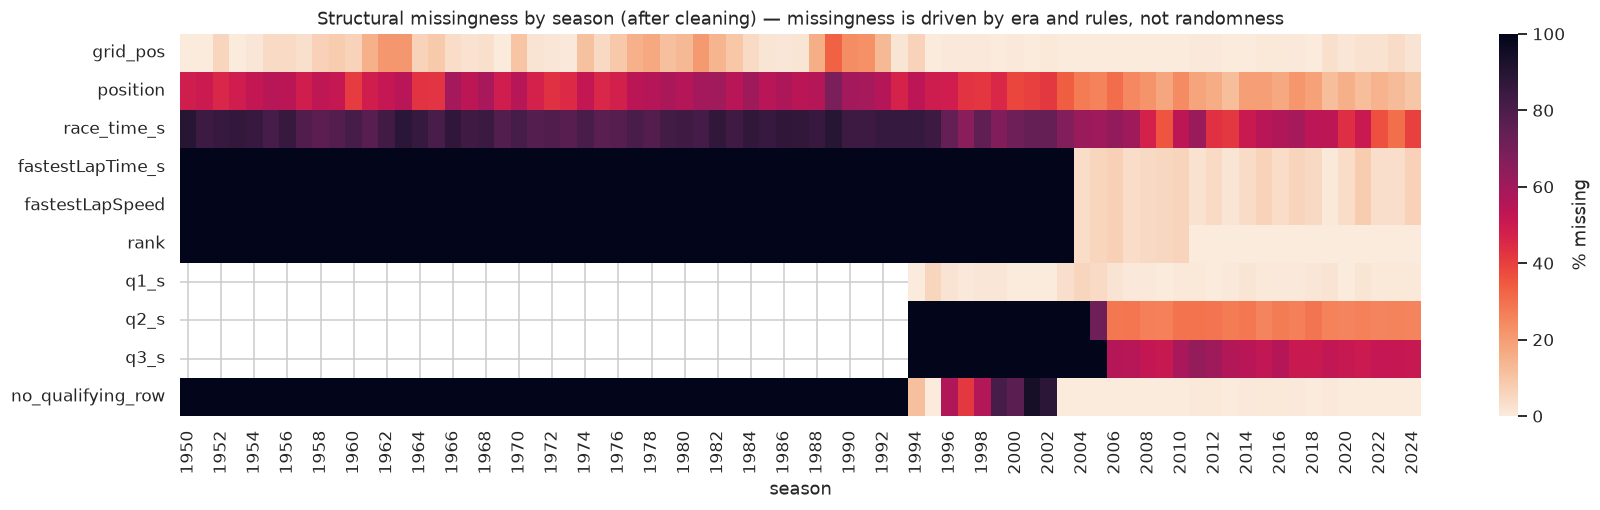

In [26]:
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
q = clean["qualifying"].merge(clean["races"][["raceId", "year"]], on="raceId")
miss_res = res.groupby("year")[["grid_pos", "position", "race_time_s", "fastestLapTime_s", "fastestLapSpeed", "rank"]].apply(lambda d: d.isna().mean())
miss_q = q.groupby("year")[["q1_s", "q2_s", "q3_s"]].apply(lambda d: d.isna().mean())
cov = res.assign(has_q=res.set_index(["raceId", "driverId"]).index.isin(clean["qualifying"].set_index(["raceId", "driverId"]).index)).groupby("year")["has_q"].mean()
miss = miss_res.join(miss_q, how="left").join((1 - cov).rename("no_qualifying_row"))

fig, ax = plt.subplots(figsize=(16, 4.8))
sns.heatmap(miss.T * 100, cmap="rocket_r", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Structural missingness by season (after cleaning) — missingness is driven by era and rules, not randomness")
ax.set_xlabel("season")
plt.tight_layout(); plt.show()

**Interpretation — this plot justifies the "convert, don't impute" decision of §4.2.**
* `fastestLap*` / `rank` are ~100 % missing until ~2004 and ~0 % after: a **data-collection era effect**. Imputing them for 1950–2003 would fabricate half a century of data. (They are post-race anyway → never features.)
* `no_qualifying_row` is ~100 % before 1994, shows **large gaps again in ~1996–2002**, and is near 0 % only from ~2003: the **qualifying-coverage drift** limitation. Qualifying-based features are reliable only from ~2003 — the feature phase must either restrict the window or fall back on `grid` (available in every era) for older seasons.
* `q2_s` / `q3_s` missingness jumps when knockout qualifying arrives (2006): it encodes *elimination*, i.e. is informative, not random.
* `race_time_s` / `position` missingness reflects **retirements** (high in the unreliable 1950s–80s, lower today).

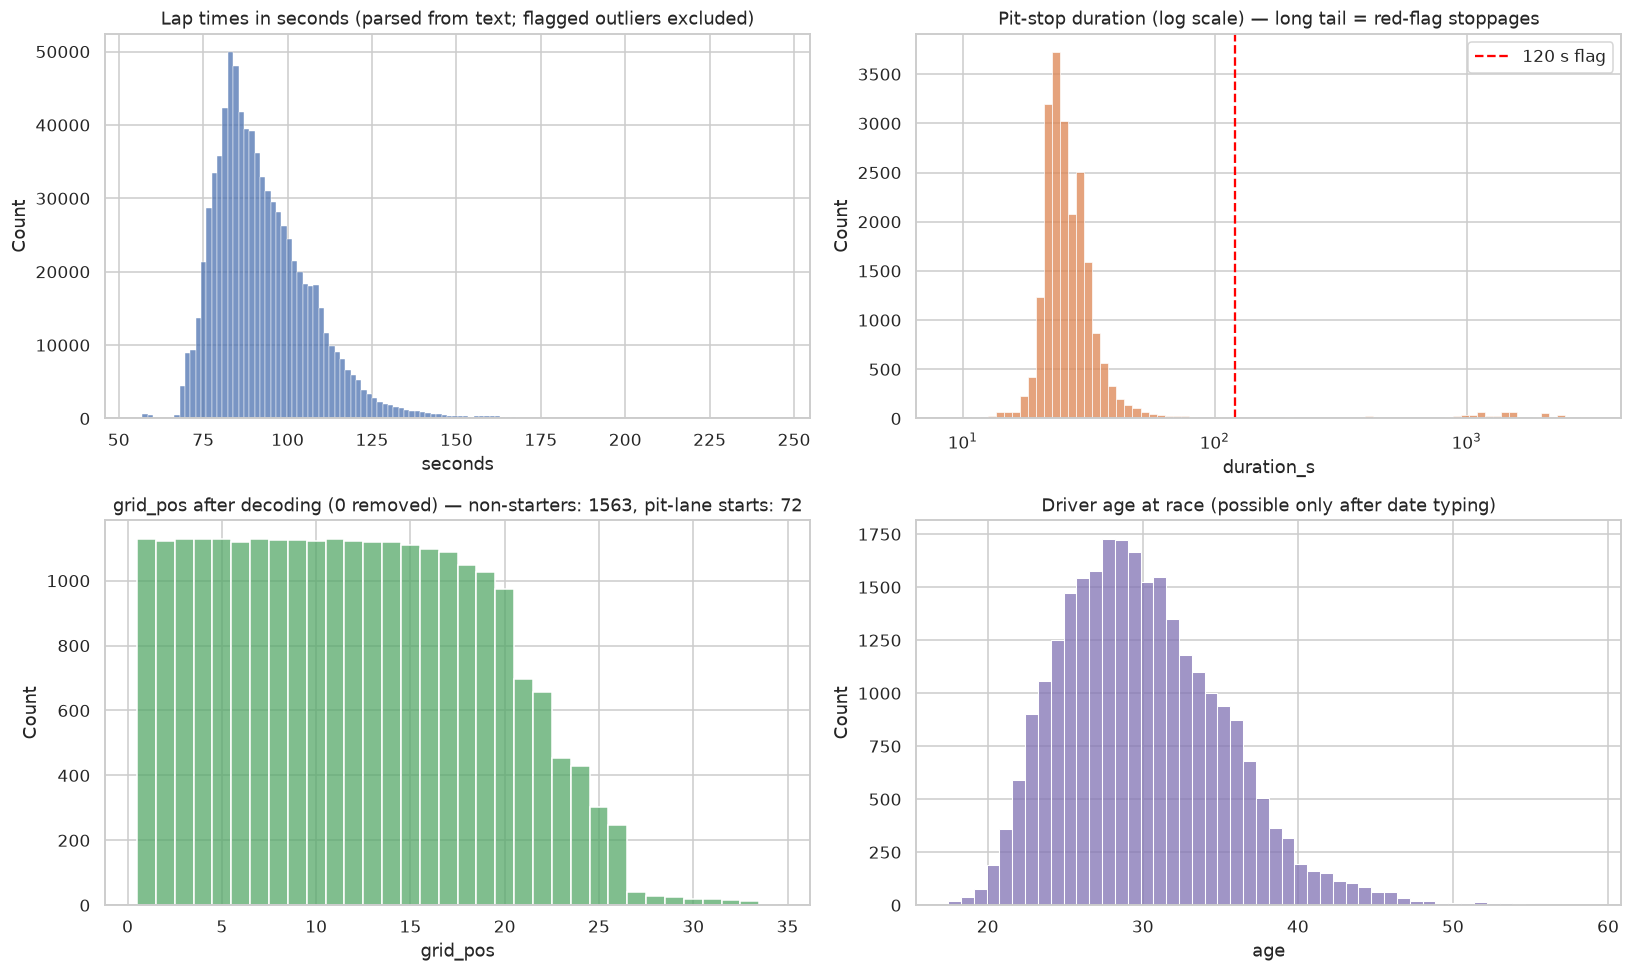

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
lt = clean["lap_times"]
sns.histplot(lt.loc[~lt.is_outlier_lap, "time_s"], bins=120, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Lap times in seconds (parsed from text; flagged outliers excluded)"); axes[0, 0].set_xlabel("seconds")

ps = clean["pit_stops"]
sns.histplot(ps["duration_s"], bins=80, log_scale=True, ax=axes[0, 1], color="#DD8452")
axes[0, 1].axvline(120, color="red", ls="--", label="120 s flag"); axes[0, 1].legend()
axes[0, 1].set_title("Pit-stop duration (log scale) — long tail = red-flag stoppages")

r_ = clean["results"]
sns.histplot(r_["grid_pos"].dropna(), bins=np.arange(0.5, 35.5, 1), ax=axes[1, 0], color="#55A868")
axes[1, 0].set_title(f"grid_pos after decoding (0 removed) — non-starters: {int(r_.non_starter.sum())}, pit-lane starts: {int(r_.pit_lane_start.sum())}")

ages = (r_.merge(clean["races"][["raceId", "date"]], on="raceId").merge(clean["drivers"][["driverId", "dob"]], on="driverId")
          .assign(age=lambda d: (d["date"] - d["dob"]).dt.days / 365.25)["age"])
sns.histplot(ages.dropna(), bins=50, ax=axes[1, 1], color="#8172B3")
axes[1, 1].set_title("Driver age at race (possible only after date typing)")
plt.tight_layout(); plt.show()

**Interpretation.**
* Lap times now form a real distribution (~60–130 s, circuit-dependent). Before typing this plot was impossible — the column was text.
* Pit durations: the bulk sits around 20–30 s (pit-lane transit + stop) with a long right tail; the values above 120 s are red-flag periods recorded as pit stops → correctly flagged rather than treated as slow stops.
* `grid_pos` no longer has the impossible spike at 0; the zeros are now explicit `non_starter` / `pit_lane_start` flags.
* Driver age is a typical example of a **pre-race, leakage-safe** quantity that only becomes computable after semantic typing of dates.

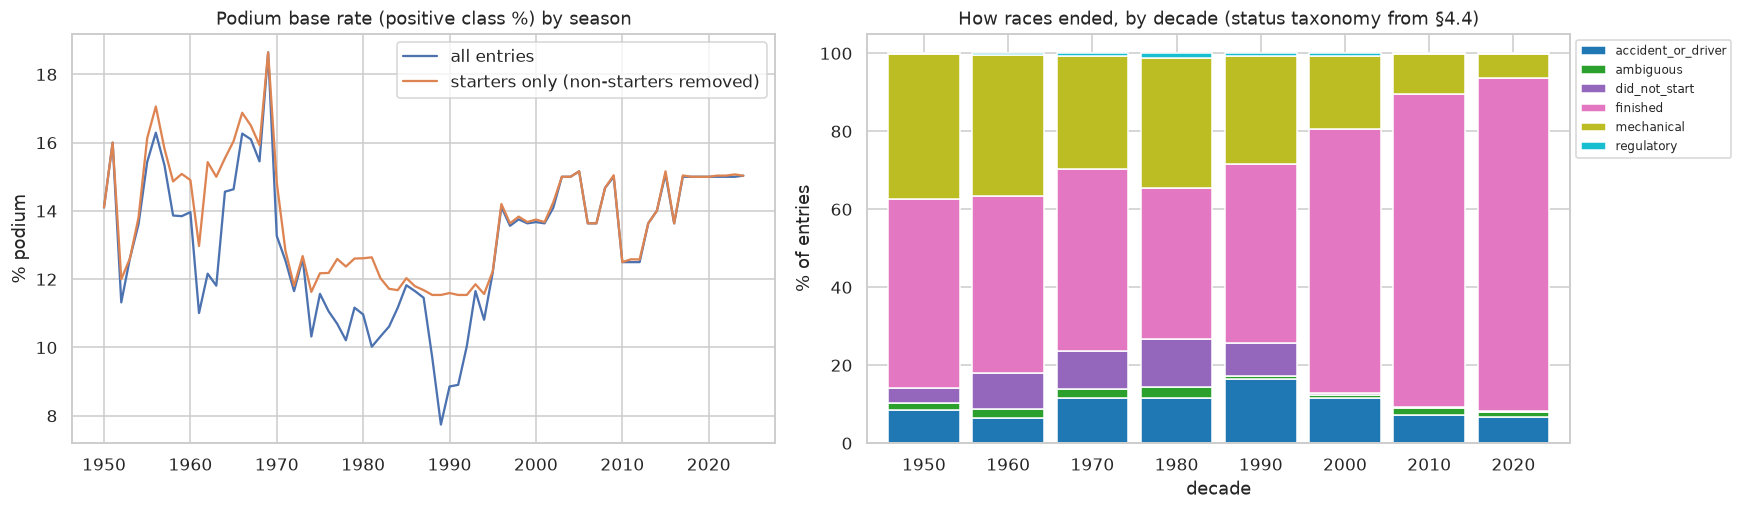

Overall podium rate: all entries 12.7% | starters only 13.5%


In [28]:
r_ = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
rate_all = r_.groupby("year")["podium"].mean() * 100
rate_starters = r_[~r_.non_starter].groupby("year")["podium"].mean() * 100
st_cat = clean["status"].set_index("statusId")["status_category"]
cat_share = (r_.assign(cat=r_.statusId.map(st_cat), decade=r_.year // 10 * 10)
               .groupby("decade")["cat"].value_counts(normalize=True).unstack().fillna(0) * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].plot(rate_all.index, rate_all.values, label="all entries")
axes[0].plot(rate_starters.index, rate_starters.values, label="starters only (non-starters removed)")
axes[0].set_title("Podium base rate (positive class %) by season"); axes[0].set_ylabel("% podium"); axes[0].legend()
cat_share.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", width=0.85)
axes[1].set_title("How races ended, by decade (status taxonomy from §4.4)"); axes[1].set_ylabel("% of entries")
axes[1].legend(fontsize=8, bbox_to_anchor=(1, 1)); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(f"Overall podium rate: all entries {r_.podium.mean():.1%} | starters only {r_[~r_.non_starter].podium.mean():.1%}")

**Interpretation — two facts that shape the next phases.**
1. **Class imbalance is strong and era-dependent.** Only roughly 1 entry in 8 is a podium overall; in the big-field eras it drops lower, in the modern 20-car era it is ~15 %. Removing non-starters raises the rate, most visibly in the seasons with many non-qualifiers (late 1970s–early 1990s). → This is why the PDF stresses **PR-AUC** (more informative than ROC-AUC for a rare positive class) and why the split and threshold choice must respect era.
2. **Reliability changed dramatically.** Mechanical failures were the largest cause of non-finishes in early decades (roughly a third of all entries) and are rare today. Any model trained across eras sees very different "rules of the game" — the *era sensitivity* limitation to report, and the motivation for DE-Q3 (2014–2021 vs 2022–2024).

## 6 · Leakage catalog — which columns are allowed at the prediction cutoff?

The prediction is made **after qualifying and before the start**. Cleaning is the right moment to label every column, because the cleaned table carries post-race columns (needed for the target and for the DE questions) side by side with pre-race ones.

* **`pre_race`** → may be used directly as a feature.
* **`post_race_lag_only`** → describes *this* race's outcome; may be used **only** from *previous* races (e.g. standings after race *r−1*, a driver's podium rate over his last 5 races).
* **`target`** / **`post_race`** → must never be a feature for the same race.

In [29]:
catalog = []
def add(table, cols, role, why):
    for c in cols:
        catalog.append({"table": table, "column": c, "role": role, "why": why})
add("results", ["raceId", "driverId", "constructorId", "number"], "pre_race", "entry list known before the race")
add("results", ["grid", "grid_pos", "pit_lane_start"], "pre_race", "starting grid is set after qualifying & penalties")
add("results", ["non_starter"], "pre_race", "known before the start (did not qualify / withdrew) — used to filter rows")
add("results", ["podium"], "target", "the label")
add("results", ["position", "positionText", "positionOrder", "result_code", "points", "laps", "time", "milliseconds",
                "race_time_s", "fastestLap", "rank", "fastestLapTime", "fastestLapTime_s", "fastestLapSpeed", "statusId",
                "credited_best_positionOrder", "credited_points", "n_car_entries", "shared_drive"],
    "post_race", "only known once the race is run")
add("qualifying", ["position", "q1_s", "q2_s", "q3_s"], "pre_race", "qualifying is finished at the cutoff")
add("driver_standings", ["points", "position", "wins"], "post_race_lag_only", "standings rows for race r include race r's result -> use r-1")
add("constructor_standings", ["points", "position", "wins"], "post_race_lag_only", "same as driver standings")
add("constructor_results", ["points", "status"], "post_race_lag_only", "this race's constructor points")
add("lap_times", ["time_s", "position"], "post_race_lag_only", "laps of this race happen after the cutoff")
add("pit_stops", ["duration_s", "lap", "stop"], "post_race_lag_only", "pit stops of this race happen after the cutoff")
add("sprint_results", ["positionOrder", "points"], "pre_race (check timing)", "sprint is run before the GP; only valid if the sprint precedes the race")
add("races", ["year", "round", "circuitId", "date"], "pre_race", "calendar facts")
add("drivers", ["dob", "nationality"], "pre_race", "static driver attributes")
leakage_catalog = pd.DataFrame(catalog)
leakage_catalog.groupby("role").size().rename("columns").to_frame()

,columns
role,
post_race,19
post_race_lag_only,13
pre_race,18
pre_race (check timing),2
target,1


The classic trap is the standings tables: the `driver_standings` row attached to race *r* already **includes** race *r*'s points. Joining it on the same `raceId` would quietly hand the model the answer. The catalog is saved with the clean data so the feature phase can enforce it programmatically.

## 7 · Save cleaned tables, prove raw files are untouched, decision log

**Why Parquet?** CSV would throw away everything we just fixed: `Int64` nullability, datetimes, timezone, categories. Parquet stores the schema with the data, so the next notebook section/phase reloads *exactly* these types. (A `results_driver_race.csv` copy is also written for quick inspection in any tool.)

In [30]:
for t, d in clean.items():
    d.to_parquet(OUT_DIR / f"{t}.parquet", index=False)
clean["results"].to_csv(OUT_DIR / "results_driver_race.csv", index=False)
leakage_catalog.to_csv(OUT_DIR / "leakage_catalog.csv", index=False)
decision_df = pd.DataFrame(decision_log)
decision_df.to_csv(OUT_DIR / "cleaning_decision_log.csv", index=False)

# round-trip check: types survive the save
rt = pd.read_parquet(OUT_DIR / "results.parquet")
assert rt.dtypes.astype(str).equals(clean["results"].dtypes.astype(str)), "dtype changed on save"
# immutability proof
changed = [t for t in TABLES if sha256(RAW_DIR / f"{t}.csv") != RAW_HASHES[t]]
assert not changed, f"RAW FILES MODIFIED: {changed}"
print("✅ Raw CSVs byte-identical to the start of the notebook (SHA-256).")
print("✅ Cleaned tables saved to", OUT_DIR.resolve())
decision_df

✅ Raw CSVs byte-identical to the start of the notebook (SHA-256).
✅ Cleaned tables saved to /tmp/claude-0/p6/clean


,step,decision,affected,reason
0,4.1,Strip whitespace in all text cells,1,Phantom categories / failed joins on nationality
1,4.2,Replace '\N' (and '') with NaN,163404,Proper missing values; no imputation before splitting
2,4.3,Semantic typing: Int64 / float / datetime / duration sec...,88,Numbers must be numbers; durations comparable; dates ord...
3,4.4a,Decode grid=0 into non_starter / pit_lane_start flags; g...,1638,0 is not a grid slot; a model would read it as 'better t...
4,4.4c,Status taxonomy incl. explicit 'ambiguous' bucket,141,Implements the PDF's mechanical-retirement definition on...
5,4.5,Keep seasons 1950-2024 (and their child rows),48802,Milestone scope; avoid unraced future rounds
6,4.6,lap_times: drop exact dups; for conflicting copies keep ...,1979,A lap is driven once; conflicts are confined to very few...
7,4.7,Grain fix (rule C): keep starting-car row (min resultId)...,91,Features reflect the pre-race state; label matches the o...
8,4.8,FK reconciliation (orphans removed if any),0,Orphans cannot be joined; joins must not drop/invent rows


## ✅ Phase 1 summary — PDF checklist status

| PDF item | Status | Where |
|---|---|---|
| Initial EDA **before** cleaning, with plots | ✅ | §3 |
| Sentinel handling (`\N`) | ✅ exact replacement, asserted | §4.2 |
| Semantic typing (dates, durations → seconds) | ✅ validated against `milliseconds` | §4.3 |
| Hidden sentinels (`grid = 0`, `positionText`) + status taxonomy | ✅ | §4.4 |
| PK unique & non-null | ✅ surrogate + business keys | §4.6, §4.8 |
| Grain fixed to one row per (raceId, driverId), rule chosen & justified | ✅ rule C | §4.7 |
| FK reconciliation | ✅ zero orphans | §4.8 |
| Raw CSVs immutable, cleaning on copies | ✅ SHA-256 proof | §0, §7 |
| EDA **after** cleaning + impact of cleaning | ✅ | §5 |

**Carried into the next phase (decisions prepared here, made there):** exclude `non_starter` rows from the modelling table; choose a season window given the qualifying-coverage drift; encode pit-lane starts; build leakage-safe form/standings features using only races *before* each race (lag rules in the leakage catalog); use the `status_category` taxonomy (with the `ambiguous` sensitivity) for DE-Q3.

**Known limitations to state in the report:** (1) the starting car in shared drives is inferred from entry order (`resultId`), a proxy — affects features of ≈85 pre-1965 rows, never labels; (2) qualifying data only from ~1994; (3) era sensitivity: field size, points systems and reliability changed drastically, so base rates and feature meaning drift over time.

# 🧩 Phase 2: Data-Engineering Questions

The milestone asks each question to be answered with **multi-hop joins**, a **visualization**, and a short justification of **grain, missingness, and the prediction cutoff**. We reuse the cleaned tables from Phase 1 rather than rebuilding or silently re-cleaning them.

### Shared rules for this phase

* **Grain first.** Every analysis states exactly what one row means before aggregating.
* **No silent row loss.** Important joins are validated and row counts are checked.
* **Sample size is shown beside rates.** A 100% rate from two observations is not treated like a 90% rate from 200.
* **Qualifying ≠ grid.** Qualifying position records the session result; `grid_pos` is the actual starting slot after penalties/changes.
* **Post-race columns are outcomes only.** `podium` and retirement status may answer these historical questions, but they are **not** valid same-race model features at the pre-race cutoff.


In [31]:
from IPython.display import Markdown, display

# Small helpers used in the DE section.
def pct(x, digits=1):
    return "NA" if pd.isna(x) else f"{100*x:.{digits}f}%"

def wilson_ci(successes, n, z=1.96):
    """95% Wilson score interval for a proportion.

    Unlike the simple p ± 1.96·SE formula, it never leaves [0, 1] and stays reliable
    for small samples and for rates close to 0% or 100% (common in these questions).
    """
    successes = np.asarray(successes, dtype=float)
    n = np.asarray(n, dtype=float)
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

print("✅ Phase 2 uses the in-memory `clean` tables produced by Phase 1.")
print("results grain:", len(clean["results"]), "rows;",
      clean["results"][["raceId", "driverId"]].drop_duplicates().shape[0], "unique driver-races")
assert not clean["results"].duplicated(["raceId", "driverId"]).any()

✅ Phase 2 uses the in-memory `clean` tables produced by Phase 1.
results grain: 26668 rows; 26668 unique driver-races


## 8.1 · DE-Q1 — Which circuits convert a front-row start into a podium most often?

> **Question.** Which circuits convert a front-row start into a podium most often, and does that ranking change in the **2014–2024 hybrid era**? Distinguish qualifying position from grid.

### Analysis design

**Two definitions of "front row", computed side by side**

* **Primary — actual grid** (`grid_pos ∈ {1, 2}`): where the car really started, after penalties.
* **Comparison — qualifying** (`quali_position ∈ {1, 2}`): the pure Saturday result.

**Era comparison: 2003–2013 (pre-hybrid) vs 2014–2024 (hybrid).**

* Both windows are 11 seasons long.
* The Phase 1 missingness heatmap showed qualifying coverage is near-complete only from 2003, so both definitions are compared on the same races.
* A "pre-2014 = 1950–2013" window would mix 64 seasons with very different reliability, field sizes and rules. It would also fill the ranking with 1950s–80s tracks (Aintree, Bremgarten, Dijon). We show that long window **as context only**.

**Multi-hop path:** `results → races → circuits`, plus `qualifying` on `(raceId, driverId)`.

**Grain before aggregation:** one cleaned **driver–race** (starters only).

**Outcome:** `podium == 1`.

**Uncertainty:** each race has only two front-row starters, so a circuit has roughly 20 front-row starts per era. Every rate is reported with a **95% Wilson interval**.

In [32]:
# -----------------------------
# Q1 — Build the driver-race analytical table
# -----------------------------

# Keep only the columns needed for this question so the join remains easy to audit.
q1_results = clean["results"][[
    "raceId", "driverId", "grid_pos", "non_starter", "podium"
]].copy()

q1_races = clean["races"][[
    "raceId", "year", "circuitId", "name"
]].rename(columns={"name": "race_name"})

q1_circuits = clean["circuits"][[
    "circuitId", "name", "country"
]].rename(columns={"name": "circuit_name", "country": "circuit_country"})

q1_qualifying = clean["qualifying"][[
    "raceId", "driverId", "position"
]].rename(columns={"position": "quali_position"})

# Multi-hop join:
# results -> races -> circuits, then qualifying at the same driver-race grain.
de_q1 = (
    q1_results
    .merge(q1_races, on="raceId", how="left", validate="many_to_one")
    .merge(q1_circuits, on="circuitId", how="left", validate="many_to_one")
    .merge(q1_qualifying, on=["raceId", "driverId"], how="left", validate="one_to_one")
)

# The grain must still be exactly one row per driver-race after all joins.
assert len(de_q1) == len(q1_results), "Q1 join unexpectedly changed the number of driver-races."
assert not de_q1.duplicated(["raceId", "driverId"]).any(), "Q1 grain is no longer one driver-race."

# Actual start position and qualifying position are deliberately kept as separate fields.
de_q1["front_row_grid"] = de_q1["grid_pos"].isin([1, 2])
de_q1["front_row_qualifying"] = de_q1["quali_position"].isin([1, 2])

Q1_ERAS = ["2003–2013", "2014–2024"]
de_q1["era"] = np.select(
    [de_q1["year"].between(2003, 2013), de_q1["year"].between(2014, 2024)],
    Q1_ERAS,
    default="pre-2003 (context only)"
)

# Grid vs qualifying disagreement, measured on starters that have a qualifying row.
q1_with_quali = de_q1[de_q1["quali_position"].notna() & ~de_q1["non_starter"]].copy()
q1_with_quali["front_row_changed"] = (
    q1_with_quali["front_row_grid"] != q1_with_quali["front_row_qualifying"]
)
front_row_any = q1_with_quali["front_row_grid"] | q1_with_quali["front_row_qualifying"]
q1_lost_front_row = int((q1_with_quali["front_row_qualifying"] & ~q1_with_quali["front_row_grid"]).sum())
q1_gained_front_row = int((q1_with_quali["front_row_grid"] & ~q1_with_quali["front_row_qualifying"]).sum())
q1_changed_share = q1_with_quali.loc[front_row_any, "front_row_changed"].mean()

print("Q1 joined rows:", f"{len(de_q1):,}")
print("Starters with a qualifying position:", f"{len(q1_with_quali):,}")
print(f"Qualified on the front row but started elsewhere (penalty / pit-lane): {q1_lost_front_row}")
print(f"Started on the front row without qualifying there (promoted):        {q1_gained_front_row}")
print(f"Share of all front-row cases (either definition) where the two disagree: {q1_changed_share:.1%}")

# Show concrete examples proving why qualifying position and grid must not be conflated.
display(
    q1_with_quali.loc[
        q1_with_quali["front_row_changed"],
        ["year", "race_name", "driverId", "quali_position", "grid_pos",
         "front_row_qualifying", "front_row_grid"]
    ].sort_values(["year", "race_name"]).tail(12)
)

Q1 joined rows: 26,668
Starters with a qualifying position: 10,478
Qualified on the front row but started elsewhere (penalty / pit-lane): 36
Started on the front row without qualifying there (promoted):        36
Share of all front-row cases (either definition) where the two disagree: 7.0%


,year,race_name,driverId,quali_position,grid_pos,front_row_qualifying,front_row_grid
25969,2023,Belgian Grand Prix,830,1,6,True,False
25970,2023,Belgian Grand Prix,815,3,2,False,True
25890,2023,Canadian Grand Prix,4,3,2,False,True
25903,2023,Canadian Grand Prix,807,2,5,True,False
26149,2023,Las Vegas Grand Prix,830,3,2,False,True
26154,2023,Las Vegas Grand Prix,832,2,12,True,False
25771,2023,Saudi Arabian Grand Prix,4,3,2,False,True
25775,2023,Saudi Arabian Grand Prix,844,2,12,True,False
26451,2024,Belgian Grand Prix,830,1,11,True,False
26454,2024,Belgian Grand Prix,815,3,2,False,True


**Why this distinction matters.** A driver can qualify on the front row but start elsewhere after a penalty. Another driver can be promoted onto the front row by someone else's penalty. The next cell therefore computes conversion rates under **both** definitions:

* the actual-grid definition is the primary answer, because it describes the real start;
* the qualifying definition shows whether the conclusion depends on that choice.

**Small-sample rule.** For ranking we keep circuits with **at least 10 front-row starts in an era**, and every rate carries a 95% Wilson interval. The threshold is a reporting-stability rule, not a data-cleaning rule.

**Ranking comparison.** The ranking change is measured with a **Spearman rank correlation**, computed directly on the conversion rates of circuits that pass the threshold in **both** eras.

In [33]:
# -----------------------------
# Q1 — Front-row -> podium conversion: overall, by definition, and by circuit
# -----------------------------

q1_starters = de_q1.loc[~de_q1["non_starter"]].copy()

# (A) Overall conversion per period and per definition (long 1950–2013 window = context only).
periods = [
    ("1950–2013 (context only)", q1_starters["year"].between(1950, 2013)),
    ("2003–2013", q1_starters["era"].eq("2003–2013")),
    ("2014–2024", q1_starters["era"].eq("2014–2024")),
]
definitions = [("actual grid 1–2", "front_row_grid"), ("qualifying 1–2", "front_row_qualifying")]

overall_rows = []
for period, pmask in periods:
    for def_name, flag in definitions:
        part = q1_starters[pmask & q1_starters[flag]]
        lo, hi = wilson_ci(part["podium"].sum(), len(part))
        overall_rows.append({
            "period": period, "definition": def_name,
            "front_row_starts": len(part), "podiums": int(part["podium"].sum()),
            "conversion_rate": part["podium"].mean(), "ci_low": float(lo), "ci_high": float(hi),
        })
q1_overall = pd.DataFrame(overall_rows)
print("Overall front-row → podium conversion (qualifying rows exist only from 1994, so its 1950–2013 n is partial):")
display(q1_overall)

# (B) Circuit-level rates in the two comparison eras, for BOTH definitions.
q1_main = q1_starters[q1_starters["era"].isin(Q1_ERAS)]
keys = ["era", "circuitId", "circuit_name", "circuit_country"]

def circuit_counts(flag, starts_col, pod_col):
    return (q1_main[q1_main[flag]]
            .groupby(keys, observed=True)["podium"]
            .agg(**{starts_col: "size", pod_col: "sum"})
            .reset_index())

q1_rates = (
    circuit_counts("front_row_grid", "front_row_starts", "podiums")
    .merge(circuit_counts("front_row_qualifying", "quali_front_row_starts", "quali_podiums"),
           on=keys, how="outer", validate="one_to_one")
)
for c in ["front_row_starts", "podiums", "quali_front_row_starts", "quali_podiums"]:
    q1_rates[c] = q1_rates[c].fillna(0).astype(int)

q1_rates["conversion_rate"] = q1_rates["podiums"] / q1_rates["front_row_starts"].replace(0, np.nan)
q1_rates["quali_conversion_rate"] = q1_rates["quali_podiums"] / q1_rates["quali_front_row_starts"].replace(0, np.nan)

MIN_Q1_STARTS = 10
q1_ranked = q1_rates[q1_rates["front_row_starts"] >= MIN_Q1_STARTS].copy()
lo, hi = wilson_ci(q1_ranked["podiums"], q1_ranked["front_row_starts"])
q1_ranked["ci_low"], q1_ranked["ci_high"] = lo, hi
q1_ranked["rank_in_era"] = (
    q1_ranked.groupby("era")["conversion_rate"].rank(method="min", ascending=False).astype("Int64")
)

print(f"Front-row starts (actual grid) in 2003–2024: {int(q1_main['front_row_grid'].sum()):,}")
print(f"Circuit-era rows with >= {MIN_Q1_STARTS} front-row starts: {len(q1_ranked)}")

# How much does the definition matter at circuit level?
both_defs = q1_ranked[q1_ranked["quali_front_row_starts"] >= MIN_Q1_STARTS]
q1_def_gap_pp = (both_defs["conversion_rate"] - both_defs["quali_conversion_rate"]).abs().mean() * 100
print(f"Mean |grid − qualifying| conversion difference per circuit: {q1_def_gap_pp:.1f} percentage points")

display(
    q1_ranked.sort_values(["era", "conversion_rate", "front_row_starts"], ascending=[True, False, False])
    .groupby("era", group_keys=False).head(10)
    [["era", "circuit_name", "front_row_starts", "podiums", "conversion_rate", "ci_low", "ci_high",
      "quali_front_row_starts", "quali_conversion_rate", "rank_in_era"]]
)

# (C) Ranking change: Spearman correlation on circuits that pass the threshold in BOTH eras.
q1_compare = (
    q1_ranked.pivot_table(index=["circuitId", "circuit_name"], columns="era",
                          values=["conversion_rate", "front_row_starts"], aggfunc="first")
)
q1_compare.columns = [f"{metric}_{era}" for metric, era in q1_compare.columns]
q1_compare = q1_compare.dropna().reset_index()

pre_col, hyb_col = "conversion_rate_2003–2013", "conversion_rate_2014–2024"
if len(q1_compare) >= 3:
    q1_rank_corr = q1_compare[pre_col].corr(q1_compare[hyb_col], method="spearman")
    # Ranks are recomputed WITHIN the common circuits so the two rank columns are comparable.
    q1_compare["rank_2003–2013"] = q1_compare[pre_col].rank(ascending=False, method="first")   # "first" breaks ties so chart labels never overlap
    q1_compare["rank_2014–2024"] = q1_compare[hyb_col].rank(ascending=False, method="first")
    q1_compare["rank_shift"] = q1_compare["rank_2003–2013"] - q1_compare["rank_2014–2024"]   # > 0 = moved up
    print(f"Spearman rank correlation across {len(q1_compare)} common circuits: {q1_rank_corr:.3f}")
    display(q1_compare.sort_values("rank_shift", key=lambda s: s.abs(), ascending=False))
else:
    q1_rank_corr = np.nan
    print("Not enough common circuits pass the sample threshold in both eras for a rank-correlation summary.")

# Typical uncertainty of a single circuit rate (used in the written answer).
q1_median_ci_width_pp = ((q1_ranked["ci_high"] - q1_ranked["ci_low"]) * 100).median()
print(f"Median width of a circuit's 95% interval: {q1_median_ci_width_pp:.0f} percentage points")

Overall front-row → podium conversion (qualifying rows exist only from 1994, so its 1950–2013 n is partial):


,period,definition,front_row_starts,podiums,conversion_rate,ci_low,ci_high
0,1950–2013 (context only),actual grid 1–2,1796,1009,0.561804,0.538749,0.584595
1,1950–2013 (context only),qualifying 1–2,532,344,0.646617,0.605077,0.686054
2,2003–2013,actual grid 1–2,400,272,0.680000,0.632759,0.723817
3,2003–2013,qualifying 1–2,400,269,0.672500,0.625057,0.716661
4,2014–2024,actual grid 1–2,454,345,0.759912,0.718544,0.796918
5,2014–2024,qualifying 1–2,454,336,0.740088,0.697848,0.778299


Front-row starts (actual grid) in 2003–2024: 854
Circuit-era rows with >= 10 front-row starts: 40
Mean |grid − qualifying| conversion difference per circuit: 1.8 percentage points


,era,circuit_name,front_row_starts,podiums,conversion_rate,ci_low,ci_high,quali_front_row_starts,quali_conversion_rate,rank_in_era
7,2003–2013,Circuit de Nevers Magny-Cours,12,11,0.916667,0.646114,0.985135,12,0.916667,1
4,2003–2013,Istanbul Park,14,11,0.785714,0.524103,0.924288,14,0.785714,2
5,2003–2013,Circuit de Monaco,22,17,0.772727,0.565596,0.898771,22,0.681818,3
13,2003–2013,Autodromo Nazionale di Monza,22,17,0.772727,0.565596,0.898771,22,0.727273,3
8,2003–2013,Silverstone Circuit,22,16,0.727273,0.518479,0.868494,22,0.772727,5
12,2003–2013,Circuit de Spa-Francorchamps,18,13,0.722222,0.491269,0.875004,18,0.722222,6
21,2003–2013,Suzuka Circuit,18,13,0.722222,0.491269,0.875004,18,0.722222,6
9,2003–2013,Hockenheimring,14,10,0.714286,0.453505,0.882788,14,0.714286,8
18,2003–2013,Indianapolis Motor Speedway,10,7,0.700000,0.396773,0.892211,10,0.700000,9
3,2003–2013,Circuit de Barcelona-Catalunya,22,15,0.681818,0.473182,0.836396,22,0.636364,10


Spearman rank correlation across 14 common circuits: 0.303


,circuitId,circuit_name,conversion_rate_2003–2013,conversion_rate_2014–2024,front_row_starts_2003–2013,front_row_starts_2014–2024,rank_2003–2013,rank_2014–2024,rank_shift
13,24,Yas Marina Circuit,0.600000,0.863636,10.0,22.0,11.0,2.0,9.0
8,14,Autodromo Nazionale di Monza,0.772727,0.727273,22.0,22.0,2.0,10.0,-8.0
11,18,Autódromo José Carlos Pace,0.590909,0.789474,22.0,19.0,13.0,6.0,7.0
1,3,Bahrain International Circuit,0.666667,0.666667,18.0,24.0,7.0,13.0,-6.0
5,9,Silverstone Circuit,0.727273,0.750000,22.0,24.0,3.0,9.0,-6.0
6,11,Hungaroring,0.636364,0.590909,22.0,22.0,9.0,14.0,-5.0
12,22,Suzuka Circuit,0.722222,0.888889,18.0,18.0,5.0,1.0,4.0
4,7,Circuit Gilles Villeneuve,0.600000,0.777778,20.0,18.0,10.0,8.0,2.0
2,4,Circuit de Barcelona-Catalunya,0.681818,0.818182,22.0,22.0,6.0,4.0,2.0
3,6,Circuit de Monaco,0.772727,0.850000,22.0,20.0,1.0,3.0,-2.0


Median width of a circuit's 95% interval: 38 percentage points


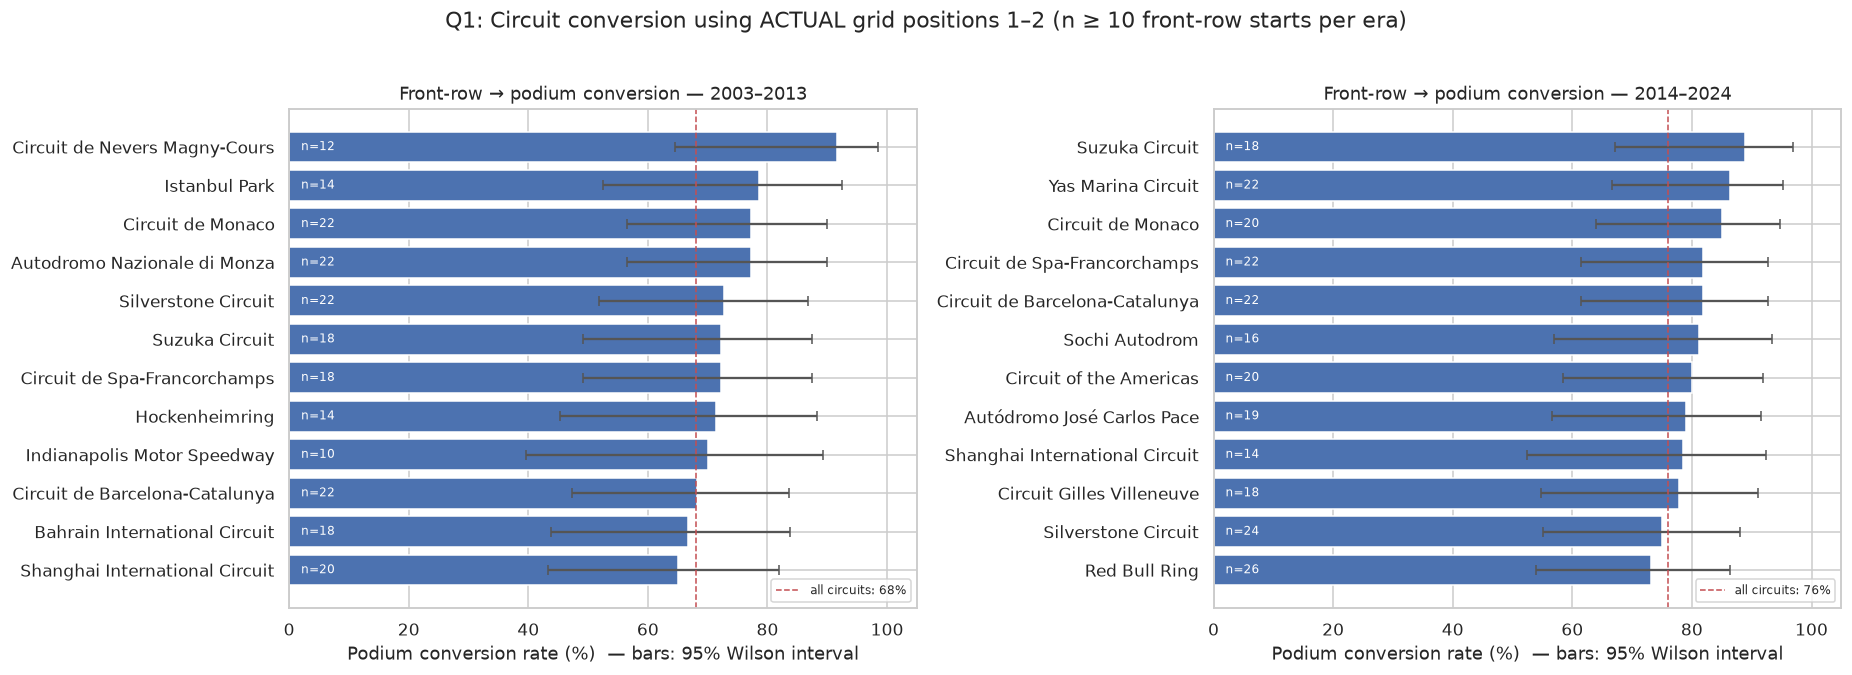

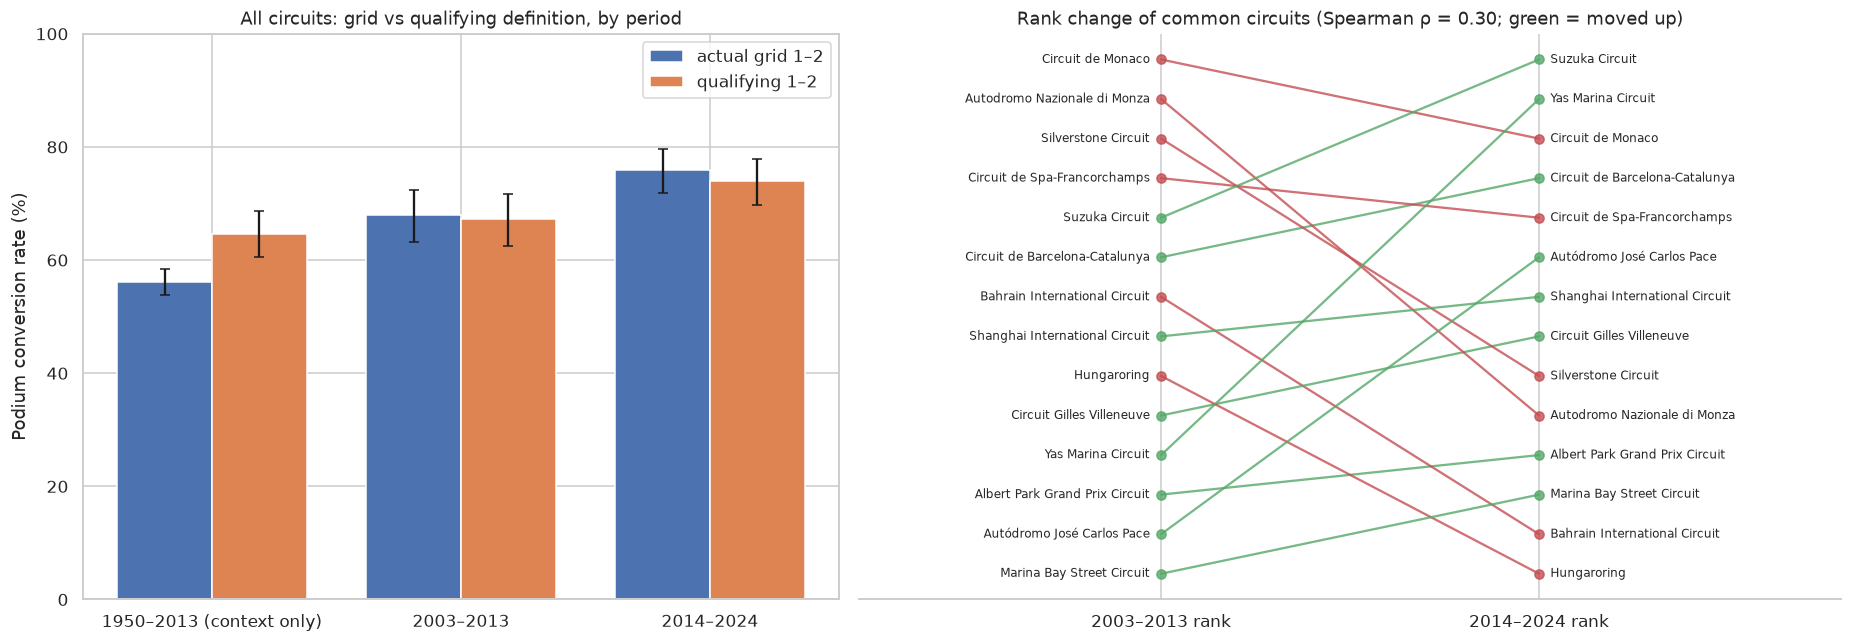

In [34]:
# -----------------------------
# Q1 — Visualization
# -----------------------------

# Figure 1: top circuits per era with 95% Wilson intervals and sample sizes.
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharex=True)
for ax, era in zip(axes, Q1_ERAS):
    top = (
        q1_ranked[q1_ranked["era"] == era]
        .sort_values(["conversion_rate", "front_row_starts"], ascending=[False, False])
        .head(12)
        .sort_values("conversion_rate")
    )
    rate = top["conversion_rate"] * 100
    err = np.vstack([rate - top["ci_low"] * 100, top["ci_high"] * 100 - rate])
    ax.barh(top["circuit_name"], rate, xerr=err, color="#4C72B0", ecolor="#555555", capsize=3)
    era_overall = q1_overall.query("period == @era and definition == 'actual grid 1–2'")["conversion_rate"].iloc[0]
    ax.axvline(era_overall * 100, color="#C44E52", ls="--", lw=1, label=f"all circuits: {era_overall:.0%}")
    for y, (_, row) in enumerate(top.iterrows()):
        ax.text(2, y, f"n={int(row['front_row_starts'])}", va="center", fontsize=8, color="white")
    ax.set_title(f"Front-row → podium conversion — {era}")
    ax.set_xlabel("Podium conversion rate (%)  — bars: 95% Wilson interval")
    ax.set_xlim(0, 105)
    ax.legend(loc="lower right", fontsize=8)
plt.suptitle(f"Q1: Circuit conversion using ACTUAL grid positions 1–2 (n ≥ {MIN_Q1_STARTS} front-row starts per era)", y=1.02)
plt.tight_layout()
plt.show()

# Figure 2: era-level conversion by definition, and the rank change of common circuits.
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.3]})

ov = q1_overall.copy()
x = np.arange(len(ov["period"].unique()))
for k, (def_name, _) in enumerate(definitions):
    part = ov[ov["definition"] == def_name]
    rate = part["conversion_rate"].values * 100
    err = np.vstack([rate - part["ci_low"].values * 100, part["ci_high"].values * 100 - rate])
    axes[0].bar(x + (k - 0.5) * 0.38, rate, width=0.38, yerr=err, capsize=3, label=def_name)
axes[0].set_xticks(x)
axes[0].set_xticklabels(ov["period"].unique())
axes[0].set_ylabel("Podium conversion rate (%)")
axes[0].set_ylim(0, 100)
axes[0].set_title("All circuits: grid vs qualifying definition, by period")
axes[0].legend()

if len(q1_compare) >= 3:
    for _, r in q1_compare.iterrows():
        up = r["rank_shift"] > 0
        axes[1].plot([0, 1], [r["rank_2003–2013"], r["rank_2014–2024"]],
                     color="#55A868" if up else "#C44E52", marker="o", alpha=0.8)
        axes[1].text(-0.03, r["rank_2003–2013"], r["circuit_name"], ha="right", va="center", fontsize=8)
        axes[1].text(1.03, r["rank_2014–2024"], r["circuit_name"], ha="left", va="center", fontsize=8)
    axes[1].invert_yaxis()
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(["2003–2013 rank", "2014–2024 rank"])
    axes[1].set_xlim(-0.8, 1.8)
    axes[1].set_yticks([])
    axes[1].set_title(f"Rank change of common circuits (Spearman ρ = {q1_rank_corr:.2f}; green = moved up)")
    for s in ["top", "right", "left"]:
        axes[1].spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [35]:
# -----------------------------
# Q1 — Automatic notebook answer
# -----------------------------

def q1_top_sentence(era):
    part = q1_ranked[q1_ranked["era"] == era].sort_values(
        ["conversion_rate", "front_row_starts"], ascending=[False, False]
    )
    if part.empty:
        return f"No circuit met the n ≥ {MIN_Q1_STARTS} reporting threshold in {era}."
    top3 = ", ".join(
        f"{r['circuit_name']} {pct(r['conversion_rate'])} ({int(r['podiums'])}/{int(r['front_row_starts'])}, "
        f"95% CI {pct(r['ci_low'], 0)}–{pct(r['ci_high'], 0)})"
        for _, r in part.head(3).iterrows()
    )
    return f"**{era}** — top circuits (n ≥ {MIN_Q1_STARTS}): {top3}."

def overall(period, definition):
    r = q1_overall.query("period == @period and definition == @definition").iloc[0]
    return f"{pct(r['conversion_rate'])} (n={int(r['front_row_starts'])})"

if pd.isna(q1_rank_corr):
    rank_text = "There were not enough common circuits to quantify the ranking change."
elif q1_rank_corr >= 0.7:
    rank_text = f"The circuit ranking is broadly **stable** (Spearman ρ = **{q1_rank_corr:.2f}** over {len(q1_compare)} common circuits)."
elif q1_rank_corr >= 0.4:
    rank_text = f"The circuit ranking changes **moderately** (Spearman ρ = **{q1_rank_corr:.2f}** over {len(q1_compare)} common circuits)."
else:
    rank_text = f"The circuit ranking changes **substantially** (Spearman ρ = **{q1_rank_corr:.2f}** over {len(q1_compare)} common circuits)."

display(Markdown(
    "### Q1 answer\n\n"
    + q1_top_sentence("2003–2013") + "\n\n"
    + q1_top_sentence("2014–2024") + "\n\n"
    + f"**Era level (actual grid):** front-row conversion rose from **{overall('2003–2013', 'actual grid 1–2')}** "
      f"in 2003–2013 to **{overall('2014–2024', 'actual grid 1–2')}** in 2014–2024. "
      f"For context, the full 1950–2013 history converts only {overall('1950–2013 (context only)', 'actual grid 1–2')}, "
      "because of lower reliability and larger fields in early eras.\n\n"
    + rank_text + " "
    + f"However, a single circuit's 95% interval is typically **~{q1_median_ci_width_pp:.0f} percentage points wide**, "
      "so most individual rank positions are not statistically distinguishable. The robust finding is the "
      "**era-level increase**, not the exact order of circuits.\n\n"
    + f"**Qualifying vs grid:** {q1_lost_front_row} drivers qualified on the front row but started elsewhere, and "
      f"{q1_gained_front_row} were promoted onto it ({q1_changed_share:.1%} of all front-row cases). "
      f"Using the qualifying definition instead gives {overall('2003–2013', 'qualifying 1–2')} → "
      f"{overall('2014–2024', 'qualifying 1–2')}, and circuit rates differ by {q1_def_gap_pp:.1f} points on average, "
      "so the conclusion does not depend on the definition. The actual grid stays the primary answer because it is where the car really started."
))

### Q1 answer

**2003–2013** — top circuits (n ≥ 10): Circuit de Nevers Magny-Cours 91.7% (11/12, 95% CI 65%–99%), Istanbul Park 78.6% (11/14, 95% CI 52%–92%), Circuit de Monaco 77.3% (17/22, 95% CI 57%–90%).

**2014–2024** — top circuits (n ≥ 10): Suzuka Circuit 88.9% (16/18, 95% CI 67%–97%), Yas Marina Circuit 86.4% (19/22, 95% CI 67%–95%), Circuit de Monaco 85.0% (17/20, 95% CI 64%–95%).

**Era level (actual grid):** front-row conversion rose from **68.0% (n=400)** in 2003–2013 to **76.0% (n=454)** in 2014–2024. For context, the full 1950–2013 history converts only 56.2% (n=1796), because of lower reliability and larger fields in early eras.

The circuit ranking changes **substantially** (Spearman ρ = **0.30** over 14 common circuits). However, a single circuit's 95% interval is typically **~38 percentage points wide**, so most individual rank positions are not statistically distinguishable. The robust finding is the **era-level increase**, not the exact order of circuits.

**Qualifying vs grid:** 36 drivers qualified on the front row but started elsewhere, and 36 were promoted onto it (7.0% of all front-row cases). Using the qualifying definition instead gives 67.2% (n=400) → 74.0% (n=454), and circuit rates differ by 1.8 points on average, so the conclusion does not depend on the definition. The actual grid stays the primary answer because it is where the car really started.

### Q1 · Grain, missingness, and cutoff justification

* **Grain:** one row per `(raceId, driverId)` until the final circuit aggregation. Phase 1 guaranteed that grain, and the joins above assert it is preserved. Non-starters are removed because a driver who never started cannot convert a start.
* **Missingness:**
  * Qualifying coverage is incomplete before 2003 (absent before 1994, patchy 1996–2002). The comparison therefore uses 2003–2013 vs 2014–2024, where both definitions are available on the same races.
  * Pit-lane starters have no `grid_pos` and are simply not front-row starters.
  * Nothing is imputed.
* **Prediction cutoff:** qualifying position and the final grid are both known before lights out, so both are valid pre-race information. `podium` is post-race and is used here only as the historical outcome being measured; it must not become a same-race model feature.
* **Limitations:**
  * Each circuit has only about 20 front-row starts per era, so circuit ranks carry wide confidence intervals.
  * The rates are descriptive, not causal: team dominance, reliability and track layout all contribute.

## 8.2 · DE-Q2 — Is there a home-country podium effect after controlling for grid?

> **Question.** Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting position?

### Analysis design

The dataset contains a driver's **nationality**, not a formal "home country" field, so we use nationality-country matching as the operational definition and state that limitation explicitly.

**Multi-hop path:**  
`results → races → circuits` and `results → drivers`.

To control for starting position, we do two things:

1. plot home vs away podium rates inside **similar grid-position bands**, and
2. calculate **standardized rates using exact grid positions** with the *same pooled grid-position weights* for home and away drivers.

The second calculation prevents the result from being driven simply by home drivers starting nearer the front.


In [36]:
# -----------------------------
# Q2 — Normalize driver nationality and circuit country
# -----------------------------

# Ergast uses demonyms for drivers ("British") but country labels for circuits ("UK").
# We map both to a shared canonical country name. Unknown nationalities stay missing;
# they are NOT silently treated as "away".
NATIONALITY_TO_COUNTRY = {
    "American": "United States",
    "Argentine": "Argentina",
    "Argentinian": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "United Kingdom",
    "Canadian": "Canada",
    "Chilean": "Chile",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "East German": "Germany",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Rhodesian": "Zimbabwe",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela"
}

CIRCUIT_COUNTRY_CANONICAL = {
    "UK": "United Kingdom",
    "USA": "United States",
    "UAE": "United Arab Emirates",
    "Korea": "South Korea"
}

q2_drivers = clean["drivers"][["driverId", "nationality"]].copy()
q2_drivers["driver_country"] = q2_drivers["nationality"].map(NATIONALITY_TO_COUNTRY)

q2_circuits = clean["circuits"][["circuitId", "country"]].copy()
q2_circuits["circuit_country"] = q2_circuits["country"].replace(CIRCUIT_COUNTRY_CANONICAL)

# Audit the mapping instead of hiding unmapped demonyms.
unmapped_nationalities = (
    q2_drivers.loc[q2_drivers["driver_country"].isna(), "nationality"]
    .dropna().value_counts()
)
print("Unmapped driver nationalities:", len(unmapped_nationalities))
if len(unmapped_nationalities):
    display(unmapped_nationalities.rename("drivers").to_frame())

# Build the driver-race table through the required multi-hop joins.
de_q2 = (
    clean["results"][[
        "raceId", "driverId", "grid_pos", "non_starter", "podium"
    ]]
    .merge(
        clean["races"][["raceId", "year", "circuitId", "name"]].rename(columns={"name": "race_name"}),
        on="raceId", how="left", validate="many_to_one"
    )
    .merge(
        q2_circuits[["circuitId", "circuit_country"]],
        on="circuitId", how="left", validate="many_to_one"
    )
    .merge(
        q2_drivers[["driverId", "nationality", "driver_country"]],
        on="driverId", how="left", validate="many_to_one"
    )
)

assert len(de_q2) == len(clean["results"]), "Q2 join unexpectedly changed the driver-race count."
assert not de_q2.duplicated(["raceId", "driverId"]).any()

# Home/away is unknown when nationality could not be mapped; do not label those rows "away".
home_known = de_q2["driver_country"].notna() & de_q2["circuit_country"].notna()
de_q2["is_home"] = pd.Series(pd.NA, index=de_q2.index, dtype="boolean")
de_q2.loc[home_known, "is_home"] = (
    de_q2.loc[home_known, "driver_country"] ==
    de_q2.loc[home_known, "circuit_country"]
)

# We need a real starting position to control for grid.
q2_analysis = de_q2.loc[
    (~de_q2["non_starter"]) &
    de_q2["grid_pos"].notna() &
    de_q2["is_home"].notna()
].copy()

print("Q2 driver-races after requiring a known grid and home/away label:", f"{len(q2_analysis):,}")
print("Home-country starts:", f"{int(q2_analysis['is_home'].sum()):,}")
print("Away starts:", f"{int((~q2_analysis['is_home']).sum()):,}")
print("Rows excluded because home/away could not be determined:",
      f"{int(de_q2['is_home'].isna().sum()):,}")

Unmapped driver nationalities: 2


,drivers
nationality,
American-Italian,1
Argentine-Italian,1


Q2 driver-races after requiring a known grid and home/away label: 25,030
Home-country starts: 2,322
Away starts: 22,708
Rows excluded because home/away could not be determined: 4


**Why not compare the two raw percentages only?** If home drivers started further forward (or further back) than away drivers, the raw podium rates would mostly reflect grid position. The next cell therefore:

1. **standardizes** home and away rates to the **same exact-grid distribution**, so both groups are compared as if they had started from identical positions;
2. adds a **95% confidence interval** with a **race-level bootstrap** (resampling whole races, because drivers in the same race are not independent);
3. runs two **robustness checks**:
   * **excluding the Indianapolis 500 (1950–1960)**, a championship round contested almost only by American drivers, which would create automatic "home" podiums;
   * **modern seasons only (2003–2024)**, where one-off local drivers are rare.

Grid bands are used only in the chart because they are easier to read.

In [37]:
# -----------------------------
# Q2 — Raw rates, exact-grid standardization, bootstrap CI, robustness checks
# -----------------------------

# Raw comparison first, only as a reference.
q2_raw = (
    q2_analysis.groupby("is_home", observed=True)["podium"]
    .agg(starts="size", podiums="sum", podium_rate="mean")
    .reset_index()
)
q2_raw["location"] = q2_raw["is_home"].map({True: "Home", False: "Away"})
q2_raw["mean_grid"] = q2_raw["is_home"].map(q2_analysis.groupby("is_home")["grid_pos"].mean().astype(float))
display(q2_raw[["location", "starts", "podiums", "podium_rate", "mean_grid"]])

def _prep(df):
    """Encode the columns needed for standardization as integer/float arrays."""
    grid_codes, _ = pd.factorize(df["grid_pos"].astype(int))
    race_codes, _ = pd.factorize(df["raceId"])
    home = df["is_home"].astype(bool).to_numpy().astype(int)
    podium = df["podium"].to_numpy(dtype=float)
    return grid_codes, home, podium, race_codes

def _standardized_rates(grid_codes, home, podium, w):
    """Home and away podium rates re-weighted to the SAME pooled exact-grid distribution.

    Only grid positions observed for BOTH home and away drivers are used, so each
    group is evaluated on exactly the same mix of starting positions.
    `w` is a per-row weight (all ones for the point estimate, resample counts in the bootstrap).
    """
    G = grid_codes.max() + 1
    idx = grid_codes * 2 + home
    num = np.bincount(idx, weights=w * podium, minlength=2 * G).reshape(G, 2)
    den = np.bincount(idx, weights=w, minlength=2 * G).reshape(G, 2)
    valid = (den > 0).all(axis=1)                            # grid positions present in BOTH groups
    rate = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    grid_w = den.sum(axis=1) * valid
    grid_w = grid_w / grid_w.sum()
    home_rate = float((rate[:, 1] * grid_w).sum())
    away_rate = float((rate[:, 0] * grid_w).sum())
    return home_rate, away_rate, (home_rate - away_rate) * 100, int(valid.sum())

def grid_standardized(df):
    g, h, p, _ = _prep(df)
    return _standardized_rates(g, h, p, np.ones(len(df)))

def race_bootstrap_ci(df, n_boot=1000, seed=42):
    """95% CI of the standardized Home − Away difference, resampling WHOLE races with replacement."""
    g, h, p, r = _prep(df)
    n_races = r.max() + 1
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        times_drawn = np.bincount(rng.integers(0, n_races, n_races), minlength=n_races)
        diffs[b] = _standardized_rates(g, h, p, times_drawn[r].astype(float))[2]
    return np.percentile(diffs, [2.5, 97.5])

home_adj, away_adj, q2_adjusted_diff_pp, n_common_grid = grid_standardized(q2_analysis)
q2_ci_low, q2_ci_high = race_bootstrap_ci(q2_analysis)

print(f"Exact grid positions represented in BOTH groups: {n_common_grid}")
print(f"Grid-standardized podium rate — Home: {home_adj:.2%} | Away: {away_adj:.2%}")
print(f"Grid-standardized Home − Away difference: {q2_adjusted_diff_pp:+.2f} pp "
      f"(95% race-bootstrap CI {q2_ci_low:+.2f} to {q2_ci_high:+.2f} pp)")

# Robustness: does the conclusion survive removing the Indy 500 or using modern seasons only?
is_indy500 = q2_analysis["race_name"].str.contains("Indianapolis 500", na=False)
print(f"Home starts that come from the Indianapolis 500: {int((is_indy500 & q2_analysis['is_home']).sum())} "
      f"of {int(q2_analysis['is_home'].sum())}")

robust_rows = []
for label, sub in [
    ("All seasons (main)", q2_analysis),
    ("Excluding Indianapolis 500", q2_analysis[~is_indy500]),
    ("2003–2024 only", q2_analysis[q2_analysis["year"].between(2003, 2024)]),
]:
    h, a, d, _ = grid_standardized(sub)
    lo, hi = (q2_ci_low, q2_ci_high) if label.startswith("All") else race_bootstrap_ci(sub)
    robust_rows.append({"version": label, "home_starts": int(sub["is_home"].sum()),
                        "standardized_home": h, "standardized_away": a,
                        "diff_pp": d, "ci_low_pp": lo, "ci_high_pp": hi,
                        "ci_includes_zero": lo <= 0 <= hi})
q2_robust = pd.DataFrame(robust_rows)
display(q2_robust)

,location,starts,podiums,podium_rate,mean_grid
0,Away,22708,3129,0.137793,11.706887
1,Home,2322,266,0.114556,13.406546


Exact grid positions represented in BOTH groups: 32
Grid-standardized podium rate — Home: 13.28% | Away: 13.60%
Grid-standardized Home − Away difference: -0.32 pp (95% race-bootstrap CI -1.45 to +0.99 pp)
Home starts that come from the Indianapolis 500: 380 of 2322


,version,home_starts,standardized_home,standardized_away,diff_pp,ci_low_pp,ci_high_pp,ci_includes_zero
0,All seasons (main),2322,0.132791,0.135952,-0.316112,-1.447073,0.989018,True
1,Excluding Indianapolis 500,1942,0.134448,0.136529,-0.208079,-1.537473,1.138565,True
2,2003–2024 only,364,0.130732,0.145339,-1.460670,-4.157548,1.362751,True


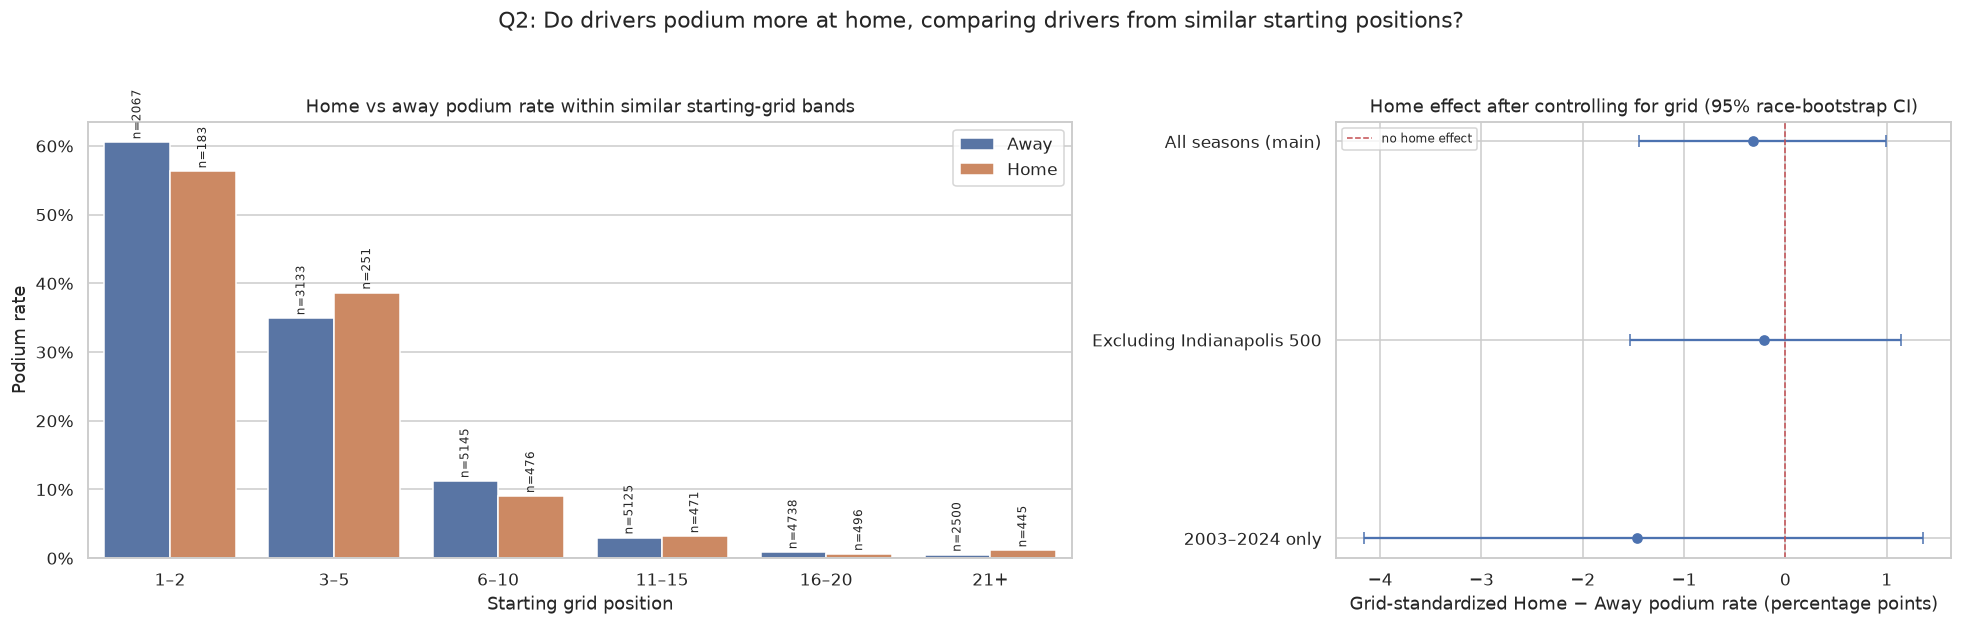

In [38]:
# -----------------------------
# Q2 — Visualization: grid bands + robustness forest plot
# -----------------------------

# Readable bands for plotting only; the adjusted estimate above uses exact positions.
bins = [0, 2, 5, 10, 15, 20, np.inf]
labels = ["1–2", "3–5", "6–10", "11–15", "16–20", "21+"]

q2_analysis["grid_band"] = pd.cut(q2_analysis["grid_pos"].astype(float), bins=bins, labels=labels, right=True)

q2_bands = (
    q2_analysis.groupby(["grid_band", "is_home"], observed=True)["podium"]
    .agg(starts="size", podiums="sum", podium_rate="mean")
    .reset_index()
)
q2_bands["location"] = q2_bands["is_home"].map({True: "Home", False: "Away"})

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

ax = axes[0]
sns.barplot(data=q2_bands, x="grid_band", y="podium_rate", hue="location",
            hue_order=["Away", "Home"], ax=ax)
ax.set_title("Home vs away podium rate within similar starting-grid bands")
ax.set_xlabel("Starting grid position")
ax.set_ylabel("Podium rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for container, location in zip(ax.containers, ["Away", "Home"]):
    loc_rows = q2_bands[q2_bands["location"] == location].set_index("grid_band")
    texts = [f"n={int(loc_rows.loc[b, 'starts'])}" if b in loc_rows.index else "" for b in labels]
    ax.bar_label(container, labels=texts, padding=2, fontsize=8, rotation=90)
ax.legend(title="")

ax = axes[1]
y = np.arange(len(q2_robust))[::-1]
ax.errorbar(q2_robust["diff_pp"], y,
            xerr=[q2_robust["diff_pp"] - q2_robust["ci_low_pp"], q2_robust["ci_high_pp"] - q2_robust["diff_pp"]],
            fmt="o", color="#4C72B0", ecolor="#4C72B0", capsize=4)
ax.axvline(0, color="#C44E52", ls="--", lw=1, label="no home effect")
ax.set_yticks(y)
ax.set_yticklabels(q2_robust["version"])
ax.set_xlabel("Grid-standardized Home − Away podium rate (percentage points)")
ax.set_title("Home effect after controlling for grid (95% race-bootstrap CI)")
ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Q2: Do drivers podium more at home, comparing drivers from similar starting positions?", y=1.03)
plt.tight_layout()
plt.show()

In [39]:
# -----------------------------
# Q2 — Automatic notebook answer
# -----------------------------

raw_home = q2_raw.loc[q2_raw["is_home"], "podium_rate"].iloc[0]
raw_away = q2_raw.loc[~q2_raw["is_home"], "podium_rate"].iloc[0]
grid_home = q2_raw.loc[q2_raw["is_home"], "mean_grid"].iloc[0]
grid_away = q2_raw.loc[~q2_raw["is_home"], "mean_grid"].iloc[0]

if q2_ci_low <= 0 <= q2_ci_high:
    verdict = (
        f"The 95% confidence interval (**{q2_ci_low:+.2f} to {q2_ci_high:+.2f} points**) includes zero, so there is "
        "**no detectable home advantage (or disadvantage)** once starting position is controlled for."
    )
else:
    direction = "higher" if q2_adjusted_diff_pp > 0 else "lower"
    verdict = (
        f"The 95% confidence interval (**{q2_ci_low:+.2f} to {q2_ci_high:+.2f} points**) excludes zero, so the home "
        f"podium rate is **{direction}** after controlling for starting position."
    )

robust_ok = q2_robust["ci_includes_zero"].all() if (q2_ci_low <= 0 <= q2_ci_high) else (~q2_robust["ci_includes_zero"]).all()
robust_text = "; ".join(
    f"{r['version']}: {r['diff_pp']:+.2f} pp (CI {r['ci_low_pp']:+.2f} to {r['ci_high_pp']:+.2f})"
    for _, r in q2_robust.iterrows()
)

display(Markdown(
    "### Q2 answer\n\n"
    f"**Raw comparison (misleading):** home drivers podium **{pct(raw_home)}** of the time versus **{pct(raw_away)}** away. "
    f"But home drivers also start further back on average (grid {grid_home:.1f} vs {grid_away:.1f}), "
    "largely because local one-off drivers were entered at their home races. The raw gap is therefore a selection effect.\n\n"
    f"**Controlled comparison:** standardized to the same exact-grid distribution, the rates are **{pct(home_adj)} at home** "
    f"and **{pct(away_adj)} away**, a difference of **{q2_adjusted_diff_pp:+.2f} percentage points**. {verdict}\n\n"
    f"**Robustness:** {robust_text}. "
    + ("The conclusion is the same in every version." if robust_ok else "The versions do not all agree, so the conclusion is sensitive to these choices.")
    + "\n\nThis is a descriptive association, not a causal estimate."
))

### Q2 answer

**Raw comparison (misleading):** home drivers podium **11.5%** of the time versus **13.8%** away. But home drivers also start further back on average (grid 13.4 vs 11.7), largely because local one-off drivers were entered at their home races. The raw gap is therefore a selection effect.

**Controlled comparison:** standardized to the same exact-grid distribution, the rates are **13.3% at home** and **13.6% away**, a difference of **-0.32 percentage points**. The 95% confidence interval (**-1.45 to +0.99 points**) includes zero, so there is **no detectable home advantage (or disadvantage)** once starting position is controlled for.

**Robustness:** All seasons (main): -0.32 pp (CI -1.45 to +0.99); Excluding Indianapolis 500: -0.21 pp (CI -1.54 to +1.14); 2003–2024 only: -1.46 pp (CI -4.16 to +1.36). The conclusion is the same in every version.

This is a descriptive association, not a causal estimate.

### Q2 · Grain, missingness, and cutoff justification

* **Grain:** one driver entering one race. `(raceId, driverId)` uniqueness is preserved through all joins before any aggregation.
* **Control for grid:** the main estimate re-weights home and away rates to the same exact-grid distribution. The banded chart is only a readable view.
* **Uncertainty:** the confidence interval comes from a race-level bootstrap. Results of drivers in the same race are correlated, so whole races are resampled.
* **Robustness:**
  * excluding the Indianapolis 500 (1950–1960), whose almost-all-American field creates automatic "home" podiums;
  * restricting to 2003–2024.
* **Missingness:**
  * An unmapped nationality (the two dual nationalities "American-Italian" and "Argentine-Italian") is treated as **unknown**, not automatically "away", and those rows are excluded.
  * Non-starters have no starting position and are excluded.
  * Nothing is imputed.
* **Prediction cutoff:** nationality, circuit country and grid are all known before the race. `podium` is a post-race outcome used only for this historical analysis.
* **Limitations:**
  * Nationality is only a proxy for "home": it does not capture residence or a driver's personal definition of home.
  * The comparison is descriptive, not causal.

## 8.3 · DE-Q3 — Which constructors have the highest mechanical-retirement rate?

> **Question.** Which constructors have the highest mechanical-retirement rate in **2014–2021** versus **2022–2024**?

### Analysis design

Phase 1 already converted the free-text `status` values into a reviewed taxonomy:

* `mechanical` = component/car failures,
* `accident_or_driver` = crashes and driver-related causes,
* `regulatory` = exclusions/disqualifications,
* `ambiguous` = cases that could plausibly be mechanical *or* caused by contact/strategy/pit errors.

The main answer follows the strict milestone definition and counts only `mechanical`. We also show a **sensitivity rate** where `ambiguous` is included, so uncertain statuses are visible rather than silently forced into one class.

**Multi-hop path:**  
`results → races`, `results → constructors`, and `results → status`.

**Denominator:** race **starts**, not all entries.

**Uncertainty:** every rate gets a 95% Wilson interval. Constructors with fewer than **50 starts** in an era are flagged as **low-sample**, and the answer also names the leader among constructors with at least 50 starts.

In [40]:
# -----------------------------
# Q3 — Build the constructor-start analytical table
# -----------------------------

de_q3 = (
    clean["results"][[
        "raceId", "driverId", "constructorId", "statusId", "non_starter"
    ]]
    .merge(
        clean["races"][["raceId", "year"]],
        on="raceId", how="left", validate="many_to_one"
    )
    .merge(
        clean["constructors"][["constructorId", "name"]],
        on="constructorId", how="left", validate="many_to_one"
    )
    .rename(columns={"name": "constructor_name"})
    .merge(
        clean["status"][["statusId", "status", "status_category"]],
        on="statusId", how="left", validate="many_to_one"
    )
)

assert len(de_q3) == len(clean["results"]), "Q3 join unexpectedly changed the driver-race count."
assert de_q3[["year", "constructor_name", "status_category"]].notna().all().all(), \
    "Q3 has missing values after joins that should have been protected by Phase 1 FK checks."

# The question explicitly asks for starts. Remove rows Phase 1 identified as non-starters.
q3_starts = de_q3.loc[
    de_q3["year"].between(2014, 2024) &
    (~de_q3["non_starter"])
].copy()

q3_starts["era"] = np.select(
    [
        q3_starts["year"].between(2014, 2021),
        q3_starts["year"].between(2022, 2024)
    ],
    ["2014–2021", "2022–2024"],
    default="outside"
)

q3_starts["mechanical_retirement"] = (
    q3_starts["status_category"].astype(str) == "mechanical"
)
q3_starts["ambiguous_retirement"] = (
    q3_starts["status_category"].astype(str) == "ambiguous"
)

print("Q3 race starts:", f"{len(q3_starts):,}")
print("Years:", int(q3_starts["year"].min()), "→", int(q3_starts["year"].max()))
print("Strict mechanical retirements:", int(q3_starts["mechanical_retirement"].sum()))
print("Ambiguous retirement statuses:", int(q3_starts["ambiguous_retirement"].sum()))

# Audit which concrete status strings are driving the strict mechanical count.
q3_mech_reasons = (
    q3_starts[q3_starts["mechanical_retirement"]]
    .groupby(["era", "status"], observed=True)
    .size()
    .rename("count")
    .reset_index()
    .sort_values(["era", "count"], ascending=[True, False])
)
display(q3_mech_reasons.groupby("era", group_keys=False).head(12))


Q3 race starts: 4,619
Years: 2014 → 2024
Strict mechanical retirements: 393
Ambiguous retirement statuses: 70


,era,status,count
9,2014–2021,Engine,59
2,2014–2021,Brakes,44
18,2014–2021,Power Unit,35
12,2014–2021,Gearbox,33
24,2014–2021,Suspension,24
7,2014–2021,Electrical,13
19,2014–2021,Power loss,11
33,2014–2021,Wheel,11
13,2014–2021,Hydraulics,10
15,2014–2021,Oil leak,8


In [41]:
# -----------------------------
# Q3 — Mechanical-retirement rates by constructor and era
# -----------------------------

q3_rates = (
    q3_starts
    .groupby(["era", "constructorId", "constructor_name"], observed=True)
    .agg(
        starts=("driverId", "size"),
        mechanical_retirements=("mechanical_retirement", "sum"),
        ambiguous_retirements=("ambiguous_retirement", "sum")
    )
    .reset_index()
)

q3_rates["mechanical_retirement_rate"] = q3_rates["mechanical_retirements"] / q3_rates["starts"]
q3_rates["sensitivity_rate_including_ambiguous"] = (
    (q3_rates["mechanical_retirements"] + q3_rates["ambiguous_retirements"]) / q3_rates["starts"]
)
lo, hi = wilson_ci(q3_rates["mechanical_retirements"], q3_rates["starts"])
q3_rates["ci_low"], q3_rates["ci_high"] = lo, hi

# Reporting rules:
#  * constructors with < 20 starts in an era are not ranked at all;
#  * constructors with 20–49 starts are ranked but flagged as low-sample (their interval is wide).
MIN_Q3_STARTS = 20
LOW_SAMPLE_Q3 = 50
q3_ranked = q3_rates[q3_rates["starts"] >= MIN_Q3_STARTS].copy()
q3_ranked["low_sample"] = q3_ranked["starts"] < LOW_SAMPLE_Q3
q3_ranked["rank_strict"] = (
    q3_ranked.groupby("era")["mechanical_retirement_rate"].rank(method="min", ascending=False).astype("Int64")
)
q3_ranked["rank_sensitivity"] = (
    q3_ranked.groupby("era")["sensitivity_rate_including_ambiguous"].rank(method="min", ascending=False).astype("Int64")
)

print(f"Constructor-era rows: {len(q3_rates)}")
print(f"Constructor-era rows with >= {MIN_Q3_STARTS} starts: {len(q3_ranked)} "
      f"(of which low-sample < {LOW_SAMPLE_Q3}: {int(q3_ranked['low_sample'].sum())})")

display(
    q3_ranked.sort_values(["era", "mechanical_retirement_rate", "starts"], ascending=[True, False, False])
    [["era", "constructor_name", "starts", "mechanical_retirements", "mechanical_retirement_rate",
      "ci_low", "ci_high", "low_sample", "ambiguous_retirements",
      "sensitivity_rate_including_ambiguous", "rank_strict", "rank_sensitivity"]]
)

Constructor-era rows: 31
Constructor-era rows with >= 20 starts: 31 (of which low-sample < 50: 6)


,era,constructor_name,starts,mechanical_retirements,mechanical_retirement_rate,ci_low,ci_high,low_sample,ambiguous_retirements,sensitivity_rate_including_ambiguous,rank_strict,rank_sensitivity
12,2014–2021,Caterham,34,8,0.235294,0.124368,0.399965,True,3,0.323529,1,1
13,2014–2021,Lotus F1,76,14,0.184211,0.113025,0.285785,False,4,0.236842,2,2
3,2014–2021,Toro Rosso,242,39,0.161157,0.120186,0.212717,False,5,0.181818,3,3
0,2014–2021,McLaren,320,46,0.14375,0.109532,0.186421,False,5,0.159375,4,5
2,2014–2021,Renault,200,28,0.14,0.098669,0.194900,False,5,0.165,5,4
7,2014–2021,Sauber,200,23,0.115,0.077863,0.166648,False,4,0.135,6,6
5,2014–2021,Red Bull,320,34,0.10625,0.077034,0.144807,False,4,0.11875,7,8
11,2014–2021,Marussia,31,3,0.096774,0.033464,0.249003,True,0,0.096774,8,12
16,2014–2021,Racing Point,76,7,0.092105,0.045333,0.178129,False,1,0.105263,9,9
17,2014–2021,AlphaTauri,77,7,0.090909,0.044735,0.175963,False,1,0.103896,10,10


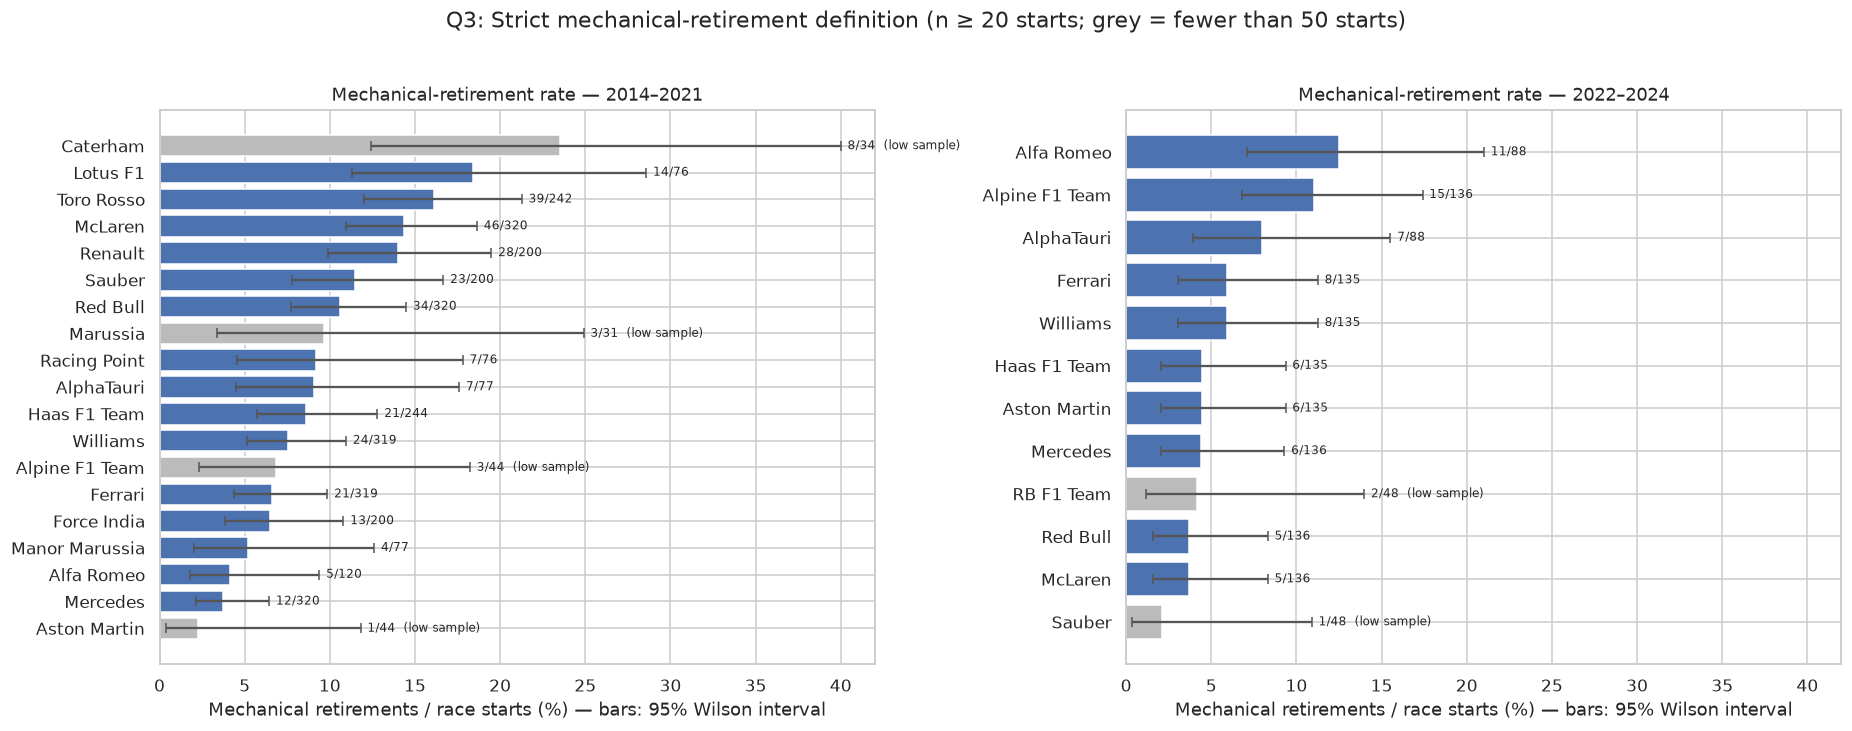

Top constructor if ambiguous statuses are ALSO counted:


,era,constructor_name,starts,mechanical_retirement_rate,sensitivity_rate_including_ambiguous
12,2014–2021,Caterham,34,0.235294,0.323529
24,2022–2024,Alfa Romeo,88,0.125,0.125


2014–2021: Spearman correlation between strict and broad rankings = 0.96
2022–2024: Spearman correlation between strict and broad rankings = 0.70


In [42]:
# -----------------------------
# Q3 — Visualization
# -----------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), sharex=True)
for ax, era in zip(axes, ["2014–2021", "2022–2024"]):
    plot_df = q3_ranked[q3_ranked["era"] == era].sort_values("mechanical_retirement_rate")
    rate = plot_df["mechanical_retirement_rate"] * 100
    err = np.vstack([rate - plot_df["ci_low"] * 100, plot_df["ci_high"] * 100 - rate])
    colors = np.where(plot_df["low_sample"], "#BBBBBB", "#4C72B0")
    ax.barh(plot_df["constructor_name"], rate, xerr=err, color=colors, ecolor="#555555", capsize=3)
    for y, (_, row) in enumerate(plot_df.iterrows()):
        flag = "  (low sample)" if row["low_sample"] else ""
        ax.text(row["ci_high"] * 100 + 0.4, y,
                f"{int(row['mechanical_retirements'])}/{int(row['starts'])}{flag}", va="center", fontsize=8)
    ax.set_title(f"Mechanical-retirement rate — {era}")
    ax.set_xlabel("Mechanical retirements / race starts (%) — bars: 95% Wilson interval")
    ax.set_ylabel("")
plt.suptitle(
    f"Q3: Strict mechanical-retirement definition (n ≥ {MIN_Q3_STARTS} starts; grey = fewer than {LOW_SAMPLE_Q3} starts)",
    y=1.02
)
plt.tight_layout()
plt.show()

# Sensitivity check: would including ambiguous statuses change the top constructor?
sensitivity_top = (
    q3_ranked.sort_values(["era", "sensitivity_rate_including_ambiguous", "starts"], ascending=[True, False, False])
    .groupby("era", group_keys=False).head(1)
)
print("Top constructor if ambiguous statuses are ALSO counted:")
display(sensitivity_top[["era", "constructor_name", "starts",
                         "mechanical_retirement_rate", "sensitivity_rate_including_ambiguous"]])

# How stable is the whole ranking under the broader definition?
for era in ["2014–2021", "2022–2024"]:
    part = q3_ranked[q3_ranked["era"] == era]
    rho = part["mechanical_retirement_rate"].corr(part["sensitivity_rate_including_ambiguous"], method="spearman")
    print(f"{era}: Spearman correlation between strict and broad rankings = {rho:.2f}")

In [43]:
# -----------------------------
# Q3 — Automatic notebook answer
# -----------------------------

def q3_leader(df):
    return df.sort_values(["mechanical_retirement_rate", "starts"], ascending=[False, False]).iloc[0]

def q3_describe(r):
    return (f"**{r['constructor_name']}** — **{pct(r['mechanical_retirement_rate'])}** "
            f"({int(r['mechanical_retirements'])}/{int(r['starts'])} starts, "
            f"95% CI {pct(r['ci_low'], 0)}–{pct(r['ci_high'], 0)})")

answer_parts = []
for era in ["2014–2021", "2022–2024"]:
    part = q3_ranked[q3_ranked["era"] == era]
    if part.empty:
        answer_parts.append(f"**{era}:** no constructor met the n ≥ {MIN_Q3_STARTS} reporting threshold.")
        continue
    top = q3_leader(part)
    top3 = ", ".join(
        f"{r['constructor_name']} {pct(r['mechanical_retirement_rate'])}"
        for _, r in part.sort_values("mechanical_retirement_rate", ascending=False).head(3).iterrows()
    )
    text = f"**{era}:** highest strict mechanical-retirement rate: {q3_describe(top)}. Top 3: {top3}."
    if top["low_sample"]:
        robust = part[~part["low_sample"]]
        if not robust.empty:
            text += (f" ⚠ {top['constructor_name']} has only {int(top['starts'])} starts, so its interval is wide; "
                     f"among constructors with at least {LOW_SAMPLE_Q3} starts the leader is {q3_describe(q3_leader(robust))}.")
    reliable_pool = part[~part["low_sample"]] if (~part["low_sample"]).any() else part
    lowest = reliable_pool.sort_values(["mechanical_retirement_rate", "starts"], ascending=[True, False]).iloc[0]
    text += (f" Most reliable (≥ {LOW_SAMPLE_Q3} starts): {lowest['constructor_name']} "
             f"({pct(lowest['mechanical_retirement_rate'])}, {int(lowest['mechanical_retirements'])}/{int(lowest['starts'])}).")
    answer_parts.append(text)

strict_top = (
    q3_ranked.sort_values(["era", "mechanical_retirement_rate", "starts"], ascending=[True, False, False])
    .groupby("era", group_keys=False).head(1)
)
strict_names = dict(zip(strict_top["era"], strict_top["constructor_name"]))
sens_names = dict(zip(sensitivity_top["era"], sensitivity_top["constructor_name"]))
changed_eras = [e for e in ["2014–2021", "2022–2024"] if strict_names.get(e) != sens_names.get(e)]
sensitivity_text = (
    "Including ambiguous statuses changes the top-ranked constructor in: " + ", ".join(changed_eras)
    + ". The strict definition is kept as the primary answer because it follows the milestone definition."
    if changed_eras else
    "Including ambiguous statuses does not change the top-ranked constructor in either era, although individual rates increase."
)

era_rates = q3_starts.groupby("era")["mechanical_retirement"].mean()
display(Markdown(
    "### Q3 answer\n\n"
    + "\n\n".join(answer_parts) + "\n\n"
    + f"**Overall:** the mechanical-retirement rate across all constructors fell from **{pct(era_rates['2014–2021'])}** "
      f"(2014–2021) to **{pct(era_rates['2022–2024'])}** (2022–2024).\n\n"
    + sensitivity_text
))

### Q3 answer

**2014–2021:** highest strict mechanical-retirement rate: **Caterham** — **23.5%** (8/34 starts, 95% CI 12%–40%). Top 3: Caterham 23.5%, Lotus F1 18.4%, Toro Rosso 16.1%. ⚠ Caterham has only 34 starts, so its interval is wide; among constructors with at least 50 starts the leader is **Lotus F1** — **18.4%** (14/76 starts, 95% CI 11%–29%). Most reliable (≥ 50 starts): Mercedes (3.8%, 12/320).

**2022–2024:** highest strict mechanical-retirement rate: **Alfa Romeo** — **12.5%** (11/88 starts, 95% CI 7%–21%). Top 3: Alfa Romeo 12.5%, Alpine F1 Team 11.0%, AlphaTauri 8.0%. Most reliable (≥ 50 starts): McLaren (3.7%, 5/136).

**Overall:** the mechanical-retirement rate across all constructors fell from **9.6%** (2014–2021) to **5.9%** (2022–2024).

Including ambiguous statuses does not change the top-ranked constructor in either era, although individual rates increase.

### Q3 · Grain, missingness, and cutoff justification

* **Grain:** one constructor car-start is one driver-race row. Rates are then aggregated by constructor and era.
* **Denominator:** non-starters are excluded, because the question defines a mechanical retirement as a **race start** that ended because of a component failure.
* **Missingness / classification uncertainty:**
  * Phase 1 reconciled the `statusId` foreign keys, so joined status categories are never missing.
  * Uncertain statuses (e.g. the generic "Retired", punctures, broken wings) stay in a separate `ambiguous` bucket and are tested in a sensitivity analysis instead of being silently classified.
* **Small samples:**
  * Every rate carries a 95% Wilson interval.
  * Constructors with fewer than 50 starts are flagged (grey bars), and the answer also gives the leader among constructors with at least 50 starts.
* **Team names:** constructors are reported under the names recorded by Ergast. Renamed teams (e.g. Toro Rosso → AlphaTauri → RB) appear as separate rows.
* **Prediction cutoff:** the retirement reason is only known after the race. That is acceptable for this historical question, but same-race status must never be used as a pre-race model feature. A team's reliability **in past races** could be a legitimate lagged feature.
* **Limitation:** status labels describe the recorded retirement reason, not a forensic root-cause investigation.

## ✅ Phase 2 summary — Data-Engineering checklist

| Requirement | Status | Where |
|---|---|---|
| All 3 data-engineering questions answered | ✅ | §8.1–§8.3 |
| Multi-hop joins rather than `results.csv` alone | ✅ | each question |
| Visualization for every answer | ✅ | Q1 circuit chart + definition/rank-change chart, Q2 grid-band + robustness forest plot, Q3 constructor chart |
| Grain documented and asserted | ✅ | each question |
| Missingness handled/documented | ✅ | qualifying coverage (2003+ window), nationality mapping, status taxonomy |
| Pre-race cutoff discussed where relevant | ✅ | each question |
| Qualifying position distinguished from actual grid | ✅ both definitions computed | §8.1 |
| Home effect controlled for starting position | ✅ exact-grid standardization + bootstrap CI + Indy 500 / modern-era robustness | §8.2 |
| Mechanical retirement excludes crash/driver/regulatory causes | ✅ strict taxonomy + sensitivity check | §8.3 |
| Uncertainty shown for small samples | ✅ Wilson intervals (Q1, Q3), bootstrap CI (Q2) | §8.1–§8.3 |

**Important for the report:** after a full Run All, copy the automatically generated **Q1**, **Q2** and **Q3 answers** together with their figures. The notebook computes those sentences from the data, so the written conclusion cannot drift away from the displayed numbers.

# 🧠 Phase 3: Feature Selection & Engineering

This section is **add-only**. It does not modify the Phase 1 cleaning or Phase 2 data-engineering code.

### Goal
Build one leakage-safe modelling table for podium prediction that uses only information available **after qualifying and before the race starts**. Every selected and dropped feature is justified with exploratory evidence, and the data is split chronologically into Train/Validation/Test.

### Main design decisions
- **Seasons:** model only **2003–2024**, because the Phase 1 missingness heatmap showed qualifying coverage is near-complete only from 2003.
- **Rows:** remove **non-starters**. Their outcome is already known at the cutoff, so they would be free, easy negatives.
- **Current weekend:** keep **grid** and **qualifying** information.
- **Standings:** build them from the **previous race only**.
- **Recent form:** use `shift(1)` before rolling, so the current race never enters its own predictors.
- **Evidence:** compute the feature-selection evidence on the **training seasons only (2003–2018)**, so validation and test outcomes never influence which features are chosen.
- **Dropped identity/context features**, each with evidence in 9.5:
  - `driverId` (memorisation risk);
  - `constructorId` (renamed teams are unseen categories in later seasons; team strength is already carried by constructor standings and form);
  - `circuitId` (circuit podium rate is structurally flat at about 3 / field size);
  - `round` (no association with podium).
- **Preprocessing:** no imputation or scaling on the full dataset. Learned preprocessing is fitted later on the **training split only**. Its effect is demonstrated in 9.8.


## 9.1 · Build the modelling base

We start from the already-cleaned one-row-per-driver-race table. We create a new object called `feature_base`; nothing in `clean[...]` is overwritten.


In [44]:

# -----------------------------
# 9.1 — Build the modelling base (ADD-ONLY: does not modify clean tables)
# -----------------------------

# Build a NEW table for modelling; clean["results"] itself is not modified.
feature_base = (
    clean["results"][[
        "raceId", "driverId", "constructorId",
        "grid_pos", "pit_lane_start", "non_starter",
        "podium", "positionOrder"
    ]].copy()
    .merge(
        clean["races"][["raceId", "year", "round", "circuitId", "date"]],
        on="raceId", how="left", validate="many_to_one"
    )
    .merge(
        clean["qualifying"][[
            "raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"
        ]].rename(columns={"position": "quali_position"}),
        on=["raceId", "driverId"], how="left", validate="one_to_one"
    )
)

# We use 2003–2024 because the earlier EDA showed qualifying coverage is much more complete here.
feature_base = feature_base.loc[
    feature_base["year"].between(2003, 2024)
].copy()

# A non-starter has no real race-start prediction to make at our cutoff, so exclude these rows.
feature_base = feature_base.loc[~feature_base["non_starter"]].copy()

assert not feature_base.duplicated(["raceId", "driverId"]).any()
assert feature_base["podium"].isin([0, 1]).all()

print("Feature-engineering rows:", f"{len(feature_base):,}")
print("Seasons:", int(feature_base["year"].min()), "→", int(feature_base["year"].max()))
print("Podium rate:", f"{feature_base['podium'].mean():.2%}")


Feature-engineering rows: 8,956
Seasons: 2003 → 2024
Podium rate: 14.34%



## 9.2 · Engineer current-weekend grid and qualifying features

Raw qualifying-session seconds are hard to compare between circuits and have structural missingness. We therefore keep final qualifying position and engineer a **percentage gap to the fastest qualifying time in the same race**. Pit-lane starts are encoded behind the normal grid rather than as zero.


In [45]:

# -----------------------------
# 9.2 — Current-weekend features: grid + qualifying
# -----------------------------

# Number of actual starters in each race after removing non-starters.
feature_base["field_size"] = feature_base.groupby("raceId")["driverId"].transform("size")

# grid_pos is missing for pit-lane starts because Phase 1 decoded raw grid=0.
# Encode pit-lane as "behind the normal grid" = field size + 1.
feature_base["grid_model"] = feature_base["grid_pos"].astype("float64")
pit_mask = feature_base["grid_model"].isna() & feature_base["pit_lane_start"].astype(bool)
feature_base.loc[pit_mask, "grid_model"] = (
    feature_base.loc[pit_mask, "field_size"].astype(float) + 1.0
)

# grid=0 must never be used as-is: a pit-lane start is placed behind the last starter.
assert feature_base["grid_model"].notna().all(), \
    "Unexpected missing grid after removing non-starters and encoding pit-lane starts."

# Use the driver's best valid qualifying-session time.
# We call the comparison 'gap_to_fastest_quali_pct' rather than raw seconds
# because lap length differs strongly from circuit to circuit.
feature_base["best_quali_s"] = feature_base[["q1_s", "q2_s", "q3_s"]].min(axis=1, skipna=True)
feature_base["fastest_quali_s"] = feature_base.groupby("raceId")["best_quali_s"].transform("min")
feature_base["gap_to_fastest_quali_pct"] = (
    (feature_base["best_quali_s"] - feature_base["fastest_quali_s"])
    / feature_base["fastest_quali_s"] * 100
)

feature_base["quali_missing"] = feature_base["quali_position"].isna().astype("int8")
feature_base["pit_lane_start"] = feature_base["pit_lane_start"].astype("int8")

# q1/q2/q3 are NOT mean-imputed: a missing session time often means the driver did not reach that session.
print("Pit-lane starts encoded:", int(pit_mask.sum()))
print("Rows with no qualifying position:", int(feature_base["quali_missing"].sum()))
print("Rows with no usable qualifying time:", int(feature_base["gap_to_fastest_quali_pct"].isna().sum()))


Pit-lane starts encoded: 72
Rows with no qualifying position: 22
Rows with no usable qualifying time: 146



## 9.3 · Engineer leakage-safe standings features

The standings row attached to race `R` already includes race `R`, so using it directly would leak the answer. We therefore sort within each season and use `shift(1)`, meaning race `R` receives the standings after race `R-1`.

Cumulative points are additionally divided by the number of already-completed rounds so that, for example, 80 points early in a season is not treated the same as 80 points near the end.


In [46]:

# -----------------------------
# 9.3 — Leakage-safe standings: use ONLY the previous race's standings
# -----------------------------

race_order = clean["races"][["raceId", "year", "round"]].copy()

# ----- Driver standings -----
ds = (
    clean["driver_standings"][["raceId", "driverId", "points", "position", "wins"]]
    .merge(race_order, on="raceId", how="left", validate="many_to_one")
    .sort_values(["driverId", "year", "round", "raceId"])
    .copy()
)

for src, dst in [
    ("points", "driver_points_before"),
    ("position", "driver_standing_pos_before"),
    ("wins", "driver_wins_before")
]:
    ds[dst] = ds.groupby(["driverId", "year"], observed=True)[src].shift(1)

# At the first race of a season, zero points and zero wins is a fact, not a statistical guess.
ds["driver_points_before"] = ds["driver_points_before"].fillna(0).astype(float)
ds["driver_wins_before"] = ds["driver_wins_before"].fillna(0).astype(float)
ds["driver_standing_missing"] = ds["driver_standing_pos_before"].isna().astype("int8")

driver_pre = ds[[
    "raceId", "driverId",
    "driver_points_before", "driver_standing_pos_before", "driver_wins_before",
    "driver_standing_missing"
]].copy()

# ----- Constructor standings -----
cs = (
    clean["constructor_standings"][["raceId", "constructorId", "points", "position", "wins"]]
    .merge(race_order, on="raceId", how="left", validate="many_to_one")
    .sort_values(["constructorId", "year", "round", "raceId"])
    .copy()
)

for src, dst in [
    ("points", "constructor_points_before"),
    ("position", "constructor_standing_pos_before"),
    ("wins", "constructor_wins_before")
]:
    cs[dst] = cs.groupby(["constructorId", "year"], observed=True)[src].shift(1)

cs["constructor_points_before"] = cs["constructor_points_before"].fillna(0).astype(float)
cs["constructor_wins_before"] = cs["constructor_wins_before"].fillna(0).astype(float)
cs["constructor_standing_missing"] = cs["constructor_standing_pos_before"].isna().astype("int8")

constructor_pre = cs[[
    "raceId", "constructorId",
    "constructor_points_before", "constructor_standing_pos_before", "constructor_wins_before",
    "constructor_standing_missing"
]].copy()

feature_base = (
    feature_base
    .merge(driver_pre, on=["raceId", "driverId"], how="left", validate="one_to_one")
    .merge(constructor_pre, on=["raceId", "constructorId"], how="left", validate="many_to_one")
)

# Some dataset versions can lack a standings row for a participant; make that absence explicit.
for c in ["driver_points_before", "driver_wins_before",
          "constructor_points_before", "constructor_wins_before"]:
    feature_base[c] = feature_base[c].fillna(0.0)

feature_base["driver_standing_missing"] = feature_base["driver_standing_missing"].fillna(1).astype("int8")
feature_base["constructor_standing_missing"] = feature_base["constructor_standing_missing"].fillna(1).astype("int8")

# Normalize cumulative points by how many rounds were already completed.
completed_rounds = (feature_base["round"].astype(float) - 1.0).clip(lower=1.0)
feature_base["driver_points_per_round_before"] = feature_base["driver_points_before"] / completed_rounds
feature_base["constructor_points_per_round_before"] = feature_base["constructor_points_before"] / completed_rounds

# shift(1) is the key anti-leakage step: race R uses the standings after race R-1, never race R itself.
print("Driver standings missing before race:", int(feature_base["driver_standing_missing"].sum()))
print("Constructor standings missing before race:", int(feature_base["constructor_standing_missing"].sum()))


Driver standings missing before race: 600
Constructor standings missing before race: 488



## 9.4 · Engineer recent driver and constructor form

A leakage-safe form feature must use only **earlier races**. For driver form we calculate the previous five starts. For constructor form we first aggregate both cars to one constructor-race row, then shift and roll. That prevents one team-mate's current-race result from leaking into the other driver's features.


In [47]:

# -----------------------------
# 9.4 — Leakage-safe recent form from PAST races only
# -----------------------------

history = (
    clean["results"].loc[
        ~clean["results"]["non_starter"],
        ["raceId", "driverId", "constructorId", "positionOrder", "podium"]
    ].copy()
    .merge(
        clean["races"][["raceId", "date"]],
        on="raceId", how="left", validate="many_to_one"
    )
    .sort_values(["driverId", "date", "raceId"])
)

# Driver form: shift FIRST, then roll.
# This guarantees the current race result never enters its own feature.
history["driver_avg_finish_last5"] = (
    history.groupby("driverId", observed=True)["positionOrder"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)
history["driver_podium_rate_last5"] = (
    history.groupby("driverId", observed=True)["podium"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)

driver_form = history[[
    "raceId", "driverId",
    "driver_avg_finish_last5", "driver_podium_rate_last5"
]].copy()

# Constructor form must be aggregated to ONE row per constructor-race first.
# Otherwise one team-mate's result from the same race could leak into the other driver's row.
team_race = (
    history.groupby(["raceId", "constructorId"], as_index=False)
    .agg(
        team_avg_finish=("positionOrder", "mean"),
        team_podium_rate=("podium", "mean"),
        race_date=("date", "first")
    )
    .sort_values(["constructorId", "race_date", "raceId"])
)

team_race["constructor_avg_finish_last5"] = (
    team_race.groupby("constructorId", observed=True)["team_avg_finish"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)
team_race["constructor_podium_rate_last5"] = (
    team_race.groupby("constructorId", observed=True)["team_podium_rate"]
    .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)

constructor_form = team_race[[
    "raceId", "constructorId",
    "constructor_avg_finish_last5", "constructor_podium_rate_last5"
]].copy()

feature_base = (
    feature_base
    .merge(driver_form, on=["raceId", "driverId"], how="left", validate="one_to_one")
    .merge(constructor_form, on=["raceId", "constructorId"], how="left", validate="many_to_one")
)

feature_base["driver_no_history"] = feature_base["driver_avg_finish_last5"].isna().astype("int8")
feature_base["constructor_no_history"] = feature_base["constructor_avg_finish_last5"].isna().astype("int8")

# Shifting BEFORE rolling guarantees the current race never enters its own feature.
print("Rows with no previous driver start:", int(feature_base["driver_no_history"].sum()))
print("Rows with no previous constructor start:", int(feature_base["constructor_no_history"].sum()))


Rows with no previous driver start: 89
Rows with no previous constructor start: 41


## 9.5 · Exploratory evidence behind the feature choices

This is the evidence section required by the milestone. **All evidence is computed on the training seasons (2003–2018) only.** Looking at validation or test outcomes while choosing features would be a mild form of leakage.

It checks:
1. the monotonic (Spearman) association between each numeric candidate feature and the podium target;
2. how the podium rate changes with the starting-grid band;
3. whether **circuits** have different podium rates (evidence for or against `circuitId`);
4. whether `circuitId` / `constructorId` are **stable categories over time**: what share of validation and test rows carry an ID that never appears in training? One-hot encoding can only learn categories it has seen.

These plots support feature selection; they do **not** claim causality.

Evidence rows (training seasons 2003–2018 only): 6,401


,spearman_with_podium (train)
driver_podium_rate_last5,0.519075
constructor_podium_rate_last5,0.507614
quali_position,-0.493905
grid_model,-0.490624
gap_to_fastest_quali_pct,-0.475533
driver_standing_pos_before,-0.472993
constructor_avg_finish_last5,-0.452894
constructor_standing_pos_before,-0.439944
driver_avg_finish_last5,-0.437110
driver_points_per_round_before,0.406911


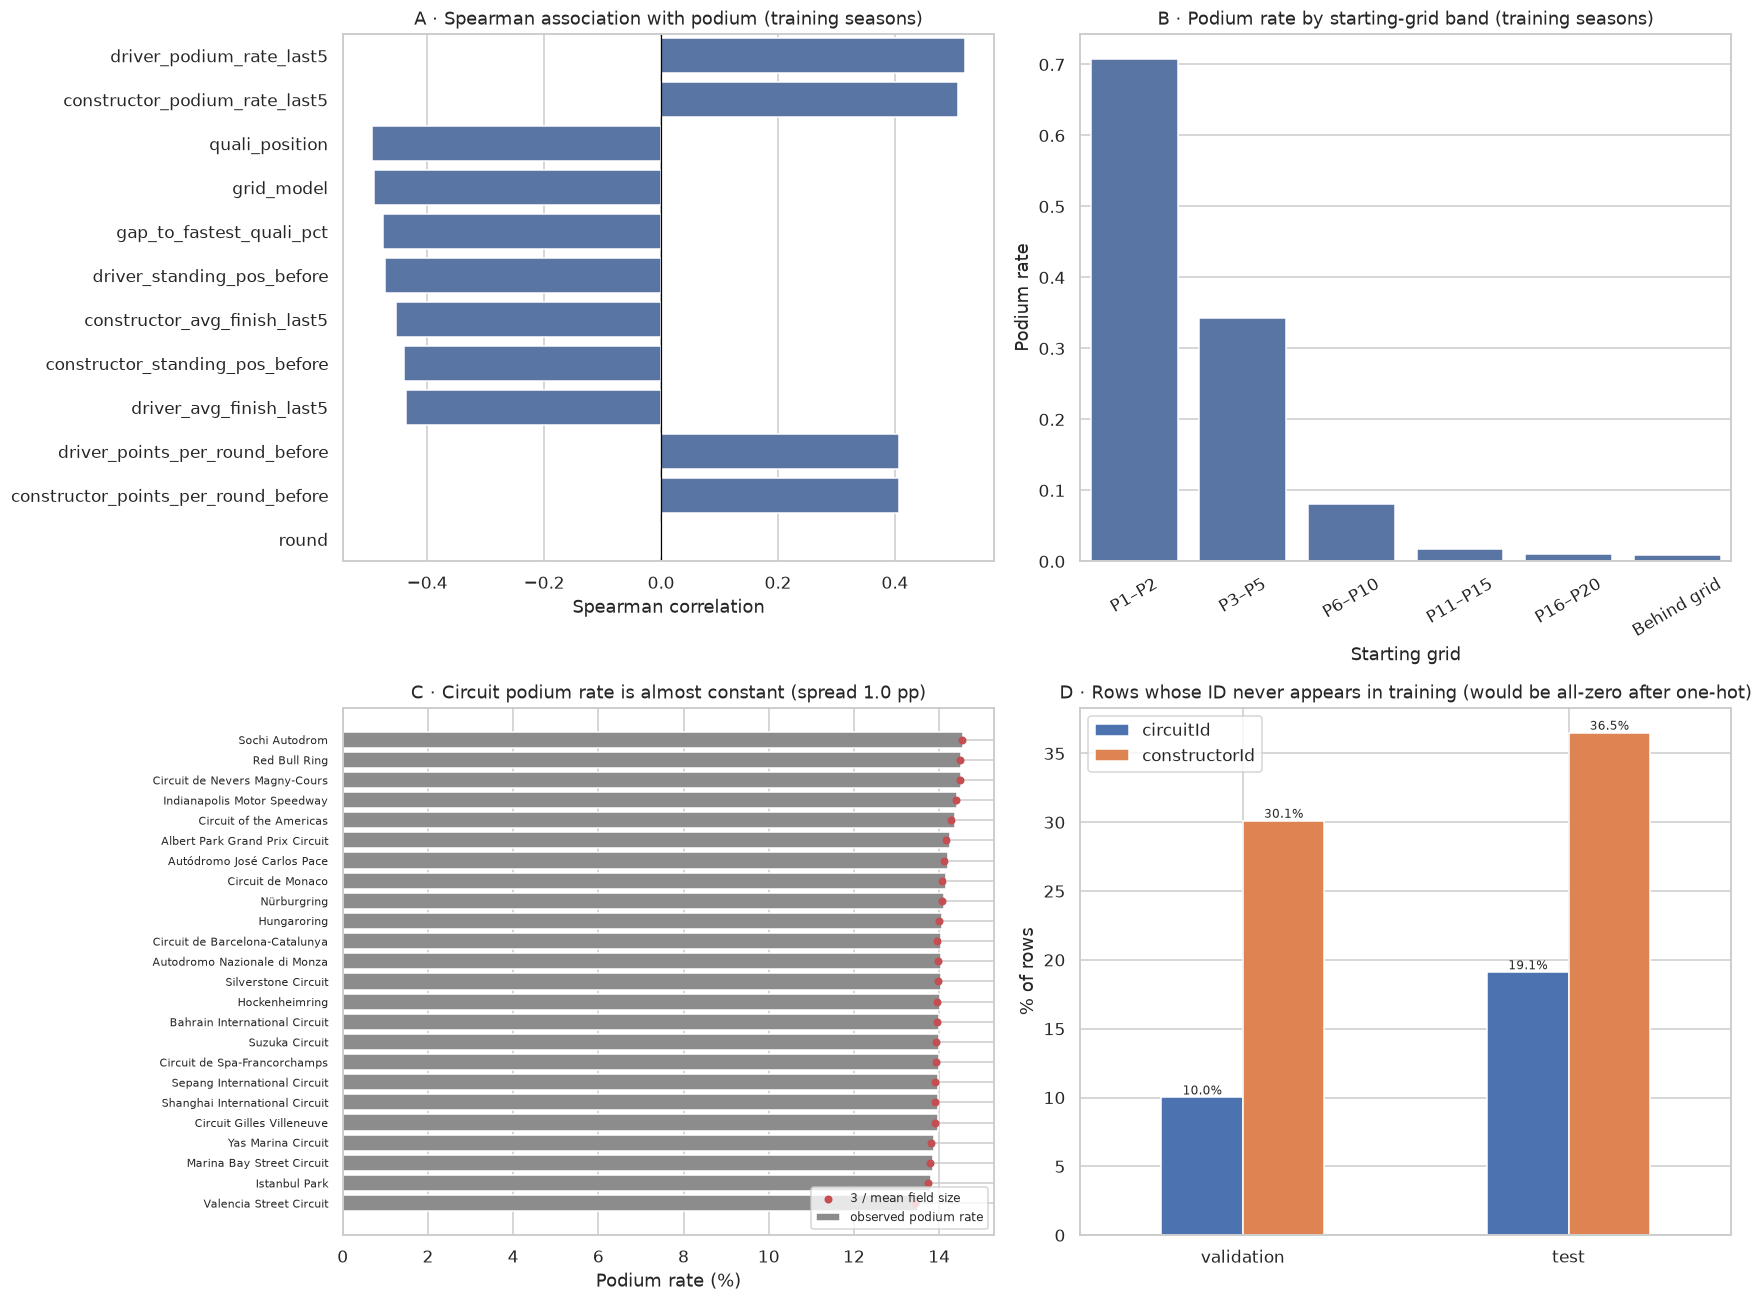

,grid_band,starts,podium_rate
0,P1–P2,599,0.707846
1,P3–P5,900,0.343333
2,P6–P10,1499,0.081388
3,P11–P15,1498,0.017356
4,P16–P20,1486,0.010094
5,Behind grid,419,0.009547


Circuit podium-rate spread across circuits with >= 100 training starts: 1.0 pp; correlation with 3/field size: 1.00


,validation (% rows unseen in train),test (% rows unseen in train)
circuitId,10.0,19.1
constructorId,30.1,36.5


Constructor IDs in validation/test never seen in training: ['Alfa Romeo', 'Racing Point', 'AlphaTauri', 'Alpine F1 Team', 'Aston Martin', 'RB F1 Team']


In [48]:
# -----------------------------
# 9.5 — Exploratory evidence for feature selection (TRAINING SEASONS ONLY)
# -----------------------------

# Chronological split boundaries, defined once here and reused in 9.7.
TRAIN_YEARS = (2003, 2018)
VAL_YEARS = (2019, 2021)
TEST_YEARS = (2022, 2024)

evidence_df = feature_base[feature_base["year"].between(*TRAIN_YEARS)].copy()
print(f"Evidence rows (training seasons {TRAIN_YEARS[0]}–{TRAIN_YEARS[1]} only): {len(evidence_df):,}")

# A) Spearman correlation: simple monotonic association with podium.
# Negative is expected for position features because a smaller position is better.
evidence_numeric = [
    "grid_model",
    "quali_position",
    "gap_to_fastest_quali_pct",
    "driver_points_per_round_before",
    "driver_standing_pos_before",
    "driver_avg_finish_last5",
    "driver_podium_rate_last5",
    "constructor_points_per_round_before",
    "constructor_standing_pos_before",
    "constructor_avg_finish_last5",
    "constructor_podium_rate_last5",
    "round",
]

corr_to_podium = (
    evidence_df[evidence_numeric + ["podium"]]
    .astype(float)
    .corr(method="spearman")["podium"]
    .drop("podium")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
display(corr_to_podium.rename("spearman_with_podium (train)").to_frame())

# C) Circuit podium rates on training seasons (circuits with >= 100 training starts).
circuit_rates = (
    evidence_df.groupby("circuitId", observed=True)
    .agg(starts=("podium", "size"), podium_rate=("podium", "mean"), mean_field=("field_size", "mean"))
    .reset_index()
    .merge(clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit_name"}),
           on="circuitId", how="left", validate="one_to_one")
)
circuit_rates["expected_3_over_field"] = 3 / circuit_rates["mean_field"]
circuit_plot = circuit_rates[circuit_rates["starts"] >= 100].sort_values("podium_rate")
circuit_spread_pp = (circuit_plot["podium_rate"].max() - circuit_plot["podium_rate"].min()) * 100
circuit_vs_field_corr = circuit_plot["podium_rate"].corr(circuit_plot["expected_3_over_field"])

# D) Category stability: share of validation/test rows whose ID never appears in training.
train_ids = {c: set(evidence_df[c]) for c in ["circuitId", "constructorId"]}
unseen_share = pd.DataFrame({
    split: {c: (~part[c].isin(train_ids[c])).mean() for c in ["circuitId", "constructorId"]}
    for split, part in [
        ("validation", feature_base[feature_base["year"].between(*VAL_YEARS)]),
        ("test", feature_base[feature_base["year"].between(*TEST_YEARS)]),
    ]
})
unseen_constructors = (
    feature_base[feature_base["year"].between(VAL_YEARS[0], TEST_YEARS[1]) &
                 ~feature_base["constructorId"].isin(train_ids["constructorId"])]
    .merge(clean["constructors"][["constructorId", "name"]], on="constructorId", how="left")["name"]
    .drop_duplicates().tolist()
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.barplot(x=corr_to_podium.values, y=corr_to_podium.index, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].axvline(0, color="black", linewidth=0.8)
axes[0, 0].set_title("A · Spearman association with podium (training seasons)")
axes[0, 0].set_xlabel("Spearman correlation")
axes[0, 0].set_ylabel("")

# B) Starting grid relationship.
grid_plot = evidence_df.copy()
grid_plot["grid_band"] = pd.cut(
    grid_plot["grid_model"], bins=[0, 2, 5, 10, 15, 20, np.inf],
    labels=["P1–P2", "P3–P5", "P6–P10", "P11–P15", "P16–P20", "Behind grid"], include_lowest=True
)
grid_rates = (
    grid_plot.groupby("grid_band", observed=True)["podium"]
    .agg(starts="size", podium_rate="mean").reset_index()
)
sns.barplot(data=grid_rates, x="grid_band", y="podium_rate", ax=axes[0, 1], color="#4C72B0")
axes[0, 1].set_title("B · Podium rate by starting-grid band (training seasons)")
axes[0, 1].set_xlabel("Starting grid")
axes[0, 1].set_ylabel("Podium rate")
axes[0, 1].tick_params(axis="x", rotation=30)

axes[1, 0].barh(circuit_plot["circuit_name"], circuit_plot["podium_rate"] * 100, color="#8C8C8C",
                label="observed podium rate")
axes[1, 0].scatter(circuit_plot["expected_3_over_field"] * 100, circuit_plot["circuit_name"],
                   color="#C44E52", zorder=3, s=18, label="3 / mean field size")
axes[1, 0].set_title(f"C · Circuit podium rate is almost constant (spread {circuit_spread_pp:.1f} pp)")
axes[1, 0].set_xlabel("Podium rate (%)")
axes[1, 0].tick_params(axis="y", labelsize=7)
axes[1, 0].legend(loc="lower right", fontsize=8)

unseen_share.mul(100).T.plot(kind="bar", ax=axes[1, 1], color=["#4C72B0", "#DD8452"])
axes[1, 1].set_title("D · Rows whose ID never appears in training (would be all-zero after one-hot)")
axes[1, 1].set_ylabel("% of rows")
axes[1, 1].tick_params(axis="x", rotation=0)
for cont in axes[1, 1].containers:
    axes[1, 1].bar_label(cont, fmt="%.1f%%", fontsize=8)

plt.tight_layout()
plt.show()

display(grid_rates)
print(f"Circuit podium-rate spread across circuits with >= 100 training starts: {circuit_spread_pp:.1f} pp; "
      f"correlation with 3/field size: {circuit_vs_field_corr:.2f}")
display((unseen_share * 100).round(1).add_suffix(" (% rows unseen in train)"))
print("Constructor IDs in validation/test never seen in training:", unseen_constructors)

## 9.5.1 · Feature-selection evidence summary

The table below links every kept or dropped feature group to the evidence behind the decision. The numbers quoted in it are computed in 9.5 on the training seasons only, so the table updates automatically after a re-run.

In [49]:
def rho(name):
    return f"{corr_to_podium[name]:+.2f}"

feature_evidence = pd.DataFrame([
    ["grid_model", "KEEP",
     "9.5-A Spearman + 9.5-B grid-band plot",
     f"Strongest single signal (ρ = {rho('grid_model')}); podium rate drops from "
     f"{grid_rates['podium_rate'].iloc[0]:.0%} (P1–P2) to {grid_rates['podium_rate'].iloc[-1]:.1%} (behind the grid)."],

    ["pit_lane_start", "KEEP",
     "Phase 1 grid=0 analysis",
     "A pit-lane start is a distinct pre-race situation and must not be encoded as grid position 0."],

    ["quali_position", "KEEP",
     "9.5-A Spearman",
     f"Strong association (ρ = {rho('quali_position')}); differs from the grid when penalties apply (Phase 2 Q1)."],

    ["gap_to_fastest_quali_pct", "KEEP",
     "9.5-A Spearman + qualifying EDA",
     f"Relative qualifying pace (ρ = {rho('gap_to_fastest_quali_pct')}) is comparable across circuits, unlike raw seconds."],

    ["quali_missing", "KEEP",
     "Phase 1 qualifying-missingness EDA",
     "Qualifying missingness is structured rather than random, so the flag itself can carry information."],

    ["driver standings", "KEEP",
     "9.5-A Spearman",
     f"Previous-race standing position (ρ = {rho('driver_standing_pos_before')}) and points per completed round "
     f"(ρ = {rho('driver_points_per_round_before')})."],

    ["constructor standings", "KEEP",
     "9.5-A Spearman",
     f"Previous constructor strength: position ρ = {rho('constructor_standing_pos_before')}, "
     f"points per round ρ = {rho('constructor_points_per_round_before')}."],

    ["driver last-5 form", "KEEP",
     "9.5-A Spearman",
     f"Podium rate in last 5 starts ρ = {rho('driver_podium_rate_last5')}; average finish ρ = {rho('driver_avg_finish_last5')}."],

    ["constructor last-5 form", "KEEP",
     "9.5-A Spearman",
     f"Team podium rate in last 5 races ρ = {rho('constructor_podium_rate_last5')}; average finish ρ = {rho('constructor_avg_finish_last5')}."],

    ["round", "DROP",
     "9.5-A Spearman",
     f"No association with podium (ρ = {rho('round')}). Season progress is already used to normalise standings points per completed round."],

    ["circuitId", "DROP",
     "9.5-C circuit plot + 9.5-D unseen-category check + Phase 2 Q1",
     f"Circuit podium rate is structurally flat (spread {circuit_spread_pp:.1f} pp; it tracks 3 / field size). "
     f"{unseen_share.loc['circuitId', 'test']:.0%} of test rows are at circuits never seen in training. "
     "Circuit differences in front-row conversion (Q1) are within their confidence intervals."],

    ["constructorId", "DROP",
     "9.5-D unseen-category check + 9.5-A Spearman",
     f"{unseen_share.loc['constructorId', 'test']:.0%} of test rows and {unseen_share.loc['constructorId', 'validation']:.0%} "
     "of validation rows belong to constructor IDs never seen in training (renamed teams), which one-hot encoding would "
     "silently treat as a baseline team. Team strength is carried by constructor standings and last-5 form instead."],

    ["driverId", "DROP",
     "Design hypothesis",
     "Avoids direct memorisation of individual drivers; driver strength is represented by standings and recent form."],

    ["raw q1/q2/q3 times", "DROP / ENGINEER",
     "Phase 1 missingness EDA",
     "Raw session times are structurally missing (knockout format) and depend on circuit length; replaced by qualifying position and relative pace."],

    ["is_home", "DROP",
     "Phase 2 Q2 (grid-controlled, bootstrap CI)",
     f"After controlling for grid, the home effect is {q2_adjusted_diff_pp:+.2f} pp with a 95% CI of "
     f"{q2_ci_low:+.2f} to {q2_ci_high:+.2f} pp, so there is no detectable signal to add."],
], columns=["feature_or_group", "decision", "evidence", "reason"])

display(feature_evidence)

,feature_or_group,decision,evidence,reason
0,grid_model,KEEP,9.5-A Spearman + 9.5-B grid-band plot,Strongest single signal (ρ = -0.49); podium rate drops f...
1,pit_lane_start,KEEP,Phase 1 grid=0 analysis,A pit-lane start is a distinct pre-race situation and mu...
2,quali_position,KEEP,9.5-A Spearman,Strong association (ρ = -0.49); differs from the grid wh...
3,gap_to_fastest_quali_pct,KEEP,9.5-A Spearman + qualifying EDA,Relative qualifying pace (ρ = -0.48) is comparable acros...
4,quali_missing,KEEP,Phase 1 qualifying-missingness EDA,"Qualifying missingness is structured rather than random,..."
5,driver standings,KEEP,9.5-A Spearman,Previous-race standing position (ρ = -0.47) and points p...
6,constructor standings,KEEP,9.5-A Spearman,"Previous constructor strength: position ρ = -0.44, point..."
7,driver last-5 form,KEEP,9.5-A Spearman,Podium rate in last 5 starts ρ = +0.52; average finish ρ...
8,constructor last-5 form,KEEP,9.5-A Spearman,Team podium rate in last 5 races ρ = +0.51; average fini...
9,round,DROP,9.5-A Spearman,No association with podium (ρ = -0.00). Season progress ...


## 9.6 · Final feature list and leakage audit

The final set keeps only features that are available at the prediction cutoff or are explicitly built from past races.

Important exclusions (evidence in 9.5 / 9.5.1):
- **Same-race outcomes** (finishing position, points, laps, status, fastest lap, …) → direct leakage, blocked by an assertion below.
- **Raw `q1/q2/q3` seconds** → format-dependent and structurally missing; replaced by qualifying position and relative qualifying gap.
- **`driverId`** → memorisation risk; driver form and standings are more transferable.
- **`constructorId`** → renamed teams become unseen categories in validation/test; team strength is carried by constructor standings and form.
- **`circuitId`** → podium rate is structurally flat across circuits, and many test circuits are new.
- **`round`** → no association with podium.
- **Home-race flag** → no detectable effect after controlling for grid (Phase 2 Q2).

`constructorId` and `circuitId` stay in the table as **metadata** (for later error analysis and XAI), but they are not model inputs.

In [50]:
# -----------------------------
# 9.6 — Final selected feature set + explicit leakage audit
# -----------------------------

NUMERIC_FEATURES = [
    "grid_model",
    "quali_position",
    "gap_to_fastest_quali_pct",
    "driver_points_per_round_before",
    "driver_standing_pos_before",
    "constructor_points_per_round_before",
    "constructor_standing_pos_before",
    "driver_avg_finish_last5",
    "driver_podium_rate_last5",
    "constructor_avg_finish_last5",
    "constructor_podium_rate_last5",
]

BINARY_FEATURES = [
    "pit_lane_start",
    "quali_missing",
    "driver_standing_missing",
    "constructor_standing_missing",
    "driver_no_history",
    "constructor_no_history",
]

# No categorical model inputs: circuitId / constructorId / driverId were dropped with evidence (9.5.1).
CATEGORICAL_FEATURES = []

FEATURE_COLUMNS = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES
TARGET = "podium"
METADATA_COLUMNS = ["raceId", "driverId", "constructorId", "circuitId", "year"]   # kept for analysis, NOT inputs

# Named groups so the later ablation experiment can remove one group at a time.
FEATURE_GROUPS = {
    "grid": ["grid_model", "pit_lane_start"],
    "qualifying": ["quali_position", "gap_to_fastest_quali_pct", "quali_missing"],
    "standings": [
        "driver_points_per_round_before", "driver_standing_pos_before",
        "constructor_points_per_round_before", "constructor_standing_pos_before",
        "driver_standing_missing", "constructor_standing_missing",
    ],
    "form": [
        "driver_avg_finish_last5", "driver_podium_rate_last5",
        "constructor_avg_finish_last5", "constructor_podium_rate_last5",
        "driver_no_history", "constructor_no_history",
    ],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(FEATURE_COLUMNS), \
    "Every feature must belong to exactly one ablation group."

modeling_table = feature_base[METADATA_COLUMNS + [TARGET] + FEATURE_COLUMNS].copy()

# Convert types to sklearn-friendly values without fitting any preprocessing yet.
for c in NUMERIC_FEATURES:
    modeling_table[c] = pd.to_numeric(modeling_table[c], errors="coerce").astype(float)
for c in BINARY_FEATURES:
    modeling_table[c] = modeling_table[c].astype("int8")
for c in ["constructorId", "circuitId"]:
    modeling_table[c] = modeling_table[c].astype("string")

# Direct same-race outcome columns that must NEVER be model features.
FORBIDDEN_SAME_RACE = {
    "position", "positionText", "positionOrder", "result_code", "points", "laps",
    "time", "milliseconds", "race_time_s", "fastestLap", "rank",
    "fastestLapTime", "fastestLapTime_s", "fastestLapSpeed", "statusId",
    "credited_best_positionOrder", "credited_points", "n_car_entries", "shared_drive",
}
assert not (set(FEATURE_COLUMNS) & FORBIDDEN_SAME_RACE), \
    f"Leakage detected: {set(FEATURE_COLUMNS) & FORBIDDEN_SAME_RACE}"
# Identity / metadata columns must not be inputs either.
assert not (set(FEATURE_COLUMNS) & set(METADATA_COLUMNS)), "Metadata column used as a feature."
# Cross-check against the Phase 1 leakage catalog: no post-race or target column may be a feature.
catalog_forbidden = set(leakage_catalog.query("role in ['post_race', 'target']")["column"])
assert not (set(FEATURE_COLUMNS) & catalog_forbidden), "Feature found in the Phase 1 leakage catalog."
assert not modeling_table.duplicated(["raceId", "driverId"]).any()

feature_manifest = pd.DataFrame([
    ["grid_model", "current race", "numeric (impute + scale)", "KEEP",
     "Actual start position known before lights out; pit-lane encoded behind the grid."],
    ["pit_lane_start", "current race", "binary", "KEEP",
     "Pit-lane start is known before the start."],
    ["quali_position", "current qualifying", "numeric (impute + scale)", "KEEP",
     "Qualifying is complete before the prediction cutoff."],
    ["gap_to_fastest_quali_pct", "current qualifying", "numeric (impute + scale)", "KEEP",
     "Relative pace is more comparable across circuits than raw qualifying seconds."],
    ["quali_missing", "current qualifying", "binary", "KEEP",
     "Explicit flag for a missing qualifying row."],
    ["driver standings", "previous standings", "numeric (impute + scale) + missing flag", "KEEP",
     "shift(1) uses only the previous standings row; points are normalised by completed rounds."],
    ["constructor standings", "previous standings", "numeric (impute + scale) + missing flag", "KEEP",
     "shift(1) avoids same-race standings leakage and captures current-season team strength."],
    ["driver last-5 form", "past races", "numeric (impute + scale) + no-history flag", "KEEP",
     "Recent driver form; the current result is excluded by shifting before rolling."],
    ["constructor last-5 form", "past races", "numeric (impute + scale) + no-history flag", "KEEP",
     "Recent team form; aggregated per constructor-race, then shifted."],
    ["round", "calendar", "—", "DROP", "No association with podium in training seasons."],
    ["circuitId", "calendar", "metadata only", "DROP",
     "Flat circuit podium rate; many unseen circuits in validation/test."],
    ["constructorId", "entry list", "metadata only", "DROP",
     "Renamed teams are unseen categories; team strength is carried by standings and form."],
    ["driverId", "identity", "metadata only", "DROP",
     "Avoid memorising drivers; use form and standings instead."],
    ["raw q1_s/q2_s/q3_s", "qualifying", "—", "DROP / ENGINEER",
     "Circuit-dependent and structurally missing; replaced by position + relative gap."],
    ["is_home", "driver/circuit country", "—", "DROP",
     "No detectable effect after controlling for grid (Phase 2 Q2)."],
    ["same-race results/points/laps/status", "race outcome", "forbidden", "DROP",
     "Known only after the race; direct target leakage."],
], columns=["feature_or_group", "source", "encoding", "decision", "reason"])

display(feature_manifest)
print("Final model-input feature count:", len(FEATURE_COLUMNS),
      f"({len(NUMERIC_FEATURES)} numeric + {len(BINARY_FEATURES)} binary)")
print("Final modeling rows:", f"{len(modeling_table):,}")

,feature_or_group,source,encoding,decision,reason
0,grid_model,current race,numeric (impute + scale),KEEP,Actual start position known before lights out; pit-lane ...
1,pit_lane_start,current race,binary,KEEP,Pit-lane start is known before the start.
2,quali_position,current qualifying,numeric (impute + scale),KEEP,Qualifying is complete before the prediction cutoff.
3,gap_to_fastest_quali_pct,current qualifying,numeric (impute + scale),KEEP,Relative pace is more comparable across circuits than ra...
4,quali_missing,current qualifying,binary,KEEP,Explicit flag for a missing qualifying row.
5,driver standings,previous standings,numeric (impute + scale) + missing flag,KEEP,shift(1) uses only the previous standings row; points ar...
6,constructor standings,previous standings,numeric (impute + scale) + missing flag,KEEP,shift(1) avoids same-race standings leakage and captures...
7,driver last-5 form,past races,numeric (impute + scale) + no-history flag,KEEP,Recent driver form; the current result is excluded by sh...
8,constructor last-5 form,past races,numeric (impute + scale) + no-history flag,KEEP,"Recent team form; aggregated per constructor-race, then ..."
9,round,calendar,—,DROP,No association with podium in training seasons.


Final model-input feature count: 17 (11 numeric + 6 binary)
Final modeling rows: 8,956


## 9.7 · Chronological Train / Validation / Test split

We use:
- **Training:** 2003–2018
- **Validation:** 2019–2021
- **Test:** 2022–2024

The year boundaries are the same `TRAIN_YEARS / VAL_YEARS / TEST_YEARS` constants used for the training-only evidence in 9.5.

**Why not a random split?** It would mix future seasons into training. A chronological split matches real deployment:
- learn from older races;
- choose thresholds and hyperparameters on the later validation seasons;
- report final performance once, on the newest unseen test seasons.

The test seasons coincide with the 2022 regulation change, so the test score also measures how well the model generalises to a new technical era.

,rows,races,first_year,last_year,podiums,podium_rate
split,,,,,,
train,6401,300,2003,2018,900,0.140603
validation,1199,60,2019,2021,180,0.150125
test,1356,68,2022,2024,204,0.150442


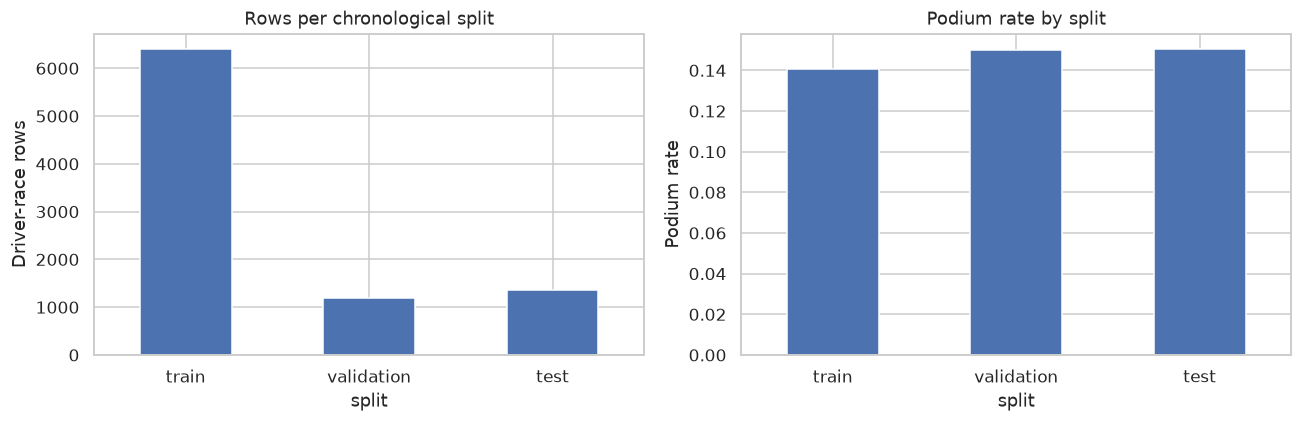

Shapes: (6401, 17) (1199, 17) (1356, 17)


In [51]:
# -----------------------------
# 9.7 — Chronological Train / Validation / Test split
# -----------------------------

# No random shuffling: the model trains on the past and predicts future seasons.
split_df = modeling_table.copy()
split_df["split"] = np.select(
    [
        split_df["year"].between(*TRAIN_YEARS),
        split_df["year"].between(*VAL_YEARS),
        split_df["year"].between(*TEST_YEARS),
    ],
    ["train", "validation", "test"],
    default="outside"
)

assert not (split_df["split"] == "outside").any()
assert split_df.loc[split_df["split"] == "train", "year"].max() < \
       split_df.loc[split_df["split"] == "validation", "year"].min()
assert split_df.loc[split_df["split"] == "validation", "year"].max() < \
       split_df.loc[split_df["split"] == "test", "year"].min()
# A race must never be split across two sets.
assert split_df.groupby("raceId")["split"].nunique().max() == 1

split_summary = (
    split_df.groupby("split", observed=True)
    .agg(
        rows=("podium", "size"),
        races=("raceId", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        podiums=("podium", "sum"),
        podium_rate=("podium", "mean"),
    )
    .reindex(["train", "validation", "test"])
)
display(split_summary)

train_df = split_df.loc[split_df["split"] == "train"].copy()
val_df   = split_df.loc[split_df["split"] == "validation"].copy()
test_df  = split_df.loc[split_df["split"] == "test"].copy()

X_train, y_train = train_df[FEATURE_COLUMNS].copy(), train_df[TARGET].copy()
X_val,   y_val   = val_df[FEATURE_COLUMNS].copy(),   val_df[TARGET].copy()
X_test,  y_test  = test_df[FEATURE_COLUMNS].copy(),  test_df[TARGET].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_summary["rows"].plot(kind="bar", ax=axes[0], title="Rows per chronological split")
axes[0].set_ylabel("Driver-race rows")
axes[0].tick_params(axis="x", rotation=0)

split_summary["podium_rate"].plot(kind="bar", ax=axes[1], title="Podium rate by split")
axes[1].set_ylabel("Podium rate")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Shapes:", X_train.shape, X_val.shape, X_test.shape)

## 9.8 · Encoding and preprocessing plan, and its effect on the data

**Plan (used inside every model pipeline):**
- **Numeric features** → median imputation, then standardization (mean 0, standard deviation 1).
  - *Why the median:* several features are skewed (e.g. qualifying gap, points per round), and the median is robust to outliers.
  - *Why scaling:* logistic regression and the neural network are sensitive to feature scale; tree models ignore it.
- **Binary flags** → passed through unchanged (already 0/1). They also tell the model which values were imputed.
- **Categorical features** → none. The categorical candidates were dropped with evidence in 9.5.1, so no one-hot encoding is needed.

**The defined `preprocessor` is never fitted on all data.** Modelling code must put it inside each sklearn `Pipeline` and fit that pipeline on `X_train` only.

**Effect on the data (checklist item).** To show what the step does to distributions, ranges and missing values, the cell below fits a **separate copy** (`clone`) of the preprocessor on the training split only and compares before and after. Validation is transformed with the **training** statistics, so its mean is not exactly 0. That difference is exactly what a leakage-free transform should look like.

In the right-hand AFTER plot, the spike at 0 is the rows that were imputed with the training median. The matching `driver_standing_missing` flag lets the model tell those rows apart from genuine mid-table drivers.

,missing_before (train),median_used_to_impute,mean_before,std_before,min_before,max_before,missing_after (train),mean_after (train),std_after (train),mean_after (validation)
grid_model,0,11.000,11.236,6.261,1.0,24.000,0,0.0,1.0,-0.108
quali_position,19,11.000,11.204,6.240,1.0,24.000,0,-0.0,1.0,-0.117
gap_to_fastest_quali_pct,113,1.799,2.399,2.658,0.0,37.797,0,0.0,1.0,-0.130
driver_points_per_round_before,0,1.231,3.323,4.722,0.0,25.000,0,-0.0,1.0,0.309
driver_standing_pos_before,468,11.000,11.332,6.496,1.0,27.000,0,-0.0,1.0,-0.110
constructor_points_per_round_before,0,2.800,6.684,8.940,0.0,43.000,0,0.0,1.0,0.328
constructor_standing_pos_before,368,6.000,5.855,3.122,1.0,12.000,0,-0.0,1.0,-0.112
driver_avg_finish_last5,72,11.500,11.166,4.527,1.0,24.000,0,0.0,1.0,-0.154
driver_podium_rate_last5,72,0.000,0.142,0.252,0.0,1.000,0,0.0,1.0,0.038
constructor_avg_finish_last5,33,11.500,11.196,4.226,1.5,21.500,0,-0.0,1.0,-0.152


Columns before: 17  →  after preprocessing: 17
Binary flags are unchanged: True


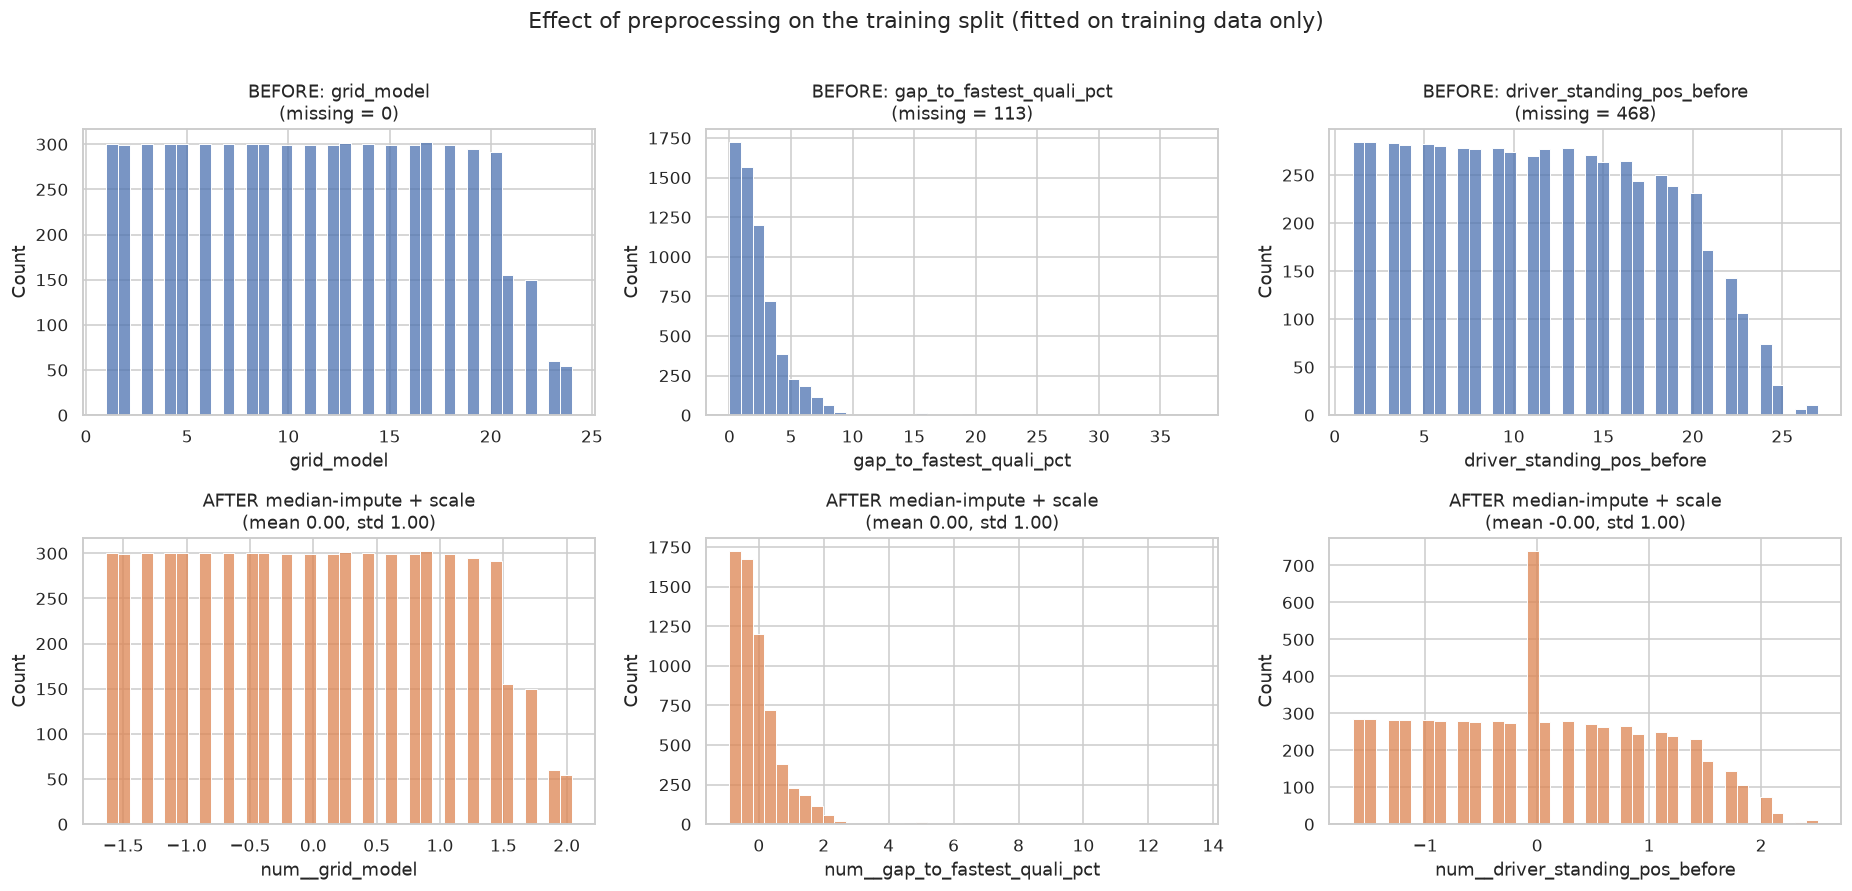

Preprocessor defined (unfitted) for the modelling pipelines.
Numeric: 11 | Binary: 6 | Categorical: 0


In [52]:
# -----------------------------
# 9.8 — Encoding / preprocessing plan + demonstration of its effect
# -----------------------------

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

transformers = [
    ("num", numeric_pipe, NUMERIC_FEATURES),
    ("bin", "passthrough", BINARY_FEATURES),
]
if CATEGORICAL_FEATURES:   # kept generic in case a categorical feature is added back later
    transformers.append(("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CATEGORICAL_FEATURES))

preprocessor = ColumnTransformer(transformers)
# IMPORTANT: `preprocessor` itself stays UNFITTED. It must be fitted inside each model pipeline on X_train only.
# Fitting the imputer/scaler on all data would let validation/test statistics leak into training.

# ---- Demonstration on a separate copy, fitted on TRAINING data only ----
demo = clone(preprocessor).fit(X_train)
out_cols = demo.get_feature_names_out()
Xt_train = pd.DataFrame(demo.transform(X_train), columns=out_cols, index=X_train.index)
Xt_val = pd.DataFrame(demo.transform(X_val), columns=out_cols, index=X_val.index)
num_out = [f"num__{c}" for c in NUMERIC_FEATURES]

preprocessing_effect = pd.DataFrame({
    "missing_before (train)": X_train[NUMERIC_FEATURES].isna().sum().values,
    "median_used_to_impute": demo.named_transformers_["num"].named_steps["imputer"].statistics_,
    "mean_before": X_train[NUMERIC_FEATURES].mean().values,
    "std_before": X_train[NUMERIC_FEATURES].std(ddof=0).values,
    "min_before": X_train[NUMERIC_FEATURES].min().values,
    "max_before": X_train[NUMERIC_FEATURES].max().values,
    "missing_after (train)": Xt_train[num_out].isna().sum().values,
    "mean_after (train)": Xt_train[num_out].mean().values,
    "std_after (train)": Xt_train[num_out].std(ddof=0).values,
    "mean_after (validation)": Xt_val[num_out].mean().values,
}, index=NUMERIC_FEATURES)
display(preprocessing_effect.round(3))

assert Xt_train.isna().sum().sum() == 0 and Xt_val.isna().sum().sum() == 0, "Imputation left missing values."
assert np.allclose(Xt_train[num_out].mean(), 0, atol=1e-9), "Scaled training features should have mean 0."
print(f"Columns before: {X_train.shape[1]}  →  after preprocessing: {Xt_train.shape[1]}")
print("Binary flags are unchanged:",
      bool((Xt_train[[f'bin__{c}' for c in BINARY_FEATURES]].values == X_train[BINARY_FEATURES].values).all()))

# Before/after distributions for three representative features.
show_feats = ["grid_model", "gap_to_fastest_quali_pct", "driver_standing_pos_before"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, f in enumerate(show_feats):
    sns.histplot(X_train[f].dropna(), bins=40, ax=axes[0, j], color="#4C72B0")
    axes[0, j].set_title(f"BEFORE: {f}\n(missing = {int(X_train[f].isna().sum())})")
    sns.histplot(Xt_train[f"num__{f}"], bins=40, ax=axes[1, j], color="#DD8452")
    axes[1, j].set_title(f"AFTER median-impute + scale\n(mean {Xt_train[f'num__{f}'].mean():.2f}, std {Xt_train[f'num__{f}'].std(ddof=0):.2f})")
plt.suptitle("Effect of preprocessing on the training split (fitted on training data only)", y=1.01)
plt.tight_layout()
plt.show()

print("Preprocessor defined (unfitted) for the modelling pipelines.")
print("Numeric:", len(NUMERIC_FEATURES), "| Binary:", len(BINARY_FEATURES),
      "| Categorical:", len(CATEGORICAL_FEATURES))


## 9.9 · Save outputs for the modelling section

The final modelling table includes the split assignment so every later model uses exactly the same rows and feature definitions.


In [53]:
# -----------------------------
# 9.9 — Save the feature-engineering outputs for the modelling section
# -----------------------------

modeling_table_with_split = split_df.copy()

modeling_table_with_split.to_parquet(OUT_DIR / "modeling_table_feature_engineered.parquet", index=False)
feature_manifest.to_csv(OUT_DIR / "feature_manifest.csv", index=False)
feature_evidence.to_csv(OUT_DIR / "feature_evidence.csv", index=False)
split_summary.to_csv(OUT_DIR / "split_summary.csv")
preprocessing_effect.to_csv(OUT_DIR / "preprocessing_effect.csv")

print("✅ Saved:")
for f in ["modeling_table_feature_engineered.parquet", "feature_manifest.csv", "feature_evidence.csv",
          "split_summary.csv", "preprocessing_effect.csv"]:
    print(" -", OUT_DIR / f)
print("✅ Existing Phase 1/2 code and tables were not modified.")

✅ Saved:
 - clean/modeling_table_feature_engineered.parquet
 - clean/feature_manifest.csv
 - clean/feature_evidence.csv
 - clean/split_summary.csv
 - clean/preprocessing_effect.csv
✅ Existing Phase 1/2 code and tables were not modified.


## ✅ Phase 3 summary

- One row is still one `(raceId, driverId)` prediction, for 2003–2024 starters.
- Current grid and qualifying features are available before the race; pit-lane starts are encoded behind the grid.
- Standings are lagged by one race (`shift(1)`); recent driver and team form is shifted before rolling.
- Post-race columns are blocked from the feature list by assertions, which also cross-check the Phase 1 leakage catalog.
- Every kept and dropped feature has evidence, computed on **training seasons only** (9.5 / 9.5.1). `circuitId`, `constructorId`, `driverId`, `round` and `is_home` were dropped for documented reasons.
- Train / validation / test are chronological (2003–2018 / 2019–2021 / 2022–2024), and no race is split across sets.
- Preprocessing is defined but fitted only inside model pipelines on the training split. Its effect on distributions, ranges and missing values is demonstrated in 9.8.

**Still to do in the modelling / experiments section (not part of this phase):**
- feature-group ablation, using `FEATURE_GROUPS`;
- at least two preprocessing-order experiments, e.g. impute/scale before vs after splitting.

# 🏁 Phase 4: Predictive Modeling

**Task (PDF §4).** Binary classification: will this driver finish on the **podium** (top 3) in this race?

* The prediction is made after qualifying and before the start.
* Every model uses the **same rows and the same 17 features** from Phase 3, so the scores are directly comparable.

### The choices we made, and why

| Decision | Choice | Why |
|---|---|---|
| Metrics | ROC-AUC, PR-AUC, F1, **Precision, Recall** | §4 lists ROC-AUC, PR-AUC and F1. Deliverable 4 asks for "five", so we also report the two components of F1. Accuracy is excluded: always predicting "no podium" already scores ≈ 85%. |
| **Primary metric** | **PR-AUC** (average precision) | Podiums are rare (≈ 15%). PR-AUC measures how well real podium finishers are ranked at the top and ignores the thousands of easy negatives that inflate ROC-AUC. It is also threshold-free, so it is a fair way to compare models. |
| **Secondary metric** | **F1 at the validation-chosen threshold** | A real system must eventually say yes or no. F1 balances false alarms against missed podiums. |
| Baselines | (1) rule **grid ≤ 3**; (2) **grid-only logistic regression** | Grid is the strongest single signal (Phase 2 Q1, §9.5). Our models must beat "the front of the grid finishes at the front". |
| Statistical models | **Logistic Regression** (linear or spline basis), **Gradient Boosting** (`HistGradientBoostingClassifier`), **Random Forest** | Three families with different strengths: linear and interpretable; boosted trees, the strongest family on tables; bagged trees, robust with low variance. |
| Neural network | **Keras MLP, 2 hidden layers**, ReLU, dropout, L2; **average of 5 seeds** | Meets the "shallow NN" requirement. A single small network is noisy on 6k rows, and averaging seeds stabilises it. |
| Ensemble | **Soft-voting average** of the four tuned models | Different model families make different mistakes, so averaging their probabilities usually ranks better than any one of them. It is a legitimate candidate and is selected like any other model. |
| Hyperparameter tuning | **Time-series cross-validation inside the training seasons** (4 expanding folds) | The validation set has only 180 podiums. Tuning large grids on it would overfit it. Expanding folds respect time (always train on the past, score on the next seasons). **The validation set is not touched while tuning.** |
| Class imbalance | **Threshold tuning**; `class_weight` tried as a hyperparameter but kept only if it improves CV PR-AUC by ≥ 0.005 | Class weights barely change *ranking* but push every probability upward (bad calibration), and the inference function shows probabilities to users. No SMOTE: synthetic rows would invent fake races and easily leak across the split. |
| Threshold | **Maximise F1 on validation**, then freeze | The PDF requires thresholds chosen on training/validation only. |
| Model selection | **Highest validation PR-AUC** | The validation seasons were never used for tuning, so they are a fair referee. |
| Test set | Opened **once**, in §10.8 | Every decision is frozen before that cell. |

Section map:
* §10.1 setup
* §10.2 baselines
* §10.3–10.6 the models (how each works, tuning, limitations)
* §10.7 model selection and thresholds on validation
* §10.8 the one-time test evaluation
* §10.9 plots
* §10.10 race-aware top-3 rule
* §10.11 refit on train + validation (supplementary)
* §10.12 saved artifacts and the written answer

## 10.1 · Setup: inputs, seeds, metric helpers, time-series folds

* **Inputs:** `X_train / X_val / X_test` and the unfitted `preprocessor` from Phase 3.
* **Every model is a `Pipeline(preprocessor → model)`.** Imputation medians and scaling statistics are therefore learned from the rows the model is trained on, and nowhere else.

**Time-series CV folds (training seasons only):**

| Fold | Fit on | Score on |
|---|---|---|
| 1 | 2003–2010 | 2011–2012 |
| 2 | 2003–2012 | 2013–2014 |
| 3 | 2003–2014 | 2015–2016 |
| 4 | 2003–2016 | 2017–2018 |

A hyperparameter setting is judged by its **mean PR-AUC over the four folds**, which is far more stable than a single split.

In [54]:
# -----------------------------
# 10.1 — Setup
# -----------------------------
import os, time, json, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
from itertools import product

import joblib
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import SplineTransformer
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
np.random.seed(SEED)
MODEL_DIR = OUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Same rows + same feature set for every model (PDF requirement).
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns) == FEATURE_COLUMNS
y_train_np = y_train.to_numpy().astype(int)
y_val_np = y_val.to_numpy().astype(int)
print(f"Features: {len(FEATURE_COLUMNS)} | train {X_train.shape[0]:,} rows ({y_train_np.mean():.1%} podium) | "
      f"validation {X_val.shape[0]:,} rows ({y_val_np.mean():.1%} podium) | test {X_test.shape[0]:,} rows (sealed until §10.8)")

# ---------- metric helpers ----------
def threshold_free_metrics(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}

def threshold_metrics(y, p, t):
    pred = (p >= t).astype(int)
    return {"F1": f1_score(y, pred, zero_division=0),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0)}

def best_f1_threshold(y, p):
    """Threshold that maximises F1 (scanning every distinct predicted probability)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i])

# ---------- preprocessing variants ----------
def make_preprocessor(spline=False):
    """spline=False → exactly the Phase 3 preprocessor; spline=True adds a cubic-spline basis to numeric features."""
    if not spline:
        return clone(preprocessor)
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler()),
                          ("spline", SplineTransformer(n_knots=5, degree=3, extrapolation="linear"))]),
         NUMERIC_FEATURES),
        ("bin", "passthrough", BINARY_FEATURES),
    ])

# ---------- time-series cross-validation inside the training seasons ----------
CV_FOLDS = [((2003, 2010), (2011, 2012)), ((2003, 2012), (2013, 2014)),
            ((2003, 2014), (2015, 2016)), ((2003, 2016), (2017, 2018))]
train_years = train_df["year"].to_numpy()

def ts_cv_pr_auc(make_estimator):
    """Mean / std PR-AUC over the expanding-window folds. Uses training seasons ONLY."""
    scores = []
    for (a0, a1), (b0, b1) in CV_FOLDS:
        fit_idx = (train_years >= a0) & (train_years <= a1)
        val_idx = (train_years >= b0) & (train_years <= b1)
        est = make_estimator().fit(X_train[fit_idx], y_train_np[fit_idx])
        scores.append(average_precision_score(y_train_np[val_idx], est.predict_proba(X_train[val_idx])[:, 1]))
    return float(np.mean(scores)), float(np.std(scores))

def run_grid(name, grid, make_estimator):
    """Evaluate every setting in `grid` with time-series CV and return a sorted results table."""
    t0, rows = time.time(), []
    for params in grid:
        mean_ap, std_ap = ts_cv_pr_auc(lambda: make_estimator(**params))
        rows.append({**params, "cv_pr_auc_mean": mean_ap, "cv_pr_auc_std": std_ap})
    res = pd.DataFrame(rows).sort_values("cv_pr_auc_mean", ascending=False).reset_index(drop=True)
    print(f"{name}: {len(grid)} settings × {len(CV_FOLDS)} folds in {time.time() - t0:.0f}s")
    return res

CLASS_WEIGHT_MIN_GAIN = 0.005

def select_best(res):
    """Best CV setting, but keep a class weight only if it beats the best unweighted setting by >= 0.005 PR-AUC.

    Class weights do not change how well a model *ranks* drivers (what PR-AUC measures); they shift every
    probability upward, which damages calibration. Imbalance is already handled by threshold tuning, so a
    weighted model must earn its place with a clear ranking gain, not a noise-level one.
    """
    best = res.iloc[0]
    if "class_weight" in res.columns and pd.notna(best["class_weight"]):
        unweighted = res[res["class_weight"].isna()]
        if len(unweighted) and best["cv_pr_auc_mean"] - unweighted.iloc[0]["cv_pr_auc_mean"] < CLASS_WEIGHT_MIN_GAIN:
            print(f"  class_weight={best['class_weight']!r} beat the best unweighted setting by only "
                  f"{best['cv_pr_auc_mean'] - unweighted.iloc[0]['cv_pr_auc_mean']:.4f} (< {CLASS_WEIGHT_MIN_GAIN}) "
                  "→ keeping the unweighted setting (better-calibrated probabilities).")
            return unweighted.iloc[0]
    return best

def as_grid(**axes):
    keys = list(axes)
    return [dict(zip(keys, vals)) for vals in product(*axes.values())]

podium_models = {}         # name -> fitted model exposing predict_proba(X)
tuning_results = {}        # name -> CV table
print("Time-series CV folds:", CV_FOLDS)

Features: 17 | train 6,401 rows (14.1% podium) | validation 1,199 rows (15.0% podium) | test 1,356 rows (sealed until §10.8)
Time-series CV folds: [((2003, 2010), (2011, 2012)), ((2003, 2012), (2013, 2014)), ((2003, 2014), (2015, 2016)), ((2003, 2016), (2017, 2018))]


## 10.2 · Baselines: what the models must beat

1. **Rule `grid ≤ 3`.** Predict a podium for the three cars at the front. It needs no training and no threshold.
   * For the threshold-free metrics, we score each driver as `1 / grid`, which ranks the grid in order.
   * The rule is then exactly `score ≥ 1/3`.
2. **Grid-only logistic regression.** The same idea expressed as a probability, learned from training seasons.

If the 17-feature models cannot clearly beat these, the feature engineering added nothing beyond the starting grid.

In [55]:
# -----------------------------
# 10.2 — Baselines
# -----------------------------
class GridRuleScorer:
    """Score = 1 / grid position, so `score >= 1/3` is exactly the rule `grid <= 3`."""
    def predict_proba(self, X):
        s = 1.0 / X["grid_model"].to_numpy(dtype=float)
        return np.column_stack([1 - s, s])

GRID_RULE_NAME = "Baseline: rule grid ≤ 3"
GRID_LR_NAME = "Baseline: grid-only logistic"
GRID_RULE_THRESHOLD = 1 / 3

grid_only_lr = Pipeline([
    ("prep", ColumnTransformer([("grid", SimpleImputer(strategy="median"), ["grid_model"])])),
    ("model", LogisticRegression(max_iter=5000)),
])
baseline_cv = ts_cv_pr_auc(lambda: clone(grid_only_lr))

podium_models[GRID_RULE_NAME] = GridRuleScorer()
podium_models[GRID_LR_NAME] = clone(grid_only_lr).fit(X_train, y_train_np)
print(f"Grid-only logistic regression — time-series CV PR-AUC: {baseline_cv[0]:.3f} ± {baseline_cv[1]:.3f}")

Grid-only logistic regression — time-series CV PR-AUC: 0.646 ± 0.059


## 10.3 · Statistical model 1: Logistic Regression

**How it works.**
1. Each feature gets a weight, and the model adds up `weight × value` for all features into a score.
2. The sigmoid function turns that score into a probability between 0 and 1.
3. Training chooses the weights that minimise log-loss, with an L2 penalty controlled by `C` (smaller `C` means simpler weights).

**Our twist: the spline basis.** Plain logistic regression assumes every feature has a straight-line effect. The real grid effect is strongly curved (§9.5: 71% → 34% → 8% → 2%).

* A `SplineTransformer` replaces each numeric feature with a few smooth basis functions.
* The model stays logistic regression (a GAM-like model) on the **same 17 features**, but it can now bend each feature's effect.
* Whether to use it (`basis = linear / spline`) is tuned like any other hyperparameter.

**Tuned:**
* `basis` ∈ {linear, spline}
* `C` ∈ {0.01, 0.03, 0.1, 0.3, 1, 3}
* `class_weight` ∈ {None, balanced}

**Why include it:** a transparent, well-calibrated reference model.

**Limitations:** no automatic interactions between features (e.g. "good grid **and** a dominant car"). Spline effects are additive, one feature at a time.

In [56]:
# -----------------------------
# 10.3 — Logistic Regression (linear or spline basis), tuned with time-series CV
# -----------------------------
def make_lr(basis, C, class_weight):
    return Pipeline([("prep", make_preprocessor(spline=(basis == "spline"))),
                     ("model", LogisticRegression(C=C, class_weight=class_weight, max_iter=5000))])

lr_grid = as_grid(basis=["linear", "spline"], C=[0.01, 0.03, 0.1, 0.3, 1, 3], class_weight=[None, "balanced"])
tuning_results["Logistic Regression"] = run_grid("Logistic Regression", lr_grid, make_lr)
display(tuning_results["Logistic Regression"].head(8))

LR_BEST = select_best(tuning_results["Logistic Regression"])[["basis", "C", "class_weight"]].to_dict()
LR_BEST["class_weight"] = None if pd.isna(LR_BEST["class_weight"]) else LR_BEST["class_weight"]
podium_models["Logistic Regression"] = make_lr(**LR_BEST).fit(X_train, y_train_np)
print("Chosen Logistic Regression settings:", LR_BEST)

lin = tuning_results["Logistic Regression"].query("basis == 'linear'")["cv_pr_auc_mean"].max()
spl = tuning_results["Logistic Regression"].query("basis == 'spline'")["cv_pr_auc_mean"].max()
print(f"Best CV PR-AUC — linear basis: {lin:.3f} | spline basis: {spl:.3f}  "
      "(the spline basis lets the model follow the curved grid effect)")

Logistic Regression: 24 settings × 4 folds in 7s


,basis,C,class_weight,cv_pr_auc_mean,cv_pr_auc_std
0,spline,0.10,None,0.706538,0.053607
1,spline,0.10,balanced,0.701989,0.053852
2,spline,0.03,balanced,0.700619,0.052375
3,spline,0.30,None,0.700368,0.057471
4,spline,0.30,balanced,0.699592,0.055881
5,spline,0.03,None,0.699411,0.051324
6,spline,1.00,balanced,0.691646,0.055271
7,spline,1.00,None,0.691014,0.062239


Chosen Logistic Regression settings: {'basis': 'spline', 'C': 0.1, 'class_weight': None}
Best CV PR-AUC — linear basis: 0.691 | spline basis: 0.707  (the spline basis lets the model follow the curved grid effect)


## 10.4 · Statistical model 2: Gradient Boosting (`HistGradientBoostingClassifier`)

**How it works.**
1. A decision tree is a flowchart of yes/no questions, e.g. "grid ≤ 2? → team podium rate last 5 > 0.4? → probability 0.85".
2. Boosting builds many **small trees one after another**, and each new tree corrects the mistakes of the trees before it (gradient descent on log-loss).
3. The "Hist" version bins features first, which makes it fast and handles missing values natively.

**Why include it:** it learns curved effects and interactions automatically, and it is usually the strongest model family for tabular data.

**Tuned:**
* `learning_rate` ∈ {0.03, 0.1}
* `max_leaf_nodes` ∈ {7, 15, 31} (tree complexity)
* `min_samples_leaf` ∈ {20, 80}
* `l2_regularization` ∈ {0, 1}
* `max_iter` ∈ {150, 400} (number of trees)
* `class_weight` ∈ {None, balanced} (kept only if it beats the unweighted setting by ≥ 0.005 CV PR-AUC; see the intro table)

Built-in early stopping is switched off on purpose: it would carve a *random* (not chronological) validation slice out of the training data.

**Limitations:**
* Can overfit (memorise training seasons), so watch the train vs validation gap in §10.8.
* Less interpretable than logistic regression, which is what Phase 6 (XAI) addresses.
* Probabilities are not always well calibrated (see the calibration plot in §10.9).

In [57]:
# -----------------------------
# 10.4 — Gradient Boosting, tuned with time-series CV
# -----------------------------
def make_hgb(learning_rate, max_leaf_nodes, min_samples_leaf, l2_regularization, max_iter, class_weight):
    return Pipeline([("prep", make_preprocessor()),
                     ("model", HistGradientBoostingClassifier(
                         learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                         min_samples_leaf=min_samples_leaf, l2_regularization=l2_regularization,
                         max_iter=max_iter, class_weight=class_weight,
                         early_stopping=False, random_state=SEED))])

hgb_grid = as_grid(learning_rate=[0.03, 0.1], max_leaf_nodes=[7, 15, 31], min_samples_leaf=[20, 80],
                   l2_regularization=[0.0, 1.0], max_iter=[150, 400], class_weight=[None, "balanced"])
tuning_results["Gradient Boosting"] = run_grid("Gradient Boosting", hgb_grid, make_hgb)
display(tuning_results["Gradient Boosting"].head(8))

HGB_BEST = select_best(tuning_results["Gradient Boosting"])[
    ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_iter", "class_weight"]].to_dict()
HGB_BEST["class_weight"] = None if pd.isna(HGB_BEST["class_weight"]) else HGB_BEST["class_weight"]
for k in ["max_leaf_nodes", "min_samples_leaf", "max_iter"]:
    HGB_BEST[k] = int(HGB_BEST[k])
podium_models["Gradient Boosting"] = make_hgb(**HGB_BEST).fit(X_train, y_train_np)
print("Chosen Gradient Boosting settings:", HGB_BEST)

Gradient Boosting: 96 settings × 4 folds in 223s


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_iter,class_weight,cv_pr_auc_mean,cv_pr_auc_std
0,0.03,7,80,1.0,150,balanced,0.703009,0.047277
1,0.03,7,80,1.0,150,None,0.702770,0.046974
2,0.03,31,80,1.0,150,balanced,0.702007,0.045224
3,0.03,31,80,0.0,150,balanced,0.701317,0.045509
4,0.03,7,80,0.0,150,balanced,0.700392,0.047309
5,0.03,15,80,1.0,150,balanced,0.700205,0.050278
6,0.03,7,20,1.0,150,balanced,0.700065,0.047158
7,0.03,7,80,0.0,150,None,0.700028,0.047747


  class_weight='balanced' beat the best unweighted setting by only 0.0002 (< 0.005) → keeping the unweighted setting (better-calibrated probabilities).


Chosen Gradient Boosting settings: {'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 80, 'l2_regularization': 1.0, 'max_iter': 150, 'class_weight': None}


## 10.5 · Statistical model 3: Random Forest

**How it works.**
1. Hundreds of deep decision trees are grown independently.
2. Each tree sees a **bootstrap sample** of the rows and, at every split, only a random subset of the features.
3. The forest's probability is the average vote of all trees.
4. Averaging many decorrelated trees cancels out their individual noise.

**Why include it:** a strong, low-variance tree model that is hard to overfit badly. Being a bagging model, it differs from boosting, which helps the ensemble.

**Tuned** (300 trees while tuning, 600 in the final fit):
* `max_depth` ∈ {8, None}
* `min_samples_leaf` ∈ {10, 30, 60}
* `max_features` ∈ {sqrt, 0.5}
* `class_weight` ∈ {None, balanced_subsample}

**Limitations:**
* Its probabilities tend to be squeezed away from 0 and 1.
* Heavier to store.
* Extrapolates poorly to values never seen in training (e.g. a new era's points scale).

In [58]:
# -----------------------------
# 10.5 — Random Forest, tuned with time-series CV
# -----------------------------
def make_rf(max_depth, min_samples_leaf, max_features, class_weight, n_estimators=300):
    return Pipeline([("prep", make_preprocessor()),
                     ("model", RandomForestClassifier(
                         n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                         max_features=max_features, class_weight=class_weight,
                         n_jobs=-1, random_state=SEED))])

rf_grid = as_grid(max_depth=[8, None], min_samples_leaf=[10, 30, 60], max_features=["sqrt", 0.5],
                  class_weight=[None, "balanced_subsample"])
tuning_results["Random Forest"] = run_grid("Random Forest", rf_grid, make_rf)
display(tuning_results["Random Forest"].head(8))

RF_BEST = select_best(tuning_results["Random Forest"])[["max_depth", "min_samples_leaf", "max_features", "class_weight"]].to_dict()
RF_BEST["max_depth"] = None if pd.isna(RF_BEST["max_depth"]) else int(RF_BEST["max_depth"])
RF_BEST["class_weight"] = None if pd.isna(RF_BEST["class_weight"]) else RF_BEST["class_weight"]
RF_BEST["min_samples_leaf"] = int(RF_BEST["min_samples_leaf"])
podium_models["Random Forest"] = make_rf(**RF_BEST, n_estimators=600).fit(X_train, y_train_np)
print("Chosen Random Forest settings:", RF_BEST, "| final forest: 600 trees")

Random Forest: 24 settings × 4 folds in 112s


,max_depth,min_samples_leaf,max_features,class_weight,cv_pr_auc_mean,cv_pr_auc_std
0,8.0,30,sqrt,None,0.708919,0.044418
1,NaN,60,sqrt,None,0.708508,0.047134
2,NaN,30,sqrt,None,0.708328,0.044707
3,8.0,60,sqrt,None,0.706829,0.047497
4,NaN,60,0.5,None,0.706734,0.047518
5,8.0,60,0.5,None,0.706425,0.047643
6,8.0,30,sqrt,balanced_subsample,0.704909,0.047497
7,NaN,10,sqrt,balanced_subsample,0.704664,0.043530


Chosen Random Forest settings: {'max_depth': 8, 'min_samples_leaf': 30, 'max_features': 'sqrt', 'class_weight': None} | final forest: 600 trees


## 10.6 · Neural network: shallow MLP (Keras)

**How it works.**
1. The 17 scaled features enter **two hidden layers** of neurons.
2. Each neuron computes a weighted sum of its inputs and applies **ReLU** (negative values become 0). Stacking layers lets the network learn curves and feature combinations.
3. One **sigmoid** output neuron gives the probability.
4. Training: the **Adam** optimiser repeatedly adjusts all weights to reduce binary cross-entropy, in mini-batches of 256 rows; one pass over the data is an *epoch*.

**Overfitting controls** (only 6,401 training rows):
* **Dropout:** randomly switches off neurons during training.
* **L2 weight penalty.**
* A **fixed number of epochs chosen by early stopping inside the training seasons.**

**Tuning protocol (validation never used):**
1. Each of 8 architectures (hidden sizes {32→16, 64→32} × dropout {0.2, 0.4} × L2 {1e-4, 1e-3}) is trained on **2003–2016**.
2. Training is early-stopped on **2017–2018** (patience 20, monitoring PR-AUC), with **2 seeds** per architecture because single runs are noisy.
3. The best architecture and its median best epoch are then used to train **5 seeds on all training seasons**.
4. The final NN is the **average of those 5 networks**. Averaging removes most of the run-to-run noise of a single network.

Validation loss and PR-AUC are **recorded** during the final training only to draw the learning curves. Nothing is chosen from them.

**Limitations:**
* Needs more data than we have to beat tree models on a small table.
* Results vary slightly with seed and hardware.
* A black box, which Phase 6 explains with XAI.

I0000 00:00:1792157584.982145   20411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792157586.532840   20411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


NN architecture search: 8 settings × 2 seeds in 244s


,units,dropout,l2,holdout_pr_auc_mean,holdout_pr_auc_std,best_epochs
0,"(64, 32)",0.2,0.0010,0.693828,0.000479,"[66, 105]"
1,"(32, 16)",0.2,0.0010,0.690093,0.001672,"[63, 23]"
2,"(32, 16)",0.2,0.0001,0.688554,0.004791,"[82, 33]"
3,"(32, 16)",0.4,0.0010,0.685593,0.003884,"[93, 109]"
4,"(64, 32)",0.4,0.0010,0.685551,0.001114,"[63, 84]"
5,"(32, 16)",0.4,0.0001,0.685479,0.008032,"[161, 59]"
6,"(64, 32)",0.4,0.0001,0.681966,0.007309,"[52, 106]"
7,"(64, 32)",0.2,0.0001,0.681215,0.011219,"[73, 43]"


Chosen NN architecture: {'units': (64, 32), 'dropout': 0.2, 'l2': 0.001} | epochs for the final fit: 85


Trained 5 final networks in 76s


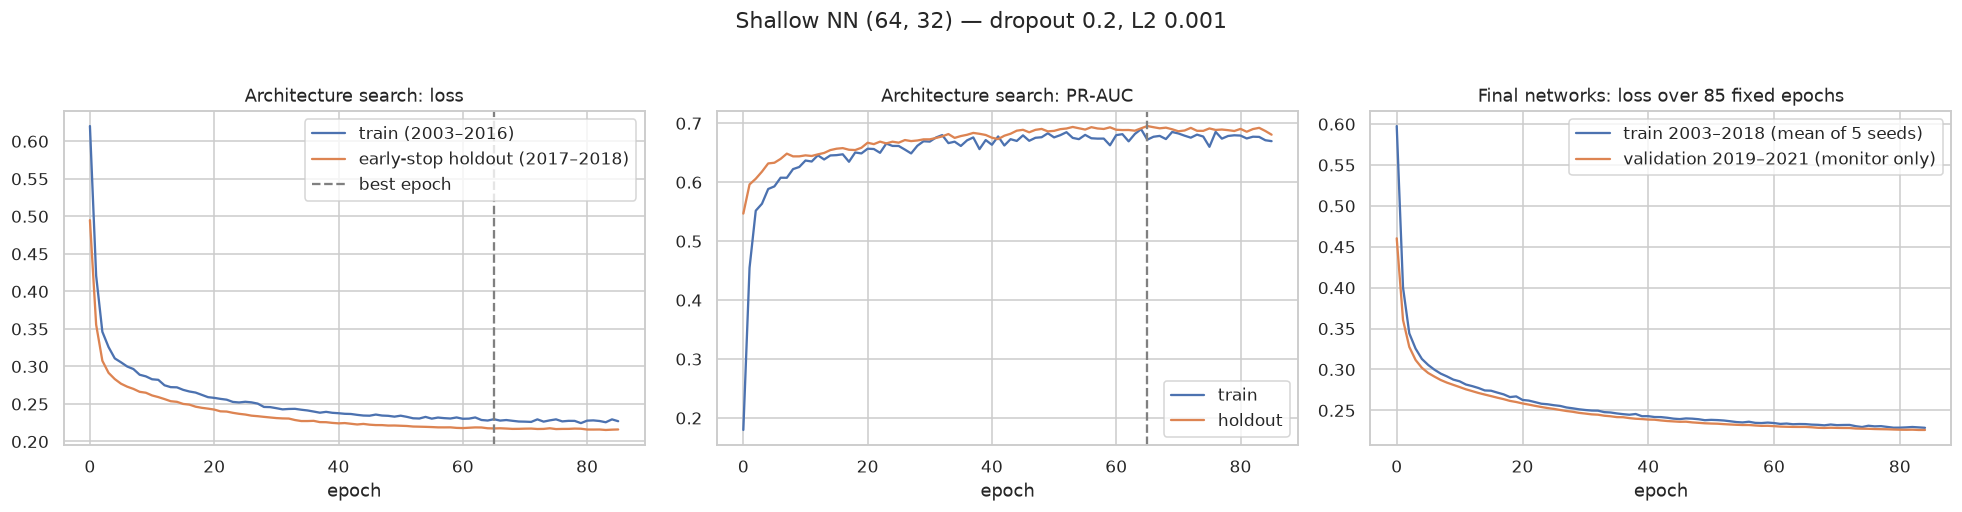

In [59]:
# -----------------------------
# 10.6 — Shallow neural network (Keras), seed-averaged
# -----------------------------
import tensorflow as tf
from tensorflow import keras
tf.get_logger().setLevel("ERROR")

def build_nn(n_inputs, units, dropout, l2, lr=1e-3):
    inputs = keras.Input(shape=(n_inputs,))
    x = inputs
    for u in units:
        x = keras.layers.Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

class KerasSeedEnsemble:
    """sklearn-style wrapper: fitted preprocessor + average probability of several Keras networks."""
    def __init__(self, prep, networks):
        self.prep, self.networks = prep, networks
    def predict_proba(self, X):
        Z = self.prep.transform(X[FEATURE_COLUMNS]).astype("float32")
        p = np.mean([net.predict(Z, verbose=0, batch_size=4096).ravel() for net in self.networks], axis=0)
        return np.column_stack([1 - p, p])

NN_BATCH, NN_MAX_EPOCHS, NN_PATIENCE = 256, 200, 20

# ---- (1) architecture search: fit 2003–2016, early-stop on 2017–2018 (training seasons only) ----
fit_idx = (train_years >= 2003) & (train_years <= 2016)
hold_idx = (train_years >= 2017) & (train_years <= 2018)
nn_tune_prep = clone(preprocessor).fit(X_train[fit_idx])
Z_fit = nn_tune_prep.transform(X_train[fit_idx]).astype("float32")
Z_hold = nn_tune_prep.transform(X_train[hold_idx]).astype("float32")
y_fit, y_hold = y_train_np[fit_idx], y_train_np[hold_idx]

NN_GRID = as_grid(units=[(32, 16), (64, 32)], dropout=[0.2, 0.4], l2=[1e-4, 1e-3])
NN_TUNE_SEEDS = [SEED, SEED + 1]
nn_rows, nn_histories = [], {}
t0 = time.time()
for cfg in NN_GRID:
    aps, epochs = [], []
    for s in NN_TUNE_SEEDS:
        keras.utils.set_random_seed(s)
        net = build_nn(Z_fit.shape[1], **cfg)
        hist = net.fit(Z_fit, y_fit, validation_data=(Z_hold, y_hold), epochs=NN_MAX_EPOCHS, batch_size=NN_BATCH,
                       verbose=0, callbacks=[keras.callbacks.EarlyStopping(
                           monitor="val_pr_auc", mode="max", patience=NN_PATIENCE, restore_best_weights=True)])
        aps.append(average_precision_score(y_hold, net.predict(Z_hold, verbose=0).ravel()))
        epochs.append(int(np.argmax(hist.history["val_pr_auc"])) + 1)
        nn_histories[(str(cfg["units"]), cfg["dropout"], cfg["l2"], s)] = hist.history
    nn_rows.append({**cfg, "holdout_pr_auc_mean": np.mean(aps), "holdout_pr_auc_std": np.std(aps),
                    "best_epochs": epochs})
tuning_results["Shallow NN"] = (pd.DataFrame(nn_rows).sort_values("holdout_pr_auc_mean", ascending=False)
                                .reset_index(drop=True))
print(f"NN architecture search: {len(NN_GRID)} settings × {len(NN_TUNE_SEEDS)} seeds in {time.time() - t0:.0f}s")
display(tuning_results["Shallow NN"])

best_row = tuning_results["Shallow NN"].iloc[0]
NN_BEST = {"units": tuple(best_row["units"]), "dropout": float(best_row["dropout"]), "l2": float(best_row["l2"])}
NN_EPOCHS = int(np.median(best_row["best_epochs"]))
NN_SEEDS = [SEED + k for k in range(5)]
print("Chosen NN architecture:", NN_BEST, "| epochs for the final fit:", NN_EPOCHS)

# ---- (2) final networks: all training seasons, fixed epochs, 5 seeds ----
def train_nn_ensemble(X, y, cfg, epochs, seeds, monitor=None):
    prep = clone(preprocessor).fit(X)
    Z = prep.transform(X).astype("float32")
    vd = None if monitor is None else (prep.transform(monitor[0]).astype("float32"), monitor[1])
    nets, hists = [], []
    for s in seeds:
        keras.utils.set_random_seed(s)
        net = build_nn(Z.shape[1], **cfg)
        h = net.fit(Z, y, epochs=epochs, batch_size=NN_BATCH, verbose=0, validation_data=vd)
        nets.append(net)
        hists.append(h.history)
    return KerasSeedEnsemble(prep, nets), hists

t0 = time.time()
podium_models["Shallow NN"], nn_final_histories = train_nn_ensemble(
    X_train, y_train_np, NN_BEST, NN_EPOCHS, NN_SEEDS, monitor=(X_val, y_val_np))   # monitor = curves only
print(f"Trained {len(NN_SEEDS)} final networks in {time.time() - t0:.0f}s")

# ---- learning curves ("performance during training and validation") ----
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
key = (str(NN_BEST["units"]), NN_BEST["dropout"], NN_BEST["l2"], SEED)
h = nn_histories[key]
axes[0].plot(h["loss"], label="train (2003–2016)")
axes[0].plot(h["val_loss"], label="early-stop holdout (2017–2018)")
axes[0].axvline(int(np.argmax(h["val_pr_auc"])), color="grey", ls="--", label="best epoch")
axes[0].set_title("Architecture search: loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["pr_auc"], label="train"); axes[1].plot(h["val_pr_auc"], label="holdout")
axes[1].axvline(int(np.argmax(h["val_pr_auc"])), color="grey", ls="--")
axes[1].set_title("Architecture search: PR-AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
tr_loss = np.mean([hh["loss"] for hh in nn_final_histories], axis=0)
va_loss = np.mean([hh["val_loss"] for hh in nn_final_histories], axis=0)
axes[2].plot(tr_loss, label="train 2003–2018 (mean of 5 seeds)")
axes[2].plot(va_loss, label="validation 2019–2021 (monitor only)")
axes[2].set_title(f"Final networks: loss over {NN_EPOCHS} fixed epochs"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.suptitle(f"Shallow NN {NN_BEST['units']} — dropout {NN_BEST['dropout']}, L2 {NN_BEST['l2']}", y=1.03)
plt.tight_layout()
plt.show()

## 10.7 · Ensemble, model selection and thresholds (validation only)

1. **Soft-voting ensemble:** the average probability of the four tuned models (LR, GB, RF, NN). It adds no new tuning; it is just another candidate.
2. **Model selection:** compute validation PR-AUC for every candidate. The one with the highest value becomes `BEST_MODEL_NAME`. This is fair because the validation seasons were not used for any tuning above.
3. **Thresholds:** for each model, scan every possible threshold on validation and keep the one with the **highest F1**. That threshold is then **frozen**. The `grid ≤ 3` rule keeps its fixed threshold (no tuning).

,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,predicted_podiums_per_race
model,,,,,,,
Baseline: rule grid ≤ 3,0.917,0.677,0.717,0.717,0.717,0.333,3.000
Baseline: grid-only logistic,0.917,0.677,0.717,0.717,0.717,0.473,3.000
Logistic Regression,0.937,0.736,0.732,0.667,0.811,0.326,3.650
Gradient Boosting,0.942,0.733,0.737,0.682,0.800,0.365,3.517
Random Forest,0.941,0.741,0.729,0.665,0.806,0.338,3.633
Shallow NN,0.936,0.743,0.730,0.664,0.811,0.332,3.667
Soft-voting ensemble,0.940,0.744,0.731,0.684,0.783,0.396,3.433


🏆 Selected on validation PR-AUC: Soft-voting ensemble (PR-AUC 0.744, threshold 0.396)


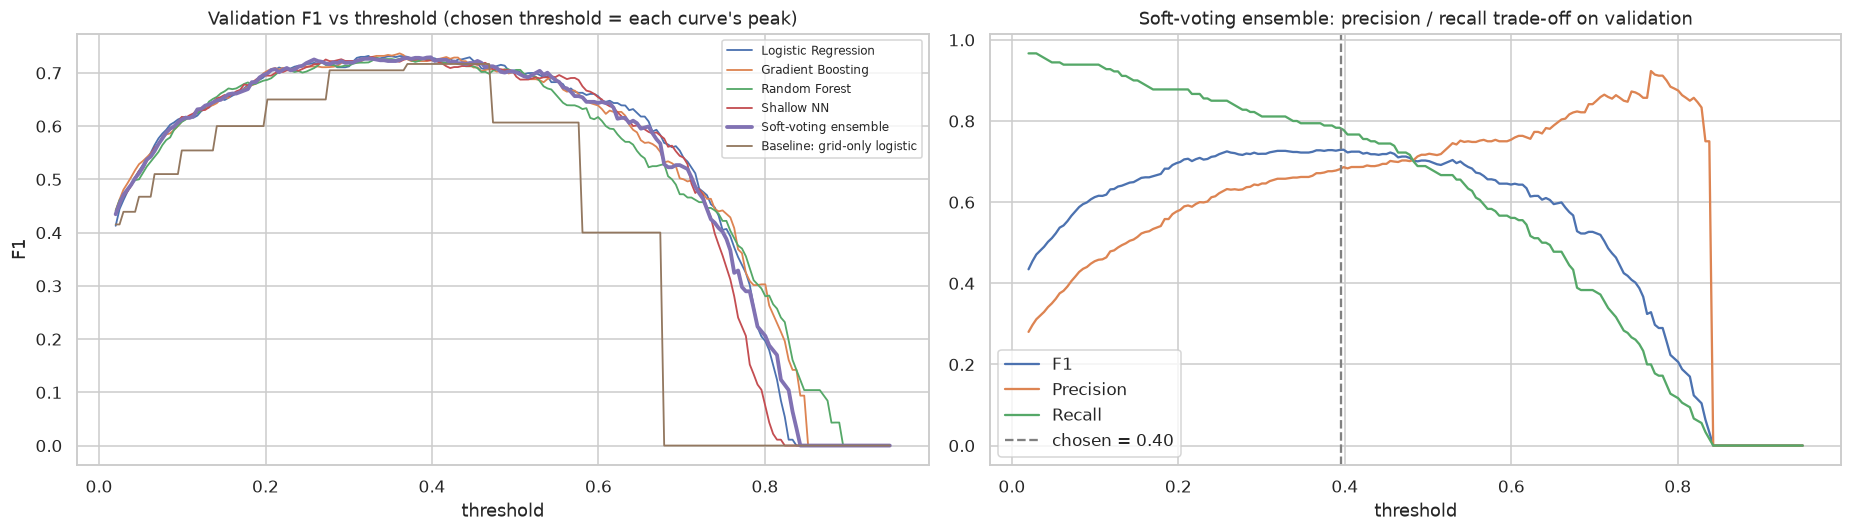

In [60]:
# -----------------------------
# 10.7 — Ensemble + selection + thresholds on VALIDATION
# -----------------------------
class SoftVotingEnsemble:
    """Average of the members' podium probabilities."""
    def __init__(self, members):
        self.members = members
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.members.values()], axis=0)
        return np.column_stack([1 - p, p])

ENSEMBLE_NAME = "Soft-voting ensemble"
ENSEMBLE_MEMBERS = ["Logistic Regression", "Gradient Boosting", "Random Forest", "Shallow NN"]
podium_models[ENSEMBLE_NAME] = SoftVotingEnsemble({n: podium_models[n] for n in ENSEMBLE_MEMBERS})

BASELINE_NAMES = [GRID_RULE_NAME, GRID_LR_NAME]
CANDIDATE_NAMES = [n for n in podium_models if n not in BASELINE_NAMES]

val_proba = {name: m.predict_proba(X_val)[:, 1] for name, m in podium_models.items()}

podium_thresholds, val_rows = {}, []
for name, p in val_proba.items():
    t = GRID_RULE_THRESHOLD if name == GRID_RULE_NAME else best_f1_threshold(y_val_np, p)[0]
    podium_thresholds[name] = t
    val_rows.append({"model": name, **threshold_free_metrics(y_val_np, p), **threshold_metrics(y_val_np, p, t),
                     "threshold": t, "predicted_podiums_per_race": (p >= t).sum() / val_df["raceId"].nunique()})
val_table = pd.DataFrame(val_rows).set_index("model")
display(val_table.style.format("{:.3f}").highlight_max(subset=["PR-AUC", "F1"], color="#d4edda"))

BEST_MODEL_NAME = max(CANDIDATE_NAMES, key=lambda n: val_table.loc[n, "PR-AUC"])
print(f"🏆 Selected on validation PR-AUC: {BEST_MODEL_NAME} "
      f"(PR-AUC {val_table.loc[BEST_MODEL_NAME, 'PR-AUC']:.3f}, threshold {podium_thresholds[BEST_MODEL_NAME]:.3f})")

# Threshold choice, visualised for every model.
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
grid_t = np.linspace(0.02, 0.95, 200)
for name in CANDIDATE_NAMES + [GRID_LR_NAME]:
    f1s = [threshold_metrics(y_val_np, val_proba[name], t)["F1"] for t in grid_t]
    axes[0].plot(grid_t, f1s, label=name, lw=2.5 if name == BEST_MODEL_NAME else 1.2)
axes[0].set_title("Validation F1 vs threshold (chosen threshold = each curve's peak)")
axes[0].set_xlabel("threshold"); axes[0].set_ylabel("F1"); axes[0].legend(fontsize=8)

pb = val_proba[BEST_MODEL_NAME]
for metric in ["F1", "Precision", "Recall"]:
    axes[1].plot(grid_t, [threshold_metrics(y_val_np, pb, t)[metric] for t in grid_t], label=metric)
axes[1].axvline(podium_thresholds[BEST_MODEL_NAME], color="grey", ls="--",
                label=f"chosen = {podium_thresholds[BEST_MODEL_NAME]:.2f}")
axes[1].set_title(f"{BEST_MODEL_NAME}: precision / recall trade-off on validation")
axes[1].set_xlabel("threshold"); axes[1].legend()
plt.tight_layout()
plt.show()

## 10.8 · Final evaluation: train / validation / **test (opened once)**

Everything is frozen above this cell: hyperparameters, the selected model and every threshold. This is the **only** cell that computes predictions on the test seasons (2022–2024).

How to read the table:
* **Train vs validation:** a large gap means overfitting.
* **Validation vs test:** whether the model and its threshold carry over to a new era. The 2022 regulation change starts exactly with the test seasons.

Validation numbers are slightly optimistic for the selected model, because validation was used to pick it and its threshold. **The test numbers are the honest estimate.**

The 95% confidence intervals come from a **race-level bootstrap** of the test seasons (68 races resampled with replacement).

In [61]:
# -----------------------------
# 10.8 — FINAL EVALUATION (the only place the test set is used)
# -----------------------------
y_test_np = y_test.to_numpy().astype(int)
split_data = {"train": (X_train, y_train_np), "validation": (X_val, y_val_np), "test": (X_test, y_test_np)}

all_proba = {"validation": val_proba}
all_proba["train"] = {n: m.predict_proba(X_train)[:, 1] for n, m in podium_models.items()}
all_proba["test"] = {n: m.predict_proba(X_test)[:, 1] for n, m in podium_models.items()}

rows = []
for name in podium_models:
    for split in ["train", "validation", "test"]:
        y, p = split_data[split][1], all_proba[split][name]
        rows.append({"model": name, "split": split, **threshold_free_metrics(y, p),
                     **threshold_metrics(y, p, podium_thresholds[name]), "threshold": podium_thresholds[name]})
comparison = pd.DataFrame(rows)
METRICS = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]

comparison_wide = comparison.pivot(index="model", columns="split", values=METRICS)
comparison_wide = comparison_wide.reindex(columns=pd.MultiIndex.from_product([METRICS, ["train", "validation", "test"]]))
comparison_wide = comparison_wide.loc[list(podium_models)]
print("Model comparison — all five metrics on train / validation / test:")
display(comparison_wide.style.format("{:.3f}"))

# ---- race-level bootstrap CIs on the TEST seasons ----
test_races = test_df["raceId"].to_numpy()
race_ids = np.unique(test_races)
race_rows = {r: np.where(test_races == r)[0] for r in race_ids}
rng = np.random.default_rng(SEED)
boot_idx = [np.concatenate([race_rows[r] for r in rng.choice(race_ids, len(race_ids), replace=True)])
            for _ in range(1000)]

def boot_ci(stat):
    vals = np.array([stat(ix) for ix in boot_idx])
    return np.percentile(vals, [2.5, 97.5])

ci_rows = []
for name in podium_models:
    p = all_proba["test"][name]
    lo, hi = boot_ci(lambda ix: average_precision_score(y_test_np[ix], p[ix]))
    ci_rows.append({"model": name, "test PR-AUC": average_precision_score(y_test_np, p), "CI low": lo, "CI high": hi})
test_ci = pd.DataFrame(ci_rows).set_index("model")

p_best, p_base = all_proba["test"][BEST_MODEL_NAME], all_proba["test"][GRID_LR_NAME]
gain = average_precision_score(y_test_np, p_best) - average_precision_score(y_test_np, p_base)
gain_lo, gain_hi = boot_ci(lambda ix: average_precision_score(y_test_np[ix], p_best[ix])
                                      - average_precision_score(y_test_np[ix], p_base[ix]))
print("Test PR-AUC with 95% race-bootstrap intervals:")
display(test_ci.style.format("{:.3f}"))
print(f"{BEST_MODEL_NAME} − grid-only baseline, test PR-AUC gain: {gain:+.3f} (95% CI {gain_lo:+.3f} to {gain_hi:+.3f})")

# Overfitting check: train − validation PR-AUC gap per model.
gap = (comparison.pivot(index="model", columns="split", values="PR-AUC")
       .assign(train_minus_validation=lambda d: d["train"] - d["validation"],
               validation_minus_test=lambda d: d["validation"] - d["test"])
       .loc[list(podium_models), ["train", "validation", "test", "train_minus_validation", "validation_minus_test"]])
print("PR-AUC gaps (overfitting / era drift check):")
display(gap.style.format("{:+.3f}"))

Model comparison — all five metrics on train / validation / test:


Test PR-AUC with 95% race-bootstrap intervals:


,test PR-AUC,CI low,CI high
model,,,
Baseline: rule grid ≤ 3,0.647,0.591,0.709
Baseline: grid-only logistic,0.647,0.591,0.709
Logistic Regression,0.711,0.648,0.775
Gradient Boosting,0.707,0.650,0.768
Random Forest,0.706,0.647,0.771
Shallow NN,0.707,0.648,0.769
Soft-voting ensemble,0.711,0.652,0.776


Soft-voting ensemble − grid-only baseline, test PR-AUC gain: +0.063 (95% CI +0.023 to +0.100)
PR-AUC gaps (overfitting / era drift check):


split,train,validation,test,train_minus_validation,validation_minus_test
model,,,,,
Baseline: rule grid ≤ 3,+0.618,+0.677,+0.647,-0.059,+0.029
Baseline: grid-only logistic,+0.618,+0.677,+0.647,-0.059,+0.029
Logistic Regression,+0.687,+0.736,+0.711,-0.049,+0.026
Gradient Boosting,+0.725,+0.733,+0.707,-0.008,+0.025
Random Forest,+0.739,+0.741,+0.706,-0.002,+0.035
Shallow NN,+0.702,+0.743,+0.707,-0.042,+0.036
Soft-voting ensemble,+0.719,+0.744,+0.711,-0.025,+0.033


## 10.9 · Plots of the results

1. **ROC and Precision–Recall curves** on validation and test. The PR plot includes the *no-skill* line, equal to the podium rate: a random model would sit on it.
2. **Confusion matrices** on test, at each model's frozen threshold.
3. **Calibration:** when a model says 70%, does a podium happen about 70% of the time?
4. **Test PR-AUC with bootstrap intervals**, compared with the baselines.

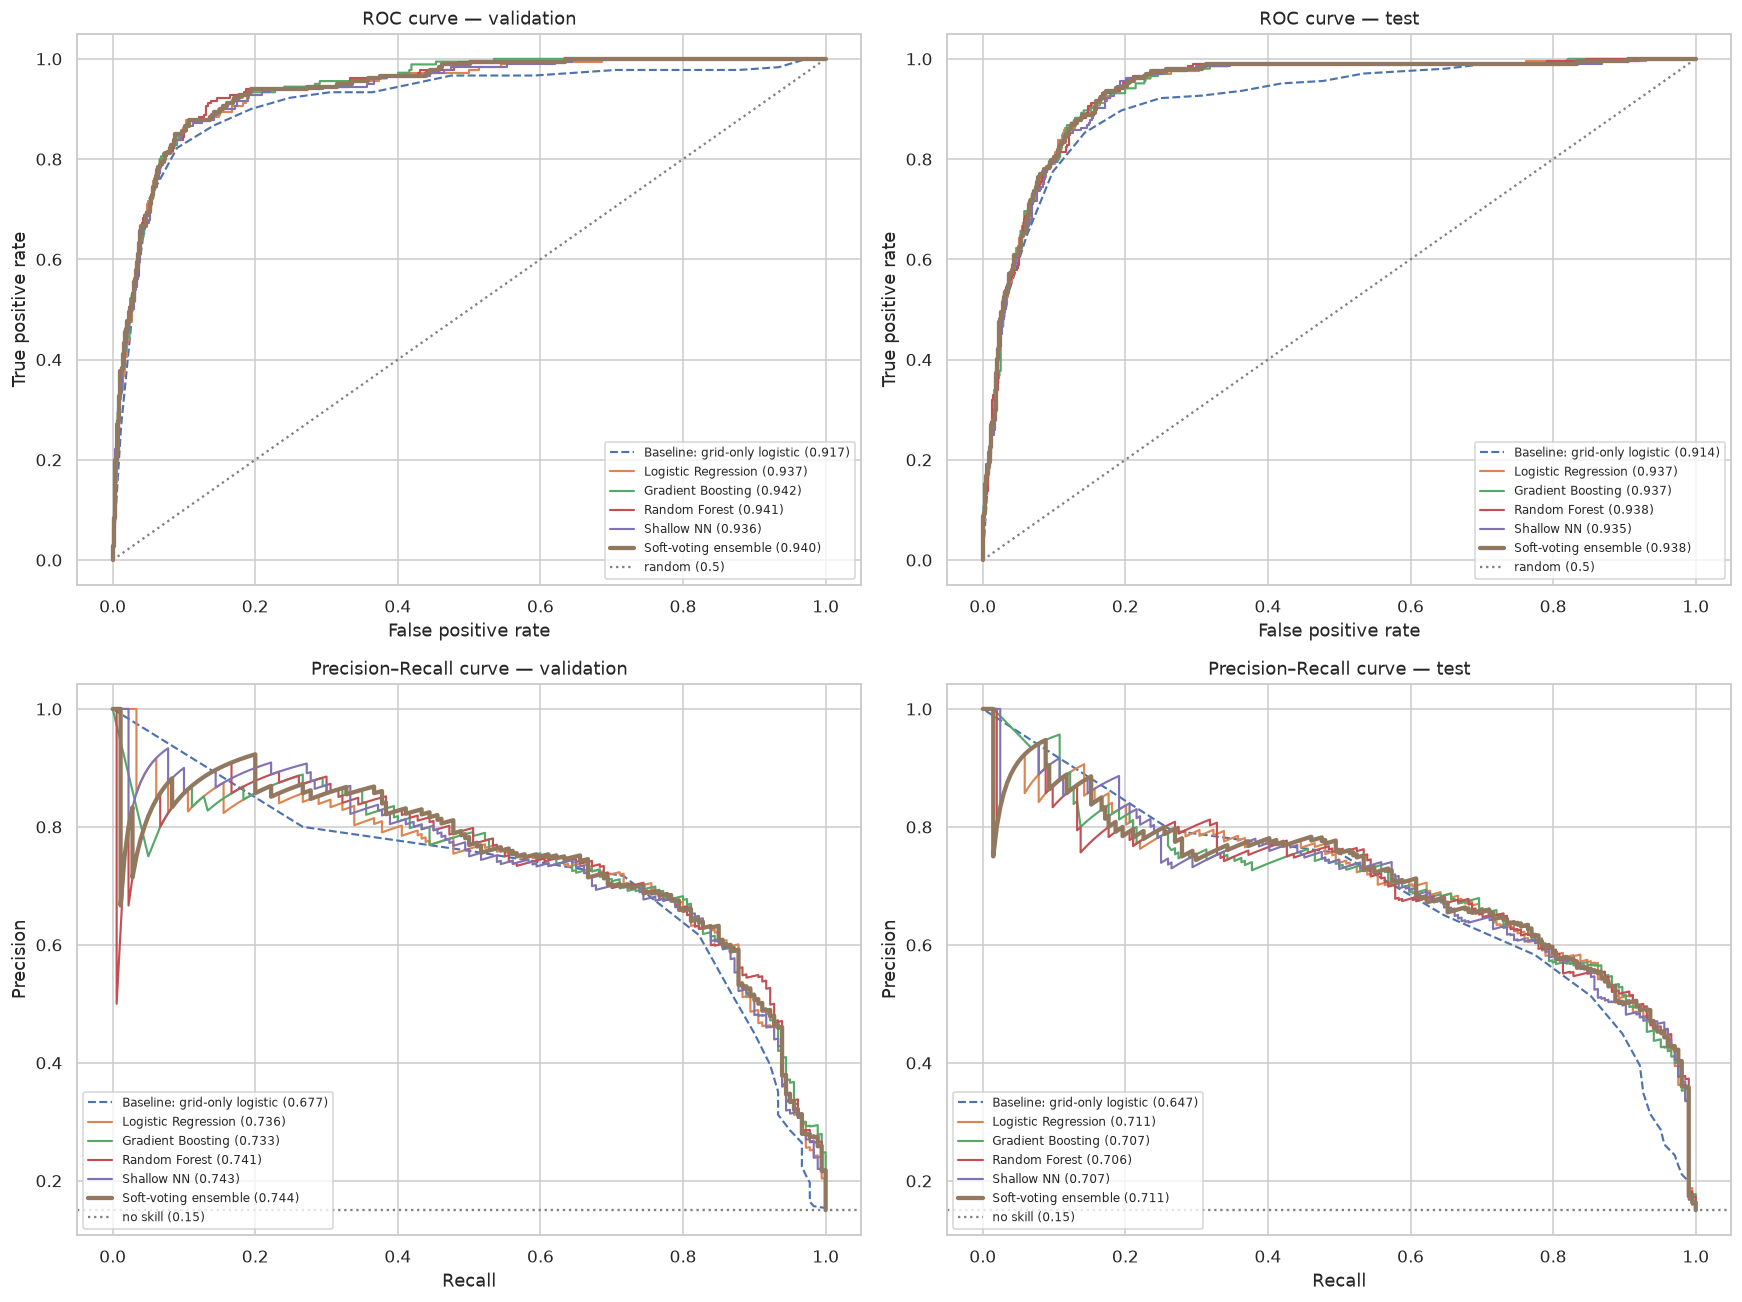

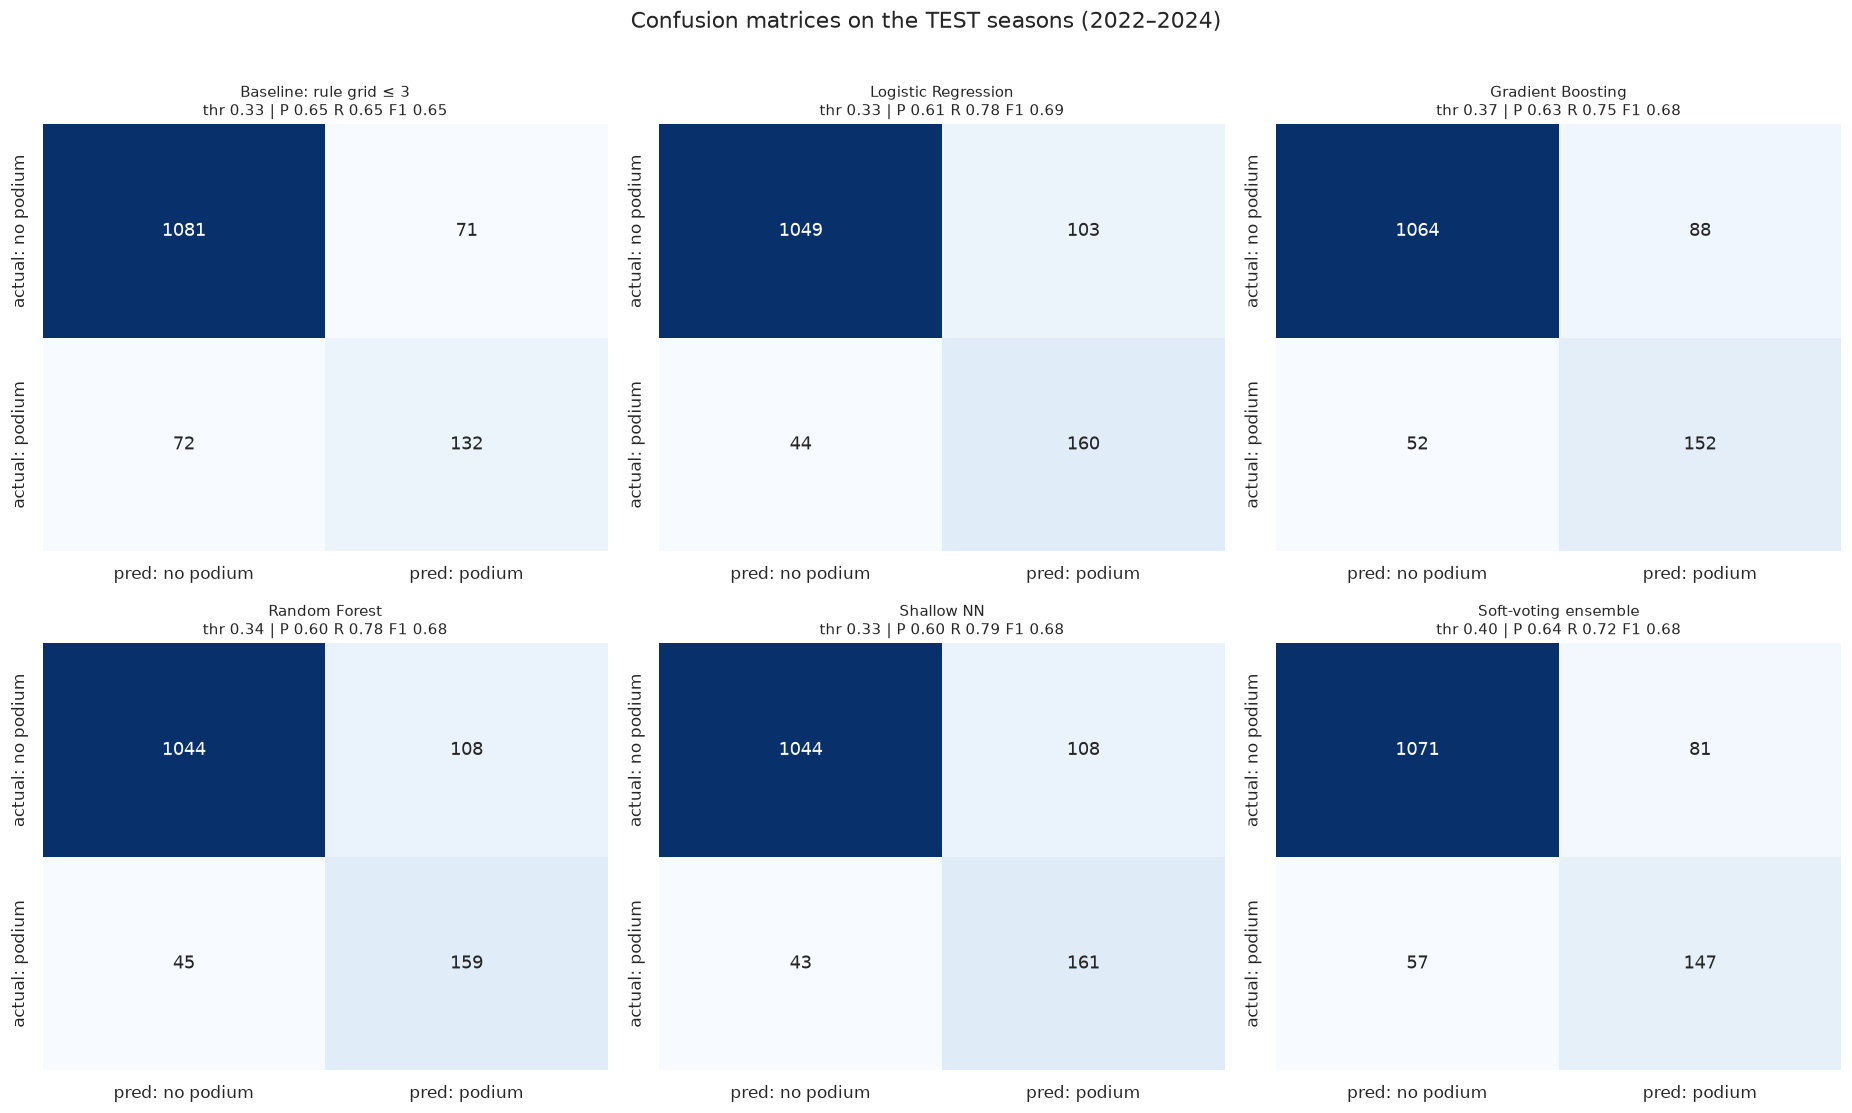

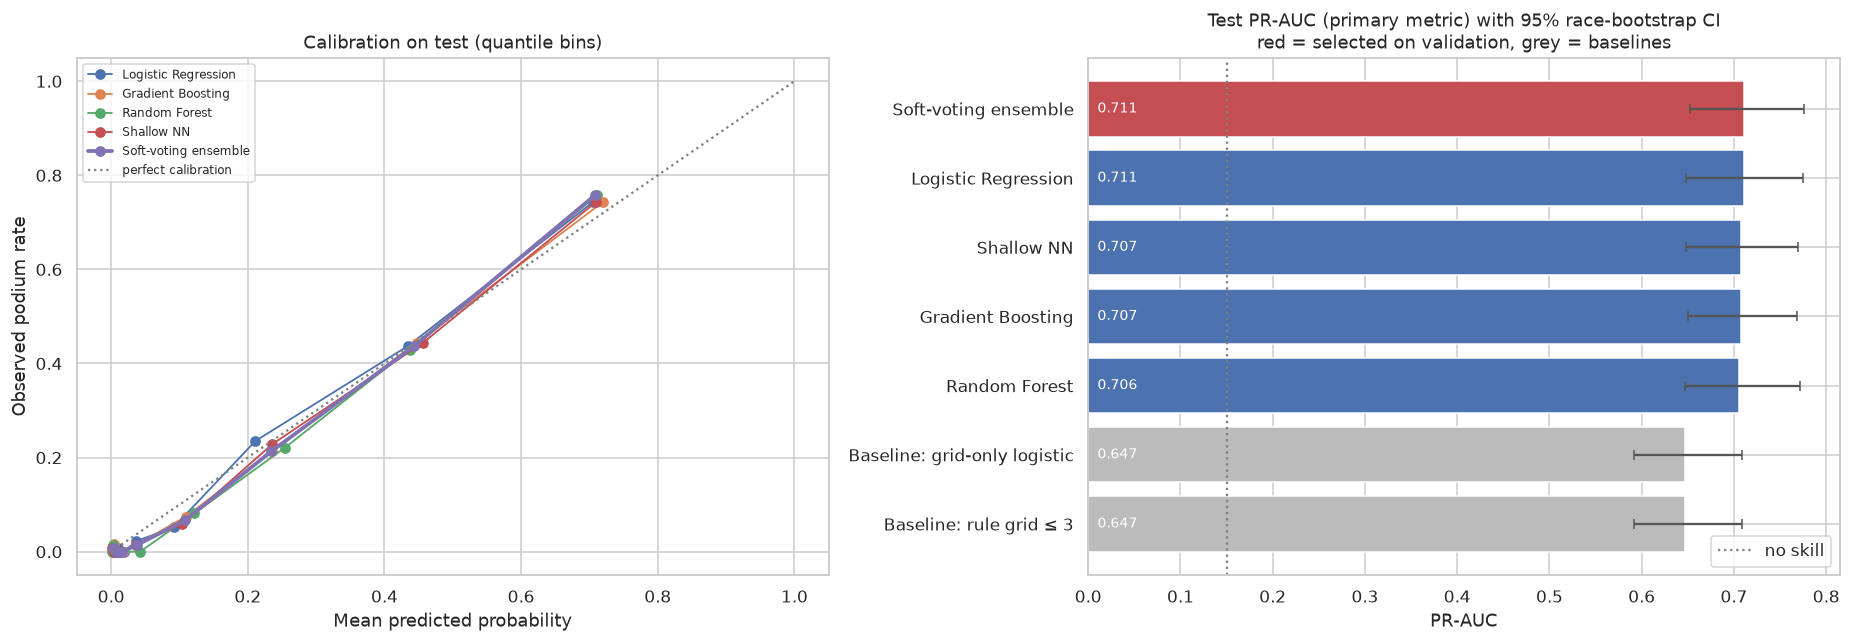

In [62]:
# -----------------------------
# 10.9 — ROC / PR curves, confusion matrices, calibration, PR-AUC bars
# -----------------------------
plot_models = [GRID_LR_NAME] + CANDIDATE_NAMES
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for col, split in enumerate(["validation", "test"]):
    y = split_data[split][1]
    for name in plot_models:
        p = all_proba[split][name]
        lw, ls = (2.8, "-") if name == BEST_MODEL_NAME else ((1.4, "--") if name == GRID_LR_NAME else (1.4, "-"))
        fpr, tpr, _ = roc_curve(y, p)
        axes[0, col].plot(fpr, tpr, lw=lw, ls=ls, label=f"{name} ({roc_auc_score(y, p):.3f})")
        prec, rec, _ = precision_recall_curve(y, p)
        axes[1, col].plot(rec, prec, lw=lw, ls=ls, label=f"{name} ({average_precision_score(y, p):.3f})")
    axes[0, col].plot([0, 1], [0, 1], color="grey", ls=":", label="random (0.5)")
    axes[0, col].set_title(f"ROC curve — {split}"); axes[0, col].set_xlabel("False positive rate"); axes[0, col].set_ylabel("True positive rate")
    axes[1, col].axhline(y.mean(), color="grey", ls=":", label=f"no skill ({y.mean():.2f})")
    axes[1, col].set_title(f"Precision–Recall curve — {split}"); axes[1, col].set_xlabel("Recall"); axes[1, col].set_ylabel("Precision")
    for r in range(2):
        axes[r, col].legend(fontsize=8, loc="lower right" if r == 0 else "lower left")
plt.tight_layout()
plt.show()

# Confusion matrices on TEST at the frozen thresholds.
cm_models = [GRID_RULE_NAME] + CANDIDATE_NAMES
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, name in zip(axes.ravel(), cm_models):
    pred = (all_proba["test"][name] >= podium_thresholds[name]).astype(int)
    cm = confusion_matrix(y_test_np, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["pred: no podium", "pred: podium"], yticklabels=["actual: no podium", "actual: podium"])
    m = threshold_metrics(y_test_np, all_proba["test"][name], podium_thresholds[name])
    ax.set_title(f"{name}\nthr {podium_thresholds[name]:.2f} | P {m['Precision']:.2f} R {m['Recall']:.2f} F1 {m['F1']:.2f}",
                 fontsize=10)
plt.suptitle("Confusion matrices on the TEST seasons (2022–2024)", y=1.01)
plt.tight_layout()
plt.show()

# Calibration (test) + PR-AUC bar chart with bootstrap CIs.
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for name in CANDIDATE_NAMES:
    frac_pos, mean_pred = calibration_curve(y_test_np, all_proba["test"][name], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, marker="o", lw=2.5 if name == BEST_MODEL_NAME else 1.2, label=name)
axes[0].plot([0, 1], [0, 1], color="grey", ls=":", label="perfect calibration")
axes[0].set_title("Calibration on test (quantile bins)")
axes[0].set_xlabel("Mean predicted probability"); axes[0].set_ylabel("Observed podium rate"); axes[0].legend(fontsize=8)

order = test_ci.sort_values("test PR-AUC").index
vals = test_ci.loc[order]
colors = ["#C44E52" if n == BEST_MODEL_NAME else ("#BBBBBB" if n in BASELINE_NAMES else "#4C72B0") for n in order]
axes[1].barh(order, vals["test PR-AUC"],
             xerr=[vals["test PR-AUC"] - vals["CI low"], vals["CI high"] - vals["test PR-AUC"]],
             color=colors, ecolor="#555555", capsize=3)
axes[1].axvline(y_test_np.mean(), color="grey", ls=":", label="no skill")
for y_pos, (n, r) in enumerate(vals.iterrows()):
    axes[1].text(0.01, y_pos, f"{r['test PR-AUC']:.3f}", va="center", color="white", fontsize=9)
axes[1].set_title("Test PR-AUC (primary metric) with 95% race-bootstrap CI\nred = selected on validation, grey = baselines")
axes[1].set_xlabel("PR-AUC"); axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10.10 · A race-aware decision rule: top-3 per race (extra analysis)

A global threshold can predict 1 podium in one race and 6 in another. But **every race has exactly three podium places**, and that is known before the start, so it is not leakage.

The alternative rule: in each race, predict "podium" for the **three drivers with the highest probability**.
* It needs **no threshold at all**, so nothing is tuned.
* With about three real podiums per race, precision ≈ recall ≈ F1, and the score reads simply as "what share of the real podium finishers did we name?"

This is reported **next to** the required threshold-based metrics, not instead of them.

In [63]:
# -----------------------------
# 10.10 — Top-3-per-race decision rule (no threshold)
# -----------------------------
def top3_per_race(split_frame, p):
    ranks = pd.Series(p, index=split_frame.index).groupby(split_frame["raceId"]).rank(ascending=False, method="first")
    return (ranks <= 3).astype(int).to_numpy()

split_frames = {"validation": val_df, "test": test_df}
top3_rows = []
for name in [GRID_RULE_NAME, GRID_LR_NAME] + CANDIDATE_NAMES:
    for split, frame in split_frames.items():
        y = split_data[split][1]
        pred = top3_per_race(frame, all_proba[split][name])
        top3_rows.append({"model": name, "split": split, "F1": f1_score(y, pred),
                          "Precision": precision_score(y, pred), "Recall": recall_score(y, pred)})
top3_table = pd.DataFrame(top3_rows).pivot(index="model", columns="split", values=["F1", "Precision", "Recall"])
top3_table = top3_table.loc[[GRID_RULE_NAME, GRID_LR_NAME] + CANDIDATE_NAMES]
display(top3_table.style.format("{:.3f}"))

thr_f1 = comparison.query("model == @BEST_MODEL_NAME and split == 'test'")["F1"].iloc[0]
top3_f1 = top3_table.loc[BEST_MODEL_NAME, ("F1", "test")]
print(f"{BEST_MODEL_NAME} on test — F1 with frozen global threshold: {thr_f1:.3f} | "
      f"F1 with top-3-per-race rule: {top3_f1:.3f}")

Soft-voting ensemble on test — F1 with frozen global threshold: 0.681 | F1 with top-3-per-race rule: 0.647


## 10.11 · Supplementary: refit the selected model on train + validation

The main results (§10.8) use models trained on **2003–2018 only**: nothing was ever fitted on validation or test, so they are the cleanest to defend.

In real deployment you would retrain on all available history before predicting the next season. This cell refits the selected model with its **already-chosen hyperparameters** on **2003–2021** and applies the **same frozen threshold** to the test seasons.

It is reported as a supplementary row only, because the threshold was chosen for the train-only version of the model.

In [64]:
# -----------------------------
# 10.11 — Supplementary: selected model refitted on 2003–2021
# -----------------------------
X_trval = pd.concat([X_train, X_val])
y_trval = np.concatenate([y_train_np, y_val_np])

def refit_on(name, X, y):
    if name == "Shallow NN":
        return train_nn_ensemble(X, y, NN_BEST, NN_EPOCHS, NN_SEEDS)[0]
    if name == ENSEMBLE_NAME:
        return SoftVotingEnsemble({n: refit_on(n, X, y) for n in ENSEMBLE_MEMBERS})
    return clone(podium_models[name]).fit(X, y)        # clone keeps the tuned hyperparameters, drops the fit

t0 = time.time()
refit_model = refit_on(BEST_MODEL_NAME, X_trval, y_trval)
p_refit = refit_model.predict_proba(X_test)[:, 1]
refit_row = pd.DataFrame([
    {"version": "trained on 2003–2018 (main result)",
     **threshold_free_metrics(y_test_np, all_proba["test"][BEST_MODEL_NAME]),
     **threshold_metrics(y_test_np, all_proba["test"][BEST_MODEL_NAME], podium_thresholds[BEST_MODEL_NAME])},
    {"version": "refitted on 2003–2021 (supplementary)",
     **threshold_free_metrics(y_test_np, p_refit),
     **threshold_metrics(y_test_np, p_refit, podium_thresholds[BEST_MODEL_NAME])},
]).set_index("version")
print(f"{BEST_MODEL_NAME} — test metrics, refit took {time.time() - t0:.0f}s")
display(refit_row.style.format("{:.3f}"))

Soft-voting ensemble — test metrics, refit took 56s


,ROC-AUC,PR-AUC,F1,Precision,Recall
version,,,,,
trained on 2003–2018 (main result),0.938,0.711,0.681,0.645,0.721
refitted on 2003–2021 (supplementary),0.938,0.714,0.684,0.646,0.725


## 10.12 · Save the models and write the answer

Saved for Phase 5 (ablation, preprocessing-order experiments), Phase 6 (XAI) and the inference function:
* every fitted sklearn pipeline (`joblib`);
* the NN networks (`.keras`) together with their fitted preprocessor;
* the frozen thresholds and selected model name (`json`);
* the comparison tables;
* all predicted probabilities.

The objects also stay in memory: `podium_models`, `podium_thresholds`, `BEST_MODEL_NAME`.

The answer below is generated from the numbers, so the report text cannot drift away from the results.

In [65]:
# -----------------------------
# 10.12 — Save artifacts + automatic written answer
# -----------------------------
for name, model in podium_models.items():
    slug = name.lower().replace(" ", "_").replace(":", "").replace("≤", "le").replace("-", "_")
    if isinstance(model, KerasSeedEnsemble):
        joblib.dump(model.prep, MODEL_DIR / f"{slug}__preprocessor.joblib")
        for k, net in enumerate(model.networks):
            net.save(MODEL_DIR / f"{slug}__seed{k}.keras")
    elif isinstance(model, SoftVotingEnsemble):
        json.dump({"members": ENSEMBLE_MEMBERS}, open(MODEL_DIR / f"{slug}.json", "w"))
    else:
        joblib.dump(model, MODEL_DIR / f"{slug}.joblib")

json.dump({"best_model": BEST_MODEL_NAME, "thresholds": podium_thresholds, "features": FEATURE_COLUMNS,
           "lr": LR_BEST, "hgb": HGB_BEST, "rf": {k: (None if v is None else v) for k, v in RF_BEST.items()},
           "nn": {**{k: (list(v) if isinstance(v, tuple) else v) for k, v in NN_BEST.items()}, "epochs": NN_EPOCHS,
                  "seeds": NN_SEEDS}},
          open(MODEL_DIR / "model_config.json", "w"), indent=2, default=str)
comparison.to_csv(OUT_DIR / "model_comparison_long.csv", index=False)
comparison_wide.to_csv(OUT_DIR / "model_comparison_wide.csv")
test_ci.to_csv(OUT_DIR / "test_pr_auc_bootstrap.csv")

predictions = pd.concat([
    frame[["raceId", "driverId", "year", "podium"]].assign(split=split, **{
        f"p_{n}": all_proba[split][n] for n in podium_models})
    for split, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]
], ignore_index=True)
predictions.to_parquet(OUT_DIR / "model_predictions.parquet", index=False)
print("✅ Saved models to", MODEL_DIR, "and comparison / predictions to", OUT_DIR)

# ---------- automatic written answer ----------
def m(name, split, metric):
    return comparison.query("model == @name and split == @split")[metric].iloc[0]

b = BEST_MODEL_NAME
ranking = val_table.loc[CANDIDATE_NAMES, "PR-AUC"].sort_values(ascending=False)
tp_fp = confusion_matrix(y_test_np, (all_proba["test"][b] >= podium_thresholds[b]).astype(int), labels=[0, 1])
tn, fp, fn, tp = tp_fp.ravel()
gap_tv = m(b, "train", "PR-AUC") - m(b, "validation", "PR-AUC")
tuned_test = test_ci.loc[CANDIDATE_NAMES, "test PR-AUC"]
spread = tuned_test.max() - tuned_test.min()
overfit_text = ("Train PR-AUC is not above validation PR-AUC, so there is **no sign of overfitting** "
                "(the 2019–2021 seasons, dominated by one team, were if anything easier to predict)."
                if gap_tv <= 0.02 else
                "Train PR-AUC is clearly above validation PR-AUC, which indicates **some overfitting**.")
baselines_equal = np.allclose(comparison.query("model == @GRID_RULE_NAME")[METRICS].values,
                              comparison.query("model == @GRID_LR_NAME")[METRICS].values)
drift = m(b, "validation", "PR-AUC") - m(b, "test", "PR-AUC")

display(Markdown(
    "### Phase 4 answer\n\n"
    f"**Selected model (highest validation PR-AUC): {b}.** Validation PR-AUC ranking: "
    + ", ".join(f"{n} {v:.3f}" for n, v in ranking.items()) + ".\n\n"
    f"**Test seasons 2022–2024 (never used for any decision):** PR-AUC **{m(b, 'test', 'PR-AUC'):.3f}** "
    f"(95% CI {test_ci.loc[b, 'CI low']:.3f}–{test_ci.loc[b, 'CI high']:.3f}), ROC-AUC **{m(b, 'test', 'ROC-AUC'):.3f}**, "
    f"F1 **{m(b, 'test', 'F1'):.3f}**, precision **{m(b, 'test', 'Precision'):.3f}**, recall **{m(b, 'test', 'Recall'):.3f}** "
    f"at the frozen threshold {podium_thresholds[b]:.2f}.\n\n"
    f"*In plain words:* the model flagged {tp + fp} driver-races as podiums; {tp} of them really were "
    f"({m(b, 'test', 'Precision'):.0%}). It found {tp} of the {tp + fn} real podiums ({m(b, 'test', 'Recall'):.0%}).\n\n"
    f"**Against the baseline:**\n"
    f"* Grid-only logistic regression reaches test PR-AUC {m(GRID_LR_NAME, 'test', 'PR-AUC'):.3f}, a gain of **{gain:+.3f}** "
    f"(95% CI {gain_lo:+.3f} to {gain_hi:+.3f}). "
    + ("The interval excludes zero, so the extra features (qualifying pace, standings, form) add real predictive value beyond the grid."
       if gain_lo > 0 else
       "The interval includes zero, so on the test seasons the gain over the grid alone is not statistically clear.")
    + "\n"
    f"* The `grid ≤ 3` rule scores F1 {m(GRID_RULE_NAME, 'test', 'F1'):.3f} on test, versus {m(b, 'test', 'F1'):.3f} for {b}."
    + (" (The two baselines give identical numbers: the grid-only logistic model is monotone in grid, and its "
       "F1-optimal threshold selects exactly the top 3.)" if baselines_equal else "") + "\n\n"
    f"**Model family matters less than features:** on test, the five tuned candidates span only {spread:.3f} PR-AUC "
    f"({tuned_test.min():.3f}–{tuned_test.max():.3f}), far inside each model's ±0.06 bootstrap interval. They are "
    f"statistically tied. {b} is kept because it was the pre-registered choice on validation, and averaging "
    "four model families makes it the most stable option. The clear, significant gap is between **all** of them "
    "and the grid-only baseline.\n\n"
    f"**Overfitting / era drift:** train − validation PR-AUC gap = {gap_tv:+.3f}; validation − test = {drift:+.3f}. "
    + overfit_text + " "
    "A positive validation − test gap is expected: the test seasons begin with the 2022 regulation change, and the "
    "validation score is slightly optimistic because it was used for model and threshold selection.\n\n"
    f"**Race-aware rule:** naming the top 3 drivers of each race gives test F1 {top3_table.loc[b, ('F1', 'test')]:.3f}, "
    "with no threshold needed.\n\n"
    "**Primary metric = PR-AUC** (rare positive class; ranking quality of real podium finishers). "
    "**Secondary = F1** at the validation-chosen threshold (quality of the final yes/no decision)."
))

✅ Saved models to clean/models and comparison / predictions to clean


### Phase 4 answer

**Selected model (highest validation PR-AUC): Soft-voting ensemble.** Validation PR-AUC ranking: Soft-voting ensemble 0.744, Shallow NN 0.743, Random Forest 0.741, Logistic Regression 0.736, Gradient Boosting 0.733.

**Test seasons 2022–2024 (never used for any decision):** PR-AUC **0.711** (95% CI 0.652–0.776), ROC-AUC **0.938**, F1 **0.681**, precision **0.645**, recall **0.721** at the frozen threshold 0.40.

*In plain words:* the model flagged 228 driver-races as podiums; 147 of them really were (64%). It found 147 of the 204 real podiums (72%).

**Against the baseline:**
* Grid-only logistic regression reaches test PR-AUC 0.647, a gain of **+0.063** (95% CI +0.023 to +0.100). The interval excludes zero, so the extra features (qualifying pace, standings, form) add real predictive value beyond the grid.
* The `grid ≤ 3` rule scores F1 0.649 on test, versus 0.681 for Soft-voting ensemble. (The two baselines give identical numbers: the grid-only logistic model is monotone in grid, and its F1-optimal threshold selects exactly the top 3.)

**Model family matters less than features:** on test, the five tuned candidates span only 0.005 PR-AUC (0.706–0.711), far inside each model's ±0.06 bootstrap interval. They are statistically tied. Soft-voting ensemble is kept because it was the pre-registered choice on validation, and averaging four model families makes it the most stable option. The clear, significant gap is between **all** of them and the grid-only baseline.

**Overfitting / era drift:** train − validation PR-AUC gap = -0.025; validation − test = +0.033. Train PR-AUC is not above validation PR-AUC, so there is **no sign of overfitting** (the 2019–2021 seasons, dominated by one team, were if anything easier to predict). A positive validation − test gap is expected: the test seasons begin with the 2022 regulation change, and the validation score is slightly optimistic because it was used for model and threshold selection.

**Race-aware rule:** naming the top 3 drivers of each race gives test F1 0.647, with no threshold needed.

**Primary metric = PR-AUC** (rare positive class; ranking quality of real podium finishers). **Secondary = F1** at the validation-chosen threshold (quality of the final yes/no decision).

## ✅ Phase 4 summary: PDF checklist

| Requirement | Status | Where |
|---|---|---|
| ≥ 2 statistical ML models | ✅ Logistic Regression (linear/spline), Gradient Boosting, Random Forest | §10.3–10.5 |
| Shallow neural network (1–2 hidden layers) | ✅ Keras MLP, 2 hidden layers, 5-seed average | §10.6 |
| Same rows and same feature set for all models | ✅ asserted | §10.1 |
| ROC-AUC, PR-AUC, F1 (+ precision, recall) for every model | ✅ | §10.8 |
| Train / validation / unseen test reported | ✅ | §10.8 |
| Thresholds and hyperparameters from train/validation only | ✅ time-series CV inside training; thresholds on validation; test opened once | §10.1–10.8 |
| Primary / secondary metric justified | ✅ PR-AUC / F1 | §10 intro, §10.12 |
| Justified against a baseline | ✅ grid ≤ 3 rule + grid-only logistic, with a bootstrap CI on the gain | §10.2, §10.8 |
| How each model works + limitations | ✅ | §10.3–10.6 |
| Performance during training and validation | ✅ NN learning curves; train/validation/test gaps | §10.6, §10.8 |
| Plotting the reports | ✅ ROC, PR, confusion matrices, calibration, PR-AUC with CIs, threshold curves | §10.7, §10.9 |

**Next (Phases 5–6, not part of this phase):**
* feature-group ablation with `FEATURE_GROUPS`;
* ≥ 2 preprocessing-order experiments;
* permutation importance + SHAP (global) and a local SHAP/LIME explanation of the selected model;
* the inference function, demonstrated on a complete and a partially missing record.

# 🧪 Phase 5: Experiments

Phase 4 answered "how good is the model?". Phase 5 answers **"why is it good, and was each step done in the right order?"** with controlled experiments. In every experiment exactly **one thing changes** and everything else is held fixed: rows, split, hyperparameters (from §10), seeds and metric.

| Part | PDF requirement | What we do |
|---|---|---|
| **§11.1 Feature-group ablation** | §5 Experiments; checklist "Feature-group ablation" | Remove one feature group at a time (grid, qualifying, standings, form), **re-train** every model, and measure how much PR-AUC drops |
| **§11.2 Preprocessing-order experiments** | Deliverable 5 ("at least two"); checklist "Preprocessing-order experiment(s) reported" | Three experiments, each comparing two orders of the same steps |

**Rules used throughout:**
* **Hyperparameters are frozen** at the values chosen in §10, so a change in score can only come from the feature set or the order of steps, not from re-tuning.
* **Primary metric = PR-AUC**, reported on validation and test.
  * These experiments do not select or change the final model, so looking at test here does not leak into any decision.
  * Validation remains the main reading, and test confirms it.
* **Uncertainty:** each difference gets a **paired race-level bootstrap 95% CI**. Both versions are scored on the same resampled races, so the CI reflects only the change being tested.
* **The PDF's distinction:** §9.5 justified each feature *before* training with exploratory evidence. The ablation measures each group's *actual contribution after training*. §11.1 puts the two side by side.

## 11.0 · Shared helpers for the experiments

* **Model factories** rebuild each Phase 4 model with its **frozen** hyperparameters on any subset of columns.
* **Paired bootstrap** CIs on validation and test (the test indices are the same 1,000 race resamples used in §10.8).

In [66]:
# -----------------------------
# 11.0 — Helpers: frozen model factories on any column subset + paired bootstrap
# -----------------------------
def make_preprocessor_for(cols, spline=False, order="impute→scale"):
    """Preprocessor restricted to `cols` (numeric: impute+scale [+spline]; binary: passthrough)."""
    num = [c for c in NUMERIC_FEATURES if c in cols]
    binf = [c for c in BINARY_FEATURES if c in cols]
    if order == "impute→scale":
        steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    else:   # "scale→impute": StandardScaler ignores NaN when fitting and keeps them, then the imputer fills them
        steps = [("scaler", StandardScaler()), ("imputer", SimpleImputer(strategy="median"))]
    if spline:
        steps.append(("spline", SplineTransformer(n_knots=5, degree=3, extrapolation="linear")))
    return ColumnTransformer([("num", Pipeline(steps), num), ("bin", "passthrough", binf)])

def frozen_estimator(name):
    """The Phase 4 model with its frozen §10 hyperparameters (unfitted)."""
    if name == "Logistic Regression":
        return LogisticRegression(C=LR_BEST["C"], class_weight=LR_BEST["class_weight"], max_iter=5000)
    if name == "Gradient Boosting":
        return HistGradientBoostingClassifier(**HGB_BEST, early_stopping=False, random_state=SEED)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=600, **RF_BEST, n_jobs=-1, random_state=SEED)
    raise ValueError(name)

LR_SPLINE = LR_BEST["basis"] == "spline"

class ColumnSubsetModel:
    """Wraps a fitted model that only uses `cols`, so it accepts the full feature frame."""
    def __init__(self, model, cols):
        self.model, self.cols = model, list(cols)
    def predict_proba(self, X):
        return self.model.predict_proba(X[self.cols])

class SubsetKerasEnsemble:
    """Seed-averaged Keras networks trained on a column subset."""
    def __init__(self, prep, networks, cols):
        self.prep, self.networks, self.cols = prep, networks, list(cols)
    def predict_proba(self, X):
        Z = self.prep.transform(X[self.cols]).astype("float32")
        p = np.mean([net.predict(Z, verbose=0, batch_size=4096).ravel() for net in self.networks], axis=0)
        return np.column_stack([1 - p, p])

def fit_member(name, cols, X, y, order="impute→scale"):
    """Re-train one Phase 4 model (frozen hyperparameters) on the columns `cols`."""
    if name == "Shallow NN":
        prep = make_preprocessor_for(cols, order=order).fit(X[cols])
        Z = prep.transform(X[cols]).astype("float32")
        nets = []
        for s in NN_SEEDS:
            keras.utils.set_random_seed(s)
            net = build_nn(Z.shape[1], **NN_BEST)
            net.fit(Z, y, epochs=NN_EPOCHS, batch_size=NN_BATCH, verbose=0)
            nets.append(net)
        return SubsetKerasEnsemble(prep, nets, cols)
    spline = (name == "Logistic Regression") and LR_SPLINE
    pipe = Pipeline([("prep", make_preprocessor_for(cols, spline=spline, order=order)),
                     ("model", frozen_estimator(name))]).fit(X[cols], y)
    return ColumnSubsetModel(pipe, cols)

# ---- paired race-level bootstrap on validation (test indices `boot_idx` come from §10.8) ----
val_races = val_df["raceId"].to_numpy()
val_race_ids = np.unique(val_races)
val_race_rows = {r: np.where(val_races == r)[0] for r in val_race_ids}
rng_val = np.random.default_rng(SEED)
val_boot_idx = [np.concatenate([val_race_rows[r] for r in rng_val.choice(val_race_ids, len(val_race_ids), replace=True)])
                for _ in range(1000)]
BOOT = {"validation": (y_val_np, val_boot_idx), "test": (y_test_np, boot_idx)}

def paired_diff_ci(split, p_a, p_b):
    """95% CI of PR-AUC(a) − PR-AUC(b), both scored on the SAME resampled races."""
    y, idx_list = BOOT[split]
    d = [average_precision_score(y[ix], p_a[ix]) - average_precision_score(y[ix], p_b[ix]) for ix in idx_list]
    return np.percentile(d, [2.5, 97.5])

EVAL_SPLITS = {"validation": (X_val, y_val_np), "test": (X_test, y_test_np)}
print("Frozen hyperparameters — LR:", LR_BEST, "| GB:", HGB_BEST, "| RF:", RF_BEST,
      "| NN:", NN_BEST, f"{NN_EPOCHS} epochs × {len(NN_SEEDS)} seeds")

Frozen hyperparameters — LR: {'basis': 'spline', 'C': 0.1, 'class_weight': None} | GB: {'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 80, 'l2_regularization': 1.0, 'max_iter': 150, 'class_weight': None} | RF: {'max_depth': 8, 'min_samples_leaf': 30, 'max_features': 'sqrt', 'class_weight': None} | NN: {'units': (64, 32), 'dropout': 0.2, 'l2': 0.001} 85 epochs × 5 seeds


## 11.1 · Feature-group ablation

**What an ablation is:** remove one group of features, re-train the model from scratch, and measure how much performance drops.
* A **big drop** means the model really relies on that group and nothing else can replace it.
* A **small drop** means either the group is weak, **or** another group carries the same information (redundancy).

**Groups** (defined in Phase 3 as `FEATURE_GROUPS`):

| Group | Features |
|---|---|
| grid | `grid_model`, `pit_lane_start` |
| qualifying | `quali_position`, `gap_to_fastest_quali_pct`, `quali_missing` |
| standings | previous-race driver/constructor points per round + positions + missing flags |
| form | driver/constructor podium rate and average finish over the last 5 races + no-history flags |

**Variants:** "all features" (the Phase 4 models, reused unchanged), then −grid, −qualifying, −standings, −form.

**Two extra paired variants**, because some groups carry overlapping information:
* **−grid & −qualifying:** grid and qualifying position are highly correlated, because the grid *is* the qualifying order apart from penalties. Removing only one lets the other compensate; removing both measures "starting position" as a whole.
* **−standings & −form:** both describe how strong the driver and team have been recently. Removing both measures "recent performance" as a whole.

**What is re-trained:** all four members (LR, GB, RF, 5-seed NN) and the soft-voting ensemble, for every variant.
* The ensemble is the selected model, so its drop is the headline number.
* The member drops show whether all model families agree.
* Each variant gets its own validation-chosen F1 threshold, exactly as in §10.7.

In [67]:
# -----------------------------
# 11.1 — Feature-group ablation (re-train every model without one group at a time)
# -----------------------------
ABLATIONS = {
    "all features (reference)": [],
    "− grid": FEATURE_GROUPS["grid"],
    "− qualifying": FEATURE_GROUPS["qualifying"],
    "− standings": FEATURE_GROUPS["standings"],
    "− form": FEATURE_GROUPS["form"],
    "− grid & qualifying": FEATURE_GROUPS["grid"] + FEATURE_GROUPS["qualifying"],
    "− standings & form": FEATURE_GROUPS["standings"] + FEATURE_GROUPS["form"],
}
MEMBERS = ["Logistic Regression", "Gradient Boosting", "Random Forest", "Shallow NN"]

ablation_proba = {}          # (variant, model) -> {"validation": p, "test": p}
t_start = time.time()
for variant, removed in ABLATIONS.items():
    t0 = time.time()
    if not removed:   # reference = the exact Phase 4 models
        fitted = {n: podium_models[n] for n in MEMBERS}
    else:
        cols = [c for c in FEATURE_COLUMNS if c not in removed]
        fitted = {n: fit_member(n, cols, X_train, y_train_np) for n in MEMBERS}
    fitted[ENSEMBLE_NAME] = SoftVotingEnsemble(dict(fitted))   # copy: the ensemble must not contain itself
    for n, mdl in fitted.items():
        ablation_proba[(variant, n)] = {s: mdl.predict_proba(X)[:, 1] for s, (X, _) in EVAL_SPLITS.items()}
    print(f"{variant:28s} {len(FEATURE_COLUMNS) - len(removed):2d} features  ({time.time() - t0:.0f}s)")
print(f"Ablation finished in {time.time() - t_start:.0f}s")

# ---- results table ----
rows = []
for (variant, n), probs in ablation_proba.items():
    ref = ablation_proba[("all features (reference)", n)]
    thr = best_f1_threshold(y_val_np, probs["validation"])[0]      # threshold re-chosen on validation per variant
    row = {"variant": variant, "model": n}
    for split, (_, y) in EVAL_SPLITS.items():
        ap = average_precision_score(y, probs[split])
        row[f"PR-AUC {split}"] = ap
        row[f"drop {split}"] = average_precision_score(y, ref[split]) - ap
        row[f"F1 {split}"] = threshold_metrics(y, probs[split], thr)["F1"]
    rows.append(row)
ablation_table = pd.DataFrame(rows)

# Paired-bootstrap CI of the drop for the selected model (the ensemble).
ens = ablation_table["model"] == ENSEMBLE_NAME
for split in EVAL_SPLITS:
    lo_hi = [paired_diff_ci(split, ablation_proba[("all features (reference)", ENSEMBLE_NAME)][split],
                            ablation_proba[(v, ENSEMBLE_NAME)][split]) if v != "all features (reference)"
             else (0.0, 0.0) for v in ablation_table.loc[ens, "variant"]]
    ablation_table.loc[ens, f"drop {split} CI low"] = [a for a, _ in lo_hi]
    ablation_table.loc[ens, f"drop {split} CI high"] = [b for _, b in lo_hi]

ens_table = ablation_table[ens].set_index("variant")[
    ["PR-AUC validation", "drop validation", "drop validation CI low", "drop validation CI high",
     "PR-AUC test", "drop test", "drop test CI low", "drop test CI high", "F1 validation", "F1 test"]]
print(f"\n{ENSEMBLE_NAME} — PR-AUC drop when a group is removed (positive = performance lost):")
display(ens_table.style.format("{:+.3f}"))

member_drop = ablation_table.pivot(index="variant", columns="model", values="drop validation").loc[list(ABLATIONS)]
member_drop = member_drop[MEMBERS + [ENSEMBLE_NAME]]
print("Validation PR-AUC drop for every model family:")
display(member_drop.style.format("{:+.3f}"))

all features (reference)     17 features  (2s)


− grid                       15 features  (55s)


− qualifying                 14 features  (55s)


− standings                  11 features  (54s)


− form                       11 features  (55s)


...

− standings & form            5 features  (53s)
Ablation finished in 329s



Soft-voting ensemble — PR-AUC drop when a group is removed (positive = performance lost):


,PR-AUC validation,drop validation,drop validation CI low,drop validation CI high,PR-AUC test,drop test,drop test CI low,drop test CI high,F1 validation,F1 test
variant,,,,,,,,,,
all features (reference),+0.744,+0.000,+0.000,+0.000,+0.711,+0.000,+0.000,+0.000,+0.731,+0.681
− grid,+0.726,+0.018,-0.001,+0.041,+0.700,+0.010,-0.003,+0.026,+0.726,+0.667
− qualifying,+0.733,+0.011,-0.004,+0.025,+0.720,-0.009,-0.018,+0.001,+0.731,+0.656
− standings,+0.736,+0.008,-0.006,+0.018,+0.708,+0.003,-0.006,+0.013,+0.734,+0.690
− form,+0.743,+0.001,-0.014,+0.016,+0.716,-0.005,-0.019,+0.008,+0.732,+0.668
− grid & qualifying,+0.641,+0.103,+0.052,+0.147,+0.578,+0.133,+0.082,+0.185,+0.679,+0.562
− standings & form,+0.716,+0.028,-0.014,+0.068,+0.664,+0.047,+0.011,+0.081,+0.721,+0.667


Validation PR-AUC drop for every model family:


model,Logistic Regression,Gradient Boosting,Random Forest,Shallow NN,Soft-voting ensemble
variant,,,,,
all features (reference),+0.000,+0.000,+0.000,+0.000,+0.000
− grid,+0.023,+0.021,+0.014,+0.011,+0.018
− qualifying,+0.006,-0.002,+0.001,+0.009,+0.011
− standings,+0.002,-0.005,+0.005,+0.005,+0.008
− form,-0.008,-0.007,-0.003,+0.001,+0.001
− grid & qualifying,+0.103,+0.089,+0.090,+0.089,+0.103
− standings & form,+0.025,+0.022,+0.026,+0.033,+0.028


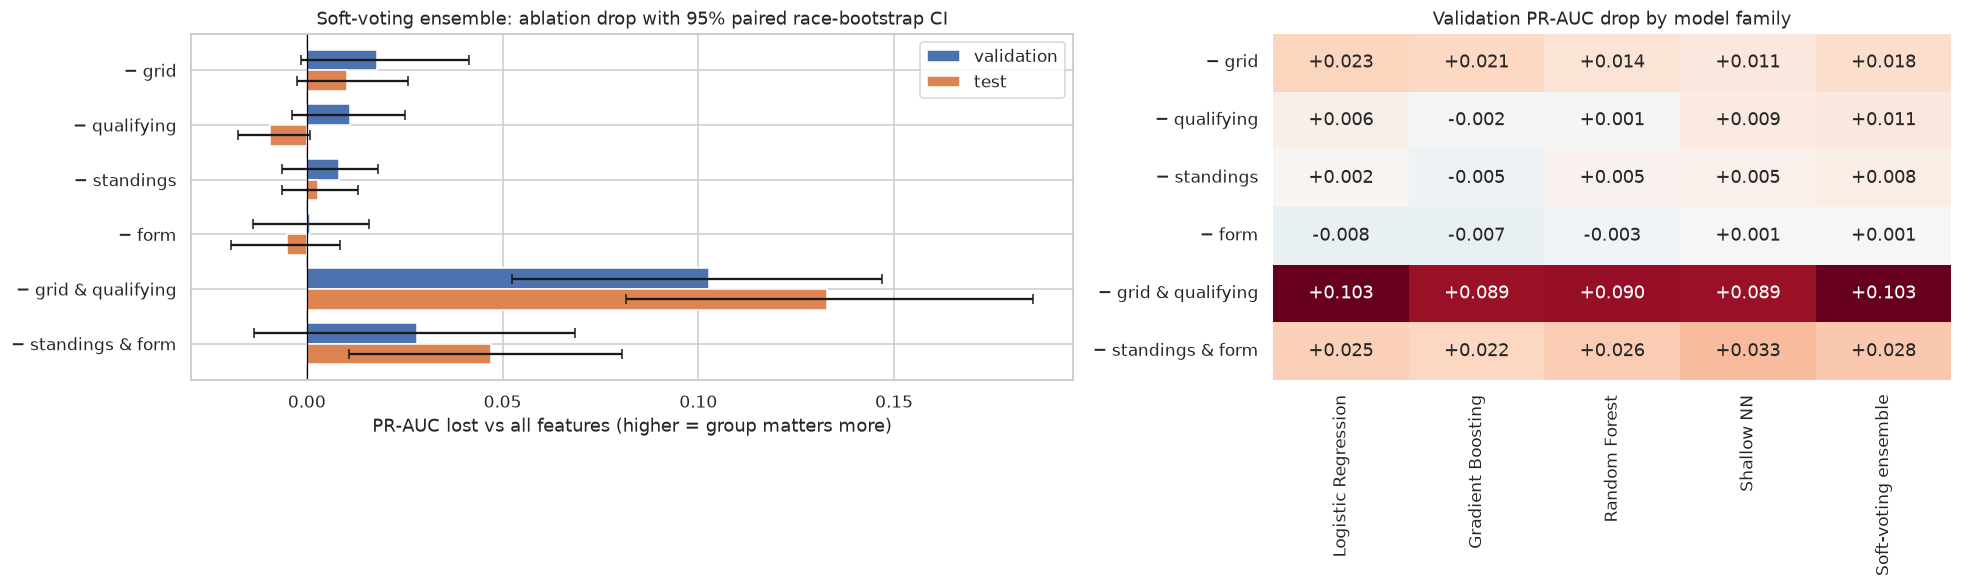

,strongest |Spearman ρ| before training (§9.5),ensemble drop — validation,ensemble drop — test,CI excludes 0 (validation)
grid,0.490624,0.018022,0.010343,False
qualifying,0.493905,0.010902,-0.009343,False
standings,0.472993,0.0083,0.002757,False
form,0.519075,0.000906,-0.00496,False


In [68]:
# -----------------------------
# 11.1 — Ablation plots + evidence-before-training vs contribution-after-training
# -----------------------------
variants = [v for v in ABLATIONS if v != "all features (reference)"]
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

y_pos = np.arange(len(variants))
for k, (split, color) in enumerate([("validation", "#4C72B0"), ("test", "#DD8452")]):
    d = ens_table.loc[variants, f"drop {split}"]
    err = [d - ens_table.loc[variants, f"drop {split} CI low"], ens_table.loc[variants, f"drop {split} CI high"] - d]
    axes[0].barh(y_pos + (k - 0.5) * 0.38, d, height=0.38, xerr=err, capsize=3, color=color, label=split)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(variants)
axes[0].invert_yaxis()
axes[0].set_xlabel("PR-AUC lost vs all features (higher = group matters more)")
axes[0].set_title(f"{ENSEMBLE_NAME}: ablation drop with 95% paired race-bootstrap CI")
axes[0].legend()

sns.heatmap(member_drop.loc[variants], annot=True, fmt="+.3f", cmap="RdBu_r", center=0, ax=axes[1], cbar=False)
axes[1].set_title("Validation PR-AUC drop by model family")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# Evidence BEFORE training (§9.5 Spearman, training seasons) vs contribution AFTER training (ablation).
evidence_vs_ablation = pd.DataFrame({
    group: {
        "strongest |Spearman ρ| before training (§9.5)": max(abs(corr_to_podium[c]) for c in feats if c in corr_to_podium),
        "ensemble drop — validation": ens_table.loc[f"− {group}", "drop validation"],
        "ensemble drop — test": ens_table.loc[f"− {group}", "drop test"],
        "CI excludes 0 (validation)": ens_table.loc[f"− {group}", "drop validation CI low"] > 0,
    }
    for group, feats in FEATURE_GROUPS.items()
}).T
display(evidence_vs_ablation)

In [69]:
# -----------------------------
# 11.1 — Automatic interpretation of the ablation
# -----------------------------
def sig(v):
    lo, hi = ens_table.loc[v, "drop validation CI low"], ens_table.loc[v, "drop validation CI high"]
    return "significant" if lo > 0 else "not significant"

single = [f"− {g}" for g in FEATURE_GROUPS]
order = ens_table.loc[single, "drop validation"].sort_values(ascending=False)
lines = [f"- **{v.replace('− ', '')}**: drop {d:+.3f} PR-AUC on validation "
         f"(95% CI {ens_table.loc[v, 'drop validation CI low']:+.3f} to {ens_table.loc[v, 'drop validation CI high']:+.3f}, "
         f"{sig(v)}); drop {ens_table.loc[v, 'drop test']:+.3f} on test."
         for v, d in order.items()]
n_single_sig = sum(sig(v) == "significant" for v in single)

def pair_text(pair, a, b, label):
    both = ens_table.loc[pair]
    parts = ens_table.loc[a, "drop validation"] + ens_table.loc[b, "drop validation"]
    verdict = ("far more than the sum of removing them one at a time, so the two groups are **redundant**: each can "
               "stand in for the other, and only removing both exposes how much the model needs this information."
               if both["drop validation"] > parts + 0.01 else
               "close to the sum of removing them separately, so the two groups carry largely separate information.")
    test_sig = "significant" if both["drop test CI low"] > 0 else "not significant"
    return (f"- **{label}** ({pair.replace('− ', '−')}): drop **{both['drop validation']:+.3f}** on validation "
            f"(95% CI {both['drop validation CI low']:+.3f} to {both['drop validation CI high']:+.3f}, {sig(pair)}) and "
            f"**{both['drop test']:+.3f}** on test (95% CI {both['drop test CI low']:+.3f} to "
            f"{both['drop test CI high']:+.3f}, {test_sig}). That is {verdict}")

display(Markdown(
    "### Ablation answer\n\n"
    f"**Single groups.** With all features the {ENSEMBLE_NAME} reaches validation PR-AUC "
    f"{ens_table.loc['all features (reference)', 'PR-AUC validation']:.3f}. Removing one group at a time (largest drop first):\n\n"
    + "\n".join(lines) + "\n\n"
    + (f"**{n_single_sig} of 4** single-group removals give a statistically significant drop. "
       + ("No single group is irreplaceable: when one is removed, a related group carries most of the same signal. "
          if n_single_sig == 0 else "")
       + "Grid matters most on its own.\n\n")
    + "**Paired groups (the redundancy test):**\n\n"
    + pair_text("− grid & qualifying", "− grid", "− qualifying", "Starting position") + "\n"
    + pair_text("− standings & form", "− standings", "− form", "Recent performance") + "\n\n"
    + "**Agreement across model families:** the heatmap shows LR, GB, RF and the NN ranking the variants the same way, "
      "so the conclusion does not depend on the model choice.\n\n"
    + "**Evidence before vs contribution after:** §9.5 showed every kept group has a strong *univariate* association "
      "with podium (|ρ| ≈ 0.4–0.5), so each was a reasonable feature to include. The ablation adds what correlation "
      "cannot show: how much information is *unique* once the other groups are present. Form, for example, correlates "
      "strongly with podium but adds almost nothing on top of standings, because both measure recent strength.\n\n"
    + "*These are statements about what the model relies on, not about what causes podiums.*"
))

### Ablation answer

**Single groups.** With all features the Soft-voting ensemble reaches validation PR-AUC 0.744. Removing one group at a time (largest drop first):

- **grid**: drop +0.018 PR-AUC on validation (95% CI -0.001 to +0.041, not significant); drop +0.010 on test.
- **qualifying**: drop +0.011 PR-AUC on validation (95% CI -0.004 to +0.025, not significant); drop -0.009 on test.
- **standings**: drop +0.008 PR-AUC on validation (95% CI -0.006 to +0.018, not significant); drop +0.003 on test.
- **form**: drop +0.001 PR-AUC on validation (95% CI -0.014 to +0.016, not significant); drop -0.005 on test.

**0 of 4** single-group removals give a statistically significant drop. No single group is irreplaceable: when one is removed, a related group carries most of the same signal. Grid matters most on its own.

**Paired groups (the redundancy test):**

- **Starting position** (−grid & qualifying): drop **+0.103** on validation (95% CI +0.052 to +0.147, significant) and **+0.133** on test (95% CI +0.082 to +0.185, significant). That is far more than the sum of removing them one at a time, so the two groups are **redundant**: each can stand in for the other, and only removing both exposes how much the model needs this information.
- **Recent performance** (−standings & form): drop **+0.028** on validation (95% CI -0.014 to +0.068, not significant) and **+0.047** on test (95% CI +0.011 to +0.081, significant). That is far more than the sum of removing them one at a time, so the two groups are **redundant**: each can stand in for the other, and only removing both exposes how much the model needs this information.

**Agreement across model families:** the heatmap shows LR, GB, RF and the NN ranking the variants the same way, so the conclusion does not depend on the model choice.

**Evidence before vs contribution after:** §9.5 showed every kept group has a strong *univariate* association with podium (|ρ| ≈ 0.4–0.5), so each was a reasonable feature to include. The ablation adds what correlation cannot show: how much information is *unique* once the other groups are present. Form, for example, correlates strongly with podium but adds almost nothing on top of standings, because both measure recent strength.

*These are statements about what the model relies on, not about what causes podiums.*

## 11.2 · Preprocessing-order experiments

The order of preprocessing steps can silently change results, mostly by letting information from data the model should not see leak into training. Three experiments; in each, only the order changes.

| # | Experiment | Wrong / alternative order | Our order |
|---|---|---|---|
| **E1** | **When are imputation and scaling fitted?** | Fitted on **all rows** (train + validation + test) **before** splitting | Fitted **after** splitting, on the training split only, inside the `Pipeline` |
| **E2** | **Order inside the numeric pipeline** | **Scale → impute** | **Impute → scale** |
| **E3** | **Order of `shift` and `rolling` in the form features** | Rolling mean **without shifting first**, so the current race is included in its own feature | **Shift → rolling** (only past races) |

**Models used:** Logistic Regression and Gradient Boosting, each with its frozen §10 settings. LR is the most sensitive to preprocessing (it uses scaled values directly); GB is a scale-invariant contrast. Both are fast, so each experiment is a clean re-train.

**Expected results, so the outcome is a test, not a story told afterwards:**
* **E1:** small differences. Few values are missing and feature distributions are similar across seasons, but the leaky version uses statistics of the test seasons, which is never allowed.
* **E2:** almost no difference. Both orders fill missing values with a "typical" value.
* **E3:** a large, **fake** improvement for the leaky order, because the feature then contains the answer.

In [70]:
# -----------------------------
# 11.2 — Preprocessing-order experiments E1, E2, E3
# -----------------------------
EXP_MODELS = ["Logistic Regression", "Gradient Boosting"]
exp_rows, exp_proba = [], {}

def record(exp, variant, model, p_by_split):
    exp_proba[(exp, variant, model)] = p_by_split
    for split, (_, y) in EVAL_SPLITS.items():
        exp_rows.append({"experiment": exp, "variant": variant, "model": model, "split": split,
                         "PR-AUC": average_precision_score(y, p_by_split[split]),
                         "ROC-AUC": roc_auc_score(y, p_by_split[split])})

# ---------- E1: fit imputer/scaler on ALL rows before the split vs on TRAIN only ----------
X_all = pd.concat([X_train, X_val, X_test])
for name in EXP_MODELS:
    spline = (name == "Logistic Regression") and LR_SPLINE
    for variant, fit_rows in [("fit on all rows before split (leaky)", X_all),
                              ("fit on train only, inside pipeline (ours)", X_train)]:
        prep = make_preprocessor_for(FEATURE_COLUMNS, spline=spline).fit(fit_rows)
        model = frozen_estimator(name).fit(prep.transform(X_train), y_train_np)
        record("E1 · fit before vs after split", variant, name,
               {s: model.predict_proba(prep.transform(X))[:, 1] for s, (X, _) in EVAL_SPLITS.items()})

# What actually changed in E1: the statistics learned by the imputer and scaler.
prep_all = make_preprocessor_for(FEATURE_COLUMNS).fit(X_all)
prep_tr = make_preprocessor_for(FEATURE_COLUMNS).fit(X_train)
num_steps = lambda p: p.named_transformers_["num"].named_steps
e1_stats = pd.DataFrame({
    "median (train only)": num_steps(prep_tr)["imputer"].statistics_,
    "median (all rows)": num_steps(prep_all)["imputer"].statistics_,
    "scaler mean (train only)": num_steps(prep_tr)["scaler"].mean_,
    "scaler mean (all rows)": num_steps(prep_all)["scaler"].mean_,
    "scaler std (train only)": num_steps(prep_tr)["scaler"].scale_,
    "scaler std (all rows)": num_steps(prep_all)["scaler"].scale_,
}, index=NUMERIC_FEATURES)
print("E1 — statistics learned by the preprocessing (the leaky version also 'sees' 2019–2024):")
display(e1_stats.round(3))

# ---------- E2: impute → scale vs scale → impute ----------
for name in EXP_MODELS:
    for order in ["scale→impute", "impute→scale"]:
        mdl = fit_member(name, FEATURE_COLUMNS, X_train, y_train_np, order=order)
        record("E2 · order inside the pipeline", f"{order}" + (" (ours)" if order == "impute→scale" else ""), name,
               {s: mdl.predict_proba(X)[:, 1] for s, (X, _) in EVAL_SPLITS.items()})

f = "driver_standing_pos_before"
p_is = make_preprocessor_for(FEATURE_COLUMNS, order="impute→scale").fit(X_train)
p_si = make_preprocessor_for(FEATURE_COLUMNS, order="scale→impute").fit(X_train)
j = NUMERIC_FEATURES.index(f)
z_is, z_si = p_is.transform(X_train)[:, j], p_si.transform(X_train)[:, j]
miss = X_train[f].isna().to_numpy()
e2_stats = pd.DataFrame({
    "value given to missing rows": [z_is[miss][0], z_si[miss][0]],
    "mean after": [z_is.mean(), z_si.mean()],
    "std after": [z_is.std(), z_si.std()],
}, index=["impute → scale", "scale → impute"])
print(f"E2 — effect on '{f}' ({miss.sum()} missing training rows):")
display(e2_stats.round(3))

# ---------- E3: shift → rolling (ours) vs rolling WITHOUT shift (current race included) ----------
FORM_COLS = FEATURE_GROUPS["form"][:4]   # the four rolling features (the two no-history flags stay unchanged)
leaky_driver = history[["raceId", "driverId"]].copy()
leaky_driver["driver_avg_finish_last5"] = history.groupby("driverId")["positionOrder"].transform(
    lambda s: s.rolling(5, min_periods=1).mean())
leaky_driver["driver_podium_rate_last5"] = history.groupby("driverId")["podium"].transform(
    lambda s: s.rolling(5, min_periods=1).mean())
leaky_team = team_race[["raceId", "constructorId"]].copy()
leaky_team["constructor_avg_finish_last5"] = team_race.groupby("constructorId")["team_avg_finish"].transform(
    lambda s: s.rolling(5, min_periods=1).mean())
leaky_team["constructor_podium_rate_last5"] = team_race.groupby("constructorId")["team_podium_rate"].transform(
    lambda s: s.rolling(5, min_periods=1).mean())
leaky_team["constructorId"] = leaky_team["constructorId"].astype("string")

def with_leaky_form(frame):
    X = frame[FEATURE_COLUMNS].copy()
    d = frame[["raceId", "driverId"]].merge(leaky_driver, on=["raceId", "driverId"], how="left", validate="one_to_one")
    t = frame[["raceId", "constructorId"]].merge(leaky_team, on=["raceId", "constructorId"], how="left",
                                                validate="many_to_one")
    for c in ["driver_avg_finish_last5", "driver_podium_rate_last5"]:
        X[c] = d[c].to_numpy(dtype=float)
    for c in ["constructor_avg_finish_last5", "constructor_podium_rate_last5"]:
        X[c] = t[c].to_numpy(dtype=float)
    return X

X_leaky = {"train": with_leaky_form(train_df), "validation": with_leaky_form(val_df), "test": with_leaky_form(test_df)}
leak_corr = pd.DataFrame({
    "Spearman with podium — shift→rolling (ours)": X_train[FORM_COLS].astype(float).corrwith(
        pd.Series(y_train_np, index=X_train.index), method="spearman"),
    "Spearman with podium — rolling without shift (leaky)": X_leaky["train"][FORM_COLS].astype(float).corrwith(
        pd.Series(y_train_np, index=X_train.index), method="spearman"),
})
print("E3 — how strongly each form feature 'knows' the answer (training seasons):")
display(leak_corr.round(3))

for name in EXP_MODELS:
    leaky = fit_member(name, FEATURE_COLUMNS, X_leaky["train"], y_train_np)
    record("E3 · shift→rolling vs rolling without shift", "rolling without shift (leaky)", name,
           {s: leaky.predict_proba(X_leaky[s])[:, 1] for s in EVAL_SPLITS})
    safe = fit_member(name, FEATURE_COLUMNS, X_train, y_train_np)
    record("E3 · shift→rolling vs rolling without shift", "shift → rolling (ours)", name,
           {s: safe.predict_proba(X)[:, 1] for s, (X, _) in EVAL_SPLITS.items()})

exp_results = pd.DataFrame(exp_rows)
exp_wide = exp_results.pivot_table(index=["experiment", "model", "variant"], columns="split", values="PR-AUC")[
    ["validation", "test"]]
print("PR-AUC for every experiment / model / order:")
display(exp_wide.style.format("{:.3f}"))

E1 — statistics learned by the preprocessing (the leaky version also 'sees' 2019–2024):


,median (train only),median (all rows),scaler mean (train only),scaler mean (all rows),scaler std (train only),scaler std (all rows)
grid_model,11.000,11.000,11.236,11.040,6.261,6.150
quali_position,11.000,11.000,11.204,10.998,6.231,6.107
gap_to_fastest_quali_pct,1.799,1.723,2.388,2.268,2.636,2.563
driver_points_per_round_before,1.231,1.455,3.323,3.793,4.722,5.209
driver_standing_pos_before,11.000,11.000,11.307,11.115,6.254,6.127
constructor_points_per_round_before,2.800,3.167,6.684,7.626,8.940,9.895
constructor_standing_pos_before,6.000,6.000,5.863,5.767,3.031,2.973
driver_avg_finish_last5,11.500,11.400,11.170,10.960,4.501,4.438
driver_podium_rate_last5,0.000,0.000,0.140,0.143,0.251,0.254
constructor_avg_finish_last5,11.500,11.400,11.198,10.999,4.215,4.156


E2 — effect on 'driver_standing_pos_before' (468 missing training rows):


,value given to missing rows,mean after,std after
impute → scale,-0.049,-0.000,1.000
scale → impute,-0.051,-0.004,0.963


E3 — how strongly each form feature 'knows' the answer (training seasons):


,Spearman with podium — shift→rolling (ours),Spearman with podium — rolling without shift (leaky)
driver_avg_finish_last5,-0.437,-0.501
driver_podium_rate_last5,0.519,0.667
constructor_avg_finish_last5,-0.453,-0.489
constructor_podium_rate_last5,0.508,0.589


PR-AUC for every experiment / model / order:


,experiment,model,split,PR-AUC alternative order,PR-AUC our order,alternative − ours,CI low,CI high,CI excludes 0
0,E1 · fit before vs after split,Logistic Regression,validation,+0.737,+0.736,+0.001,-0.003,+0.005,False
1,E1 · fit before vs after split,Logistic Regression,test,+0.704,+0.711,-0.007,-0.012,+0.001,False
2,E1 · fit before vs after split,Gradient Boosting,validation,+0.737,+0.733,+0.005,-0.000,+0.012,False
3,E1 · fit before vs after split,Gradient Boosting,test,+0.706,+0.707,-0.002,-0.004,+0.000,False
4,E2 · order inside the pipeline,Logistic Regression,validation,+0.736,+0.736,+0.000,+0.000,+0.000,False
5,E2 · order inside the pipeline,Logistic Regression,test,+0.711,+0.711,+0.000,+0.000,+0.000,False
6,E2 · order inside the pipeline,Gradient Boosting,validation,+0.733,+0.733,+0.000,+0.000,+0.000,False
7,E2 · order inside the pipeline,Gradient Boosting,test,+0.707,+0.707,+0.000,+0.000,+0.000,False
8,E3 · shift→rolling vs rolling without shift,Logistic Regression,validation,+0.848,+0.736,+0.112,+0.066,+0.157,True
9,E3 · shift→rolling vs rolling without shift,Logistic Regression,test,+0.837,+0.711,+0.127,+0.083,+0.169,True


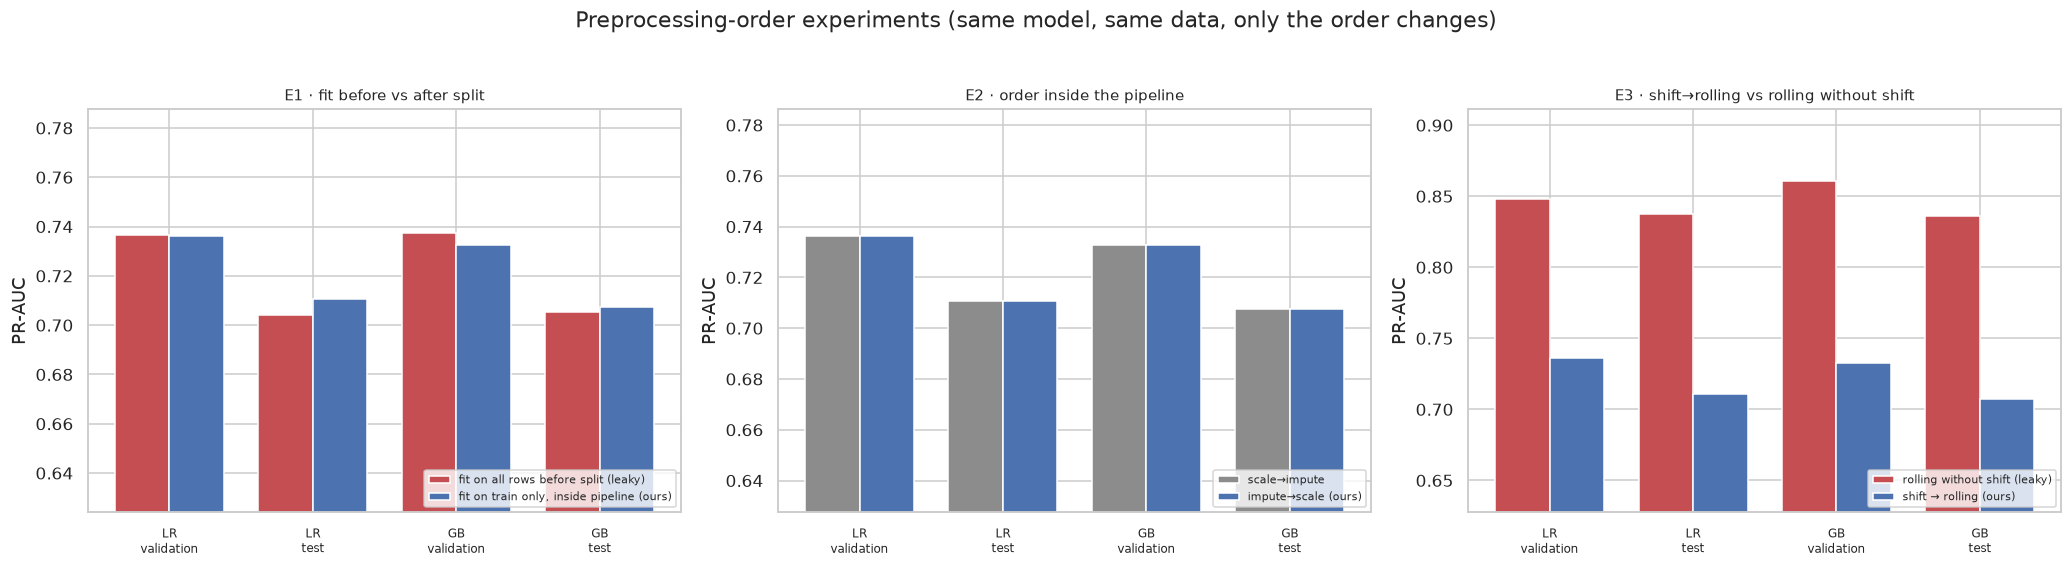

### Preprocessing-order answer

**E1: fitting imputation and scaling before vs after the split.** Leaky − ours PR-AUC is between -0.007 and +0.005 across models and splits (0 of 4 differences statistically significant). The statistics learned from all rows are close to the training-only ones (table above), so on this data the leak barely moves the score. It is still **methodologically wrong**: the model would be using information (medians, means, spreads) from seasons it is supposed to predict. On data whose distribution drifts more, the same mistake inflates results. Fitting inside the `Pipeline` on the training split makes it impossible by construction.

**E2: impute → scale vs scale → impute.** Both orders give **identical PR-AUC to three decimals** for both models and both splits (0 of 4 significant). Both orders give missing rows a typical value (-0.049 vs -0.051 standard deviations for `driver_standing_pos_before`). Impute → scale has the cleaner property that the scaled training column has mean exactly 0 and standard deviation 1, including the imputed rows. The order inside the pipeline is therefore a minor choice; **where** the pipeline is fitted (E1) matters far more.

**E3: shift → rolling vs rolling without shift.** Without the shift, each form feature includes the race being predicted. Its correlation with podium jumps by up to 0.15, and test PR-AUC rises by up to **+0.128** (4 of 4 differences significant). That gain is **fake**: the feature contains the answer, which is impossible to know before the start. This is exactly the leakage the pre-race cutoff forbids, and the reason §9.4 shifts **before** rolling.

**Conclusion:** the orders we use (fit after the split, impute → scale, shift → rolling) are the leakage-safe ones. E3 shows how badly the wrong order can inflate results; E1 shows that some leaks are small on this data but still invalid.

In [71]:
# -----------------------------
# 11.2 — Paired differences, plot, and automatic interpretation
# -----------------------------
OURS = {"E1 · fit before vs after split": "fit on train only, inside pipeline (ours)",
        "E2 · order inside the pipeline": "impute→scale (ours)",
        "E3 · shift→rolling vs rolling without shift": "shift → rolling (ours)"}
ALT = {"E1 · fit before vs after split": "fit on all rows before split (leaky)",
       "E2 · order inside the pipeline": "scale→impute",
       "E3 · shift→rolling vs rolling without shift": "rolling without shift (leaky)"}

diff_rows = []
for exp in OURS:
    for name in EXP_MODELS:
        for split in EVAL_SPLITS:
            p_alt = exp_proba[(exp, ALT[exp], name)][split]
            p_ours = exp_proba[(exp, OURS[exp], name)][split]
            y = EVAL_SPLITS[split][1]
            lo, hi = paired_diff_ci(split, p_alt, p_ours)
            diff_rows.append({"experiment": exp, "model": name, "split": split,
                              "PR-AUC alternative order": average_precision_score(y, p_alt),
                              "PR-AUC our order": average_precision_score(y, p_ours),
                              "alternative − ours": average_precision_score(y, p_alt) - average_precision_score(y, p_ours),
                              "CI low": lo, "CI high": hi, "CI excludes 0": (lo > 0) or (hi < 0)})
exp_diffs = pd.DataFrame(diff_rows)
display(exp_diffs.style.format({c: "{:+.3f}" for c in ["PR-AUC alternative order", "PR-AUC our order",
                                                        "alternative − ours", "CI low", "CI high"]}))

fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=False)
for ax, exp in zip(axes, OURS):
    part = exp_results[exp_results["experiment"] == exp]
    labels = [ALT[exp], OURS[exp]]
    x = np.arange(len(EXP_MODELS) * 2)
    for k, var in enumerate(labels):
        vals = [part.loc[(part["variant"] == var) & (part["model"] == m) & (part["split"] == s), "PR-AUC"].iloc[0]
                for m in EXP_MODELS for s in EVAL_SPLITS]
        ax.bar(x + (k - 0.5) * 0.38, vals, width=0.38, label=var,
               color="#C44E52" if "leaky" in var else ("#8C8C8C" if k == 0 else "#4C72B0"))
    ax.set_xticks(x)
    ax.set_xticklabels([f"{m.split()[0]} {'LR' if m.startswith('Logistic') else 'GB'}\n{s}"
                        .replace("Logistic LR", "LR").replace("Gradient GB", "GB") for m in EXP_MODELS for s in EVAL_SPLITS],
                       fontsize=8)
    lo = part["PR-AUC"].min()
    ax.set_ylim(max(0, lo - 0.08), min(1.0, part["PR-AUC"].max() + 0.05))
    ax.set_title(exp, fontsize=10)
    ax.set_ylabel("PR-AUC")
    ax.legend(fontsize=7, loc="lower right")
plt.suptitle("Preprocessing-order experiments (same model, same data, only the order changes)", y=1.03)
plt.tight_layout()
plt.show()

def summarise(exp):
    part = exp_diffs[(exp_diffs["experiment"] == exp)]
    v = part[part["split"] == "validation"]["alternative − ours"]
    t = part[part["split"] == "test"]["alternative − ours"]
    n_sig = int(part["CI excludes 0"].sum())
    return v, t, n_sig

v1, t1, s1 = summarise("E1 · fit before vs after split")
v2, t2, s2 = summarise("E2 · order inside the pipeline")
v3, t3, s3 = summarise("E3 · shift→rolling vs rolling without shift")
leak_gain = exp_diffs.query("experiment.str.startswith('E3') and split == 'test'", engine="python")["alternative − ours"].max()
corr_jump = (leak_corr.iloc[:, 1] - leak_corr.iloc[:, 0]).abs().max()

display(Markdown(
    "### Preprocessing-order answer\n\n"
    f"**E1: fitting imputation and scaling before vs after the split.** Leaky − ours PR-AUC is between "
    f"{min(v1.min(), t1.min()):+.3f} and {max(v1.max(), t1.max()):+.3f} across models and splits "
    f"({s1} of 4 differences statistically significant). "
    "The statistics learned from all rows are close to the training-only ones (table above), so on this data the "
    "leak barely moves the score. It is still **methodologically wrong**: the model would be using information "
    "(medians, means, spreads) from seasons it is supposed to predict. On data whose distribution drifts more, the "
    "same mistake inflates results. Fitting inside the `Pipeline` on the training split makes it impossible by construction.\n\n"
    "**E2: impute → scale vs scale → impute.** "
    + ("Both orders give **identical PR-AUC to three decimals** for both models and both splits"
       if max(v2.abs().max(), t2.abs().max()) < 0.0005 else
       f"Differences between {min(v2.min(), t2.min()):+.3f} and {max(v2.max(), t2.max()):+.3f}")
    + f" ({s2} of 4 significant). Both orders give missing rows a typical value ({e2_stats.iloc[0, 0]:+.3f} vs "
    f"{e2_stats.iloc[1, 0]:+.3f} standard deviations for `{f}`). "
    "Impute → scale has the cleaner property that the scaled training column has mean exactly 0 and standard "
    "deviation 1, including the imputed rows. The order inside the pipeline is therefore a minor choice; **where** "
    "the pipeline is fitted (E1) matters far more.\n\n"
    f"**E3: shift → rolling vs rolling without shift.** Without the shift, each form feature includes the race being "
    f"predicted. Its correlation with podium jumps by up to {corr_jump:.2f}, and test PR-AUC rises by up to "
    f"**{leak_gain:+.3f}** ({s3} of 4 differences significant). "
    "That gain is **fake**: the feature contains the answer, which is impossible to know before the start. This is "
    "exactly the leakage the pre-race cutoff forbids, and the reason §9.4 shifts **before** rolling.\n\n"
    "**Conclusion:** the orders we use (fit after the split, impute → scale, shift → rolling) are the leakage-safe "
    "ones. E3 shows how badly the wrong order can inflate results; E1 shows that some leaks are small on this data "
    "but still invalid."
))

## 11.3 · Save the experiment results

In [72]:
# -----------------------------
# 11.3 — Save experiment outputs
# -----------------------------
ablation_table.to_csv(OUT_DIR / "ablation_results.csv", index=False)
evidence_vs_ablation.to_csv(OUT_DIR / "ablation_vs_evidence.csv")
exp_results.to_csv(OUT_DIR / "preprocessing_order_results.csv", index=False)
exp_diffs.to_csv(OUT_DIR / "preprocessing_order_differences.csv", index=False)
print("✅ Saved ablation and preprocessing-order results to", OUT_DIR)

✅ Saved ablation and preprocessing-order results to clean


## ✅ Phase 5 summary: PDF checklist

| Requirement | Status | Where |
|---|---|---|
| Feature-group ablation: remove one group at a time and re-train | ✅ grid, qualifying, standings, form, plus two paired variants (grid & qualifying, standings & form); all 4 models + ensemble re-trained | §11.1 |
| Results reported for each feature group | ✅ table, CI plot, per-model heatmap | §11.1 |
| Ablation contrasted with pre-training evidence | ✅ §9.5 Spearman vs ablation drop | §11.1 |
| At least two preprocessing-order experiments | ✅ three: E1 fit before/after split, E2 impute↔scale, E3 shift↔rolling | §11.2 |
| Before/after comparisons in their own cells, with numbers | ✅ every variant is a separate re-train; paired bootstrap CIs | §11.2 |

**Next:**
* **Phase 6, XAI:** permutation importance + SHAP (global) and LIME / local SHAP (local), with the "not causal" statement.
* **The inference function**, demonstrated on a complete and a partially missing record.

# 🔎 Phase 6: Model Explainability (XAI)

Phase 4 selected the final model using **validation PR-AUC**, and Phase 5 tested how much the feature groups and preprocessing choices matter.
Phase 6 now asks:

> **What information is the selected model relying on when it predicts a podium?**

We use the **already-selected Phase 4 model** (`BEST_MODEL_NAME`) without changing its hyperparameters, threshold, features, or training data.

This phase contains the required explanations:

| # | Method | Scope | Question it answers |
|---|---|---|---|
| 1 | **Permutation importance** (per feature **and per feature group**) | global | How much validation PR-AUC is lost when the information is scrambled? |
| 2 | **SHAP** (model-agnostic, permutation algorithm) | global | How strongly does each feature move individual probabilities, and in which direction? |
| 3 | **Local SHAP** (waterfall) on two test predictions | local | Why did *this* driver get *this* probability? |
| 4 | **LIME** on the same two test predictions | local | Does a completely different local method tell the same story? |

§12.2 also **reconciles Phase 5 with Phase 6**: removing a feature group and re-training (ablation) and scrambling a group inside the frozen model (permutation) give different numbers on purpose; we explain why.

Phase 6 is followed by **§13 — the inference function (Deliverable 7)**, demonstrated on a complete and on a partially missing record.

### Important interpretation rule

These are **model explanations, not causal effects**.
A feature can be important because the model relies on it for prediction; that does **not** prove that changing that feature would cause a driver to finish on the podium.

## 12.1 · XAI setup — explain the frozen selected model

We explain exactly the model that Phase 4 selected on validation data.

* **No re-training or model selection happens here.**
* **Permutation importance** is evaluated on the validation set, so it measures out-of-sample predictive dependence.
* **SHAP and LIME background data** come from the training set only.
* Local test examples are selected **only by the model's predicted probability**, never by looking at whether the driver actually finished on the podium.
* Every random step has its own seeded generator (`perm_rng`, `SEED`), so the notebook gives the same numbers on every run and does not disturb random state used elsewhere.

Because the selected model can be a soft-voting ensemble containing different model families (LR, gradient boosting, random forest, neural network), we use **model-agnostic** explainers. They treat the ensemble as one prediction function instead of explaining only one of its members.

In [73]:
# -----------------------------
# 12.1 — XAI setup
# -----------------------------
try:
    import shap
except ImportError as e:
    raise ImportError("Phase 6 requires the `shap` package (pre-installed on Kaggle).") from e
try:
    import lime
    import lime.lime_tabular
except ImportError as e:
    raise ImportError("Phase 6 requires the `lime` package (pre-installed on Kaggle).") from e

# Explain the model that was already selected in Phase 4.
XAI_MODEL_NAME = BEST_MODEL_NAME
xai_model = podium_models[XAI_MODEL_NAME]
xai_threshold = float(podium_thresholds[XAI_MODEL_NAME])

# Defensive checks: Phase 6 must use exactly the same feature space as modelling.
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns) == FEATURE_COLUMNS

def xai_predict(X):
    """Podium probability for SHAP/LIME. They may pass a DataFrame or a NumPy array,
    so we always rebuild the exact Phase 4 column layout first."""
    if isinstance(X, pd.DataFrame):
        frame = X.loc[:, FEATURE_COLUMNS].copy()
    else:
        frame = pd.DataFrame(np.asarray(X, dtype=float), columns=FEATURE_COLUMNS)
    return xai_model.predict_proba(frame)[:, 1]

# Human-readable labels (driver name + race name) for the local examples.
_drivers_lookup = clean["drivers"].assign(driverId=lambda d: d["driverId"].astype(int)).set_index("driverId")
_races_lookup = clean["races"].assign(raceId=lambda d: d["raceId"].astype(int)).set_index("raceId")

def describe_driver_race(race_id, driver_id):
    d = _drivers_lookup.loc[int(driver_id)]
    r = _races_lookup.loc[int(race_id)]
    return f"{d['forename']} {d['surname']} — {int(r['year'])} {r['name']} (round {int(r['round'])})"

# Test-set probabilities of the frozen model (used to pick local examples by prediction only).
xai_test_proba = xai_predict(X_test)

print(f"Explaining: {XAI_MODEL_NAME}  (frozen Phase 4 threshold = {xai_threshold:.3f})")
print(f"Features: {len(FEATURE_COLUMNS)} | validation rows: {len(X_val):,} | test rows: {len(X_test):,}")
print(f"shap {shap.__version__} | lime installed")

/tmp/claude-0/v22/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Explaining: Soft-voting ensemble  (frozen Phase 4 threshold = 0.396)
Features: 17 | validation rows: 1,199 | test rows: 1,356
shap 0.54.1 | lime installed


## 12.2 · Global explanation 1 — permutation importance

### Idea

For one feature at a time:

1. Measure the selected model's normal validation **PR-AUC**.
2. Randomly shuffle that feature's column (the rows of every other column stay unchanged).
3. Predict again with the **same, frozen model**.
4. Measure how much PR-AUC drops.
5. Repeat the shuffle 15 times and report the mean and standard deviation.

If shuffling a feature causes a **large performance drop**, the model depends strongly on the information carried by that feature.
A value near zero means shuffling it barely changes validation performance. A slightly negative value is sampling noise (the shuffle happened to help a little).

### Why PR-AUC?

Phase 4 chose PR-AUC as the primary metric because podiums are the minority class (~15% of rows). Using the same metric here keeps the explanation aligned with the model-selection objective.

### Why we implement it by hand

`sklearn.inspection.permutation_importance` needs an estimator with `.fit()`/`.score()`. Our selected model is a custom `SoftVotingEnsemble` that only has `predict_proba`, so a small loop is simpler and fully transparent. The same helper also shuffles **groups** of columns (next section).

Selected-model validation PR-AUC before permutation: 0.744   (123s)


,feature,pr_auc_drop_mean,pr_auc_drop_std
0,grid_model,+0.0929,0.0263
1,quali_position,+0.0582,0.0232
2,driver_podium_rate_last5,+0.0179,0.0167
3,gap_to_fastest_quali_pct,+0.0114,0.0124
4,constructor_avg_finish_last5,+0.0081,0.0116
5,driver_avg_finish_last5,+0.0048,0.0048
6,driver_standing_missing,+0.0017,0.0027
7,constructor_points_per_round_before,+0.0013,0.0047
8,constructor_podium_rate_last5,+0.0012,0.0065
9,constructor_standing_missing,+0.0009,0.0012


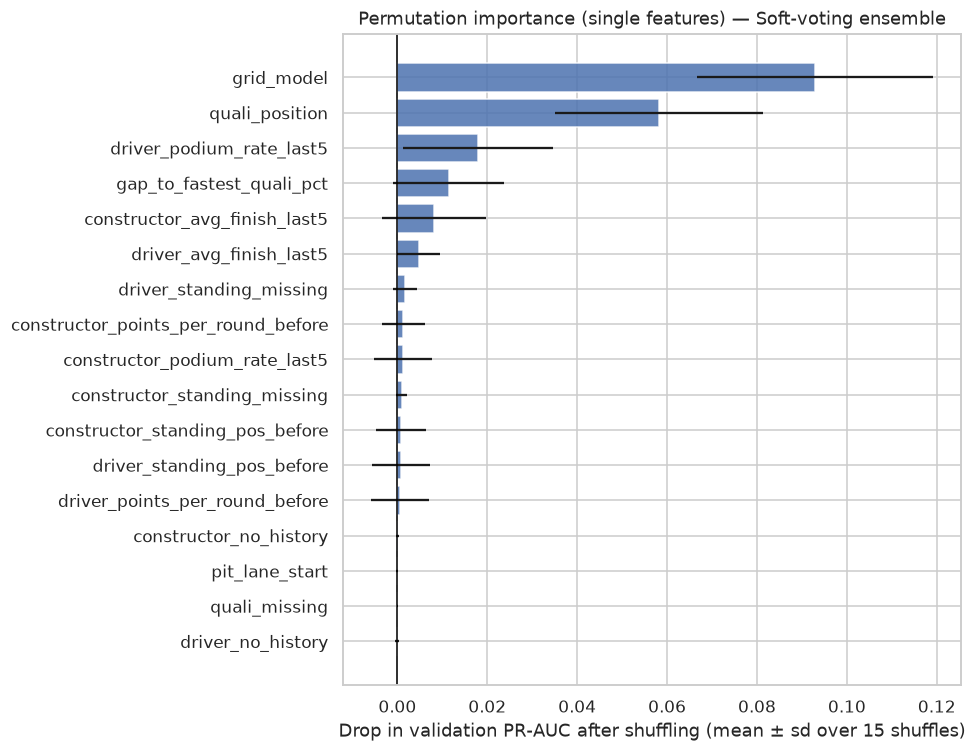

In [74]:
# -----------------------------
# 12.2 — Permutation importance on VALIDATION (single features)
# -----------------------------
N_PERM_REPEATS = 15
xai_val_baseline = average_precision_score(y_val_np, xai_predict(X_val))

def permutation_drop(columns, n_repeats=N_PERM_REPEATS, seed=SEED):
    """Mean/std drop in validation PR-AUC when `columns` are shuffled TOGETHER
    (one shared row permutation, so values inside the group stay consistent with each other)."""
    perm_rng = np.random.default_rng(seed)        # own generator: does not overwrite any global `rng`
    drops = []
    for _ in range(n_repeats):
        X_perm = X_val.copy()                      # the original X_val is never modified
        order = perm_rng.permutation(len(X_perm))
        X_perm[columns] = X_val[columns].to_numpy()[order]
        drops.append(xai_val_baseline - average_precision_score(y_val_np, xai_predict(X_perm)))
    return float(np.mean(drops)), float(np.std(drops, ddof=1))

t0 = time.time()
perm_rows = []
for feature in FEATURE_COLUMNS:
    mean_drop, std_drop = permutation_drop([feature])
    perm_rows.append({"feature": feature, "pr_auc_drop_mean": mean_drop, "pr_auc_drop_std": std_drop})

perm_importance = (pd.DataFrame(perm_rows)
                   .sort_values("pr_auc_drop_mean", ascending=False)
                   .reset_index(drop=True))

print(f"Selected-model validation PR-AUC before permutation: {xai_val_baseline:.3f}   ({time.time() - t0:.0f}s)")
display(perm_importance.style.format({"pr_auc_drop_mean": "{:+.4f}", "pr_auc_drop_std": "{:.4f}"}))

plot_perm = perm_importance.sort_values("pr_auc_drop_mean", ascending=True)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_perm["feature"], plot_perm["pr_auc_drop_mean"], xerr=plot_perm["pr_auc_drop_std"], alpha=0.85)
ax.axvline(0, linewidth=1, color="black")
ax.set_xlabel("Drop in validation PR-AUC after shuffling (mean ± sd over 15 shuffles)")
ax.set_title(f"Permutation importance (single features) — {XAI_MODEL_NAME}")
plt.tight_layout()
plt.show()

### How to read single-feature permutation importance

The horizontal axis is **performance lost**, not a probability and not a causal effect.
If a feature has importance `0.04`, shuffling that column reduced validation PR-AUC by about **0.04 on average**.

**Known weakness — correlated features.** `grid_model` and `quali_position` carry almost the same information (the grid is mostly the qualifying order). When only one of them is shuffled, the model still sees the other one, so each single-feature score *understates* how much the model needs "starting position" as a whole. Shuffling one of them alone also creates **impossible rows** (e.g. pole position in qualifying but 18th on the grid), which can mislead the model. Both problems are fixed by shuffling **whole feature groups** together, which we do next.

## 12.2b · Grouped permutation importance and reconciliation with the Phase 5 ablation

We now shuffle each **feature group** from §9.6 (`FEATURE_GROUPS`) as one block: all columns of the group get the **same** row permutation, so values inside a group stay consistent (e.g. `quali_position` and `quali_missing` still agree). We also shuffle the two **pairs** tested in Phase 5: grid + qualifying and standings + form.

### Why Phase 5 and Phase 6 give different numbers — and why both are correct

| | **Phase 5 ablation** (§11.1) | **Phase 6 permutation** (here) |
|---|---|---|
| What is done to the group | Removed from the data | Kept, but its values are scrambled |
| Is the model re-trained? | **Yes** — a new model is fitted without the group | **No** — the frozen Phase 4 model is used |
| What the model can do | Learn to rely on *other* groups instead | Nothing: it still trusts the (now wrong) values |
| Question answered | *How much **unique** information does this group add that the other groups cannot replace?* | *How much does **this fitted model** rely on this group?* |

So a group can show a **large permutation drop but a small ablation drop**. That happens when the model leans on it heavily, but a re-trained model can recover the same signal from a redundant group. The table below puts both numbers side by side for every group.

Grouped permutation finished in 43s  (validation PR-AUC baseline 0.744)


,n_features,permutation drop (frozen model),permutation sd,ablation drop (re-trained),ablation CI low,ablation CI high,recovered by re-training
group,,,,,,,
grid,2,+0.0930,+0.0263,+0.0180,-0.0015,+0.0414,+0.0749
qualifying,3,+0.0945,+0.0263,+0.0109,-0.0039,+0.0250,+0.0836
standings,6,+0.0210,+0.0144,+0.0083,-0.0065,+0.0182,+0.0127
form,6,+0.0674,+0.0227,+0.0009,-0.0138,+0.0158,+0.0665
grid & qualifying,5,+0.3512,+0.0343,+0.1028,+0.0525,+0.1470,+0.2484
standings & form,12,+0.2183,+0.0268,+0.0280,-0.0135,+0.0684,+0.1902


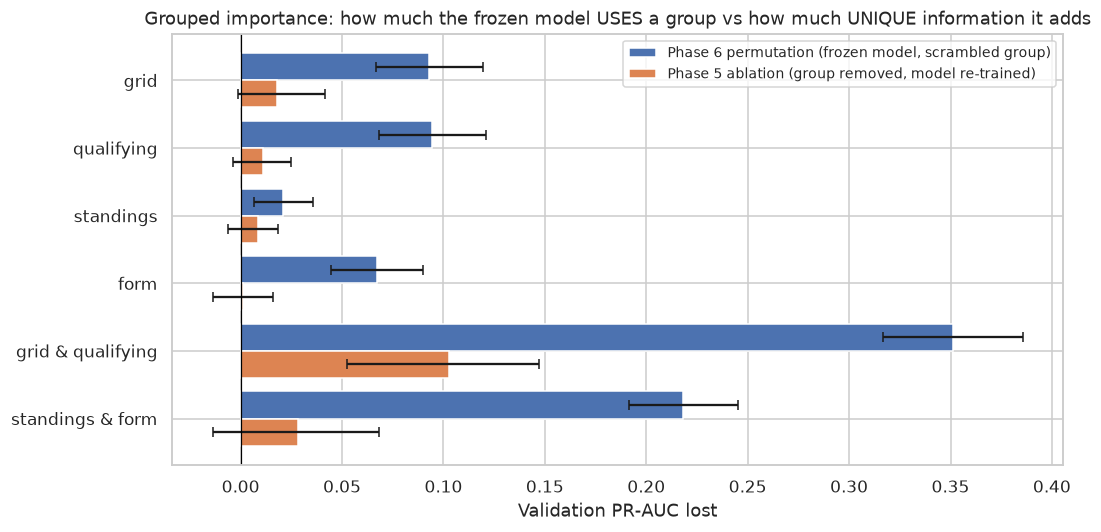

In [75]:
# -----------------------------
# 12.2b — Grouped permutation importance + comparison with the Phase 5 ablation
# -----------------------------
PERM_GROUPS = {
    "grid": FEATURE_GROUPS["grid"],
    "qualifying": FEATURE_GROUPS["qualifying"],
    "standings": FEATURE_GROUPS["standings"],
    "form": FEATURE_GROUPS["form"],
    "grid & qualifying": FEATURE_GROUPS["grid"] + FEATURE_GROUPS["qualifying"],
    "standings & form": FEATURE_GROUPS["standings"] + FEATURE_GROUPS["form"],
}

t0 = time.time()
group_rows = []
for group, cols in PERM_GROUPS.items():
    mean_drop, std_drop = permutation_drop(cols)
    row = {"group": group, "n_features": len(cols),
           "permutation drop (frozen model)": mean_drop, "permutation sd": std_drop}
    # Phase 5 ablation numbers exist for the soft-voting ensemble (ens_table, §11.1).
    variant = f"− {group}"
    if XAI_MODEL_NAME == ENSEMBLE_NAME and variant in ens_table.index:
        row["ablation drop (re-trained)"] = ens_table.loc[variant, "drop validation"]
        row["ablation CI low"] = ens_table.loc[variant, "drop validation CI low"]
        row["ablation CI high"] = ens_table.loc[variant, "drop validation CI high"]
    group_rows.append(row)

group_importance = pd.DataFrame(group_rows).set_index("group")
HAS_ABLATION = "ablation drop (re-trained)" in group_importance
if HAS_ABLATION:
    group_importance["recovered by re-training"] = (
        group_importance["permutation drop (frozen model)"] - group_importance["ablation drop (re-trained)"])
print(f"Grouped permutation finished in {time.time() - t0:.0f}s  (validation PR-AUC baseline {xai_val_baseline:.3f})")
display(group_importance.style.format("{:+.4f}", subset=[c for c in group_importance.columns if c != "n_features"]))

# Side-by-side plot
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(group_importance))
ax.barh(y_pos - 0.2, group_importance["permutation drop (frozen model)"], height=0.4,
        xerr=group_importance["permutation sd"], capsize=3, color="#4C72B0",
        label="Phase 6 permutation (frozen model, scrambled group)")
if HAS_ABLATION:
    gi = group_importance
    ax.barh(y_pos + 0.2, gi["ablation drop (re-trained)"], height=0.4,
            xerr=[gi["ablation drop (re-trained)"] - gi["ablation CI low"],
                  gi["ablation CI high"] - gi["ablation drop (re-trained)"]],
            capsize=3, color="#DD8452", label="Phase 5 ablation (group removed, model re-trained)")
ax.set_yticks(y_pos)
ax.set_yticklabels(group_importance.index)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Validation PR-AUC lost")
ax.set_title("Grouped importance: how much the frozen model USES a group vs how much UNIQUE information it adds")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

In [76]:
# -----------------------------
# 12.2b — Automatic reconciliation text (Phase 5 ablation vs Phase 6 permutation)
# -----------------------------
gi = group_importance
singles = ["grid", "qualifying", "standings", "form"]
P, S = "permutation drop (frozen model)", "permutation sd"
lines = [f"- **{g}**: permutation drop **{gi.loc[g, P]:+.3f}** (sd {gi.loc[g, S]:.3f})"
         + (f" vs ablation drop **{gi.loc[g, 'ablation drop (re-trained)']:+.3f}**" if HAS_ABLATION else "")
         for g in PERM_GROUPS]

ranked = gi.loc[singles, P].sort_values(ascending=False)
first, second = ranked.index[0], ranked.index[1]
tie = (ranked.iloc[0] - ranked.iloc[1]) < 2 * max(gi.loc[first, S], gi.loc[second, S])
leader_text = (f"`{first}` and `{second}` are statistically tied at the top ({ranked.iloc[0]:+.3f} vs {ranked.iloc[1]:+.3f}; "
               "the gap is smaller than the shuffle noise)" if tie else
               f"`{first}` ({ranked.iloc[0]:+.3f})")

text = ("### Grouped importance answer\n\n" + "\n".join(lines) + "\n\n"
        f"**What the frozen model uses most (single groups):** {leader_text}.\n\n")

# Redundancy signature: a pair costs more than its two parts together.
def pair_vs_parts(pair, a, b, col):
    return gi.loc[pair, col], gi.loc[a, col] + gi.loc[b, col]

pg, sg = pair_vs_parts("grid & qualifying", "grid", "qualifying", P)
text += (f"**Redundancy between grid and qualifying:** scrambling both together costs **{pg:+.3f}**, much more than the "
         f"sum of scrambling them one at a time ({sg:+.3f}). Each one partly stands in for the other, so a single-group "
         "score understates how much the model needs *starting position* as a whole.\n\n")

if HAS_ABLATION:
    from scipy.stats import spearmanr
    rho = spearmanr(gi[P], gi["ablation drop (re-trained)"]).correlation
    always_bigger = (gi[P] >= gi["ablation drop (re-trained)"]).all()
    pa, sa = pair_vs_parts("grid & qualifying", "grid", "qualifying", "ablation drop (re-trained)")
    g = gi.loc["grid"]
    text += (
        "**Reconciling Phase 5 (ablation) with Phase 6 (permutation).**\n\n"
        f"1. *The two methods agree on the ranking.* Across the six groups and pairs, the Spearman correlation between "
        f"the permutation drop and the ablation drop is **{rho:+.2f}**. Both put **grid & qualifying** clearly first, and "
        f"both show the same redundancy signature: the ablation pair drop ({pa:+.3f}) is also far larger than the sum of the "
        f"single ablations ({sa:+.3f}).\n"
        f"2. *The permutation numbers are {'always ' if always_bigger else ''}larger, and that is expected.* Example: scrambling "
        f"grid costs {g[P]:+.3f}, but removing grid and re-training costs only {g['ablation drop (re-trained)']:+.3f}. "
        "A **re-trained** model adapts: without grid it shifts its weight onto qualifying, and without grid *and* qualifying it "
        "shifts onto standings and form, which also describe car pace. The **frozen** model cannot adapt. It still trusts the "
        "scrambled column, and the shuffle creates contradictory rows (a front-row grid slot for a driver with poor "
        "qualifying and poor standings), so it is actively misled, not just left without information.\n"
        "3. *So they measure different things.* Permutation importance = **how much this fitted model relies on the group**. "
        "Ablation = **how much unique information the group adds that no other group can replace**. A large permutation "
        "drop with a small ablation drop (e.g. `form`) means: the model uses it, but the same signal is available elsewhere "
        "(here, in the standings).\n\n")
text += "*These are statements about what the model relies on, not about what causes podiums.*"
display(Markdown(text))

### Grouped importance answer

- **grid**: permutation drop **+0.093** (sd 0.026) vs ablation drop **+0.018**
- **qualifying**: permutation drop **+0.095** (sd 0.026) vs ablation drop **+0.011**
- **standings**: permutation drop **+0.021** (sd 0.014) vs ablation drop **+0.008**
- **form**: permutation drop **+0.067** (sd 0.023) vs ablation drop **+0.001**
- **grid & qualifying**: permutation drop **+0.351** (sd 0.034) vs ablation drop **+0.103**
- **standings & form**: permutation drop **+0.218** (sd 0.027) vs ablation drop **+0.028**

**What the frozen model uses most (single groups):** `qualifying` and `grid` are statistically tied at the top (+0.095 vs +0.093; the gap is smaller than the shuffle noise).

**Redundancy between grid and qualifying:** scrambling both together costs **+0.351**, much more than the sum of scrambling them one at a time (+0.187). Each one partly stands in for the other, so a single-group score understates how much the model needs *starting position* as a whole.

**Reconciling Phase 5 (ablation) with Phase 6 (permutation).**

1. *The two methods agree on the ranking.* Across the six groups and pairs, the Spearman correlation between the permutation drop and the ablation drop is **+0.89**. Both put **grid & qualifying** clearly first, and both show the same redundancy signature: the ablation pair drop (+0.103) is also far larger than the sum of the single ablations (+0.029).
2. *The permutation numbers are always larger, and that is expected.* Example: scrambling grid costs +0.093, but removing grid and re-training costs only +0.018. A **re-trained** model adapts: without grid it shifts its weight onto qualifying, and without grid *and* qualifying it shifts onto standings and form, which also describe car pace. The **frozen** model cannot adapt. It still trusts the scrambled column, and the shuffle creates contradictory rows (a front-row grid slot for a driver with poor qualifying and poor standings), so it is actively misled, not just left without information.
3. *So they measure different things.* Permutation importance = **how much this fitted model relies on the group**. Ablation = **how much unique information the group adds that no other group can replace**. A large permutation drop with a small ablation drop (e.g. `form`) means: the model uses it, but the same signal is available elsewhere (here, in the standings).

*These are statements about what the model relies on, not about what causes podiums.*

## 12.3 · Global explanation 2 — SHAP

Permutation importance asks, *"How much predictive performance is lost if this information is destroyed?"*
SHAP asks:

> **How much does each feature push individual predictions above or below the model's background prediction?**

For each explained driver-race:

* a **positive SHAP value** pushes the predicted podium probability upward;
* a **negative SHAP value** pushes it downward;
* the SHAP values of one row **add up exactly** to (that row's probability − the background average probability).

For the global summary we average the **absolute SHAP values** across a reproducible validation sample.

### Sampling choice (and why it is larger than a minimal setting)

Model-agnostic SHAP calls the whole ensemble many times, so we explain a sample:

* **100 training rows** as the background ("what does an average driver-race look like?");
* **200 validation rows** to explain (a random sample, so it contains roughly the validation podium rate of ~15%; the exact podium count is printed);
* **3 permutation passes per row** (`max_evals = 3 × (2·17 + 1) = 105`). One pass gives exact additivity, but the split of credit between correlated features (grid vs qualifying) depends on the random feature order; averaging 3 orders makes it much more stable.

To show that the ranking is **stable, not a sampling accident**, we bootstrap the 200 explained rows 1,000 times and report a 95% interval for each feature's mean |SHAP| and its rank.

SHAP: 200 validation rows × 3 permutation passes (background 100 training rows) in 411s; 24 podiums in the explained sample


,feature,mean_abs_shap,ci_low,ci_high,rank_best (95%),rank_worst (95%)
0,quali_position,0.0458,0.0412,0.0509,1,1
1,grid_model,0.0431,0.0379,0.0487,2,2
2,driver_podium_rate_last5,0.0280,0.0243,0.0316,3,3
3,gap_to_fastest_quali_pct,0.0153,0.0134,0.0173,4,5
4,constructor_avg_finish_last5,0.0139,0.0125,0.0152,4,5
5,constructor_points_per_round_before,0.0107,0.0097,0.0118,6,6
6,constructor_podium_rate_last5,0.0097,0.0088,0.0107,7,7
7,driver_standing_pos_before,0.0085,0.0074,0.0097,8,8
8,constructor_standing_pos_before,0.0067,0.0062,0.0073,9,9
9,driver_avg_finish_last5,0.0058,0.0051,0.0065,10,11


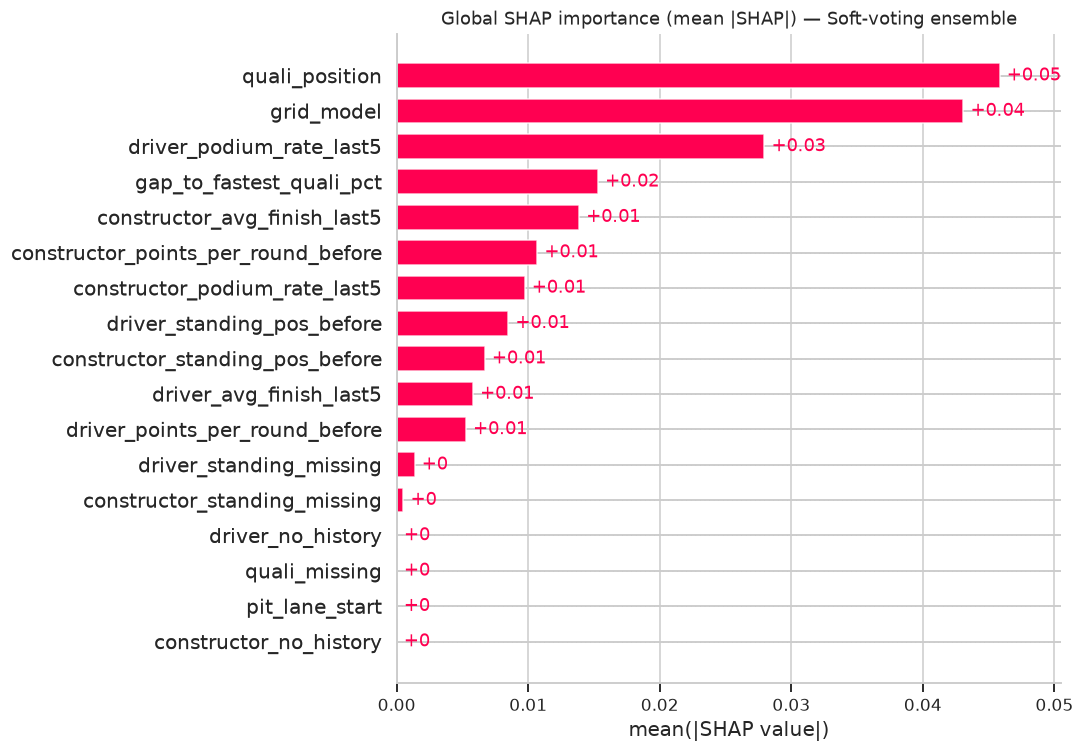

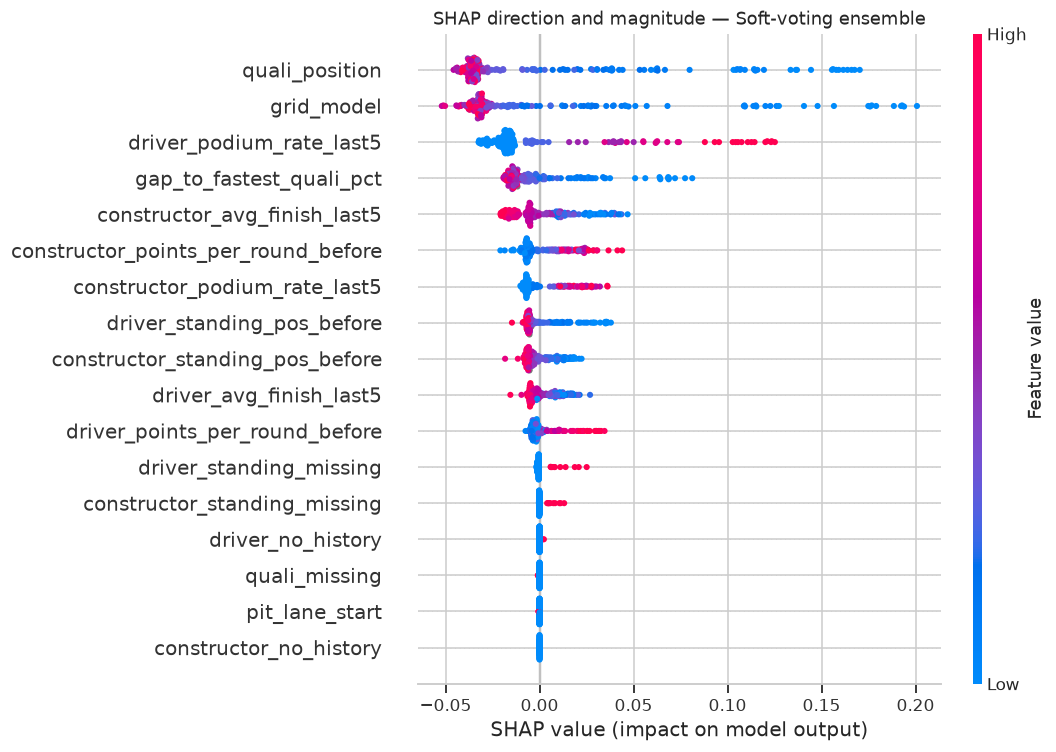

In [77]:
# -----------------------------
# 12.3 — Model-agnostic SHAP for the selected model
# -----------------------------
N_SHAP_BACKGROUND = min(100, len(X_train))
N_SHAP_GLOBAL = min(200, len(X_val))
SHAP_PASSES = 3
SHAP_MAX_EVALS = SHAP_PASSES * (2 * len(FEATURE_COLUMNS) + 1)

shap_background = X_train.sample(n=N_SHAP_BACKGROUND, random_state=SEED).copy()   # training rows only
shap_global_X = X_val.sample(n=N_SHAP_GLOBAL, random_state=SEED).copy()

masker = shap.maskers.Independent(shap_background, max_samples=N_SHAP_BACKGROUND)
shap_explainer = shap.Explainer(xai_predict, masker, algorithm="permutation",
                                feature_names=FEATURE_COLUMNS, seed=SEED)

t0 = time.time()
shap_global = shap_explainer(shap_global_X, max_evals=SHAP_MAX_EVALS, batch_size=512, silent=True)
print(f"SHAP: {N_SHAP_GLOBAL} validation rows × {SHAP_PASSES} permutation passes "
      f"(background {N_SHAP_BACKGROUND} training rows) in {time.time() - t0:.0f}s; "
      f"{int(y_val_np[X_val.index.get_indexer(shap_global_X.index)].sum())} podiums in the explained sample")
assert shap_global.values.shape == (N_SHAP_GLOBAL, len(FEATURE_COLUMNS))

# Additivity check: base value + sum of SHAP values must reproduce the model's probability.
recon = shap_global.base_values + shap_global.values.sum(axis=1)
assert np.allclose(recon, xai_predict(shap_global_X), atol=1e-6), "SHAP additivity failed"

# Global SHAP magnitude + bootstrap stability over the explained rows.
abs_vals = np.abs(shap_global.values)
boot_rng = np.random.default_rng(SEED)
boot_means = np.array([abs_vals[boot_rng.integers(0, len(abs_vals), len(abs_vals))].mean(axis=0)
                       for _ in range(1000)])
boot_ranks = (-boot_means).argsort(axis=1).argsort(axis=1) + 1          # rank 1 = most important
shap_importance = (pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "mean_abs_shap": abs_vals.mean(axis=0),
        "ci_low": np.percentile(boot_means, 2.5, axis=0),
        "ci_high": np.percentile(boot_means, 97.5, axis=0),
        "rank_best (95%)": np.percentile(boot_ranks, 2.5, axis=0).astype(int),
        "rank_worst (95%)": np.percentile(boot_ranks, 97.5, axis=0).astype(int),
    })
    .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
display(shap_importance.style.format({"mean_abs_shap": "{:.4f}", "ci_low": "{:.4f}", "ci_high": "{:.4f}"}))

shap.plots.bar(shap_global, max_display=len(FEATURE_COLUMNS), show=False)
plt.gcf().set_size_inches(10, 7)
plt.title(f"Global SHAP importance (mean |SHAP|) — {XAI_MODEL_NAME}")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(shap_global, max_display=len(FEATURE_COLUMNS), show=False)
plt.gcf().set_size_inches(10, 7)
plt.title(f"SHAP direction and magnitude — {XAI_MODEL_NAME}")
plt.tight_layout()
plt.show()

### How to read the SHAP outputs

**Table.** `ci_low`/`ci_high` is the 95% bootstrap interval of mean |SHAP|; `rank_best`/`rank_worst` is the range of ranks the feature takes across 1,000 bootstrap resamples. A feature whose rank interval is narrow (e.g. 1–2) is a **stable** finding. Features near the bottom often swap places; their exact order should not be interpreted.

**Bar plot.** Ranks features by average |SHAP value|: which inputs usually move predictions the most, regardless of direction.

**Beeswarm plot.** Each dot is one explained validation driver-race.

* Horizontal position = SHAP contribution: right of zero pushes the podium probability **up**, left pushes it **down**.
* Dot colour = the feature's actual value (red = high, blue = low).
* Example of expected behaviour: for `grid_model` and `quali_position`, **blue dots (low numbers = front of the grid) sit on the right**. Starting near the front raises the predicted probability, which is the sensible direction.

The plot explains **the fitted model's behaviour**. It does not establish that a feature causes podium finishes.

## 12.4 · Do the global explanation methods agree?

Permutation importance and SHAP measure different things:

* **Permutation importance:** impact on the model's validation PR-AUC (performance-based).
* **SHAP:** average magnitude of the feature's contribution to individual probabilities (prediction-based).

They do not need identical rankings. Agreement strengthens the interpretation. Disagreement can come from feature redundancy, interactions, or the different targets of the two methods.

Because SHAP values are **additive**, we can also add up the SHAP values of all features in a group, giving a **group-level SHAP** importance that can be compared directly with the grouped permutation from §12.2b.

In [78]:
# -----------------------------
# 12.4 — Compare global rankings (feature level and group level)
# -----------------------------
global_xai = perm_importance.merge(shap_importance[["feature", "mean_abs_shap"]], on="feature", how="inner")
global_xai["permutation_rank"] = global_xai["pr_auc_drop_mean"].rank(method="min", ascending=False).astype(int)
global_xai["shap_rank"] = global_xai["mean_abs_shap"].rank(method="min", ascending=False).astype(int)
global_xai["rank_difference"] = (global_xai["permutation_rank"] - global_xai["shap_rank"]).abs()
global_rank_corr = global_xai[["pr_auc_drop_mean", "mean_abs_shap"]].corr(method="spearman").iloc[0, 1]
global_xai = global_xai.sort_values(["permutation_rank", "shap_rank"]).reset_index(drop=True)

print(f"Spearman agreement between the feature-level rankings: {global_rank_corr:+.2f}")
display(global_xai[["feature", "pr_auc_drop_mean", "permutation_rank", "mean_abs_shap", "shap_rank",
                    "rank_difference"]].style.format({"pr_auc_drop_mean": "{:+.4f}", "mean_abs_shap": "{:.4f}"}))

# Group-level SHAP: add the SHAP values of a group's columns row by row, then take mean |sum|.
col_idx = {c: i for i, c in enumerate(FEATURE_COLUMNS)}
group_shap = pd.Series({g: np.abs(shap_global.values[:, [col_idx[c] for c in cols]].sum(axis=1)).mean()
                        for g, cols in FEATURE_GROUPS.items()}, name="group mean |SHAP|")
group_compare = pd.concat([group_importance.loc[list(FEATURE_GROUPS), "permutation drop (frozen model)"], group_shap],
                          axis=1)
group_compare["permutation rank"] = group_compare["permutation drop (frozen model)"].rank(ascending=False).astype(int)
group_compare["SHAP rank"] = group_compare["group mean |SHAP|"].rank(ascending=False).astype(int)
group_ranks_agree = (group_compare["permutation rank"] == group_compare["SHAP rank"]).all()
print("Group level — do permutation and SHAP rank the 4 groups identically?", "YES" if group_ranks_agree else "NO")
display(group_compare.style.format({"permutation drop (frozen model)": "{:+.4f}", "group mean |SHAP|": "{:.4f}"}))

Spearman agreement between the feature-level rankings: +0.87


,feature,pr_auc_drop_mean,permutation_rank,mean_abs_shap,shap_rank,rank_difference
0,grid_model,+0.0929,1,0.0431,2,1
1,quali_position,+0.0582,2,0.0458,1,1
2,driver_podium_rate_last5,+0.0179,3,0.0280,3,0
3,gap_to_fastest_quali_pct,+0.0114,4,0.0153,4,0
4,constructor_avg_finish_last5,+0.0081,5,0.0139,5,0
5,driver_avg_finish_last5,+0.0048,6,0.0058,10,4
6,driver_standing_missing,+0.0017,7,0.0014,12,5
7,constructor_points_per_round_before,+0.0013,8,0.0107,6,2
8,constructor_podium_rate_last5,+0.0012,9,0.0097,7,2
9,constructor_standing_missing,+0.0009,10,0.0005,13,3


Group level — do permutation and SHAP rank the 4 groups identically? NO


,permutation drop (frozen model),group mean |SHAP|,permutation rank,SHAP rank
grid,+0.0930,0.0431,2,3
qualifying,+0.0945,0.0597,1,1
standings,+0.0210,0.0286,4,4
form,+0.0674,0.0514,3,2


## 12.5 · Local explanation — two individual test predictions (SHAP)

A global plot answers *"what does the model generally use?"* A local explanation answers:

> **Why did the model produce this probability for this particular driver-race?**

We explain **two** test rows, both chosen **only from the model's predicted probability** (the true result is revealed afterwards):

* **Example A — most confident:** the test row with the highest predicted podium probability. It shows what a "clear podium" looks like to the model.
* **Example B — borderline:** the test row whose probability is **closest to the frozen decision threshold**. This is the more informative case, because small changes in a feature could flip the decision; it shows which features the model weighs against each other.

Each waterfall starts at the model's average prediction on the background data, `E[f(X)]`, and adds one feature's contribution at a time until it reaches the final probability `f(x)`. For single rows we use 10 permutation passes, because one row is cheap to explain.

Example A — most confident  (selected before looking at the true outcome)
  Max Verstappen — 2023 Monaco Grand Prix (round 6)   [raceId=1104, driverId=830]
  predicted podium probability = 84.2%  |  frozen threshold = 0.396
  predicted class = podium  |  actual outcome = podium


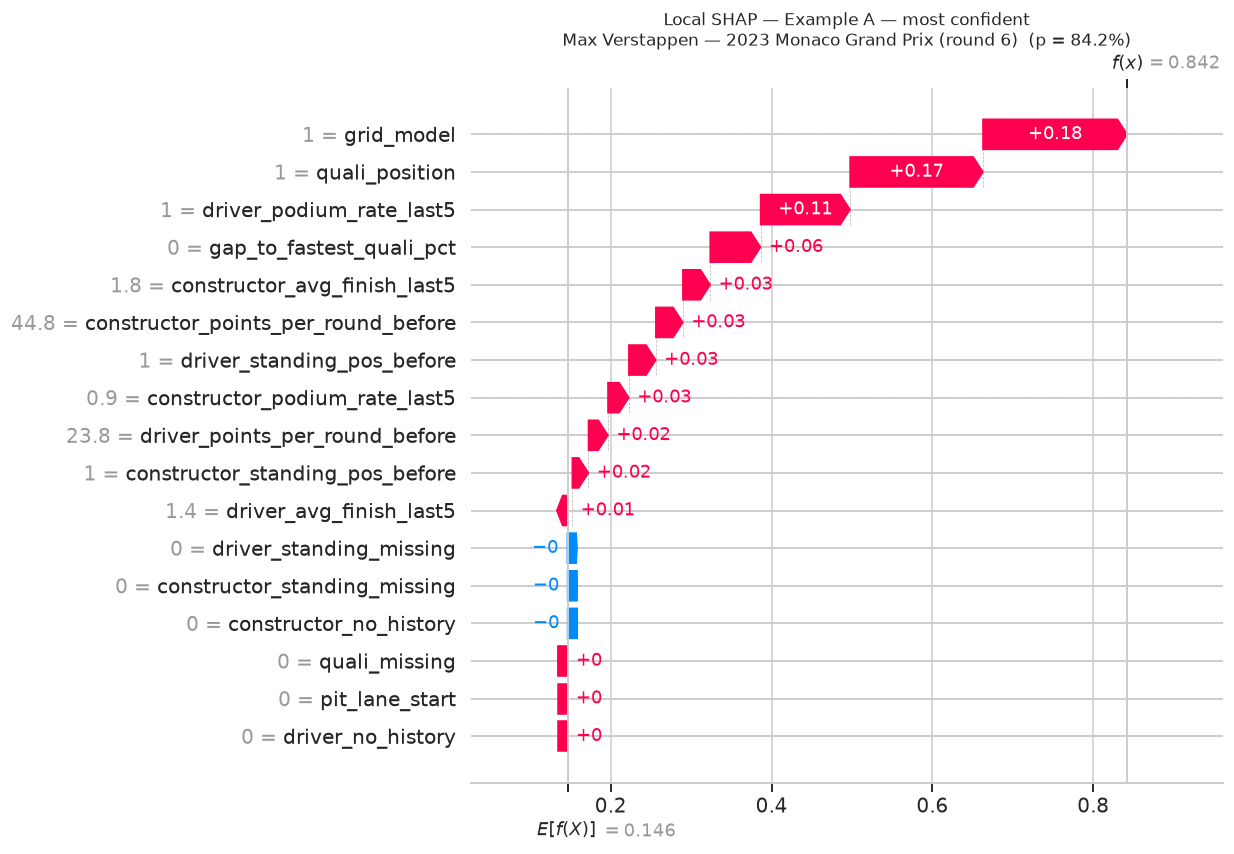

,feature,feature_value,shap_value,abs_shap,direction
0,grid_model,1.000,+0.1794,0.1794,pushes probability up
1,quali_position,1.000,+0.1653,0.1653,pushes probability up
2,driver_podium_rate_last5,1.000,+0.1113,0.1113,pushes probability up
3,gap_to_fastest_quali_pct,0.000,+0.0627,0.0627,pushes probability up
4,constructor_avg_finish_last5,1.800,+0.0340,0.0340,pushes probability up
5,constructor_points_per_round_before,44.800,+0.0336,0.0336,pushes probability up
6,driver_standing_pos_before,1.000,+0.0335,0.0335,pushes probability up
7,constructor_podium_rate_last5,0.900,+0.0260,0.0260,pushes probability up


Example B — borderline  (selected before looking at the true outcome)
  Carlos Sainz — 2022 Singapore Grand Prix (round 17)   [raceId=1091, driverId=832]
  predicted podium probability = 39.3%  |  frozen threshold = 0.396
  predicted class = not podium  |  actual outcome = podium


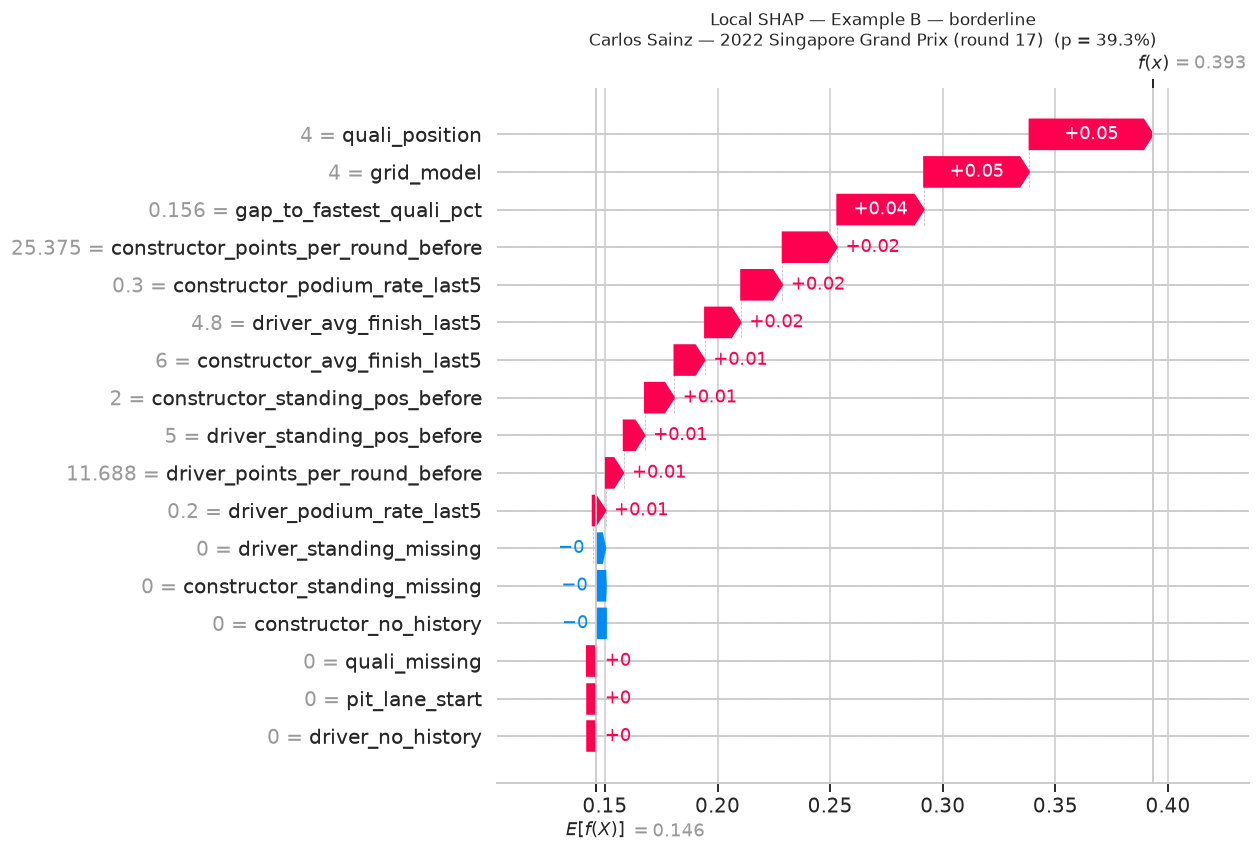

,feature,feature_value,shap_value,abs_shap,direction
0,quali_position,4.000,+0.0550,0.0550,pushes probability up
1,grid_model,4.000,+0.0468,0.0468,pushes probability up
2,gap_to_fastest_quali_pct,0.156,+0.0386,0.0386,pushes probability up
3,constructor_points_per_round_before,25.375,+0.0242,0.0242,pushes probability up
4,constructor_podium_rate_last5,0.300,+0.0184,0.0184,pushes probability up
5,driver_avg_finish_last5,4.800,+0.0160,0.0160,pushes probability up
6,constructor_avg_finish_last5,6.000,+0.0136,0.0136,pushes probability up
7,constructor_standing_pos_before,2.000,+0.0131,0.0131,pushes probability up


In [79]:
# -----------------------------
# 12.5 — Local SHAP explanations for two test predictions
# -----------------------------
LOCAL_MAX_EVALS = 10 * (2 * len(FEATURE_COLUMNS) + 1)

local_positions = {
    "A — most confident": int(np.argmax(xai_test_proba)),
    "B — borderline": int(np.argmin(np.abs(xai_test_proba - xai_threshold))),
}

local_examples = {}
for label, pos in local_positions.items():
    meta = test_df.iloc[pos]
    x_row = X_test.iloc[[pos]].copy()
    sv = shap_explainer(x_row, max_evals=LOCAL_MAX_EVALS, batch_size=512, silent=True)
    prob = float(xai_test_proba[pos])
    table = pd.DataFrame({"feature": FEATURE_COLUMNS,
                          "feature_value": x_row.iloc[0].to_numpy(),
                          "shap_value": sv.values[0]})
    table["abs_shap"] = table["shap_value"].abs()
    table["direction"] = np.where(table["shap_value"] >= 0, "pushes probability up", "pushes probability down")
    table = table.sort_values("abs_shap", ascending=False).reset_index(drop=True)
    local_examples[label] = {"pos": pos, "meta": meta, "who": describe_driver_race(meta["raceId"], meta["driverId"]),
                             "prob": prob, "pred": int(prob >= xai_threshold), "actual": int(y_test_np[pos]),
                             "shap": sv[0], "table": table}

    ex = local_examples[label]
    print(f"Example {label}  (selected before looking at the true outcome)")
    print(f"  {ex['who']}   [raceId={meta['raceId']}, driverId={meta['driverId']}]")
    print(f"  predicted podium probability = {prob:.1%}  |  frozen threshold = {xai_threshold:.3f}")
    print(f"  predicted class = {'podium' if ex['pred'] else 'not podium'}  |  "
          f"actual outcome = {'podium' if ex['actual'] else 'not podium'}")

    shap.plots.waterfall(sv[0], max_display=len(FEATURE_COLUMNS), show=False)
    fig = plt.gcf()
    fig.set_size_inches(12, 8)                      # wide enough that feature labels are not clipped
    plt.title(f"Local SHAP — Example {label}\n{ex['who']}  (p = {prob:.1%})", fontsize=11)
    plt.subplots_adjust(left=0.38, right=0.95, top=0.90)
    plt.show()
    display(table.head(8).style.format({"feature_value": "{:.3f}", "shap_value": "{:+.4f}", "abs_shap": "{:.4f}"}))

# Backward-compatible names used by the summary cell.
local_explanation = local_examples["A — most confident"]["table"]
local_meta = local_examples["A — most confident"]["meta"]
local_probability = local_examples["A — most confident"]["prob"]
local_threshold = xai_threshold

## 12.6 · Local explanation 2 — LIME (a second, independent local method)

**LIME** (Local Interpretable Model-agnostic Explanations) works differently from SHAP:

1. It creates ~5,000 **fake neighbours** of the explained row by randomly perturbing its feature values (sampled from the training-data distribution).
2. It asks the frozen model for the podium probability of every neighbour.
3. It fits a small **weighted linear model** to those answers, giving more weight to neighbours that look most like the explained row.
4. The coefficients of that small linear model are the explanation, written as readable rules such as `grid_model <= 4.00 → +0.21`.

So SHAP answers *"how is this exact prediction split fairly between the features?"*, while LIME answers *"in the neighbourhood of this row, which simple rules best imitate the model?"*. If both methods name the **same top features with the same direction**, the local explanation is trustworthy. If they disagree, we should be careful.

**Two technical details:**

* LIME cannot sample from columns that contain `NaN`, so we give it the training data with numeric gaps filled by the **training medians**. That is exactly what every model pipeline's `SimpleImputer` already does internally, so the model sees the same values. We **assert** that the explained probability does not change.
* The six 0/1 flags are declared as **categorical**, so LIME only generates 0 or 1 for them (never impossible values like 0.37).

`score` is the R² of LIME's local linear fit: how well the simple surrogate imitates the model near this row. A low R² means the explanation should be read with caution.

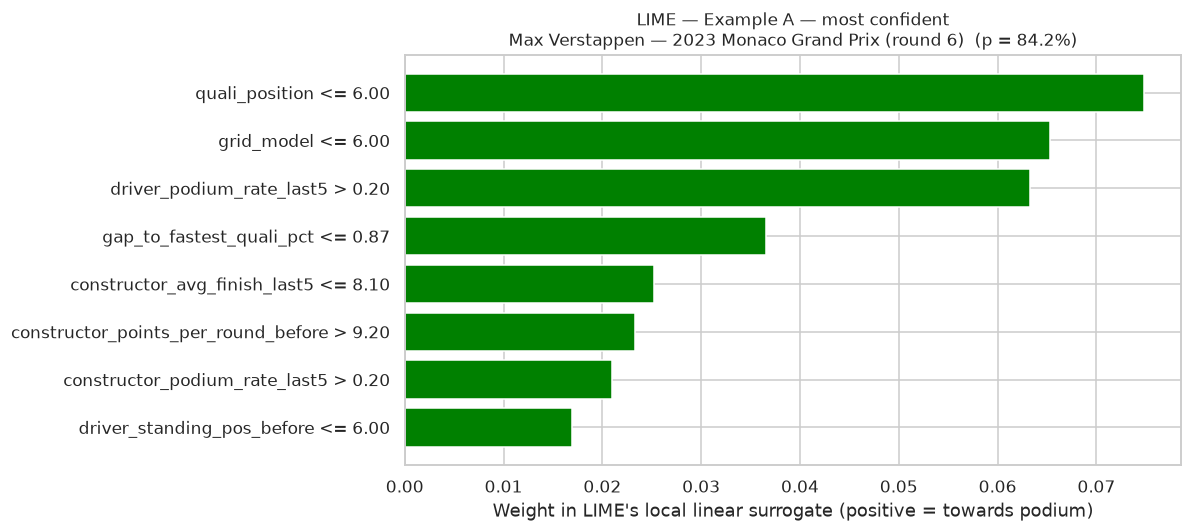

,LIME rule,feature,weight
0,quali_position <= 6.00,quali_position,+0.0749
1,grid_model <= 6.00,grid_model,+0.0653
2,driver_podium_rate_last5 > 0.20,driver_podium_rate_last5,+0.0633
3,gap_to_fastest_quali_pct <= 0.87,gap_to_fastest_quali_pct,+0.0366
4,constructor_avg_finish_last5 <= 8.10,constructor_avg_finish_last5,+0.0253
5,constructor_points_per_round_before > 9.20,constructor_points_per_round_before,+0.0233
6,constructor_podium_rate_last5 > 0.20,constructor_podium_rate_last5,+0.0209
7,driver_standing_pos_before <= 6.00,driver_standing_pos_before,+0.0169


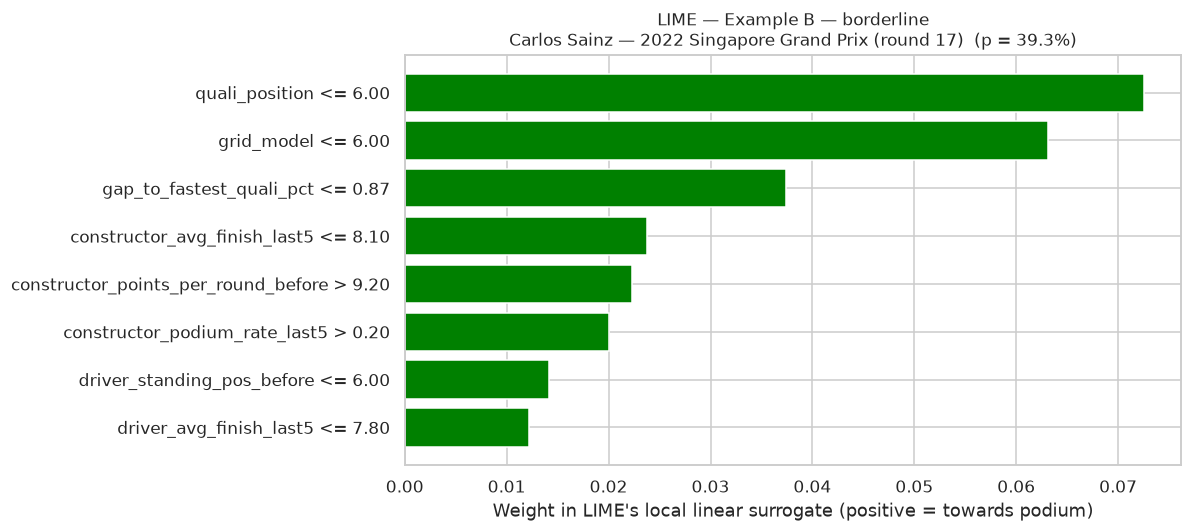

,LIME rule,feature,weight
0,quali_position <= 6.00,quali_position,+0.0726
1,grid_model <= 6.00,grid_model,+0.0631
2,gap_to_fastest_quali_pct <= 0.87,gap_to_fastest_quali_pct,+0.0374
3,constructor_avg_finish_last5 <= 8.10,constructor_avg_finish_last5,+0.0237
4,constructor_points_per_round_before > 9.20,constructor_points_per_round_before,+0.0223
5,constructor_podium_rate_last5 > 0.20,constructor_podium_rate_last5,+0.0200
6,driver_standing_pos_before <= 6.00,driver_standing_pos_before,+0.0142
7,driver_avg_finish_last5 <= 7.80,driver_avg_finish_last5,+0.0122


LIME vs local SHAP:


,who,model probability,LIME local R²,top-5 overlap with SHAP,same direction (of shared)
example,,,,,
A — most confident,Max Verstappen — 2023 Monaco Grand Prix (round 6),84.2%,0.67,5/5,5/5
B — borderline,Carlos Sainz — 2022 Singapore Grand Prix (round 17),39.3%,0.58,4/5,4/4


In [80]:
# -----------------------------
# 12.6 — LIME on the same two test predictions
# -----------------------------
TRAIN_MEDIANS = X_train[NUMERIC_FEATURES].median()

def fill_like_pipeline(X):
    """Fill numeric NaN with TRAINING medians (identical to the pipelines' SimpleImputer)."""
    out = X.copy()
    out[NUMERIC_FEATURES] = out[NUMERIC_FEATURES].fillna(TRAIN_MEDIANS)
    return out

lime_train = fill_like_pipeline(X_train)
binary_idx = [FEATURE_COLUMNS.index(c) for c in BINARY_FEATURES]

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=lime_train.to_numpy(dtype=float),
    feature_names=FEATURE_COLUMNS,
    class_names=["no podium", "podium"],
    categorical_features=binary_idx,
    mode="classification",
    discretize_continuous=True,
    random_state=SEED,
)

def lime_predict_fn(Z):
    p = xai_predict(Z)
    return np.column_stack([1 - p, p])

N_LIME_FEATURES = 8
lime_rows = []
for label, ex in local_examples.items():
    x_filled = fill_like_pipeline(X_test.iloc[[ex["pos"]]])
    # Filling with training medians must not change the model's answer (the pipeline does the same).
    assert np.isclose(xai_predict(x_filled)[0], ex["prob"], atol=1e-9)

    exp = lime_explainer.explain_instance(x_filled.iloc[0].to_numpy(dtype=float), lime_predict_fn,
                                          num_features=N_LIME_FEATURES, num_samples=5000, labels=(1,))
    lime_weights = pd.DataFrame(exp.as_list(label=1), columns=["LIME rule", "weight"])
    lime_weights["feature"] = [FEATURE_COLUMNS[i] for i, _ in exp.as_map()[1]]
    ex["lime"] = lime_weights
    ex["lime_score"] = float(exp.score)

    # Agreement with local SHAP: overlap of top-5 features and sign agreement on the shared ones.
    shap_top = ex["table"].head(5).set_index("feature")["shap_value"]
    lime_top = lime_weights.head(5).set_index("feature")["weight"]
    shared = [f for f in lime_top.index if f in shap_top.index]
    same_sign = [f for f in shared if np.sign(lime_top[f]) == np.sign(shap_top[f])]
    ex["lime_vs_shap"] = {"top5_overlap": len(shared), "same_direction": len(same_sign), "shared": shared}
    lime_rows.append({"example": label, "who": ex["who"], "model probability": ex["prob"],
                      "LIME local R²": ex["lime_score"], "top-5 overlap with SHAP": f"{len(shared)}/5",
                      "same direction (of shared)": f"{len(same_sign)}/{len(shared)}"})

    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(11, 5)
    plt.title(f"LIME — Example {label}\n{ex['who']}  (p = {ex['prob']:.1%})", fontsize=11)
    plt.xlabel("Weight in LIME's local linear surrogate (positive = towards podium)")
    plt.tight_layout()
    plt.show()
    display(lime_weights[["LIME rule", "feature", "weight"]].style.format({"weight": "{:+.4f}"}))

lime_summary = pd.DataFrame(lime_rows).set_index("example")
print("LIME vs local SHAP:")
display(lime_summary.style.format({"model probability": "{:.1%}", "LIME local R²": "{:.2f}"}))

### How to read LIME, and how it compares with SHAP

* Each bar is a **rule** (a condition on one feature) with a weight. Green/positive weights push towards **podium**, red/negative towards **no podium**.
* The rules are written for **this row only**. `grid_model <= 4.00` means "being in the front of the grid, as this driver is"; it is **not** a global law.
* LIME weights and SHAP values are on **different scales** (LIME weights are coefficients of a surrogate, SHAP values are exact shares of the probability), so we compare **which features** appear and **in which direction**, not the exact numbers.
* LIME is **less stable** than SHAP: it depends on random neighbours and on how continuous features are cut into bins. That is why we fix `random_state` and use it as a **cross-check** of the SHAP explanation, not as the main explanation.

## 12.7 · Automatic interpretation and saved XAI outputs

The cell below turns the computed results into a short, data-driven explanation.
It deliberately uses words such as **"relies on"**, **"contributes"**, and **"pushes the prediction"** rather than causal language such as *"causes"*.

We also save every numeric explanation table so the report can reproduce the exact rankings and local explanations.

In [81]:
# -----------------------------
# 12.7 — Automatic XAI interpretation + save outputs
# -----------------------------
top_perm = perm_importance.iloc[0]
top_shap = shap_importance.iloc[0]
top5_perm = perm_importance.head(5)["feature"].tolist()
top5_shap = shap_importance.head(5)["feature"].tolist()
top5_overlap = [f for f in top5_perm if f in top5_shap]
agreement_text = ("strong" if global_rank_corr >= 0.70 else "moderate" if global_rank_corr >= 0.40 else "limited")

MATERIAL_SHAP = 0.005          # contributions smaller than half a percentage point are reported as "none of material size"

def feature_list_text(df):
    df = df[df["shap_value"].abs() >= MATERIAL_SHAP]
    if df.empty:
        return f"none of material size (all below {MATERIAL_SHAP})"
    return ", ".join(f"`{r.feature}` ({r.shap_value:+.3f})" for r in df.itertuples())

def local_paragraph(label):
    ex = local_examples[label]
    t = ex["table"]
    up = t[t["shap_value"] > 0].head(3)
    down = t[t["shap_value"] < 0].head(3)
    lv = ex["lime_vs_shap"]
    return (f"**Local example {label}:** {ex['who']} receives a predicted podium probability of "
            f"**{ex['prob']:.1%}** versus the frozen threshold **{xai_threshold:.3f}** "
            f"(predicted: {'podium' if ex['pred'] else 'no podium'}; actual: {'podium' if ex['actual'] else 'no podium'}). "
            f"SHAP: strongest upward contributions {feature_list_text(up)}; strongest downward contributions "
            f"{feature_list_text(down)}. LIME shares **{lv['top5_overlap']}/5** of SHAP's top-5 features and agrees "
            f"on the direction for **{lv['same_direction']}/{lv['top5_overlap']}** of them "
            f"(LIME local R² = {ex['lime_score']:.2f}).\n\n")

stable_top = shap_importance[shap_importance["rank_worst (95%)"] <= 3]["feature"].tolist()
display(Markdown(
    "### Phase 6 answer\n\n"
    f"**Model explained:** `{XAI_MODEL_NAME}`, the model already selected in Phase 4. "
    "Phase 6 does not re-fit or re-select it.\n\n"
    f"**Permutation importance (features):** `{top_perm['feature']}` produces the largest average validation "
    f"PR-AUC drop when shuffled (**{top_perm['pr_auc_drop_mean']:+.4f}**).\n\n"
    f"**Permutation importance (groups):** scrambling grid + qualifying together costs "
    f"**{group_importance.loc['grid & qualifying', 'permutation drop (frozen model)']:+.3f}** PR-AUC, by far the largest "
    "group effect. "
    + ("Phase 5 ablation ranks the groups the same way but with smaller drops, because a re-trained model can recover "
       "the signal from redundant groups. The frozen model cannot, so permutation measures *reliance* and ablation "
       "measures *irreplaceable information* (§12.2b).\n\n" if HAS_ABLATION else "\n\n")
    + f"**Global SHAP:** `{top_shap['feature']}` has the largest mean |SHAP| (**{top_shap['mean_abs_shap']:.4f}**) on "
    f"{N_SHAP_GLOBAL} validation rows. Features whose rank stays in the top 3 in 95% of bootstrap resamples: "
    f"{', '.join(f'`{f}`' for f in stable_top) if stable_top else 'none'}. "
    f"Top-five overlap between permutation and SHAP is **{len(top5_overlap)}/5**, and their rank correlation is "
    f"**{global_rank_corr:+.2f}** ({agreement_text} agreement). At group level, "
    + ("the two methods rank the four groups **identically**.\n\n" if group_ranks_agree else
       "the two methods agree on " + (", ".join(f"`{g}` (rank {int(r['SHAP rank'])})" for g, r in group_compare.iterrows()
                                               if r['SHAP rank'] == r['permutation rank']) or "no group")
       + " and swap the others ("
       + ", ".join(f"`{g}`: permutation #{int(r['permutation rank'])} vs SHAP #{int(r['SHAP rank'])}"
                   for g, r in group_compare.iterrows() if r['SHAP rank'] != r['permutation rank'])
       + "). This is expected: grouped permutation measures lost *ranking performance* on validation, "
         "group SHAP measures how far the group moves *probabilities*.\n\n")
    + "".join(local_paragraph(lbl) for lbl in local_examples)
    + "**Interpretation boundary:** these values describe associations inside the fitted prediction model. "
    "They do **not** prove that manipulating any feature would cause or prevent a podium. For example, a driver does not "
    "become more likely to finish on the podium *because* of a number in the grid column; the grid reflects car and driver "
    "pace, which is what actually produces the result."
))

# Save tables for report writing and reproducibility.
perm_importance.to_csv(OUT_DIR / "xai_permutation_importance.csv", index=False)
group_importance.to_csv(OUT_DIR / "xai_grouped_permutation_vs_ablation.csv")
shap_importance.to_csv(OUT_DIR / "xai_shap_global_importance.csv", index=False)
global_xai.to_csv(OUT_DIR / "xai_global_method_comparison.csv", index=False)
group_compare.to_csv(OUT_DIR / "xai_group_level_comparison.csv")
for label, ex in local_examples.items():
    tag = "A" if label.startswith("A") else "B"
    ex["table"].to_csv(OUT_DIR / f"xai_local_shap_example_{tag}.csv", index=False)
    ex["lime"].to_csv(OUT_DIR / f"xai_local_lime_example_{tag}.csv", index=False)
lime_summary.to_csv(OUT_DIR / "xai_lime_vs_shap_summary.csv")
print("✅ Saved Phase 6 XAI tables to", OUT_DIR)

### Phase 6 answer

**Model explained:** `Soft-voting ensemble`, the model already selected in Phase 4. Phase 6 does not re-fit or re-select it.

**Permutation importance (features):** `grid_model` produces the largest average validation PR-AUC drop when shuffled (**+0.0929**).

**Permutation importance (groups):** scrambling grid + qualifying together costs **+0.351** PR-AUC, by far the largest group effect. Phase 5 ablation ranks the groups the same way but with smaller drops, because a re-trained model can recover the signal from redundant groups. The frozen model cannot, so permutation measures *reliance* and ablation measures *irreplaceable information* (§12.2b).

**Global SHAP:** `quali_position` has the largest mean |SHAP| (**0.0458**) on 200 validation rows. Features whose rank stays in the top 3 in 95% of bootstrap resamples: `quali_position`, `grid_model`, `driver_podium_rate_last5`. Top-five overlap between permutation and SHAP is **5/5**, and their rank correlation is **+0.87** (strong agreement). At group level, the two methods agree on `qualifying` (rank 1), `standings` (rank 4) and swap the others (`grid`: permutation #2 vs SHAP #3, `form`: permutation #3 vs SHAP #2). This is expected: grouped permutation measures lost *ranking performance* on validation, group SHAP measures how far the group moves *probabilities*.

**Local example A — most confident:** Max Verstappen — 2023 Monaco Grand Prix (round 6) receives a predicted podium probability of **84.2%** versus the frozen threshold **0.396** (predicted: podium; actual: podium). SHAP: strongest upward contributions `grid_model` (+0.179), `quali_position` (+0.165), `driver_podium_rate_last5` (+0.111); strongest downward contributions none of material size (all below 0.005). LIME shares **5/5** of SHAP's top-5 features and agrees on the direction for **5/5** of them (LIME local R² = 0.67).

**Local example B — borderline:** Carlos Sainz — 2022 Singapore Grand Prix (round 17) receives a predicted podium probability of **39.3%** versus the frozen threshold **0.396** (predicted: no podium; actual: podium). SHAP: strongest upward contributions `quali_position` (+0.055), `grid_model` (+0.047), `gap_to_fastest_quali_pct` (+0.039); strongest downward contributions none of material size (all below 0.005). LIME shares **4/5** of SHAP's top-5 features and agrees on the direction for **4/4** of them (LIME local R² = 0.58).

**Interpretation boundary:** these values describe associations inside the fitted prediction model. They do **not** prove that manipulating any feature would cause or prevent a podium. For example, a driver does not become more likely to finish on the podium *because* of a number in the grid column; the grid reflects car and driver pace, which is what actually produces the result.

✅ Saved Phase 6 XAI tables to clean


## ✅ Phase 6 summary — PDF checklist

| Requirement | Status | Where |
|---|---|---|
| Global permutation importance | ✅ per feature **and** per feature group | §12.2, §12.2b |
| Global SHAP explanation | ✅ 200 rows × 3 passes, bootstrap rank stability | §12.3 |
| Global plots interpreted | ✅ | §12.2–§12.4 |
| Phase 5 ablation reconciled with Phase 6 permutation | ✅ | §12.2b |
| Local explanation (local SHAP) | ✅ two examples: most confident + borderline | §12.5 |
| Local explanation (**LIME**) | ✅ same two examples, compared with SHAP | §12.6 |
| Local explanations interpreted | ✅ | §12.5–§12.7 |
| Explain selected Phase 4 model without re-selection | ✅ | §12.1 |
| Explicitly avoid causal claims | ✅ | Phase intro, §12.3, §12.7 |
| Save numeric XAI outputs | ✅ | §12.7 |

### Phase 6 conclusion

The global methods answer complementary questions: permutation importance measures how much predictive performance depends on each input (and each group), while SHAP decomposes how features move individual predicted probabilities. Comparing the grouped permutation with the Phase 5 ablation shows *why* a feature can matter a lot to the fitted model but add little unique information. The two local methods (SHAP and LIME) connect those global patterns to concrete driver-race predictions and cross-check each other.

**Important:** XAI explains the behaviour of the fitted model; it does not turn predictive associations into causal effects.

# 🏁 §13 · Inference function (Deliverable 7)

The PDF asks for an **inference function** that takes a new driver-race record and returns a podium prediction, demonstrated on **(a) a complete record** and **(b) a partially missing record**.

### What `predict_podium()` does, step by step

1. **Accepts** one record (`dict` or `pd.Series`) or many records (`pd.DataFrame`).
2. **Blocks leakage:** any post-race column (`position`, `points`, `laps`, `milliseconds`, … from `FORBIDDEN_SAME_RACE`) or the target `podium` makes it **raise an error**. Those values are unknown before the race, so accepting them would be cheating.
3. **Rejects unknown columns** (e.g. a typo such as `grid_postion`), because a silently ignored typo would produce a confident but wrong prediction.
4. **Re-orders** the columns into exactly `FEATURE_COLUMNS` and adds any missing feature as `NaN`.
5. **Validates types and ranges** (e.g. positions ≥ 1, podium rates between 0 and 1, gap ≥ 0). Text that is not a number raises an error instead of silently becoming `NaN`.
6. **Re-derives the missing-value flags** from the values, exactly as Phase 3 built them: `quali_missing = quali_position is missing`, `driver_no_history = driver_avg_finish_last5 is missing`, and so on. This keeps the flags consistent with the values (the model learned that `quali_missing = 1` always comes with an empty `quali_position`). If the caller sent a contradictory flag, it is corrected and a warning is recorded.
7. **Predicts** with the frozen Phase 4 pipeline. Missing **numeric** values are filled inside the pipeline by the **training medians** (the same `SimpleImputer` fitted in Phase 4), so no new statistics are computed at inference time.
8. **Applies the frozen Phase 4 threshold** to turn the probability into a yes/no decision.
9. **Reports honestly** which inputs were missing and were imputed, and adds a **reliability warning** when key information is missing (e.g. both grid and qualifying unknown).

It never re-fits anything, so a prediction made today is exactly reproducible later.

In [82]:
# -----------------------------
# 13.1 — The inference function
# -----------------------------
INFERENCE_MODEL_NAME = BEST_MODEL_NAME
INFERENCE_THRESHOLD = float(podium_thresholds[INFERENCE_MODEL_NAME])
INFERENCE_TRAIN_MEDIANS = X_train[NUMERIC_FEATURES].median()      # = what the pipeline imputers learned

# Flag  ->  the value column whose absence the flag records (same rules as Phase 3, §9.2–§9.4).
DERIVED_FLAGS = {
    "quali_missing": "quali_position",
    "driver_standing_missing": "driver_standing_pos_before",
    "constructor_standing_missing": "constructor_standing_pos_before",
    "driver_no_history": "driver_avg_finish_last5",
    "constructor_no_history": "constructor_avg_finish_last5",
}
# Plausible ranges (anything outside is a data-entry error, not a real driver-race).
VALID_RANGES = {
    "grid_model": (1, 40), "quali_position": (1, 40), "gap_to_fastest_quali_pct": (0, 100),
    "driver_points_per_round_before": (0, 60), "constructor_points_per_round_before": (0, 120),
    "driver_standing_pos_before": (1, 120), "constructor_standing_pos_before": (1, 40),
    "driver_avg_finish_last5": (1, 40), "constructor_avg_finish_last5": (1, 40),
    "driver_podium_rate_last5": (0, 1), "constructor_podium_rate_last5": (0, 1),
}
KEY_INFORMATION = {"starting position (grid + qualifying)": ["grid_model", "quali_position"]}
ALLOWED_EXTRA = set(METADATA_COLUMNS)          # identifiers may be passed along and are echoed back
FORBIDDEN_AT_INFERENCE = set(FORBIDDEN_SAME_RACE) | {TARGET}


def predict_podium(records, model_name=None, threshold=None):
    """Predict the podium probability for one or more driver-race records BEFORE the race starts.

    records    : dict / pd.Series (one record) or pd.DataFrame (many records).
                 Keys = any subset of FEATURE_COLUMNS (+ optional raceId, driverId, ... identifiers).
                 Missing features are allowed; they are imputed with the training medians.
    model_name : which fitted model to use (default: the Phase 4 selected model).
    threshold  : decision threshold (default: the frozen Phase 4 validation threshold of that model).

    Returns a DataFrame with one row per record: probability, decision, threshold, missing inputs, warnings.
    """
    model_name = model_name or INFERENCE_MODEL_NAME
    if model_name not in podium_models:
        raise KeyError(f"Unknown model '{model_name}'. Choose one of: {list(podium_models)}")
    model = podium_models[model_name]
    threshold = float(podium_thresholds[model_name] if threshold is None else threshold)

    # 1) accept dict / Series / DataFrame
    if isinstance(records, dict):
        frame = pd.DataFrame([records])
    elif isinstance(records, pd.Series):
        frame = records.to_frame().T
    elif isinstance(records, pd.DataFrame):
        frame = records.copy()
    else:
        raise TypeError("records must be a dict, a pandas Series or a pandas DataFrame")
    if frame.empty:
        raise ValueError("No records to predict.")
    frame = frame.reset_index(drop=True)

    # 2) leakage guard and 3) unknown-column guard
    leaked = sorted(set(frame.columns) & FORBIDDEN_AT_INFERENCE)
    if leaked:
        raise ValueError(f"Leakage: {leaked} are only known AFTER the race and must not be passed to the model.")
    unknown = sorted(set(frame.columns) - set(FEATURE_COLUMNS) - ALLOWED_EXTRA)
    if unknown:
        raise ValueError(f"Unknown column(s) {unknown}. Expected a subset of: {FEATURE_COLUMNS}")

    # 4) exact column order; absent features become NaN
    supplied = [c for c in FEATURE_COLUMNS if c in frame.columns]
    X = frame.reindex(columns=FEATURE_COLUMNS)

    # 5) type + range validation (never silently turn text into NaN)
    for c in FEATURE_COLUMNS:
        raw = X[c]
        num = pd.to_numeric(raw, errors="coerce")
        bad = raw.notna() & num.isna()
        if bad.any():
            raise ValueError(f"Column '{c}' has non-numeric value(s): {raw[bad].tolist()}")
        X[c] = num.astype(float)
    for c, (lo, hi) in VALID_RANGES.items():
        out = X[c].notna() & ~X[c].between(lo, hi)
        if out.any():
            raise ValueError(f"Column '{c}' has value(s) outside the plausible range [{lo}, {hi}]: {X.loc[out, c].tolist()}")
    for c in BINARY_FEATURES:
        if not X[c].dropna().isin([0, 1]).all():
            raise ValueError(f"Binary column '{c}' must be 0 or 1.")

    # 6) re-derive missing-value flags so they always agree with the values (as in training)
    notes = [[] for _ in range(len(X))]
    for flag, value_col in DERIVED_FLAGS.items():
        derived = X[value_col].isna().astype(float)
        conflict = X[flag].notna() & (X[flag] != derived)
        for i in np.where(conflict)[0]:
            notes[i].append(f"`{flag}` corrected to {int(derived[i])} to match `{value_col}`")
        X[flag] = derived
    # pit_lane_start has no value column: unknown -> assume a normal grid start (0), and say so.
    for i in np.where(X["pit_lane_start"].isna())[0]:
        notes[i].append("`pit_lane_start` unknown → assumed 0 (normal grid start)")
    X["pit_lane_start"] = X["pit_lane_start"].fillna(0.0)
    X[BINARY_FEATURES] = X[BINARY_FEATURES].astype("int8")

    # 7) predict with the frozen pipeline (numeric NaN -> training medians inside the pipeline)
    proba = model.predict_proba(X)[:, 1]

    # 8) + 9) decision and honest reporting
    rows = []
    for i in range(len(X)):
        missing = [c for c in NUMERIC_FEATURES if pd.isna(X.at[i, c])]
        warn = list(notes[i])
        for name, cols in KEY_INFORMATION.items():
            if all(c in missing for c in cols):
                warn.append(f"no {name}: prediction relies on season/form only and is much less reliable")
        if missing:
            warn.append(f"{len(missing)} input(s) imputed with the training median (a typical driver), so the "
                        "probability is pulled towards an average driver; strong drivers are under-estimated")
        if len(missing) > len(NUMERIC_FEATURES) / 2:
            warn.append(f"{len(missing)}/{len(NUMERIC_FEATURES)} numeric inputs missing")
        row = {c: frame.at[i, c] for c in METADATA_COLUMNS if c in frame.columns}
        row.update({
            "podium_probability": float(proba[i]),
            "predicted_podium": bool(proba[i] >= threshold),
            "threshold": threshold,
            "model": model_name,
            "n_missing_numeric": len(missing),
            "imputed_with_training_median": {c: round(float(INFERENCE_TRAIN_MEDIANS[c]), 3) for c in missing},
            "warnings": "; ".join(warn) if warn else "none",
        })
        rows.append(row)
    return pd.DataFrame(rows)


# ---- self-tests: the function must reproduce the frozen model exactly on the real test set ----
_check = predict_podium(test_df[["raceId", "driverId"] + FEATURE_COLUMNS])
assert np.allclose(_check["podium_probability"].to_numpy(), xai_test_proba, atol=1e-9), \
    "predict_podium() must give exactly the Phase 4 model's test probabilities"
assert (_check["predicted_podium"].to_numpy() == (xai_test_proba >= INFERENCE_THRESHOLD)).all()
print(f"✅ predict_podium() reproduces all {len(_check):,} test-set predictions of '{INFERENCE_MODEL_NAME}' exactly "
      f"(threshold {INFERENCE_THRESHOLD:.3f}).")

✅ predict_podium() reproduces all 1,356 test-set predictions of 'Soft-voting ensemble' exactly (threshold 0.396).


## 13.2 · Demonstration (a) — a complete record

We take a real record from the **sealed test seasons**: the **pole-sitter of the last race in the test set**. The record is written out as a plain Python `dict`, exactly as a user or an app would send it, with all 17 features known before the race.

In [83]:
# -----------------------------
# 13.2 — Demo (a): complete record
# -----------------------------
race_order = (test_df[["raceId"]].drop_duplicates()
              .assign(round=lambda d: d["raceId"].astype(int).map(_races_lookup["round"]),
                      year=lambda d: d["raceId"].astype(int).map(_races_lookup["year"]))
              .sort_values(["year", "round"]))
demo_race_id = race_order["raceId"].iloc[-1]
demo_race = test_df[test_df["raceId"] == demo_race_id]
demo_row = demo_race.sort_values("grid_model").iloc[0]                 # pole-sitter

complete_record = {"raceId": int(demo_row["raceId"]), "driverId": int(demo_row["driverId"])}
complete_record.update({c: (int(demo_row[c]) if c in BINARY_FEATURES else float(demo_row[c]))
                        for c in FEATURE_COLUMNS})

print("Input record (complete, all values known before the race):")
print("  " + describe_driver_race(demo_row["raceId"], demo_row["driverId"]))
display(pd.Series(complete_record, name="value").to_frame())

pred_complete = predict_podium(complete_record)
display(pred_complete.T.rename(columns={0: "complete record"}))
print(f"Actual result (revealed after predicting): "
      f"{'podium' if int(demo_row['podium']) else 'no podium'}")

Input record (complete, all values known before the race):
  Lando Norris — 2024 Abu Dhabi Grand Prix (round 24)


,value
raceId,1144.000000
driverId,846.000000
grid_model,1.000000
quali_position,1.000000
gap_to_fastest_quali_pct,0.000000
driver_points_per_round_before,15.173913
driver_standing_pos_before,2.000000
constructor_points_per_round_before,27.826087
constructor_standing_pos_before,1.000000
driver_avg_finish_last5,5.600000


,complete record
raceId,1144
driverId,846
podium_probability,0.713475
predicted_podium,True
threshold,0.395864
model,Soft-voting ensemble
n_missing_numeric,0
imputed_with_training_median,{}
warnings,none


Actual result (revealed after predicting): podium


## 13.3 · Demonstration (b) — partially missing records

Now we send the **same driver-race** with information removed, to show how the function behaves in realistic situations:

| Scenario | What is missing | Real-life situation |
|---|---|---|
| **b1** | qualifying (`quali_position`, `gap_to_fastest_quali_pct`, `quali_missing`) and the driver's recent form (`driver_avg_finish_last5`, `driver_podium_rate_last5`, `driver_no_history`) | qualifying data not yet published; form feed unavailable |
| **b2** | everything about the weekend: grid **and** qualifying (only standings and form are known) | predicting on Thursday, before qualifying |

The keys are simply **left out** of the `dict`. The function adds them as `NaN`, re-derives the flags, imputes the training medians inside the pipeline, and reports what it filled in.

b1 — keys sent: ['constructor_avg_finish_last5', 'constructor_no_history', 'constructor_podium_rate_last5', 'constructor_points_per_round_before', 'constructor_standing_missing', 'constructor_standing_pos_before', 'driver_points_per_round_before', 'driver_standing_missing', 'driver_standing_pos_before', 'grid_model', 'pit_lane_start']
b2 — keys sent: ['constructor_avg_finish_last5', 'constructor_no_history', 'constructor_podium_rate_last5', 'constructor_points_per_round_before', 'constructor_standing_missing', 'constructor_standing_pos_before', 'driver_avg_finish_last5', 'driver_no_history', 'driver_podium_rate_last5', 'driver_points_per_round_before', 'driver_standing_missing', 'driver_standing_pos_before']


,podium_probability,predicted_podium,threshold,n_missing_numeric,imputed_with_training_median,warnings
scenario,,,,,,
(a) complete,0.713475,True,0.395864,0,{},none
(b1) no qualifying + no driver form,0.235499,False,0.395864,4,"{'quali_position': 11.0, 'gap_to_fastest_quali_pct': 1.799, 'driver_avg_finish_last5': 11.5, 'driver_podium_rate_last5': 0.0}","4 input(s) imputed with the training median (a typical driver), so the probability is pulled towards an average driver; strong drivers are under-estimated"
"(b2) before qualifying: no grid, no qualifying",0.125623,False,0.395864,3,"{'grid_model': 11.0, 'quali_position': 11.0, 'gap_to_fastest_quali_pct': 1.799}",`pit_lane_start` unknown → assumed 0 (normal grid start); no starting position (grid + qualifying): prediction relies on season/form only and is much less reliable; 3 input(s) imputed with the tra...


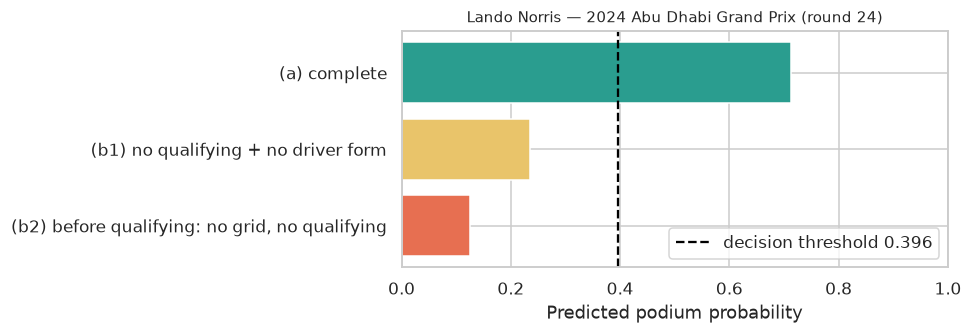

In [84]:
# -----------------------------
# 13.3 — Demo (b): partially missing records
# -----------------------------
drop_b1 = ["quali_position", "gap_to_fastest_quali_pct", "quali_missing",
           "driver_avg_finish_last5", "driver_podium_rate_last5", "driver_no_history"]
drop_b2 = ["grid_model", "pit_lane_start", "quali_position", "gap_to_fastest_quali_pct", "quali_missing"]

partial_b1 = {k: v for k, v in complete_record.items() if k not in drop_b1}
partial_b2 = {k: v for k, v in complete_record.items() if k not in drop_b2}

print("b1 — keys sent:", sorted(k for k in partial_b1 if k in FEATURE_COLUMNS))
print("b2 — keys sent:", sorted(k for k in partial_b2 if k in FEATURE_COLUMNS))

pred_b1 = predict_podium(partial_b1)
pred_b2 = predict_podium(partial_b2)

comparison = pd.concat([pred_complete.assign(scenario="(a) complete"),
                        pred_b1.assign(scenario="(b1) no qualifying + no driver form"),
                        pred_b2.assign(scenario="(b2) before qualifying: no grid, no qualifying")]).set_index("scenario")
pd.set_option("display.max_colwidth", 200)
display(comparison[["podium_probability", "predicted_podium", "threshold", "n_missing_numeric",
                    "imputed_with_training_median", "warnings"]])

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(comparison.index, comparison["podium_probability"], color=["#2a9d8f", "#e9c46a", "#e76f51"])
ax.axvline(INFERENCE_THRESHOLD, color="black", ls="--", label=f"decision threshold {INFERENCE_THRESHOLD:.3f}")
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.set_xlabel("Predicted podium probability")
ax.set_title(describe_driver_race(demo_row["raceId"], demo_row["driverId"]), fontsize=10)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 13.4 · Batch mode and safety checks

The same function scores a whole race at once (one call, one row per driver). Below we score every driver of the demo race and compare the predicted top 3 with the real podium. We then show that the safety checks really fire: a post-race column, a typo in a column name, and an impossible value are all **rejected** with a clear message instead of producing a misleading prediction.

In [85]:
# -----------------------------
# 13.4 — Batch prediction for one whole race + guard tests
# -----------------------------
race_input = demo_race[["raceId", "driverId"] + FEATURE_COLUMNS]
race_pred = predict_podium(race_input)
race_pred["driver"] = [describe_driver_race(r, d).split(" — ")[0]
                       for r, d in zip(race_pred["raceId"], race_pred["driverId"])]
race_pred["grid"] = race_input["grid_model"].to_numpy()
race_pred["actual_podium"] = demo_race["podium"].astype(bool).to_numpy()
race_pred = race_pred.sort_values("podium_probability", ascending=False).reset_index(drop=True)
race_pred.index += 1
print(_races_lookup.loc[int(demo_race_id), "name"], int(_races_lookup.loc[int(demo_race_id), "year"]),
      "— all drivers ranked by predicted podium probability")
display(race_pred[["driver", "grid", "podium_probability", "predicted_podium", "actual_podium"]].head(10)
        .style.format({"podium_probability": "{:.1%}", "grid": "{:.0f}"}))
hits = race_pred.head(3)["actual_podium"].sum()
print(f"Predicted top-3 contains {hits} of the 3 real podium finishers.")

# Guard tests: each bad input must raise an error.
bad_inputs = {
    "post-race column (leakage)": {**complete_record, "positionOrder": 1},
    "typo in a column name": {**{k: v for k, v in complete_record.items() if k != "grid_model"}, "grid_postion": 1},
    "impossible value": {**complete_record, "driver_podium_rate_last5": 1.7},
    "text instead of a number": {**complete_record, "quali_position": "first"},
}
for case, rec in bad_inputs.items():
    try:
        predict_podium(rec)
        raise AssertionError(f"{case}: should have been rejected")
    except (ValueError, KeyError) as err:
        print(f"✅ rejected — {case}: {err}")

Abu Dhabi Grand Prix 2024 — all drivers ranked by predicted podium probability


,driver,grid,podium_probability,predicted_podium,actual_podium
1,Lando Norris,1,71.3%,True,True
2,Oscar Piastri,2,60.0%,True,False
3,Carlos Sainz,3,56.8%,True,True
4,Max Verstappen,4,49.1%,True,False
5,Charles Leclerc,19,16.4%,False,True
6,George Russell,6,16.3%,False,False
7,Pierre Gasly,5,12.6%,False,False
8,Nico Hülkenberg,7,9.7%,False,False
9,Sergio Pérez,10,8.1%,False,False
10,Lewis Hamilton,16,6.6%,False,False


Predicted top-3 contains 2 of the 3 real podium finishers.
✅ rejected — post-race column (leakage): Leakage: ['positionOrder'] are only known AFTER the race and must not be passed to the model.
✅ rejected — typo in a column name: Unknown column(s) ['grid_postion']. Expected a subset of: ['grid_model', 'quali_position', 'gap_to_fastest_quali_pct', 'driver_points_per_round_before', 'driver_standing_pos_before', 'constructor_points_per_round_before', 'constructor_standing_pos_before', 'driver_avg_finish_last5', 'driver_podium_rate_last5', 'constructor_avg_finish_last5', 'constructor_podium_rate_last5', 'pit_lane_start', 'quali_missing', 'driver_standing_missing', 'constructor_standing_missing', 'driver_no_history', 'constructor_no_history']
✅ rejected — impossible value: Column 'driver_podium_rate_last5' has value(s) outside the plausible range [0, 1]: [1.7]
✅ rejected — text instead of a number: Column 'quali_position' has non-numeric value(s): ['first']


### §13 summary — what the demonstrations show

* **Complete record (a):** the function returns exactly the same probability as the frozen Phase 4 model (verified on all test rows), the decision at the frozen threshold, and no warnings.
* **Partially missing records (b1, b2):** the function **still works**. Missing numeric inputs are filled with the **training medians** inside the pipeline, flags are re-derived to stay consistent, and the output lists *which* inputs were imputed and with which value.
* **What the probability change teaches us:** the training median describes a *typical* driver (e.g. median qualifying position ≈ 11, median recent podium rate = 0, because most drivers never finish on the podium). So for a front-running driver, every imputed value pulls the prediction **down towards an average driver**. The pole-sitter falls from clearly above the threshold to below it once qualifying and form are hidden. That is why the function attaches a warning whenever it imputes, and a stronger one when starting position (the most important information in Phase 5 and Phase 6) is unknown. The prediction is still valid as "what the model can say with this little information", but it should not be trusted like a complete-record prediction.
* **Safety:** post-race columns, unknown column names and impossible values are rejected, so the function cannot be fed leaked or corrupted data by mistake.

| Deliverable 7 requirement | Status | Where |
|---|---|---|
| Inference function | ✅ `predict_podium()` | §13.1 |
| Demonstrated on a complete record | ✅ | §13.2 |
| Demonstrated on a partially missing record | ✅ two scenarios | §13.3 |
| Consistent with the trained model (no re-fitting, same threshold) | ✅ asserted on all test rows | §13.1 |